<a href="https://colab.research.google.com/github/LikithaSrinivasa25/ml-dl-algorithms/blob/main/Affinity_Profiles.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Mount the Goggle Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Extract all tar.gz files
#for month in ['07', '08', '09']:
 #   tar_file = f'{data_path}/HUMAN LOCATION SIGNALS/2024_{month}.tar.gz'
  #  extract_path = f'{data_path}/HUMAN LOCATION SIGNALS/2024_{month}'

   # if os.path.exists(tar_file):
    #    with tarfile.open(tar_file, 'r:gz') as tar:
     #       tar.extractall(extract_path)
      #  print(f"Extracted 2024_{month}.tar.gz")

In [ ]:
pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.9/250.9 kB 4.5 MB/s eta 0:00:00


In [ ]:
pip install pandas numpy pathlib

In [ ]:
!pip install folium

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.4/113.4 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.4/90.4 kB 7.1 MB/s eta 0:00:00


In [ ]:
pip install geopandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 338.4/338.4 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.7/27.7 MB 66.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 124.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 70.2 MB/s eta 0:00:00


In [ ]:
!pip install h3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 14.6 MB/s eta 0:00:00


In [ ]:
!pip install imbalanced-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 240.0/240.0 kB 4.1 MB/s eta 0:00:00


In [ ]:
!pip install dash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 58.2 MB/s eta 0:00:00


In [ ]:
#Importing all the necessary Libraries
import pandas as pd
import numpy as np
import os
import seaborn as sns
import glob
from pathlib import Path
import random
import matplotlib.pyplot as plt
from collections import Counter
import gc
import h3
import requests
import folium
import json
import geopandas as gpd
from scipy import stats
from shapely.geometry import Point, Polygon
from scipy.spatial.distance import pdist, squareform
from scipy.stats import entropy
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler, LabelEncoder
import xgboost as xgb
import networkx as nx
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.figure_factory as ff
from dash import Dash, html, dcc, Input, Output, callback
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from dataclasses import dataclass, field
from abc import ABC, abstractmethod
from collections import defaultdict, deque
from scipy.stats import truncnorm
from scipy.special import softmax
from scipy.spatial.distance import cdist
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score
from scipy.spatial.distance import pdist, squareform
from scipy.stats import pearsonr, spearmanr
from sklearn.preprocessing import StandardScaler
from io import StringIO
from sklearn.neighbors import NearestNeighbors
from folium import plugins
from scipy.stats import skew, kurtosis
from typing import Dict, List, Tuple, Any, Optional
from datetime import datetime, timedelta
from collections import Counter
from scipy import stats
from sklearn.cluster import DBSCAN
from scipy.spatial.distance import cdist
import warnings
warnings.filterwarnings('ignore')

In [ ]:
#Loading all the data
class LocationDataLoader:
    def __init__(self, base_path: str = "/content/drive/MyDrive/I-AM-HUMAN CDRC"):
        self.base_path = Path(base_path)
        self.data = {}
        self.metadata = {}

    def diagnose_file_format(self, file_path: Path) -> Dict[str, Any]:
        diagnosis = {
            'file_path': str(file_path),
            'file_size': 0,
            'is_binary': False,
            'first_bytes': None,
            'possible_formats': [],
            'encoding_detected': None
        }
        try:
            diagnosis['file_size'] = file_path.stat().st_size
            # Reading first 200 bytes to analyze format
            with open(file_path, 'rb') as f:
                first_bytes = f.read(200)
                diagnosis['first_bytes'] = first_bytes
                # Checking for common formats
                if first_bytes.startswith(b'PAR1'):
                    diagnosis['possible_formats'].append('parquet')
                elif first_bytes.startswith(b'\x1f\x8b'):
                    diagnosis['possible_formats'].append('gzip')
                elif b',' in first_bytes[:100] or b'\t' in first_bytes[:100]:
                    diagnosis['possible_formats'].append('csv')
                elif first_bytes.startswith(b'{\n') or first_bytes.startswith(b'['):
                    diagnosis['possible_formats'].append('json')

                #Decoding as text
                try:
                    text_content = first_bytes.decode('utf-8')
                    diagnosis['encoding_detected'] = 'utf-8'
                    diagnosis['text_preview'] = text_content[:100]
                except:
                    try:
                        text_content = first_bytes.decode('latin1')
                        diagnosis['encoding_detected'] = 'latin1'
                        diagnosis['text_preview'] = text_content[:100]
                    except:
                        diagnosis['is_binary'] = True

        except Exception as e:
            diagnosis['error'] = str(e)
        return diagnosis

    def read_signals_file_smart(self, file_path: Path) -> pd.DataFrame:
        # Define exact column names based on the sample data structure
        signals_columns = [
            'user_id', 'latitude', 'longitude', 'timestamp', 'date',
            'year', 'month', 'day', 'day_of_week', 'hour', 'minute',
            'h3_index_1', 'h3_index_2', 'activity_type'
        ]

        reading_strategies = [
            # Strategy 1: parquet Method
            ('parquet', lambda: pd.read_parquet(file_path)),

            # Strategy 2: Tab-separated with predefined columns, without header
            ('tsv', lambda: pd.read_csv(
                file_path,
                sep='\t',
                names=signals_columns,
                header=None,
                engine='python',
                encoding='utf-8'
            )),

            # Strategy 3: Tab-separated with header detection
            ('tsv_with_header', lambda: pd.read_csv(
                file_path,
                sep='\t',
                engine='python',
                encoding='utf-8'
            )),

            # Strategy 4:Parsing Manually
            ('manual_parsing', lambda: self._manual_parse_signals(file_path, signals_columns)),
        ]
        return self._try_reading_strategies(file_path, reading_strategies, 'signals')

    def read_profiles_file_smart(self, file_path: Path) -> pd.DataFrame:
        # Defining column names
        base_columns = ['user_id', 'profile_id', 'record_count']
        score_columns = [f'score_{i:02d}' for i in range(1, 22)]  # score_01 to score_21
        profiles_columns = base_columns + score_columns

        reading_strategies = [
            # Strategy 1: Try as parquet first
            ('parquet', lambda: pd.read_parquet(file_path)),

            # Strategy 2: Tab-separated with predefined columns, no header
            ('tsv_no_header', lambda: pd.read_csv(
                file_path,
                sep='\t',
                names=profiles_columns,
                header=None,
                engine='python',
                encoding='utf-8'
            )),

            # Strategy 3: Tab-separated with header detection
            ('tsv_with_header', lambda: pd.read_csv(
                file_path,
                sep='\t',
                engine='python',
                encoding='utf-8'
            )),

            # Strategy 4: Manual line-by-line parsing
            ('manual_parsing', lambda: self._manual_parse_profiles(file_path, profiles_columns)),
        ]
        return self._try_reading_strategies(file_path, reading_strategies, 'profiles')

    def _manual_parse_signals(self, file_path: Path, expected_columns: List[str]) -> pd.DataFrame:
        try:
            data = []
            with open(file_path, 'r', encoding='utf-8') as f:
                for line_num, line in enumerate(f):
                    if line_num > 50000:
                        break

                    line = line.strip()
                    if line:
                        parts = line.split('\t')
                        if len(parts) >= 14:
                            data.append(parts[:14])
                        elif len(parts) >= 10:
                            # Pad with None for missing columns
                            padded_parts = parts + [None] * (14 - len(parts))
                            data.append(padded_parts)

            if data:
                df = pd.DataFrame(data, columns=expected_columns)
                # Convert data types
                df['latitude'] = pd.to_numeric(df['latitude'], errors='coerce')
                df['longitude'] = pd.to_numeric(df['longitude'], errors='coerce')
                df['timestamp'] = pd.to_numeric(df['timestamp'], errors='coerce')
                df['year'] = pd.to_numeric(df['year'], errors='coerce')
                df['month'] = pd.to_numeric(df['month'], errors='coerce')
                df['day'] = pd.to_numeric(df['day'], errors='coerce')
                df['day_of_week'] = pd.to_numeric(df['day_of_week'], errors='coerce')
                df['hour'] = pd.to_numeric(df['hour'], errors='coerce')
                df['minute'] = pd.to_numeric(df['minute'], errors='coerce')
                return df
        except Exception as e:
            pass
        return pd.DataFrame()

    def _manual_parse_profiles(self, file_path: Path, expected_columns: List[str]) -> pd.DataFrame:
        try:
            data = []
            with open(file_path, 'r', encoding='utf-8') as f:
                for line_num, line in enumerate(f):
                    if line_num > 50000:
                        break
                    line = line.strip()
                    if line:
                        parts = line.split('\t')
                        if len(parts) >= 20:
                            data.append(parts[:24] if len(parts) >= 24 else parts + [None] * (24 - len(parts)))
                        elif len(parts) >= 10:
                            padded_parts = parts + [None] * (24 - len(parts))
                            data.append(padded_parts)

            if data:
                actual_columns = expected_columns[:len(data[0])] if data else expected_columns
                df = pd.DataFrame(data, columns=actual_columns)
                # Converting numeric columns except user_id
                for col in df.columns[1:]:  # Skip user_id column
                    df[col] = pd.to_numeric(df[col], errors='coerce')

                return df

        except Exception as e:
            pass
        return pd.DataFrame()

    def _try_reading_strategies(self, file_path: Path, strategies: List, data_type: str) -> pd.DataFrame:
        for strategy_name, read_func in strategies:
            try:
                df = read_func()

                # Validate the result
                if len(df.columns) >= 10 and len(df) > 0:
                    if self._validate_data_structure(df, data_type):
                        print(f" Successfully read {file_path.name} ({len(df):,} records)")
                        return df

            except Exception as e:
                continue

        print(f"Failed to read {file_path.name}")
        raise Exception(f"Could not read {file_path}")

    def _validate_data_structure(self, df: pd.DataFrame, data_type: str) -> bool:
        try:
            if data_type == 'signals':
                # Checking for coordinate-like data
                if len(df.columns) >= 3:
                    lat_col = pd.to_numeric(df.iloc[:100, 1], errors='coerce')  # Checking first 100 rows
                    lon_col = pd.to_numeric(df.iloc[:100, 2], errors='coerce')

                    # Checking if coordinates are in reasonable ranges
                    if (lat_col.between(-90, 90).any() and lon_col.between(-180, 180).any()):
                        return True

            elif data_type == 'profiles':
                # Checking if the columns are numeric
                numeric_cols = 0
                for col in df.columns[1:min(10, len(df.columns))]:
                    try:
                        numeric_data = pd.to_numeric(df[col].head(100), errors='coerce')
                        if not numeric_data.isna().all():
                            numeric_cols += 1
                    except:
                        pass

                if numeric_cols >= min(5, len(df.columns) - 1):
                    return True
            return False

        except Exception as e:
            return False

    def read_file_smart(self, file_path: Path, max_attempts: int = 3) -> pd.DataFrame:
        file_path = Path(file_path)
        if "HUMAN LOCATION SIGNALS" in str(file_path):
            return self.read_signals_file_smart(file_path)
        elif "PROFILES" in str(file_path):
            return self.read_profiles_file_smart(file_path)

        # Diagonising other file types (POIs, Visitors, Parametric Scores)
        diagnosis = self.diagnose_file_format(file_path)
        reading_strategies = []
        if 'parquet' in diagnosis['possible_formats']:
            reading_strategies.append(('parquet', lambda: pd.read_parquet(file_path)))

        if 'gzip' in diagnosis['possible_formats']:
            reading_strategies.append(('gzip_parquet', lambda: pd.read_parquet(file_path)))
            reading_strategies.append(('gzip_csv', lambda: pd.read_csv(file_path, compression='gzip')))

        if 'csv' in diagnosis['possible_formats'] or diagnosis['encoding_detected']:
            encoding = diagnosis['encoding_detected'] or 'utf-8'
            reading_strategies.extend([
                ('csv_comma', lambda: pd.read_csv(file_path, sep=',', encoding=encoding, engine='python')),
                ('csv_tab', lambda: pd.read_csv(file_path, sep='\t', encoding=encoding, engine='python')),
                ('csv_pipe', lambda: pd.read_csv(file_path, sep='|', encoding=encoding, engine='python')),
            ])

        if 'json' in diagnosis['possible_formats']:
            reading_strategies.append(('json', lambda: pd.read_json(file_path, lines=True)))

        reading_strategies.extend([
            ('parquet_fallback', lambda: pd.read_parquet(file_path)),
            ('csv_auto', lambda: pd.read_csv(file_path, engine='python')),
            ('csv_utf8', lambda: pd.read_csv(file_path, encoding='utf-8', engine='python')),
            ('csv_latin1', lambda: pd.read_csv(file_path, encoding='latin1', engine='python')),
        ])

        for strategy_name, read_func in reading_strategies:
            try:
                df = read_func()
                if len(df.columns) > 0 and len(df) > 0:
                    print(f"Successfully read {file_path.name} using {strategy_name}")
                    return df
            except Exception as e:
                continue

        print(f"Failed to read {file_path.name}")
        raise Exception(f"Could not read {file_path}")

    def _find_user_column(self, df: pd.DataFrame) -> str:
        user_patterns = ['user_id', 'user', 'id', 'uid', 'device', 'person', 'customer']
        for col in df.columns:
            col_lower = str(col).lower()
            if col_lower in user_patterns:
                return col

        for col in df.columns:
            col_lower = str(col).lower()
            for pattern in user_patterns:
                if pattern in col_lower:
                    if "id" in col_lower or pattern == col_lower:
                         return col

        #Returns to the first column if no match found
        if len(df.columns) > 0:
            return df.columns[0]

        return None

    def load_users_with_temporal_consistency(self, target_users: int = 3000):
        #Finding the users that appear in multiple months for temporal consistency
        users_by_month = {}

        # Get user lists from profiles
        for month_folder in ["Profiles_2024-07", "Profiles_2024-08", "Profiles_2024-09"]:
            profiles_path = self.base_path / "PROFILES" / month_folder / "profiling" / "scores"

            if profiles_path.exists():
                month_users = set()
                part_files = list(profiles_path.glob("part-*"))

                # Sample files to get user list
                for file in part_files[:5]:  # First 5 files per month
                    try:
                        df = self.read_file_smart(file)
                        if len(df) > 0:
                            user_col = self._find_user_column(df)
                            if user_col:
                                file_users = set(df[user_col].astype(str).unique())
                                month_users.update(file_users)

                                if len(month_users) > target_users * 3:
                                    break
                    except:
                        continue

                users_by_month[month_folder] = month_users
                print(f"  Found {len(month_users):,} users in {month_folder}")

        # Finding intersection of users across months
        if len(users_by_month) >= 2:
            # Finding users present in all months
            common_users = set.intersection(*users_by_month.values())
            print(f"  Users present in all months: {len(common_users):,}")

            if len(common_users) >= target_users:
                selected_users = set(random.sample(list(common_users), target_users))
                print(f"  Selected {len(selected_users):,} users for consistent tracking")
                return selected_users
            else:
                print(f"  Insufficient users in all months, expanding criteria")
                two_month_users = set()

                month_combinations = [
                    ("Profiles_2024-07", "Profiles_2024-08"),
                    ("Profiles_2024-07", "Profiles_2024-09"),
                    ("Profiles_2024-08", "Profiles_2024-09")
                ]

                for month1, month2 in month_combinations:
                    if month1 in users_by_month and month2 in users_by_month:
                        overlap = users_by_month[month1] & users_by_month[month2]
                        two_month_users.update(overlap)

                if len(two_month_users) >= target_users:
                    selected_users = set(random.sample(list(two_month_users), target_users))
                    print(f"  Selected {len(selected_users):,} users present in more than 2 months")
                    return selected_users
                else:
                    all_users = []
                    for users in users_by_month.values():
                        all_users.extend(users)

                    user_counts = Counter(all_users)
                    most_frequent = [user for user, count in user_counts.most_common(target_users)]
                    selected_users = set(most_frequent)
                    print(f"  Selected {len(selected_users):,} most frequent users")
                    return selected_users
        return set()

    def load_all_data(self) -> Dict[str, Any]:
        print("LOADING ALL DATA")

        # Loading POIs data
        self.load_pois()

        # Get consistent user set first
        selected_users = self.load_users_with_temporal_consistency(target_users=3000)

        if selected_users:
            print(f"\nLoading data for {len(selected_users)} consistent users")

            # Load data for the same users across all datasets
            self.load_profiles_fixed_temporal(selected_users)
            self.load_user_signals_fixed_temporal(selected_users)
            self.load_visitors_fixed_temporal(selected_users)
        else:
            self.load_user_signals(target_users=3000)
            self.load_profiles(target_users=3000)
            self.load_visitors(target_users=3000)

        # Load additional data (unchanged)
        self.load_parametric_scores()

        return self.data

    def load_profiles_fixed_temporal(self, selected_users: set):
        print(f"Loading Profiles for {len(selected_users)} consistent users")
        profiles_path = self.base_path / "PROFILES"
        profiles_data = {}
        total_files_processed = 0
        monthly_stats = {}

        # Load data for selected users from each month
        for month_folder in ["Profiles_2024-07", "Profiles_2024-08", "Profiles_2024-09"]:
            print(f"  Processing month: {month_folder}")
            month_path = profiles_path / month_folder / "profiling" / "scores"

            if not month_path.exists():
                print(f"    Month path not found: {month_path}")
                continue

            part_files = list(month_path.glob("part-*"))
            if not part_files:
                print(f"    No part files found in: {month_path}")
                continue

            month_data = []
            month_users_found = set()
            month_files = 0

            # Load files and filter for selected users
            for file in part_files:
                try:
                    df = self.read_file_smart(file)
                    if len(df) > 0:
                        user_col = self._find_user_column(df)
                        if user_col:
                            # Filter for only our selected users
                            user_mask = df[user_col].astype(str).isin(selected_users)
                            filtered_df = df[user_mask]

                            if len(filtered_df) > 0:
                                month_data.append(filtered_df)
                                month_users_found.update(filtered_df[user_col].astype(str).unique())

                    total_files_processed += 1
                    month_files += 1

                except Exception as e:
                    print(f"    Could not read {file.name}: {str(e)[:100]}")

            if month_data:
                try:
                    combined_df = pd.concat(month_data, ignore_index=True)
                    profiles_data[month_folder] = combined_df
                    print(f"    Loaded {month_folder}: {len(combined_df):,} records, {len(month_users_found)} users from {month_files} files")
                except Exception as e:
                    print(f"    Error combining data for {month_folder}: {e}")

            monthly_stats[month_folder] = {
                'files': month_files,
                'users': len(month_users_found),
                'records': len(combined_df) if month_data else 0
            }

        self.data['profiles'] = profiles_data
        self.metadata['profiles'] = {
            'target_users': len(selected_users),
            'actual_users': len(selected_users),
            'files_processed': total_files_processed,
            'monthly_stats': monthly_stats,
            'temporal_consistency': True,
            'description': f'User profiles for {len(selected_users)} users tracked across all months'
        }

    def load_user_signals_fixed_temporal(self, selected_users: set):
        print(f"Loading User Signals for {len(selected_users)} users")

        signals_path = self.base_path / "HUMAN LOCATION SIGNALS"
        signals_data = {}
        total_files_processed = 0
        monthly_stats = {}

        # Load data for selected users from each month
        for month_folder in ["2024_07", "2024_08", "2024_09"]:
            print(f"  Processing month: {month_folder}")
            month_path = signals_path / month_folder
            month_number = month_folder.split('_')[1]
            month_subpath = month_path / month_number

            if not month_subpath.exists():
                continue

            month_datasets = 0
            month_files = 0
            month_users_found = set()

            # Process fewer days but ensure user consistency
            for day_folder in sorted(month_subpath.iterdir())[:15]:  # First 15 days
                if not day_folder.is_dir():
                    continue

                day_path = month_subpath / day_folder.name
                part_files = list(day_path.glob("part-*"))

                if not part_files:
                    continue

                day_data = []

                # Process more files per day since we're filtering for specific users
                for file in part_files[:8]:  # More files per day
                    try:
                        df = self.read_file_smart(file)
                        if len(df) > 0:
                            user_col = self._find_user_column(df)
                            if user_col:
                                # Filter for only our selected users
                                user_mask = df[user_col].astype(str).isin(selected_users)
                                filtered_df = df[user_mask]

                                if len(filtered_df) > 0:
                                    day_data.append(filtered_df)
                                    month_users_found.update(filtered_df[user_col].astype(str).unique())

                        month_files += 1
                        total_files_processed += 1

                    except Exception as e:
                        continue

                if day_data:
                    try:
                        combined_df = pd.concat(day_data, ignore_index=True)
                        key = f"{month_folder}_{day_folder.name}"
                        signals_data[key] = combined_df
                        month_datasets += 1
                        print(f"      Loaded {key}: {len(combined_df):,} records")
                    except Exception as e:
                        print(f"      Error combining data for {key}: {e}")

            monthly_stats[month_folder] = {
                'datasets': month_datasets,
                'files': month_files,
                'users': len(month_users_found)
            }
            print(f"    Month {month_folder} summary: {month_datasets} datasets, {month_files} files, {len(month_users_found)} users found")

        self.data['user_signals'] = signals_data
        self.metadata['user_signals'] = {
            'target_users': len(selected_users),
            'actual_users': len(selected_users),
            'files_processed': total_files_processed,
            'monthly_stats': monthly_stats,
            'temporal_consistency': True,
            'description': f'User location signals for {len(selected_users)} users tracked consistently across all months'
        }

    def load_visitors_fixed_temporal(self, selected_users: set):
        print(f"Loading Visitors for {len(selected_users)} users")

        visitors_path = self.base_path / "VISITORS"
        visitors_data = {}
        total_files_processed = 0
        monthly_stats = {}

        for month_folder in ["07", "08", "09"]:
            print(f"  Processing month: 2024_{month_folder}")
            month_path = visitors_path / month_folder

            if not month_path.exists():
                continue

            part_files = list(month_path.glob("part-*"))
            if not part_files:
                continue

            month_data = []
            month_users_found = set()
            month_files = 0

            for file in part_files:
                try:
                    df = self.read_file_smart(file)
                    if len(df) > 0:
                        user_col = self._find_user_column(df)
                        if user_col:
                            # Filter for only our selected users
                            user_mask = df[user_col].astype(str).isin(selected_users)
                            filtered_df = df[user_mask]

                            if len(filtered_df) > 0:
                                month_data.append(filtered_df)
                                month_users_found.update(filtered_df[user_col].astype(str).unique())

                    total_files_processed += 1
                    month_files += 1

                except Exception as e:
                    continue

            if month_data:
                try:
                    combined_df = pd.concat(month_data, ignore_index=True)
                    visitors_data[f"2024_{month_folder}"] = combined_df
                    print(f"    Loaded 2024_{month_folder}: {len(combined_df):,} records, {len(month_users_found)} users from {month_files} files")
                except Exception as e:
                    print(f"    Error combining data for 2024_{month_folder}: {e}")

            monthly_stats[f"2024_{month_folder}"] = {
                'files': month_files,
                'users': len(month_users_found),
                'records': len(combined_df) if month_data else 0
            }

        self.data['visitors'] = visitors_data
        self.metadata['visitors'] = {
            'target_users': len(selected_users),
            'actual_users': len(selected_users),
            'files_processed': total_files_processed,
            'monthly_stats': monthly_stats,
            'temporal_consistency': True,
            'description': f'Visitor data for {len(selected_users)} users tracked consistently across all months'
        }

    def load_user_signals(self, target_users: int = 5000):
        print(f"Loading User Signals across all three months...")

        signals_path = self.base_path / "HUMAN LOCATION SIGNALS"
        signals_data = {}
        total_files_processed = 0
        unique_users = set()
        monthly_stats = {}

        # Processing ALL three months
        for month_folder in ["2024_07", "2024_08", "2024_09"]:
            print(f"  Processing month: {month_folder}")
            month_path = signals_path / month_folder
            if not month_path.exists():
                print(f" Month folder not found: {month_path}")
                continue

            month_users = set()
            month_datasets = 0
            month_files = 0

            #Finding the nested structure: 2024_07/07/01, 2024_08/08/01, etc.
            month_number = month_folder.split('_')[1]  # Extracting "07" from "2024_07"
            month_subpath = month_path / month_number

            if not month_subpath.exists():
                print(f"  Month subfolder not found: {month_subpath}")
                continue

            for day_folder in sorted(month_subpath.iterdir()):
                if not day_folder.is_dir():
                    continue

                day_path = month_subpath / day_folder.name
                part_files = list(day_path.glob("part-*"))
                if not part_files:
                    continue
                print(f"    Processing day {day_folder.name} - Found {len(part_files)} part files")
                day_data = []
                max_files_per_day = 5 if len(unique_users) < target_users else 2
                for file in part_files[:max_files_per_day]:
                    try:
                        df = self.read_file_smart(file)
                        if len(df) > 0:
                            # Finding user column
                            user_col = self._find_user_column(df)

                            if user_col is not None:
                                try:
                                    file_users = set(df[user_col].astype(str).unique())
                                    new_users = file_users - unique_users
                                    if len(unique_users) < target_users and len(new_users) > 0:
                                        users_needed = target_users - len(unique_users)
                                        selected_users = list(new_users)[:users_needed]
                                        if selected_users:
                                            filtered_df = df[df[user_col].astype(str).isin(selected_users)]
                                            day_data.append(filtered_df)
                                            unique_users.update(selected_users)
                                            month_users.update(selected_users)
                                        else:
                                            day_data.append(df.sample(min(1000, len(df))))
                                    else:
                                        day_data.append(df.sample(min(500, len(df))))

                                except Exception as e:
                                    day_data.append(df.sample(min(1000, len(df))))
                            else:
                                day_data.append(df.sample(min(1000, len(df))))

                        total_files_processed += 1
                        month_files += 1

                    except Exception as e:
                        print(f"      Failed to load {file.name}: {str(e)[:100]}")

                if day_data:
                    try:
                        combined_df = pd.concat(day_data, ignore_index=True)
                        key = f"{month_folder}_{day_folder.name}"
                        signals_data[key] = combined_df
                        month_datasets += 1
                        print(f"      Loaded {key}: {len(combined_df):,} records")
                    except Exception as e:
                        print(f"      Error combining data for {key}: {e}")

            monthly_stats[month_folder] = {
                'datasets': month_datasets,
                'files': month_files,
                'users': len(month_users)
            }
            print(f"    Month {month_folder} summary: {month_datasets} datasets, {month_files} files, {len(month_users)} new users")

        self.data['user_signals'] = signals_data
        self.metadata['user_signals'] = {
            'target_users': target_users,
            'actual_users': len(unique_users),
            'files_processed': total_files_processed,
            'monthly_stats': monthly_stats,
            'description': f'User location signals for {len(unique_users)} users across all months'
        }
        print(f"  Final result: {len(signals_data)} datasets, {len(unique_users)} unique users, {total_files_processed} files processed")

    def load_pois(self):
        print("Loading POI data")

        poi_path = self.base_path / "POIs"
        poi_data = {}

        # Load monthly POI CSV files
        for month_folder in ["POIs_2024-07", "POIs_2024-08", "POIs_2024-09"]:
            month_path = poi_path / month_folder
            if month_path.exists():
                csv_files = list(month_path.glob("*.csv"))
                for file in csv_files:
                    try:
                        print(f"Reading the file: {file}")
                        df = self.read_file_smart(file)
                        key = f"{month_folder}_{file.stem}"
                        poi_data[key] = df
                        print(f"  Successfully loaded {file.name}: {len(df):,} records, {len(df.columns)} columns")

                    except Exception as e:
                        print(f"  Error loading {file}: {e}")

        # Loading Excel files in POIs data folder
        excel_files = list(poi_path.glob("*.xlsx"))
        for file in excel_files:
            try:
                xls = pd.ExcelFile(file)
                for sheet_name in xls.sheet_names:
                    df = pd.read_excel(file, sheet_name=sheet_name)
                    key = f"{file.stem}_{sheet_name}"
                    poi_data[key] = df
                    print(f" Loaded {file.name}[{sheet_name}]: {len(df):,} records")

            except Exception as e:
                print(f" Error in loading {file.name}: {e}")

        self.data['pois'] = poi_data
        self.metadata['pois'] = {
            'total_files': len(poi_data),
            'sample_rate': 1.0,
            'description': 'POI data loaded'
        }

    def load_profiles(self, target_users: int = 5000):
        print(f"Loading Profiles for {target_users} users across all three months")
        profiles_path = self.base_path / "PROFILES"

        # Add a check for Google Drive mount
        if not os.path.exists('/content/drive'):
            print("Error: Google Drive is not mounted. Please run the 'Mount the Goggle Drive' cell.")
            raise FileNotFoundError("Google Drive is not mounted.")

        profiles_data = {}
        total_files_processed = 0
        unique_users = set()
        monthly_stats = {}

        # Processing the data for all three months
        for month_folder in ["Profiles_2024-07", "Profiles_2024-08", "Profiles_2024-09"]:
            print(f"  Processing month: {month_folder}")
            month_path = profiles_path / month_folder / "profiling" / "scores"
            if not month_path.exists():
                print(f"Error Loading: {month_path}. Please verify the path and Google Drive connection.")
                continue

            part_files = list(month_path.glob("part-*"))
            if not part_files:
                print(f"    No part files found in: {month_path}")
                continue

            month_data = []
            month_users = set()
            month_files = 0
            max_files_this_month = 10 if len(unique_users) < target_users else 5
            for file in part_files[:max_files_this_month]:
                try:
                    df = self.read_file_smart(file)
                    if len(df) > 0:
                        user_col = self._find_user_column(df)
                        if user_col is not None:
                            try:
                                file_users = set(df[user_col].astype(str).unique())
                                new_users = file_users - unique_users

                                if len(unique_users) < target_users and len(new_users) > 0:
                                    users_needed = target_users - len(unique_users)
                                    selected_users = list(new_users)[:users_needed]

                                    if selected_users:
                                        filtered_df = df[df[user_col].astype(str).isin(selected_users)]
                                        month_data.append(filtered_df)
                                        unique_users.update(selected_users)
                                        month_users.update(selected_users)
                                    else:
                                        month_data.append(df.sample(min(1000, len(df))))
                                else:
                                    month_data.append(df.sample(min(500, len(df))))

                            except Exception as e:
                                month_data.append(df.sample(min(1000, len(df))))
                        else:
                            month_data.append(df.sample(min(1000, len(df))))

                    total_files_processed += 1
                    month_files += 1

                except Exception as e:
                    print(f"    Could not read {file.name}: {str(e)[:100]}")

            if month_data:
                try:
                    combined_df = pd.concat(month_data, ignore_index=True)
                    profiles_data[month_folder] = combined_df
                    print(f"    Loaded {month_folder}: {len(combined_df):,} records, {len(month_users)} users from {month_files} files")
                except Exception as e:
                    print(f"    Error combining data for {month_folder}: {e}")

            monthly_stats[month_folder] = {
                'files': month_files,
                'users': len(month_users),
                'records': len(combined_df) if month_data else 0
            }

        self.data['profiles'] = profiles_data
        self.metadata['profiles'] = {
            'target_users': target_users,
            'actual_users': len(unique_users),
            'files_processed': total_files_processed,
            'monthly_stats': monthly_stats,
            'description': f'User profiles for {len(unique_users)} users across all months'
        }
        print(f"  Final result: {len(profiles_data)} datasets, {len(unique_users)} unique users, {total_files_processed} files processed")

    def load_visitors(self, target_users: int = 5000):
        print(f"Loading Visitors for {target_users} users across all three months")
        visitors_path = self.base_path / "VISITORS"
        visitors_data = {}
        total_files_processed = 0
        unique_users = set()
        monthly_stats = {}

        # Process ALL three months
        for month_folder in ["07", "08", "09"]:
            print(f"  Processing month: 2024_{month_folder}")
            month_path = visitors_path / month_folder
            if not month_path.exists():
                print(f"    Month path not found: {month_path}")
                continue
            part_files = list(month_path.glob("part-*"))
            if not part_files:
                print(f"    No part files found in: {month_path}")
                continue

            month_data = []
            month_users = set()
            month_files = 0

            # Loading files from each month
            for file in part_files:
                try:
                    df = self.read_file_smart(file)
                    if len(df) > 0:
                        # Find user column
                        user_col = self._find_user_column(df)
                        if user_col is not None:
                            try:
                                file_users = set(df[user_col].astype(str).unique())
                                new_users = file_users - unique_users

                                if len(unique_users) < target_users and len(new_users) > 0:
                                    users_needed = target_users - len(unique_users)
                                    selected_users = list(new_users)[:users_needed]

                                    if selected_users:
                                        filtered_df = df[df[user_col].astype(str).isin(selected_users)]
                                        month_data.append(filtered_df)
                                        unique_users.update(selected_users)
                                        month_users.update(selected_users)
                                    else:
                                        month_data.append(df.sample(min(1000, len(df))))
                                else:
                                    month_data.append(df.sample(min(500, len(df))))

                            except Exception as e:
                                month_data.append(df.sample(min(1000, len(df))))
                        else:
                            month_data.append(df.sample(min(1000, len(df))))

                    total_files_processed += 1
                    month_files += 1

                except Exception as e:
                    print(f"    Could not read {file.name}: {str(e)[:100]}...")

            if month_data:
                try:
                    combined_df = pd.concat(month_data, ignore_index=True)
                    visitors_data[f"2024_{month_folder}"] = combined_df
                    print(f"    Loaded 2024_{month_folder}: {len(combined_df):,} records, {len(month_users)} users from {month_files} files")
                except Exception as e:
                    print(f"    Error combining data for 2024_{month_folder}: {e}")

            monthly_stats[f"2024_{month_folder}"] = {
                'files': month_files,
                'users': len(month_users),
                'records': len(combined_df) if month_data else 0
            }

        self.data['visitors'] = visitors_data
        self.metadata['visitors'] = {
            'target_users': target_users,
            'actual_users': len(unique_users),
            'files_processed': total_files_processed,
            'monthly_stats': monthly_stats,
            'description': f'Visitor data for {len(unique_users)} users across all months'
        }

        print(f"  Final result: {len(visitors_data)} datasets, {len(unique_users)} unique users, {total_files_processed} files processed")

    def load_parametric_scores(self):
        print("Loading All Parametric Scores")
        param_path = self.base_path / "PARAMETRIC SCORE"
        param_data = {}
        total_files_processed = 0
        for category in ["loco_residents", "loco_workers_2"]:
            category_path = param_path / category
            if not category_path.exists():
                continue

            for month_folder in ["07", "08", "09"]:
                month_path = category_path / month_folder
                if not month_path.exists():
                    continue

                part_files = list(month_path.glob("part-*"))
                if not part_files:
                    continue

                # Loading ALL files for parametric scores
                month_data = []
                for file in part_files:
                    try:
                        df = self.read_file_smart(file)
                        month_data.append(df)
                        total_files_processed += 1
                    except Exception as e:
                        print(f"    Could not read {file.name}: {str(e)[:100]}")
                if month_data:
                    combined_df = pd.concat(month_data, ignore_index=True)
                    key = f"{category}_2024_{month_folder}"
                    param_data[key] = combined_df
                    print(f"  Loaded {key}: {len(combined_df):,} records from {len(part_files)} files")

        self.data['parametric_scores'] = param_data
        self.metadata['parametric_scores'] = {
            'sample_rate': 1.0,
            'files_processed': total_files_processed,
            'description': 'All parametric score data loaded'
        }

    def display_summary(self):
        print("DATA SUMMARY AND PREVIEW")
        for data_type in ['pois', 'user_signals', 'profiles', 'visitors', 'parametric_scores']:
            print(f"\n{data_type.upper()}")
            print("-" * 40)
            if data_type in self.data and self.data[data_type]:
                datasets = self.data[data_type]
                shown_datasets = 0
                for key, df in datasets.items():
                    if shown_datasets < 2:
                        print(f"\n{key}:")
                        print(f"  Shape: {df.shape}")
                        print(f"  Columns: {list(df.columns)}")
                        if len(df) > 0:
                            print(f"  First 3 records:")
                            print(df.head(3))
                            print("   and {} more columns".format(len(df.columns)-3) if len(df.columns) > 3 else "")
                        shown_datasets += 1
                    else:
                        print(f"\n{key}: {df.shape[0]:,} records, {df.shape[1]} columns")

        # Overall statistics
        print("DATA STATISTICS")
        total_records = 0
        for data_type, datasets in self.data.items():
            if isinstance(datasets, dict):
                type_records = sum(len(df) for df in datasets.values() if hasattr(df, '__len__'))
                print(f"\n{data_type.upper()}:")
                print(f"  Datasets loaded: {len(datasets)}")
                print(f"  Total records: {type_records:,}")

                # Add temporal consistency info
                if data_type in self.metadata and 'temporal_consistency' in self.metadata[data_type]:
                    print(f"  Temporal consistency: {self.metadata[data_type]['temporal_consistency']}")

                total_records += type_records
        print(f"\nTOTAL RECORDS: {total_records:,}")

        print(f"\nData is successfully loaded")

    def preview_data(self, data_type: str, dataset_key: str = None, n_rows: int = 5):
        if data_type not in self.data:
            print(f"Data type '{data_type}' not found")
            return
        datasets = self.data[data_type]
        if isinstance(datasets, dict):
            if dataset_key is None:
                print(f"Available datasets in {data_type}:")
                for key, df in datasets.items():
                    print(f"  - {key}: {df.shape}")
                return
            if dataset_key not in datasets:
                print(f"Dataset '{dataset_key}' not found in {data_type}")
                return
            df = datasets[dataset_key]
        else:
            df = datasets

        print(f"\nPREVIEW OF THE DATA: {data_type} - {dataset_key or 'main'}")
        print(f"Shape: {df.shape}")
        print(f"Columns ({len(df.columns)}): {list(df.columns)}")
        if len(df) > 0:
            print(f"\nFirst {min(n_rows, len(df))} rows:")
            print(df.head(n_rows))
            print(f"\nData types:")
            print(df.dtypes)
            print(f"\nBasic statistics:")
            numeric_cols = df.select_dtypes(include=[np.number]).columns
            if len(numeric_cols) > 0:
                print(df[numeric_cols].describe())

            # Check for missing values
            missing = df.isnull().sum()
            missing_pct = (missing / len(df)) * 100
            missing_info = pd.DataFrame({
                'Missing Count': missing,
                'Missing %': missing_pct
            })
            missing_info = missing_info[missing_info['Missing Count'] > 0]
            if len(missing_info) > 0:
                print(f"\nMissing values:")
                print(missing_info)
        else:
            print("Dataset is empty")

    #UTILITY FUNCTIONS
    def get_data_overview(self):
        overview = {
            'total_datasets': 0,
            'total_records': 0,
            'total_memory_mb': 0,
            'by_category': {}
        }
        for data_type, datasets in self.data.items():
            if isinstance(datasets, dict):
                category_records = sum(len(df) for df in datasets.values())
                category_memory = sum(df.memory_usage(deep=True).sum() for df in datasets.values()) / 1024 / 1024
                overview['by_category'][data_type] = {
                    'datasets': len(datasets),
                    'records': category_records,
                    'memory_mb': category_memory,
                    'dataset_names': list(datasets.keys())
                }
                overview['total_datasets'] += len(datasets)
                overview['total_records'] += category_records
                overview['total_memory_mb'] += category_memory
        return overview

    def get_combined_data(self, data_type: str, include_source: bool = True) -> pd.DataFrame:
        if data_type not in self.data or not self.data[data_type]:
            print(f"No data found for type: {data_type}")
            return pd.DataFrame()
        datasets = self.data[data_type]
        combined_dfs = []
        for dataset_name, df in datasets.items():
            if include_source:
                df_copy = df.copy()
                df_copy['_source_dataset'] = dataset_name
                combined_dfs.append(df_copy)
            else:
                combined_dfs.append(df)
        if combined_dfs:
            return pd.concat(combined_dfs, ignore_index=True)
        else:
            return pd.DataFrame()

    def get_user_data(self, user_id, data_types: List[str] = None) -> Dict[str, pd.DataFrame]:
        if data_types is None:
            data_types = ['user_signals', 'profiles', 'visitors']
        user_data = {}
        for data_type in data_types:
            if data_type not in self.data:
                continue
            datasets = self.data[data_type]
            type_user_data = []
            for dataset_name, df in datasets.items():
                if len(df) == 0:
                    continue
                user_col = self._find_user_column(df)
                if user_col is not None:
                    # Filter for specific user
                    user_df = df[df[user_col].astype(str) == str(user_id)].copy()
                    if len(user_df) > 0:
                        user_df['_source_dataset'] = dataset_name
                        type_user_data.append(user_df)
            if type_user_data:
                user_data[data_type] = pd.concat(type_user_data, ignore_index=True)
        return user_data

    def get_sample_users(self, n_users: int = 10, data_type: str = 'user_signals') -> List:
        if data_type not in self.data or not self.data[data_type]:
            return []
        all_users = set()
        datasets = self.data[data_type]
        for dataset_name, df in datasets.items():
            if len(df) == 0:
                continue
            user_col = self._find_user_column(df)
            if user_col is not None:
                all_users.update(df[user_col].astype(str).unique())
            if len(all_users) >= n_users * 2:
                break
        return random.sample(list(all_users), min(n_users, len(all_users)))

    #Getting all the data
    def get_all_pois(self) -> pd.DataFrame:
        return self.get_combined_data('pois')

    def get_all_user_signals(self) -> pd.DataFrame:
        return self.get_combined_data('user_signals')

    def get_all_profiles(self) -> pd.DataFrame:
        return self.get_combined_data('profiles')

    def get_all_visitors(self) -> pd.DataFrame:
        return self.get_combined_data('visitors')

    def get_all_parametric_scores(self) -> pd.DataFrame:
        return self.get_combined_data('parametric_scores')

#Main function
def main():
    loader = LocationDataLoader()
    random.seed(42)
    np.random.seed(42)
    data = loader.load_all_data()
    loader.display_summary()
    return loader

# Run the main function
data_loader = main()

LOADING ALL DATA
Loading POI data
Reading the file: /content/drive/MyDrive/I-AM-HUMAN CDRC/POIs/POIs_2024-07/POIs_for_JCD_Finland_(micodes).csv
Successfully read POIs_for_JCD_Finland_(micodes).csv using csv_tab
  Successfully loaded POIs_for_JCD_Finland_(micodes).csv: 229,738 records, 28 columns
Reading the file: /content/drive/MyDrive/I-AM-HUMAN CDRC/POIs/POIs_2024-07/POIs_for_JCD_Finland_(brands).csv
Successfully read POIs_for_JCD_Finland_(brands).csv using csv_tab
  Successfully loaded POIs_for_JCD_Finland_(brands).csv: 3,814 records, 28 columns
Reading the file: /content/drive/MyDrive/I-AM-HUMAN CDRC/POIs/POIs_2024-08/POIs_for_JCD_Finland_(micodes).csv
Successfully read POIs_for_JCD_Finland_(micodes).csv using csv_tab
  Successfully loaded POIs_for_JCD_Finland_(micodes).csv: 229,738 records, 28 columns
Reading the file: /content/drive/MyDrive/I-AM-HUMAN CDRC/POIs/POIs_2024-08/POIs_for_JCD_Finland_(brands).csv
Successfully read POIs_for_JCD_Finland_(brands).csv using csv_tab
  Succe

 USER SIGNAL DATA EXPLORATION
Total signals loaded: 3,355,765
Valid signals after filtering: 3,355,755
Unique users: 2991

1. BASIC STATISTICS
Signals per user distribution:
  Min: 1
  Max: 9777
  Median: 769.0
  Mean: 1122.0
  Q1: 178.0
  Q3: 1784.5

Active days per user:
  Min: 1
  Max: 45
  Median: 32.0
  Mean: 29.3

Signal frequency:
  Signals per day (median): 25.0
  Signals per hour (median): 32.4

Outliers:
  High activity users (>4194 signals): 50
  Low activity users (<-2232 signals): 0

Coverage gaps:
  Users with no missing days: 2593
  Average missing days per user: 2.5
  Max missing days: 43


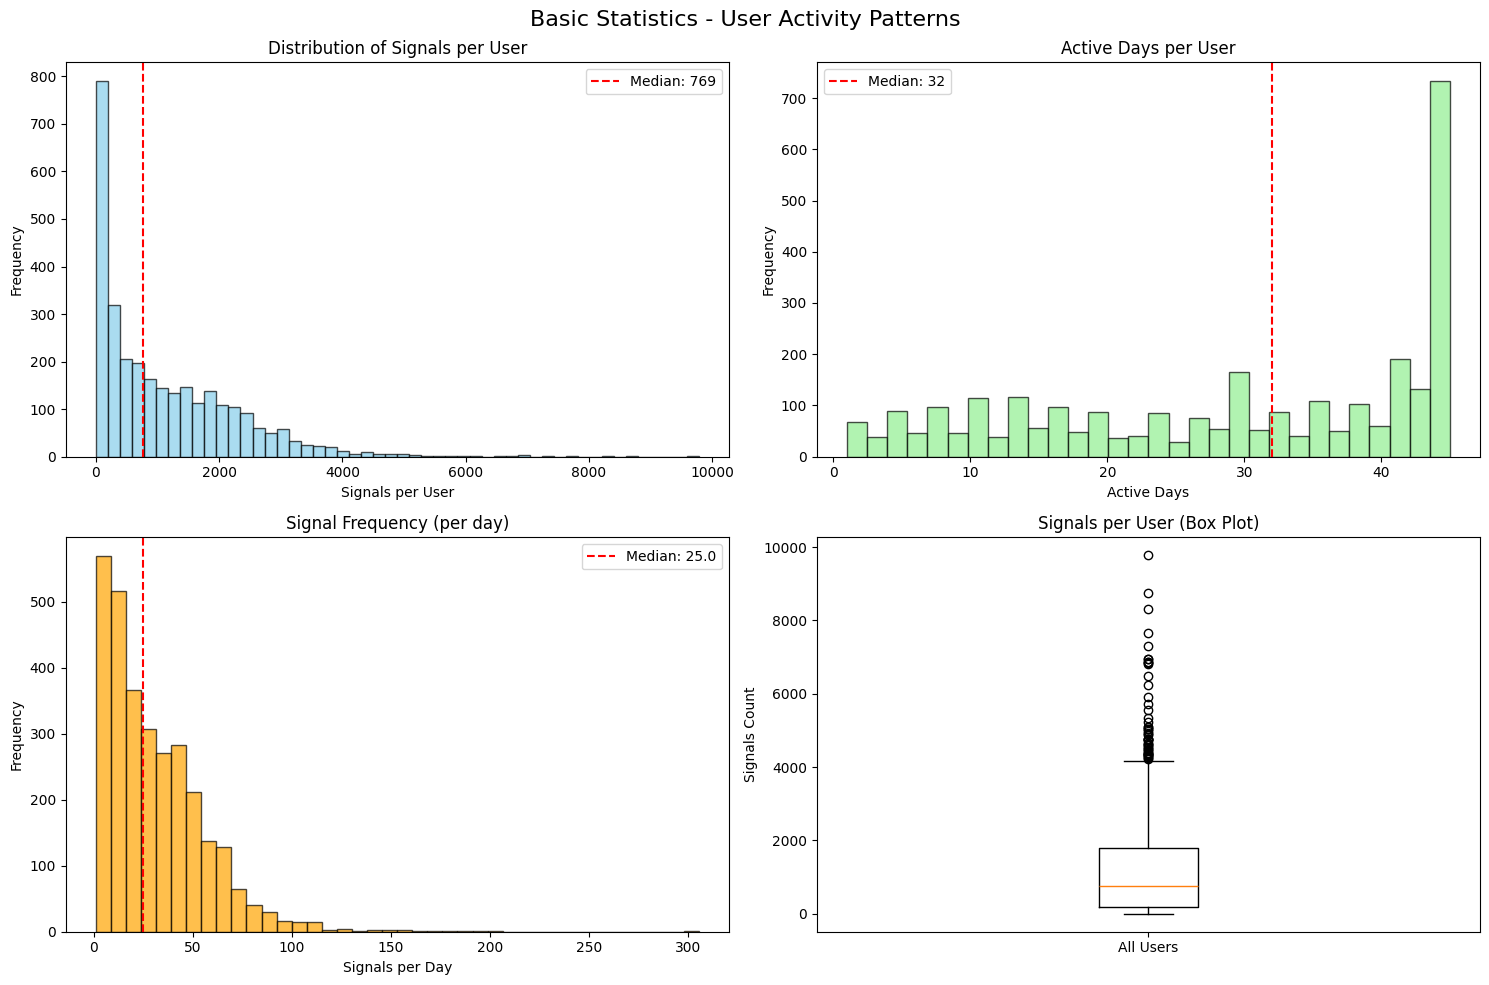


2.SPATIAL COVERAGE
Geographic Bounding Box:
  Latitude: 59.5255 to 70.0411 (span: 10.5156°)
  Longitude: 19.6344 to 31.5068 (span: 11.8724°)

Movement Radius Analysis:
  Median movement radius: 149.9 km
  95th percentile activity space: 585.9 km
  Local users (<10km radius): 173
  Regional users (10-50km): 613
  Cross-city travelers (>50km): 2205

Home Location Identification:
  Users with nighttime data: 2879
  Average home latitude: 61.1432
  Average home longitude: 24.5322


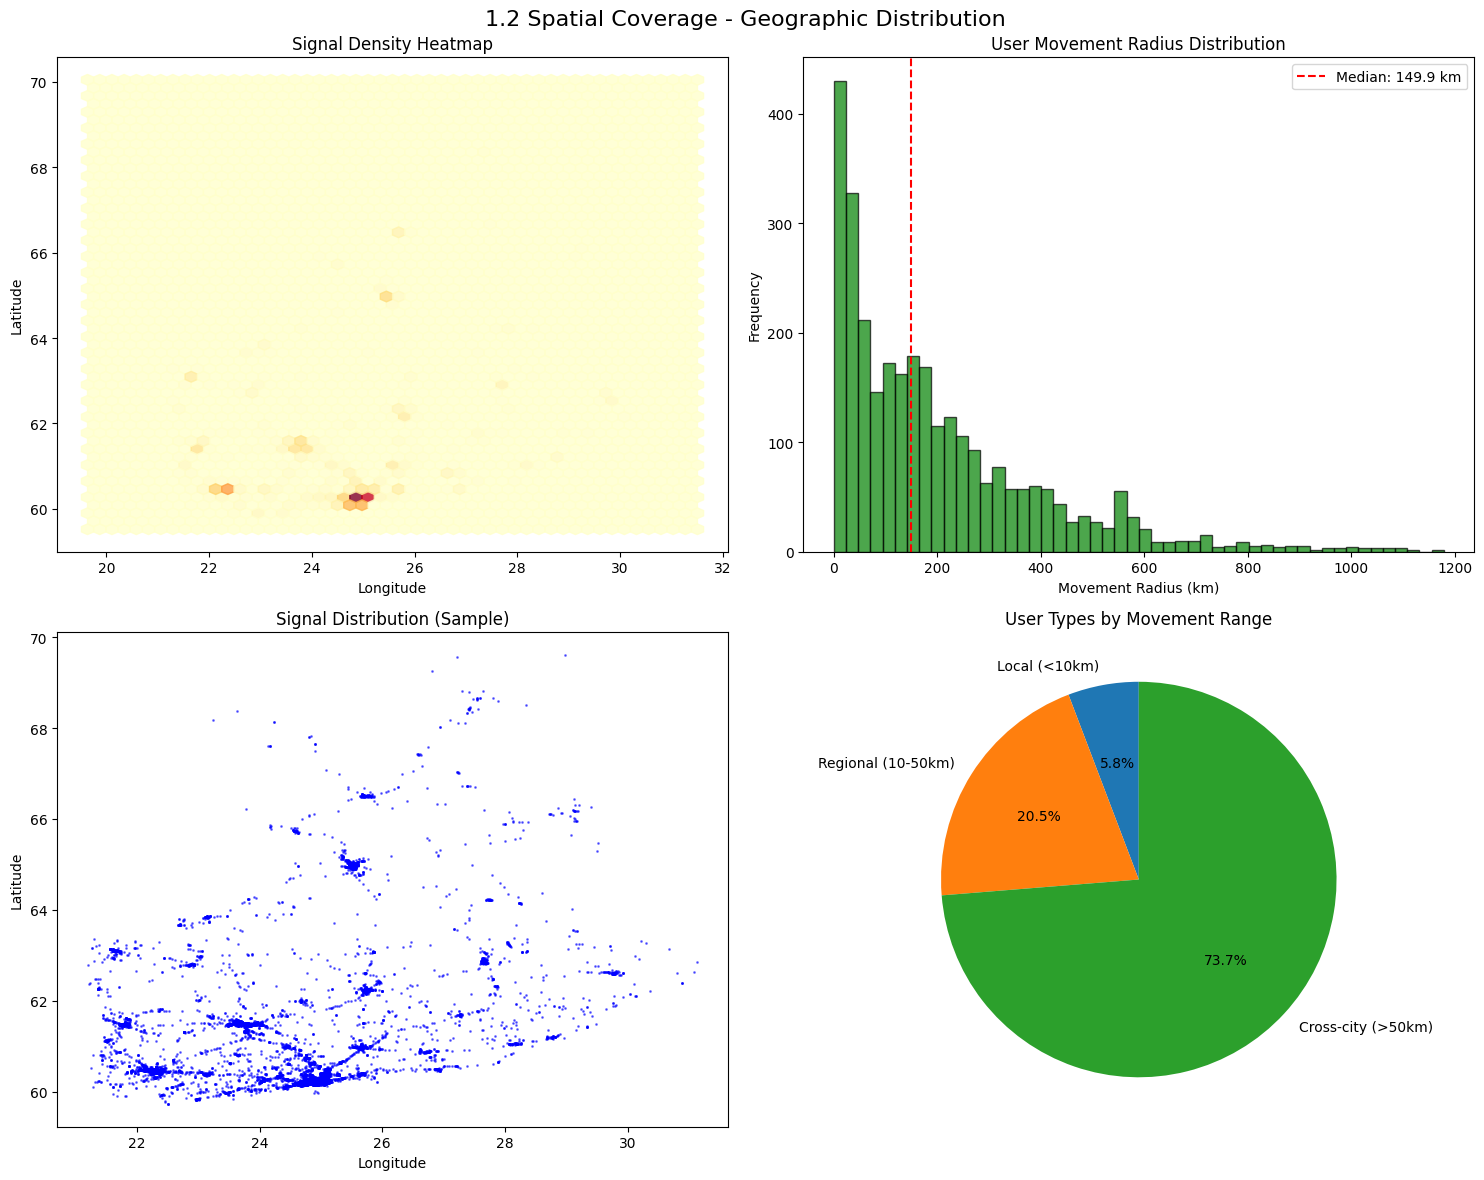


3.TEMPORAL PATTERNS
Hourly Activity Distribution:
  00:00 - 50,942 signals
  01:00 - 67,995 signals
  02:00 - 71,365 signals
  03:00 - 81,860 signals
  04:00 - 94,216 signals
  05:00 - 108,945 signals
  06:00 - 127,095 signals
  07:00 - 158,141 signals
  08:00 - 180,760 signals
  09:00 - 185,305 signals
  10:00 - 191,974 signals
  11:00 - 195,885 signals
  12:00 - 205,641 signals
  13:00 - 211,088 signals
  14:00 - 208,365 signals
  15:00 - 208,376 signals
  16:00 - 193,537 signals
  17:00 - 176,017 signals
  18:00 - 156,102 signals
  19:00 - 133,466 signals
  20:00 - 112,975 signals
  21:00 - 97,720 signals
  22:00 - 82,369 signals
  23:00 - 55,616 signals

Weekday vs Weekend:
  Weekday signals: 1,105,440 (32.9%)
  Weekend signals: 438,155 (13.1%)

Activity Type Distribution:
  stop: 987,660 (29.4%)
  pedestrian: 926,361 (27.6%)
  cars_highway: 697,646 (20.8%)
  cars_city: 584,643 (17.4%)
  cyclist: 149,723 (4.5%)
  non_target: 9,722 (0.3%)

Peak Hours:
  13:00 - 211,088 signals
  15

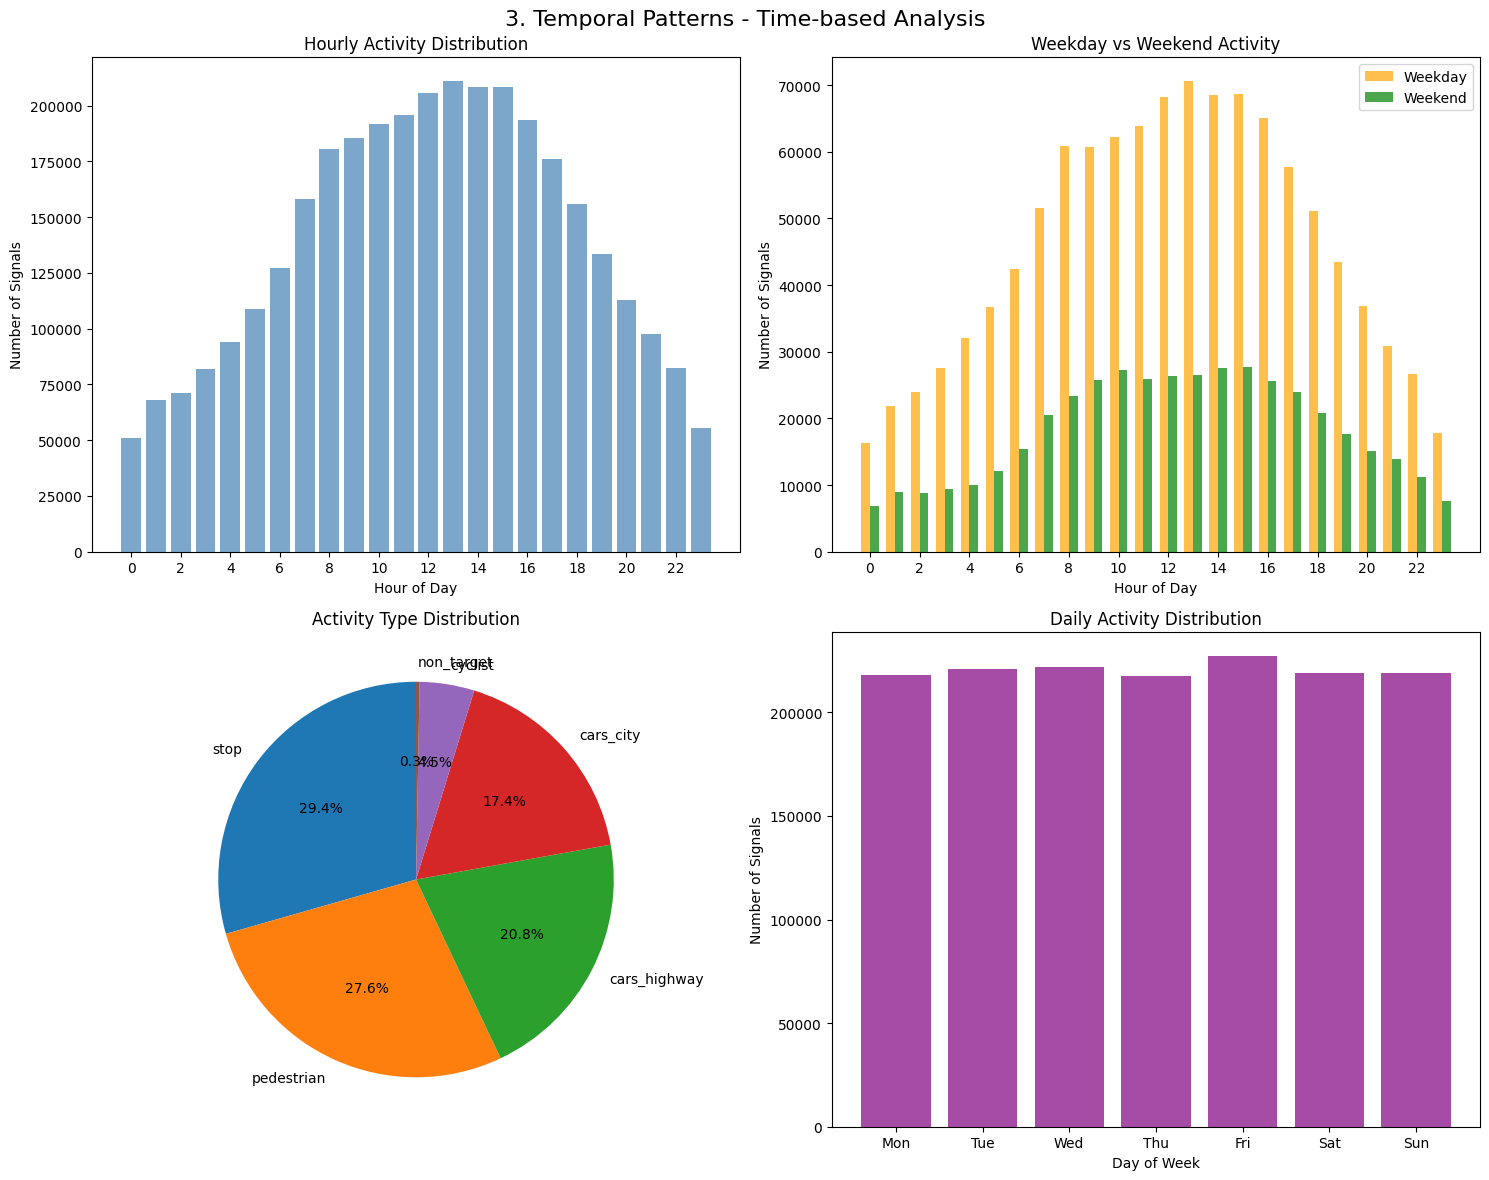

In [ ]:
#Signal Data Exploration
class UserSignalAnalyzer:
    def __init__(self, data_loader):
        self.data_loader = data_loader
        self.signals_df = None
        self.user_stats = None

    def prepare_data(self):
        #Combining and preparing user signals data for analysis
        # Get all user signals data
        self.signals_df = self.data_loader.get_all_user_signals()
        if self.signals_df.empty:
            print("No user signals data found!")
            return False
        print(f"Total signals loaded: {len(self.signals_df):,}")
        # Clean and prepare data
        self.signals_df['hour_str'] = self.signals_df['hour'].astype(str)
        self.signals_df['minute_str'] = self.signals_df['minute'].astype(str)
        self.signals_df['datetime'] = pd.to_datetime(self.signals_df['date'] + ' ' +
                                                   self.signals_df['hour_str'] + ':' +
                                                   self.signals_df['minute_str'],
                                                   format='%Y-%m-%d %H:%M', errors='coerce')
        # Drop helper columns
        self.signals_df = self.signals_df.drop(columns=['hour_str', 'minute_str'])
        # Filter valid coordinates for Finland
        valid_coords = (
            (self.signals_df['latitude'].between(59.5, 70.5)) &
            (self.signals_df['longitude'].between(19.0, 32.0))
        )
        self.signals_df = self.signals_df[valid_coords].copy()
        print(f"Valid signals after filtering: {len(self.signals_df):,}")
        print(f"Unique users: {self.signals_df['user_id'].nunique()}")
        return True

    def basic_statistics(self):
        #Basic Statistics - User activity patterns
        print("\n" + "="*60)
        print("1. BASIC STATISTICS")
        print("="*60)

        # Calculate user-level statistics
        user_stats = self.signals_df.groupby('user_id').agg({
            'user_id': 'count',  # signals per user
            'date': 'nunique',   # active days per user
            'hour': lambda x: x.max() - x.min() + 1,  # hour span
            'datetime': ['min', 'max']
        }).round(2)
        user_stats.columns = ['signals_count', 'active_days', 'hour_span', 'first_signal', 'last_signal']
        # Calculate signal frequency metrics
        user_stats['signals_per_day'] = user_stats['signals_count'] / user_stats['active_days']
        user_stats['signals_per_hour'] = user_stats['signals_count'] / user_stats['hour_span']
        self.user_stats = user_stats

        # Display statistics
        print("Signals per user distribution:")
        print(f"  Min: {user_stats['signals_count'].min()}")
        print(f"  Max: {user_stats['signals_count'].max()}")
        print(f"  Median: {user_stats['signals_count'].median()}")
        print(f"  Mean: {user_stats['signals_count'].mean():.1f}")
        print(f"  Q1: {user_stats['signals_count'].quantile(0.25)}")
        print(f"  Q3: {user_stats['signals_count'].quantile(0.75)}")

        print(f"\nActive days per user:")
        print(f"  Min: {user_stats['active_days'].min()}")
        print(f"  Max: {user_stats['active_days'].max()}")
        print(f"  Median: {user_stats['active_days'].median()}")
        print(f"  Mean: {user_stats['active_days'].mean():.1f}")

        print(f"\nSignal frequency:")
        print(f"  Signals per day (median): {user_stats['signals_per_day'].median():.1f}")
        print(f"  Signals per hour (median): {user_stats['signals_per_hour'].median():.1f}")

        # Identify outliers (users with very high or low activity)
        Q1 = user_stats['signals_count'].quantile(0.25)
        Q3 = user_stats['signals_count'].quantile(0.75)
        IQR = Q3 - Q1
        outlier_threshold_high = Q3 + 1.5 * IQR
        outlier_threshold_low = Q1 - 1.5 * IQR

        high_outliers = user_stats[user_stats['signals_count'] > outlier_threshold_high]
        low_outliers = user_stats[user_stats['signals_count'] < outlier_threshold_low]

        print(f"\nOutliers:")
        print(f"  High activity users (>{outlier_threshold_high:.0f} signals): {len(high_outliers)}")
        print(f"  Low activity users (<{outlier_threshold_low:.0f} signals): {len(low_outliers)}")

        # Coverage gaps analysis
        date_coverage = self.signals_df.groupby('user_id')['date'].apply(
            lambda x: pd.date_range(x.min(), x.max()).difference(pd.to_datetime(x.unique(), errors='coerce')).size
        )

        print(f"\nCoverage gaps:")
        print(f"  Users with no missing days: {(date_coverage == 0).sum()}")
        print(f"  Average missing days per user: {date_coverage.mean():.1f}")
        print(f"  Max missing days: {date_coverage.max()}")

        # Create visualizations
        fig, axes = plt.subplots(2, 2, figsize=(15, 10))
        fig.suptitle('Basic Statistics - User Activity Patterns', fontsize=16)

        # Signals per user distribution
        axes[0,0].hist(user_stats['signals_count'], bins=50, alpha=0.7, color='skyblue', edgecolor='black')
        axes[0,0].axvline(user_stats['signals_count'].median(), color='red', linestyle='--', label=f'Median: {user_stats["signals_count"].median():.0f}')
        axes[0,0].set_xlabel('Signals per User')
        axes[0,0].set_ylabel('Frequency')
        axes[0,0].set_title('Distribution of Signals per User')
        axes[0,0].legend()

        # Active days per user
        axes[0,1].hist(user_stats['active_days'], bins=30, alpha=0.7, color='lightgreen', edgecolor='black')
        axes[0,1].axvline(user_stats['active_days'].median(), color='red', linestyle='--', label=f'Median: {user_stats["active_days"].median():.0f}')
        axes[0,1].set_xlabel('Active Days')
        axes[0,1].set_ylabel('Frequency')
        axes[0,1].set_title('Active Days per User')
        axes[0,1].legend()

        # Signals per day distribution
        axes[1,0].hist(user_stats['signals_per_day'], bins=40, alpha=0.7, color='orange', edgecolor='black')
        axes[1,0].axvline(user_stats['signals_per_day'].median(), color='red', linestyle='--', label=f'Median: {user_stats["signals_per_day"].median():.1f}')
        axes[1,0].set_xlabel('Signals per Day')
        axes[1,0].set_ylabel('Frequency')
        axes[1,0].set_title('Signal Frequency (per day)')
        axes[1,0].legend()

        # Box plot for outlier visualization
        axes[1,1].boxplot([user_stats['signals_count']], labels=['All Users'])
        axes[1,1].set_ylabel('Signals Count')
        axes[1,1].set_title('Signals per User (Box Plot)')
        plt.tight_layout()
        plt.show()
        return user_stats

    def spatial_coverage(self):
        #patial Coverage - Geographic distribution analysis
        print("\n" + "="*60)
        print("2.SPATIAL COVERAGE")
        print("="*60)

        # Geographic bounding box
        lat_min, lat_max = self.signals_df['latitude'].min(), self.signals_df['latitude'].max()
        lon_min, lon_max = self.signals_df['longitude'].min(), self.signals_df['longitude'].max()

        print(f"Geographic Bounding Box:")
        print(f"  Latitude: {lat_min:.4f} to {lat_max:.4f} (span: {lat_max-lat_min:.4f}°)")
        print(f"  Longitude: {lon_min:.4f} to {lon_max:.4f} (span: {lon_max-lon_min:.4f}°)")

        # Calculate movement radius per user
        user_spatial_stats = self.signals_df.groupby('user_id').agg({
            'latitude': ['min', 'max', 'std'],
            'longitude': ['min', 'max', 'std']
        })
        user_spatial_stats.columns = ['lat_min', 'lat_max', 'lat_std', 'lon_min', 'lon_max', 'lon_std']

        # Calculate movement radius (approximate distance)
        user_spatial_stats['lat_range'] = user_spatial_stats['lat_max'] - user_spatial_stats['lat_min']
        user_spatial_stats['lon_range'] = user_spatial_stats['lon_max'] - user_spatial_stats['lon_min']

        # Rough distance calculation (1 degree ≈ 111 km for latitude, varies for longitude)
        user_spatial_stats['movement_radius_km'] = np.sqrt(
            (user_spatial_stats['lat_range'] * 111)**2 +
            (user_spatial_stats['lon_range'] * 111 * np.cos(np.radians(user_spatial_stats['lat_min'])))**2
        )

        print(f"\nMovement Radius Analysis:")
        print(f"  Median movement radius: {user_spatial_stats['movement_radius_km'].median():.1f} km")
        print(f"  95th percentile activity space: {user_spatial_stats['movement_radius_km'].quantile(0.95):.1f} km")
        print(f"  Local users (<10km radius): {(user_spatial_stats['movement_radius_km'] < 10).sum()}")
        print(f"  Regional users (10-50km): {((user_spatial_stats['movement_radius_km'] >= 10) & (user_spatial_stats['movement_radius_km'] < 50)).sum()}")
        print(f"  Cross-city travelers (>50km): {(user_spatial_stats['movement_radius_km'] >= 50).sum()}")

        # Identify home locations (most common nighttime location)
        night_signals = self.signals_df[self.signals_df['hour'].isin([22, 23, 0, 1, 2, 3, 4, 5])]
        if not night_signals.empty:
            home_locations = night_signals.groupby('user_id').agg({
                'latitude': 'median',
                'longitude': 'median'
            }).round(4)

            print(f"\nHome Location Identification:")
            print(f"  Users with nighttime data: {len(home_locations)}")
            print(f"  Average home latitude: {home_locations['latitude'].mean():.4f}")
            print(f"  Average home longitude: {home_locations['longitude'].mean():.4f}")

        # Create visualizations
        fig, axes = plt.subplots(2, 2, figsize=(15, 12))
        fig.suptitle('1.2 Spatial Coverage - Geographic Distribution', fontsize=16)

        # Signal density heatmap
        axes[0,0].hexbin(self.signals_df['longitude'], self.signals_df['latitude'],
                        gridsize=50, cmap='YlOrRd', alpha=0.8)
        axes[0,0].set_xlabel('Longitude')
        axes[0,0].set_ylabel('Latitude')
        axes[0,0].set_title('Signal Density Heatmap')

        # Movement radius distribution
        axes[0,1].hist(user_spatial_stats['movement_radius_km'], bins=50, alpha=0.7, color='green', edgecolor='black')
        axes[0,1].axvline(user_spatial_stats['movement_radius_km'].median(), color='red', linestyle='--',
                         label=f'Median: {user_spatial_stats["movement_radius_km"].median():.1f} km')
        axes[0,1].set_xlabel('Movement Radius (km)')
        axes[0,1].set_ylabel('Frequency')
        axes[0,1].set_title('User Movement Radius Distribution')
        axes[0,1].legend()

        # Scatter plot of all signals
        sample_signals = self.signals_df.sample(min(10000, len(self.signals_df)))  # Sample for performance
        axes[1,0].scatter(sample_signals['longitude'], sample_signals['latitude'],
                         alpha=0.5, s=1, c='blue')
        axes[1,0].set_xlabel('Longitude')
        axes[1,0].set_ylabel('Latitude')
        axes[1,0].set_title('Signal Distribution (Sample)')

        # User type classification
        user_types = ['Local (<10km)', 'Regional (10-50km)', 'Cross-city (>50km)']
        user_counts = [
            (user_spatial_stats['movement_radius_km'] < 10).sum(),
            ((user_spatial_stats['movement_radius_km'] >= 10) & (user_spatial_stats['movement_radius_km'] < 50)).sum(),
            (user_spatial_stats['movement_radius_km'] >= 50).sum()
        ]

        axes[1,1].pie(user_counts, labels=user_types, autopct='%1.1f%%', startangle=90)
        axes[1,1].set_title('User Types by Movement Range')
        plt.tight_layout()
        plt.show()
        return user_spatial_stats

    def temporal_patterns(self):
        #Temporal Patterns - Time-based analysis
        print("\n" + "="*60)
        print("3.TEMPORAL PATTERNS")
        print("="*60)

        # Hourly activity distribution
        hourly_activity = self.signals_df['hour'].value_counts().sort_index()
        print("Hourly Activity Distribution:")
        for hour, count in hourly_activity.items():
            print(f"  {hour:02d}:00 - {count:,} signals")

        # Weekday vs weekend patterns
        self.signals_df['weekday'] = self.signals_df['day_of_week']
        weekday_signals = self.signals_df[self.signals_df['weekday'].isin([1, 2, 3, 4, 5])]  # Mon-Fri
        weekend_signals = self.signals_df[self.signals_df['weekday'].isin([6, 7])]  # Sat-Sun

        print(f"\nWeekday vs Weekend:")
        print(f"  Weekday signals: {len(weekday_signals):,} ({len(weekday_signals)/len(self.signals_df)*100:.1f}%)")
        print(f"  Weekend signals: {len(weekend_signals):,} ({len(weekend_signals)/len(self.signals_df)*100:.1f}%)")

        # Activity type distribution
        if 'activity_type' in self.signals_df.columns:
            activity_dist = self.signals_df['activity_type'].value_counts()
            print(f"\nActivity Type Distribution:")
            for activity, count in activity_dist.items():
                print(f"  {activity}: {count:,} ({count/len(self.signals_df)*100:.1f}%)")

        # Peak hours identification
        peak_hours = hourly_activity.nlargest(3)
        print(f"\nPeak Hours:")
        for hour, count in peak_hours.items():
            print(f"  {hour:02d}:00 - {count:,} signals")

        # Night vs day activity
        night_hours = [22, 23, 0, 1, 2, 3, 4, 5]
        day_hours = [6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]

        night_signals = len(self.signals_df[self.signals_df['hour'].isin(night_hours)])
        day_signals = len(self.signals_df[self.signals_df['hour'].isin(day_hours)])

        print(f"\nDay vs Night Activity:")
        print(f"  Day signals (6-21): {day_signals:,} ({day_signals/len(self.signals_df)*100:.1f}%)")
        print(f"  Night signals (22-5): {night_signals:,} ({night_signals/len(self.signals_df)*100:.1f}%)")
        print(f"  Day/Night ratio: {day_signals/night_signals:.1f}")

        # Create visualizations
        fig, axes = plt.subplots(2, 2, figsize=(15, 12))
        fig.suptitle('3. Temporal Patterns - Time-based Analysis', fontsize=16)

        # Hourly activity pattern
        axes[0,0].bar(hourly_activity.index, hourly_activity.values, alpha=0.7, color='steelblue')
        axes[0,0].set_xlabel('Hour of Day')
        axes[0,0].set_ylabel('Number of Signals')
        axes[0,0].set_title('Hourly Activity Distribution')
        axes[0,0].set_xticks(range(0, 24, 2))

        # Weekday vs weekend comparison
        weekday_hourly = weekday_signals['hour'].value_counts().sort_index()
        weekend_hourly = weekend_signals['hour'].value_counts().sort_index()

        x = range(24)
        width = 0.35
        axes[0,1].bar([i - width/2 for i in x], [weekday_hourly.get(i, 0) for i in x],
                     width, label='Weekday', alpha=0.7, color='orange')
        axes[0,1].bar([i + width/2 for i in x], [weekend_hourly.get(i, 0) for i in x],
                     width, label='Weekend', alpha=0.7, color='green')
        axes[0,1].set_xlabel('Hour of Day')
        axes[0,1].set_ylabel('Number of Signals')
        axes[0,1].set_title('Weekday vs Weekend Activity')
        axes[0,1].legend()
        axes[0,1].set_xticks(range(0, 24, 2))

        # Activity type distribution (if available)
        if 'activity_type' in self.signals_df.columns and not activity_dist.empty:
            axes[1,0].pie(activity_dist.values, labels=activity_dist.index, autopct='%1.1f%%', startangle=90)
            axes[1,0].set_title('Activity Type Distribution')
        else:
            axes[1,0].text(0.5, 0.5, 'Activity type data\nnot available',
                          ha='center', va='center', transform=axes[1,0].transAxes)
            axes[1,0].set_title('Activity Type Distribution')

        # Day of week pattern
        daily_activity = self.signals_df['day_of_week'].value_counts().sort_index()
        day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
        axes[1,1].bar(range(1, 8), [daily_activity.get(i, 0) for i in range(1, 8)],
                     alpha=0.7, color='purple')
        axes[1,1].set_xlabel('Day of Week')
        axes[1,1].set_ylabel('Number of Signals')
        axes[1,1].set_title('Daily Activity Distribution')
        axes[1,1].set_xticks(range(1, 8))
        axes[1,1].set_xticklabels(day_names)

        plt.tight_layout()
        plt.show()

        return {
            'hourly_activity': hourly_activity,
            'weekday_signals': len(weekday_signals),
            'weekend_signals': len(weekend_signals),
            'activity_distribution': activity_dist if 'activity_type' in self.signals_df.columns else None,
            'day_night_ratio': day_signals/night_signals if night_signals > 0 else 0
        }

    def run_full_analysis(self):
        print(" USER SIGNAL DATA EXPLORATION")
        print("="*60)

        if not self.prepare_data():
            return None

        # Run all analyses
        basic_stats = self.basic_statistics()
        spatial_stats = self.spatial_coverage()
        temporal_stats = self.temporal_patterns()

        return {
            'basic_stats': basic_stats,
            'spatial_stats': spatial_stats,
            'temporal_stats': temporal_stats,
            'signals_df': self.signals_df
        }

#Calling the main function
analyzer = UserSignalAnalyzer(data_loader)
results = analyzer.run_full_analysis()

POI DATA EXPLORATION
Total POI records loaded: 720,368
POI datasets: ['POIs_2024-07_POIs_for_JCD_Finland_(micodes)'
 'POIs_2024-07_POIs_for_JCD_Finland_(brands)'
 'POIs_2024-08_POIs_for_JCD_Finland_(micodes)'
 'POIs_2024-08_POIs_for_JCD_Finland_(brands)'
 'POIs_2024-09_POIs_for_JCD_Finland_(brands)'
 'POIs_2024-09_POIs_for_JCD_Finland_(micodes)'
 'POI_data_layout_LOCOMIZER_WPPOI Data Layout by LOCOMIZER '
 'POI_data_layout_LOCOMIZER_Field Value Key'
 'General_POI_Taxonomy_micode_sheet_micode_sheet'
 'LOCOMIZER_Brand_Affinity_Categories_Profiles_in_Finland_2023-2024_LOCOMIZER_BA_CATEGORIES_FINLAND']
Valid POIs after cleaning: 700,656
Brand POIs: 11,442
Micode POIs: 689,214
 POI DISTRIBUTION ANALYSIS
POI Category Analysis:

Top 10 Main Classes:
   1. PUBLIC TRANSPORT STOP: 102,411 POIs
   2. EATING PLACES/RESTAURANTS: 99,009 POIs
   3. BEAUTY SHOPS: 82,080 POIs
   4. AUTOMOTIVE REPAIR SHOPS: 42,603 POIs
   5. GROCERY STORES: 27,996 POIs
   6. HOSPITALS: 25,809 POIs
   7. ELEMENTARY AND S

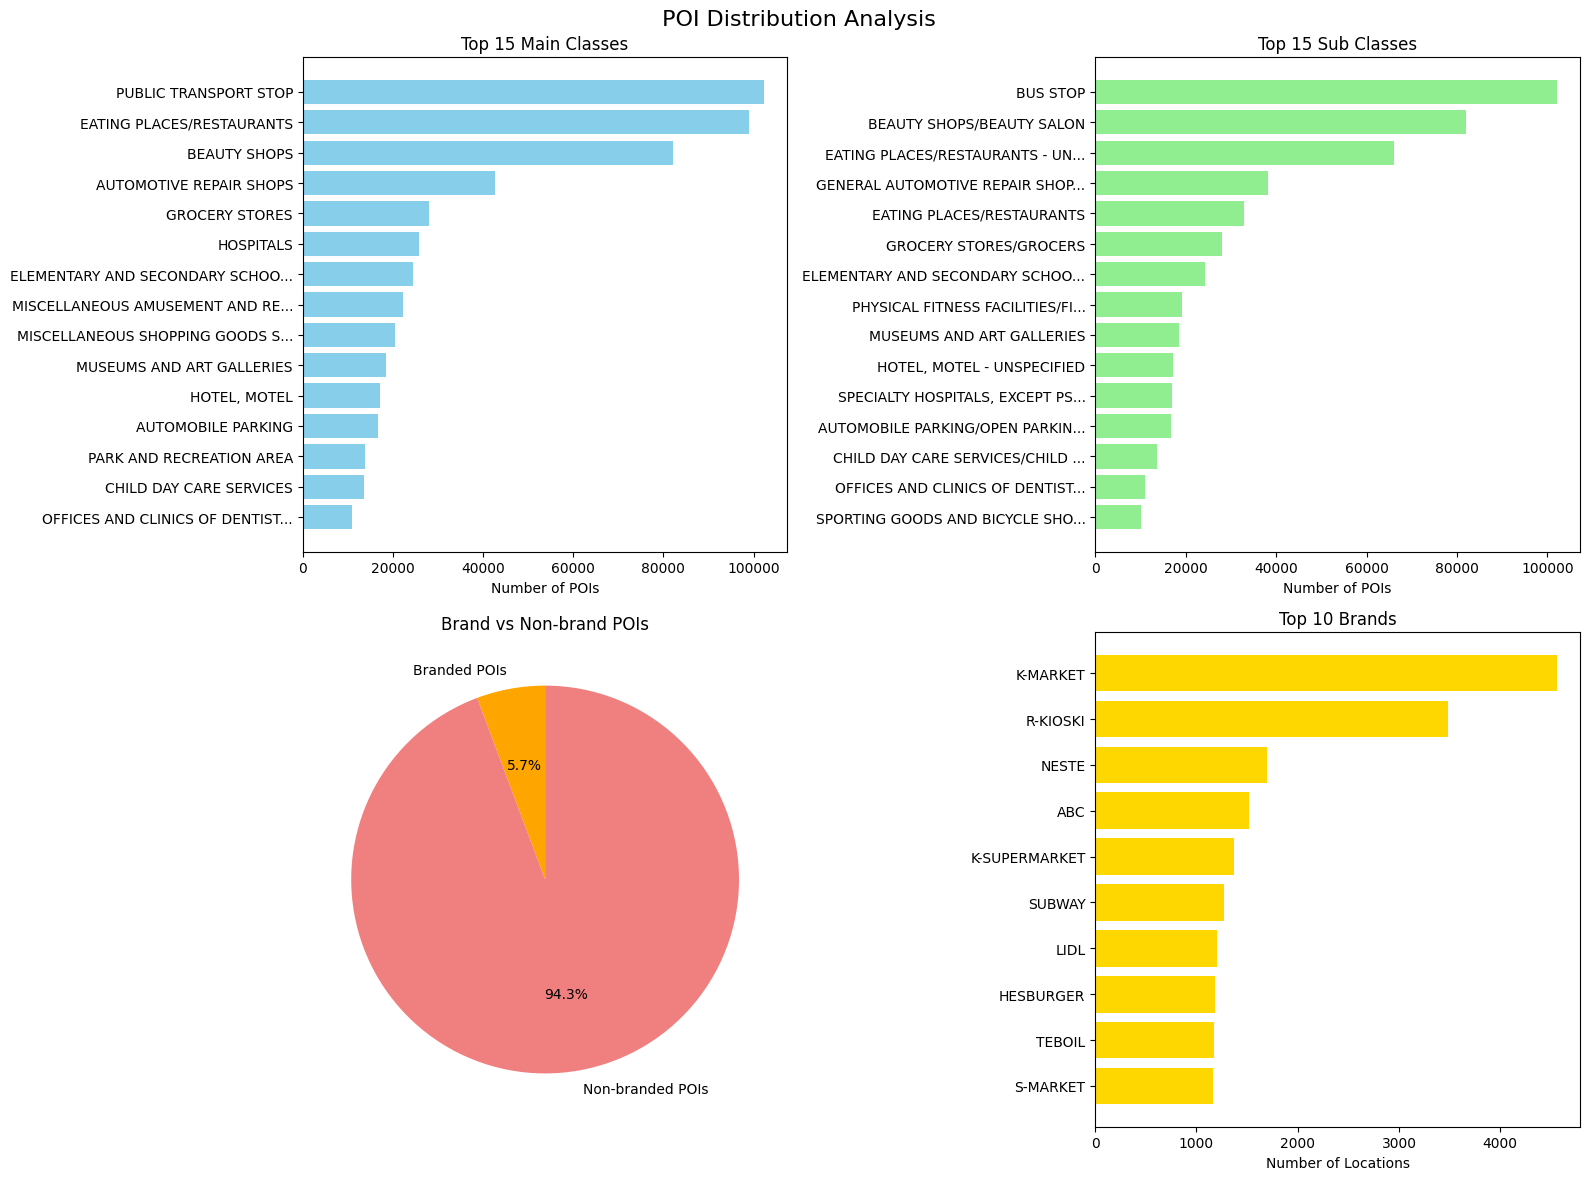

SPATIAL CHARACTERISTICS
Geographic Coverage:
  Latitude: 59.7804 to 70.0889 (span: 10.3085°)
  Longitude: 19.5391 to 31.3844 (span: 11.8453°)

POI Clustering Analysis:
  Clusters found: 268
  Noise points: 4579 (45.8%)
  Clustered points: 5421 (54.2%)

Nearest Neighbor Analysis:
  Median nearest neighbor distance: 0.51 km
  Mean nearest neighbor distance: 2.44 km
  25th percentile: 0.15 km
  75th percentile: 1.80 km

Nearest neighbor by category (top 5 categories):
  EATING PLACES/RESTAURANTS: 0.30 km
  PUBLIC TRANSPORT STOP: 2.81 km
  BEAUTY SHOPS: 0.22 km
  AUTOMOTIVE REPAIR SHOPS: 0.95 km
  HOSPITALS: 0.42 km

Urban vs Rural Analysis:
  High density (urban) cells: 299 (12.5%)
  Low density (rural) cells: 878 (36.6%)
  Empty cells: 1224 (51.0%)
  Density threshold: 327 POIs per cell

Coverage Gap Analysis

Urban vs Rural Analysis:
  High density (urban) cells: 299 (12.5%)
  Low density (rural) cells: 878 (36.6%)
  Empty cells: 1224 (51.0%)
  Density threshold: 327 POIs per cell
  Cov

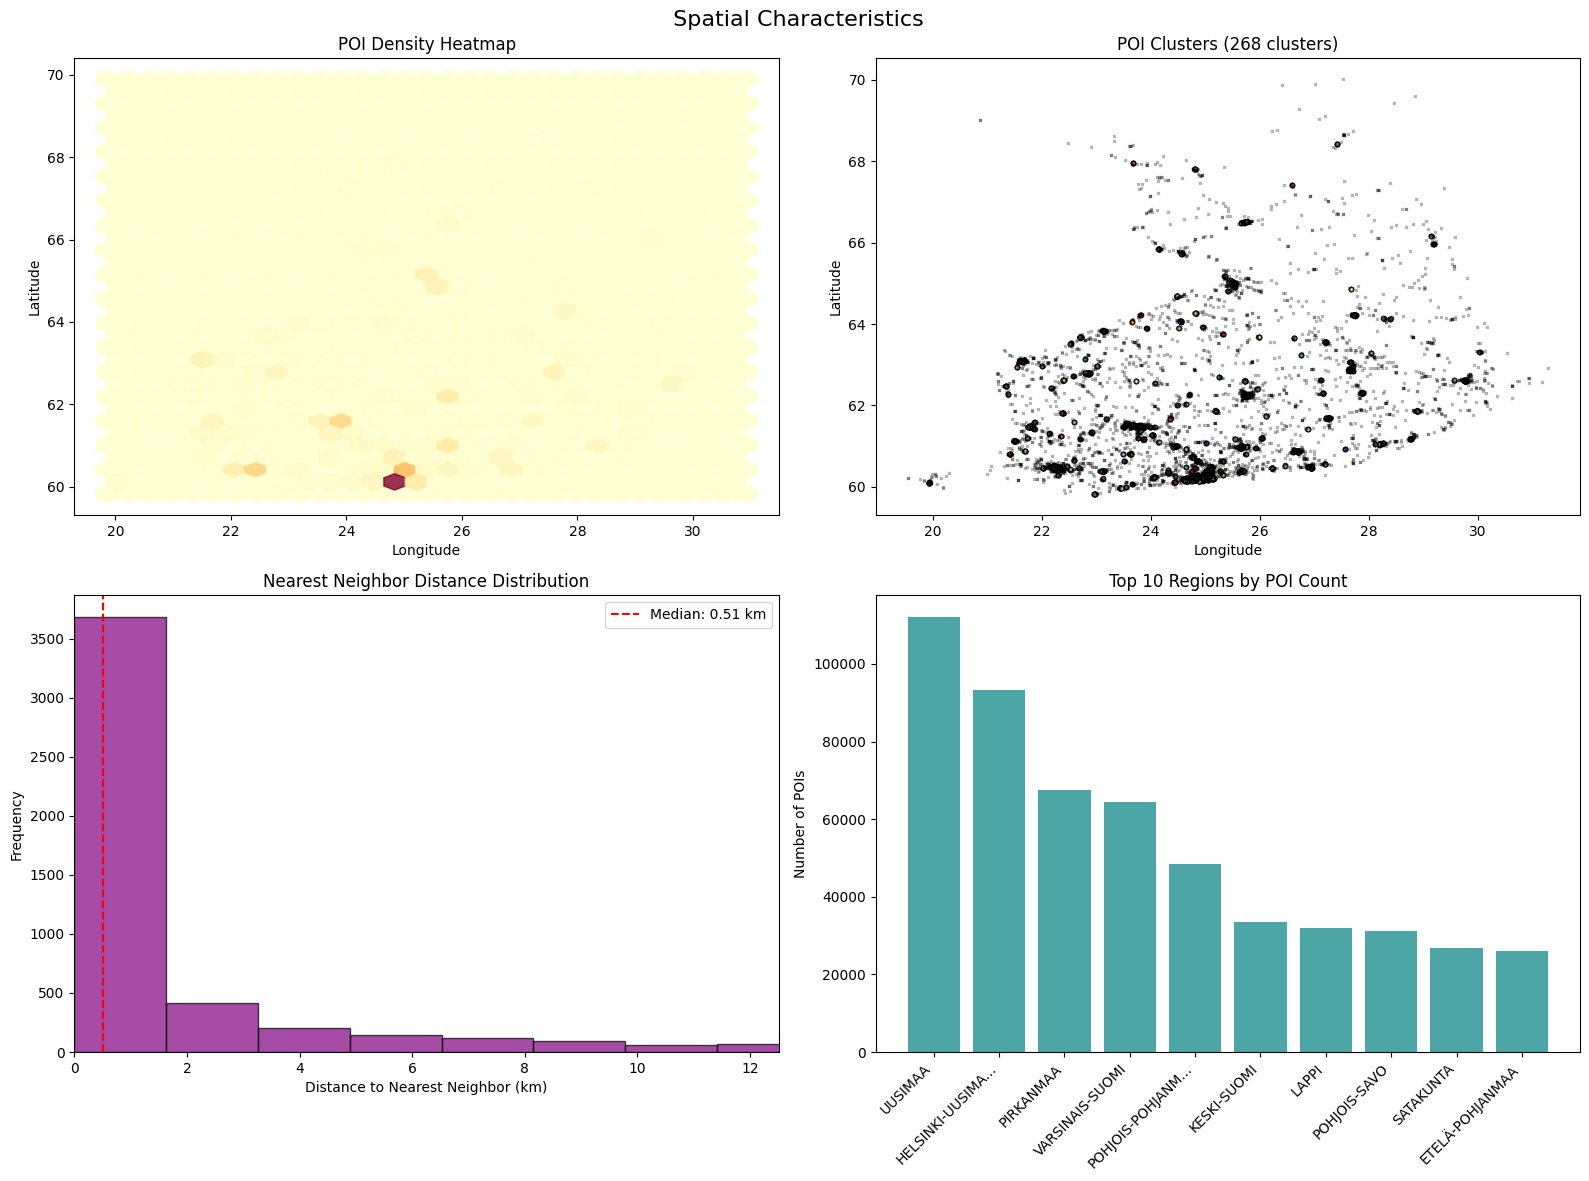

 DATA QUALITY CHECKS

Duplicate Detection:
  Exact coordinate duplicates: 555036 (79.2%)
  Name + coordinate duplicates: 471483 (67.3%)

Missing Classification Analysis:
  MAIN_CLASS: 0 missing (0.0%)
  SUB_CLASS: 0 missing (0.0%)
  TRADE_DIVISION: 0 missing (0.0%)
  SIC8: 180975 missing (25.8%)
  MICODE: 0 missing (0.0%)

Coordinate Validity:
  Invalid coordinates (outside Finland): 0 (0.0%)
  Low precision coordinates (≤3 decimals): 14538 (2.1%)
  Average latitude precision: 4.9 decimals
  Average longitude precision: 4.9 decimals

Name Standardization Analysis:
  Empty names: 0 (0.0%)
  Very short names (≤2 chars): 183 (0.0%)
  Names with unusual characters: 16047 (2.3%)
  Potential encoding issues: 0 (0.0%)

Overall Data Quality Score: 83.2/100


In [ ]:
#POI Data Exploration
class POIAnalyzer:
    def __init__(self, data_loader):
        self.data_loader = data_loader
        self.poi_df = None
        self.brand_pois = None
        self.micode_pois = None

    def prepare_data(self):
        # Get all POI data
        all_poi_data = self.data_loader.get_all_pois()
        if all_poi_data.empty:
            print("No POI data found!")
            return False
        print(f"Total POI records loaded: {len(all_poi_data):,}")
        print(f"POI datasets: {all_poi_data['_source_dataset'].unique()}")

        # Separate brand and micode POIs based on source dataset
        brand_datasets = [ds for ds in all_poi_data['_source_dataset'].unique() if 'brands' in ds]
        micode_datasets = [ds for ds in all_poi_data['_source_dataset'].unique() if 'micodes' in ds]

        self.brand_pois = all_poi_data[all_poi_data['_source_dataset'].isin(brand_datasets)].copy()
        self.micode_pois = all_poi_data[all_poi_data['_source_dataset'].isin(micode_datasets)].copy()

        # Combining all POI data
        self.poi_df = all_poi_data.copy()

        # Cleaning coordinates
        self.poi_df = self.poi_df.dropna(subset=['LATITUDE', 'LONGITUDE'])

        # Filter valid coordinates for Finland
        valid_coords = (
            (self.poi_df['LATITUDE'].between(59.5, 70.5)) &
            (self.poi_df['LONGITUDE'].between(19.0, 32.0))
        )
        self.poi_df = self.poi_df[valid_coords].copy()

        print(f"Valid POIs after cleaning: {len(self.poi_df):,}")
        print(f"Brand POIs: {len(self.brand_pois):,}")
        print(f"Micode POIs: {len(self.micode_pois):,}")

        return True

    def poi_distribution_analysis(self):
        #1. POI Distribution Analysis
        print(" POI DISTRIBUTION ANALYSIS")

        # Category frequencies
        print("POI Category Analysis:")

        # Main class distribution
        if 'MAIN_CLASS' in self.poi_df.columns:
            main_class_counts = self.poi_df['MAIN_CLASS'].value_counts()
            print(f"\nTop 10 Main Classes:")
            for i, (category, count) in enumerate(main_class_counts.head(10).items(), 1):
                print(f"  {i:2d}. {category}: {count:,} POIs")

            print(f"\nLeast common Main Classes (bottom 5):")
            for i, (category, count) in enumerate(main_class_counts.tail(5).items(), 1):
                print(f"  {i:2d}. {category}: {count:,} POIs")

        # Sub class distribution
        if 'SUB_CLASS' in self.poi_df.columns:
            sub_class_counts = self.poi_df['SUB_CLASS'].value_counts()
            print(f"\nTop 10 Sub Classes:")
            for i, (category, count) in enumerate(sub_class_counts.head(10).items(), 1):
                print(f"  {i:2d}. {category}: {count:,} POIs")

        # Brand vs non-brand analysis
        brand_analysis = self._analyze_brands()

        # Regional analysis
        regional_analysis = self._analyze_regional_distribution()

        # Create visualizations
        self._create_distribution_plots(main_class_counts, sub_class_counts, brand_analysis)

        return {
            'main_class_counts': main_class_counts if 'MAIN_CLASS' in self.poi_df.columns else None,
            'sub_class_counts': sub_class_counts if 'SUB_CLASS' in self.poi_df.columns else None,
            'brand_analysis': brand_analysis,
            'regional_analysis': regional_analysis
        }

    def _analyze_brands(self):
        #Analyze brand vs non-brand POI distribution
        print(f"\nBrand Analysis:")

        # Count POIs with brand names
        brand_pois = self.poi_df['BRANDNAME'].notna()
        non_brand_pois = self.poi_df['BRANDNAME'].isna()

        brand_count = brand_pois.sum()
        non_brand_count = non_brand_pois.sum()
        total_pois = len(self.poi_df)

        print(f"  POIs with brand names: {brand_count:,} ({brand_count/total_pois*100:.1f}%)")
        print(f"  POIs without brand names: {non_brand_count:,} ({non_brand_count/total_pois*100:.1f}%)")

        # Top brands
        if brand_count > 0:
            top_brands = self.poi_df['BRANDNAME'].value_counts().head(10)
            print(f"\nTop 10 Brands:")
            for i, (brand, count) in enumerate(top_brands.items(), 1):
                print(f"  {i:2d}. {brand}: {count:,} locations")

        return {
            'brand_count': brand_count,
            'non_brand_count': non_brand_count,
            'brand_ratio': brand_count / total_pois,
            'top_brands': top_brands if brand_count > 0 else None
        }

    def _analyze_regional_distribution(self):
        # POI distribution by region
        print(f"\nRegional Distribution:")

        if 'AREANAME2' in self.poi_df.columns:
            region_counts = self.poi_df['AREANAME2'].value_counts()
            print(f"POI distribution by region (top 10):")
            for i, (region, count) in enumerate(region_counts.head(10).items(), 1):
                print(f"  {i:2d}. {region}: {count:,} POIs")

            # Calculate POI density
            region_density = region_counts / region_counts.sum() * 100
            print(f"\nRegion concentration (top 5):")
            for i, (region, density) in enumerate(region_density.head(5).items(), 1):
                print(f"  {i:2d}. {region}: {density:.1f}% of all POIs")

        return {
            'region_counts': region_counts if 'AREANAME2' in self.poi_df.columns else None,
            'region_density': region_density if 'AREANAME2' in self.poi_df.columns else None
        }

    def spatial_characteristics(self):
        #Spatial Characteristics Analysis
        print("SPATIAL CHARACTERISTICS")

        # Geographic bounding box
        lat_min, lat_max = self.poi_df['LATITUDE'].min(), self.poi_df['LATITUDE'].max()
        lon_min, lon_max = self.poi_df['LONGITUDE'].min(), self.poi_df['LONGITUDE'].max()

        print(f"Geographic Coverage:")
        print(f"  Latitude: {lat_min:.4f} to {lat_max:.4f} (span: {lat_max-lat_min:.4f}°)")
        print(f"  Longitude: {lon_min:.4f} to {lon_max:.4f} (span: {lon_max-lon_min:.4f}°)")

        # POI clustering analysis
        clustering_results = self._analyze_clustering()

        # Nearest neighbor analysis
        nn_analysis = self._nearest_neighbor_analysis()

        # Urban vs rural analysis
        urban_rural_analysis = self._urban_rural_analysis()

        # Coverage gaps
        coverage_gaps = self._analyze_coverage_gaps()

        #  spatial visualizations
        self._create_spatial_plots(clustering_results, nn_analysis)

        return {
            'clustering_results': clustering_results,
            'nearest_neighbor': nn_analysis,
            'urban_rural': urban_rural_analysis,
            'coverage_gaps': coverage_gaps
        }

    def _analyze_clustering(self):
        #POI clustering patterns
        print(f"\nPOI Clustering Analysis:")

        # Sample data for clustering
        sample_size = min(10000, len(self.poi_df))
        sample_df = self.poi_df.sample(sample_size, random_state=42)

        # DBSCAN clustering
        coords = sample_df[['LATITUDE', 'LONGITUDE']].values

        # Using epsilon for geographic coordinates approx of 1KM
        eps_km = 1.0
        eps_degrees = eps_km / 111.0

        clustering = DBSCAN(eps=eps_degrees, min_samples=5).fit(coords)
        labels = clustering.labels_

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)

        print(f"  Clusters found: {n_clusters}")
        print(f"  Noise points: {n_noise} ({n_noise/len(labels)*100:.1f}%)")
        print(f"  Clustered points: {len(labels) - n_noise} ({(len(labels) - n_noise)/len(labels)*100:.1f}%)")

        return {
            'n_clusters': n_clusters,
            'n_noise': n_noise,
            'cluster_labels': labels,
            'sample_coords': coords
        }

    def _nearest_neighbor_analysis(self):
        #Analyze distances to nearest neighbors by category
        print(f"\nNearest Neighbor Analysis:")

        # Sample for performance
        sample_size = min(5000, len(self.poi_df))
        sample_df = self.poi_df.sample(sample_size, random_state=42)
        coords = sample_df[['LATITUDE', 'LONGITUDE']].values

        # Calculate distance matrix in degrees
        distances = cdist(coords, coords, metric='euclidean')

        # Set diagonal to infinity to exclude self-distances
        np.fill_diagonal(distances, np.inf)

        # Find nearest neighbor distances
        nn_distances = np.min(distances, axis=1)

        # Convert to approximate km (rough conversion)
        nn_distances_km = nn_distances * 111

        print(f"  Median nearest neighbor distance: {np.median(nn_distances_km):.2f} km")
        print(f"  Mean nearest neighbor distance: {np.mean(nn_distances_km):.2f} km")
        print(f"  25th percentile: {np.percentile(nn_distances_km, 25):.2f} km")
        print(f"  75th percentile: {np.percentile(nn_distances_km, 75):.2f} km")

        # Analyze by category if available
        if 'MAIN_CLASS' in sample_df.columns:
            category_nn = {}
            top_categories = sample_df['MAIN_CLASS'].value_counts().head(5)

            print(f"\nNearest neighbor by category (top 5 categories):")
            for category in top_categories.index:
                cat_mask = sample_df['MAIN_CLASS'] == category
                if cat_mask.sum() > 1:  # Need at least 2 POIs
                    cat_indices = np.where(cat_mask)[0]
                    cat_distances = nn_distances_km[cat_indices]
                    median_dist = np.median(cat_distances)
                    category_nn[category] = median_dist
                    print(f"  {category}: {median_dist:.2f} km")

        return {
            'median_distance': np.median(nn_distances_km),
            'mean_distance': np.mean(nn_distances_km),
            'distances_km': nn_distances_km,
            'category_distances': category_nn if 'MAIN_CLASS' in sample_df.columns else None
        }

    def _urban_rural_analysis(self):
        print(f"\nUrban vs Rural Analysis:")

        # Create grid for density analysis
        lat_range = self.poi_df['LATITUDE'].max() - self.poi_df['LATITUDE'].min()
        lon_range = self.poi_df['LONGITUDE'].max() - self.poi_df['LONGITUDE'].min()

        # Create 50x50 grid
        grid_size = 50
        lat_bins = np.linspace(self.poi_df['LATITUDE'].min(), self.poi_df['LATITUDE'].max(), grid_size)
        lon_bins = np.linspace(self.poi_df['LONGITUDE'].min(), self.poi_df['LONGITUDE'].max(), grid_size)

        # Calculating POI density in each grid cell
        density_grid = np.zeros((grid_size-1, grid_size-1))

        for i in range(grid_size-1):
            for j in range(grid_size-1):
                mask = (
                    (self.poi_df['LATITUDE'] >= lat_bins[i]) &
                    (self.poi_df['LATITUDE'] < lat_bins[i+1]) &
                    (self.poi_df['LONGITUDE'] >= lon_bins[j]) &
                    (self.poi_df['LONGITUDE'] < lon_bins[j+1])
                )
                density_grid[i, j] = mask.sum()

        # Classifying cells as urban/rural based on density
        density_threshold = np.percentile(density_grid[density_grid > 0], 75)

        urban_cells = (density_grid >= density_threshold).sum()
        rural_cells = ((density_grid > 0) & (density_grid < density_threshold)).sum()
        empty_cells = (density_grid == 0).sum()

        print(f"  High density (urban) cells: {urban_cells} ({urban_cells/(grid_size-1)**2*100:.1f}%)")
        print(f"  Low density (rural) cells: {rural_cells} ({rural_cells/(grid_size-1)**2*100:.1f}%)")
        print(f"  Empty cells: {empty_cells} ({empty_cells/(grid_size-1)**2*100:.1f}%)")
        print(f"  Density threshold: {density_threshold:.0f} POIs per cell")

        return {
            'density_grid': density_grid,
            'urban_cells': urban_cells,
            'rural_cells': rural_cells,
            'empty_cells': empty_cells,
            'density_threshold': density_threshold
        }

    def _analyze_coverage_gaps(self):
        #Identify coverage gaps
        print(f"\nCoverage Gap Analysis")

        # Use the density grid from urban/rural analysis
        urban_rural = self._urban_rural_analysis()
        density_grid = urban_rural['density_grid']

        # Find large empty areas (clusters of empty cells)
        empty_mask = (density_grid == 0)

        # Calculate statistics about coverage
        total_cells = density_grid.size
        empty_cells = empty_mask.sum()
        coverage_ratio = (total_cells - empty_cells) / total_cells

        print(f"  Coverage ratio: {coverage_ratio*100:.1f}%")
        print(f"  Empty grid cells: {empty_cells}/{total_cells}")

        # Find regions with very low POI density
        low_density_threshold = 1
        low_density_cells = ((density_grid > 0) & (density_grid <= low_density_threshold)).sum()
        print(f"  Low density cells (1 POI): {low_density_cells}")

        return {
            'coverage_ratio': coverage_ratio,
            'empty_cells': empty_cells,
            'low_density_cells': low_density_cells
        }

    def data_quality_checks(self):
        #Data Quality Checks"""
        print(" DATA QUALITY CHECKS")

        # Duplicate detection
        duplicates = self._detect_duplicates()

        # Missing classifications
        missing_data = self._check_missing_classifications()

        # Coordinate validity
        coord_validity = self._check_coordinate_validity()

        # Name standardization
        name_issues = self._check_name_standardization()

        # Summary quality score
        quality_score = self._calculate_quality_score(duplicates, missing_data, coord_validity, name_issues)

        return {
            'duplicates': duplicates,
            'missing_data': missing_data,
            'coordinate_validity': coord_validity,
            'name_issues': name_issues,
            'quality_score': quality_score
        }

    def _detect_duplicates(self):
        print(f"\nDuplicate Detection:")
        total_pois = len(self.poi_df)

        # Check for exact coordinate duplicates
        coord_duplicates = self.poi_df.duplicated(subset=['LATITUDE', 'LONGITUDE'])
        coord_dup_count = coord_duplicates.sum()

        # Check for name duplicates at same location
        name_coord_duplicates = self.poi_df.duplicated(subset=['NAME', 'LATITUDE', 'LONGITUDE'])
        name_coord_dup_count = name_coord_duplicates.sum()

        # Check for nearby POIs with same name (within ~100m)
        print(f"  Exact coordinate duplicates: {coord_dup_count} ({coord_dup_count/total_pois*100:.1f}%)")
        print(f"  Name + coordinate duplicates: {name_coord_dup_count} ({name_coord_dup_count/total_pois*100:.1f}%)")

        return {
            'coord_duplicates': coord_dup_count,
            'name_coord_duplicates': name_coord_dup_count,
            'duplicate_ratio': coord_dup_count / total_pois
        }

    def _check_missing_classifications(self):
        #Checking for missing category classifications
        print(f"\nMissing Classification Analysis:")
        total_pois = len(self.poi_df)

        missing_stats = {}
        key_columns = ['MAIN_CLASS', 'SUB_CLASS', 'TRADE_DIVISION', 'SIC8', 'MICODE']

        for col in key_columns:
            if col in self.poi_df.columns:
                missing_count = self.poi_df[col].isna().sum()
                missing_stats[col] = missing_count
                print(f"  {col}: {missing_count} missing ({missing_count/total_pois*100:.1f}%)")
        return missing_stats

    def _check_coordinate_validity(self):
        #Checking coordinate validity and precision
        print(f"\nCoordinate Validity:")
        total_pois = len(self.poi_df)

        # Checking for coordinates outside Finland
        valid_lat = self.poi_df['LATITUDE'].between(59.5, 70.5)
        valid_lon = self.poi_df['LONGITUDE'].between(19.0, 32.0)

        invalid_coords = (~valid_lat | ~valid_lon).sum()

        # Checking coordinate precision
        lat_precision = self.poi_df['LATITUDE'].apply(lambda x: len(str(x).split('.')[-1]) if '.' in str(x) else 0)
        lon_precision = self.poi_df['LONGITUDE'].apply(lambda x: len(str(x).split('.')[-1]) if '.' in str(x) else 0)

        low_precision = ((lat_precision <= 3) | (lon_precision <= 3)).sum()

        print(f"  Invalid coordinates (outside Finland): {invalid_coords} ({invalid_coords/total_pois*100:.1f}%)")
        print(f"  Low precision coordinates (≤3 decimals): {low_precision} ({low_precision/total_pois*100:.1f}%)")
        print(f"  Average latitude precision: {lat_precision.mean():.1f} decimals")
        print(f"  Average longitude precision: {lon_precision.mean():.1f} decimals")

        return {
            'invalid_coords': invalid_coords,
            'low_precision': low_precision,
            'avg_lat_precision': lat_precision.mean(),
            'avg_lon_precision': lon_precision.mean()
        }

    def _check_name_standardization(self):
        print(f"\nName Standardization Analysis:")

        total_pois = len(self.poi_df)

        # Check for empty names
        empty_names = self.poi_df['NAME'].isna().sum()

        # Check for very short names
        short_names = (self.poi_df['NAME'].str.len() <= 2).sum()

        # Check for names with unusual characters or formatting
        unusual_chars = self.poi_df['NAME'].str.contains(r'[^\w\s\-\.,&()]+', na=False).sum()

        # Check for potential encoding issues
        encoding_issues = self.poi_df['NAME'].str.contains(r'[\x00-\x1f\x7f-\x9f]', na=False).sum()

        print(f"  Empty names: {empty_names} ({empty_names/total_pois*100:.1f}%)")
        print(f"  Very short names (≤2 chars): {short_names} ({short_names/total_pois*100:.1f}%)")
        print(f"  Names with unusual characters: {unusual_chars} ({unusual_chars/total_pois*100:.1f}%)")
        print(f"  Potential encoding issues: {encoding_issues} ({encoding_issues/total_pois*100:.1f}%)")

        return {
            'empty_names': empty_names,
            'short_names': short_names,
            'unusual_chars': unusual_chars,
            'encoding_issues': encoding_issues
        }

    def _calculate_quality_score(self, duplicates, missing_data, coord_validity, name_issues):
        #Calculating overall data quality score
        total_pois = len(self.poi_df)

        # Deduct points for various issues
        quality_score = 100.0
        quality_score -= duplicates['duplicate_ratio'] * 20  # Duplicates
        quality_score -= (coord_validity['invalid_coords'] / total_pois) * 30  # Invalid coordinates
        quality_score -= (coord_validity['low_precision'] / total_pois) * 10  # Low precision
        quality_score -= (name_issues['empty_names'] / total_pois) * 15  # Empty names
        quality_score -= (name_issues['encoding_issues'] / total_pois) * 10  # Encoding issues

        # Missing classification penalty
        if missing_data:
            avg_missing = np.mean(list(missing_data.values())) / total_pois
            quality_score -= avg_missing * 15

        quality_score = max(0, quality_score)  # Ensure non-negative

        print(f"\nOverall Data Quality Score: {quality_score:.1f}/100")
        return quality_score

    def _create_distribution_plots(self, main_class_counts, sub_class_counts, brand_analysis):
        #distribution visualization plots
        fig, axes = plt.subplots(2, 2, figsize=(16, 12))
        fig.suptitle(' POI Distribution Analysis', fontsize=16)

        # Main class distribution (top 15)
        if main_class_counts is not None:
            top_main = main_class_counts.head(15)
            axes[0,0].barh(range(len(top_main)), top_main.values, color='skyblue')
            axes[0,0].set_yticks(range(len(top_main)))
            axes[0,0].set_yticklabels([label[:30] + '...' if len(label) > 30 else label for label in top_main.index])
            axes[0,0].set_xlabel('Number of POIs')
            axes[0,0].set_title('Top 15 Main Classes')
            axes[0,0].invert_yaxis()

        # Sub class distribution (top 15)
        if sub_class_counts is not None:
            top_sub = sub_class_counts.head(15)
            axes[0,1].barh(range(len(top_sub)), top_sub.values, color='lightgreen')
            axes[0,1].set_yticks(range(len(top_sub)))
            axes[0,1].set_yticklabels([label[:30] + '...' if len(label) > 30 else label for label in top_sub.index])
            axes[0,1].set_xlabel('Number of POIs')
            axes[0,1].set_title('Top 15 Sub Classes')
            axes[0,1].invert_yaxis()

        # Brand vs non-brand pie chart
        brand_labels = ['Branded POIs', 'Non-branded POIs']
        brand_sizes = [brand_analysis['brand_count'], brand_analysis['non_brand_count']]
        axes[1,0].pie(brand_sizes, labels=brand_labels, autopct='%1.1f%%', startangle=90, colors=['orange', 'lightcoral'])
        axes[1,0].set_title('Brand vs Non-brand POIs')

        # Top brands
        if brand_analysis['top_brands'] is not None and len(brand_analysis['top_brands']) > 0:
            top_brands = brand_analysis['top_brands'].head(10)
            axes[1,1].barh(range(len(top_brands)), top_brands.values, color='gold')
            axes[1,1].set_yticks(range(len(top_brands)))
            axes[1,1].set_yticklabels(top_brands.index)
            axes[1,1].set_xlabel('Number of Locations')
            axes[1,1].set_title('Top 10 Brands')
            axes[1,1].invert_yaxis()

        plt.tight_layout()
        plt.show()

    def _create_spatial_plots(self, clustering_results, nn_analysis):
        #spatial analysis visualization plots
        fig, axes = plt.subplots(2, 2, figsize=(16, 12))
        fig.suptitle(' Spatial Characteristics', fontsize=16)

        # POI density heatmap
        sample_pois = self.poi_df.sample(min(5000, len(self.poi_df)), random_state=42)
        axes[0,0].hexbin(sample_pois['LONGITUDE'], sample_pois['LATITUDE'],
                        gridsize=30, cmap='YlOrRd', alpha=0.8)
        axes[0,0].set_xlabel('Longitude')
        axes[0,0].set_ylabel('Latitude')
        axes[0,0].set_title('POI Density Heatmap')

        # Clustering visualization
        if clustering_results['cluster_labels'] is not None:
            coords = clustering_results['sample_coords']
            labels = clustering_results['cluster_labels']
            unique_labels = set(labels)
            colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels)))

            for k, col in zip(unique_labels, colors):
                if k == -1:
                    col = 'black'  # Noise points

                class_member_mask = (labels == k)
                xy = coords[class_member_mask]

                if k == -1:
                    axes[0,1].plot(xy[:, 1], xy[:, 0], 'x', markerfacecolor=col,
                                  markeredgecolor='k', markersize=2, alpha=0.3)
                else:
                    axes[0,1].plot(xy[:, 1], xy[:, 0], 'o', markerfacecolor=col,
                                  markeredgecolor='k', markersize=3, alpha=0.6)

            axes[0,1].set_xlabel('Longitude')
            axes[0,1].set_ylabel('Latitude')
            axes[0,1].set_title(f'POI Clusters ({clustering_results["n_clusters"]} clusters)')

        # Nearest neighbor distance distribution
        if nn_analysis['distances_km'] is not None:
            axes[1,0].hist(nn_analysis['distances_km'], bins=50, alpha=0.7, color='purple', edgecolor='black')
            axes[1,0].axvline(nn_analysis['median_distance'], color='red', linestyle='--',
                             label=f'Median: {nn_analysis["median_distance"]:.2f} km')
            axes[1,0].set_xlabel('Distance to Nearest Neighbor (km)')
            axes[1,0].set_ylabel('Frequency')
            axes[1,0].set_title('Nearest Neighbor Distance Distribution')
            axes[1,0].legend()
            axes[1,0].set_xlim(0, np.percentile(nn_analysis['distances_km'], 95))  # Remove extreme outliers

        # Regional distribution (if available)
        if 'AREANAME2' in self.poi_df.columns:
            region_counts = self.poi_df['AREANAME2'].value_counts().head(10)
            axes[1,1].bar(range(len(region_counts)), region_counts.values, color='teal', alpha=0.7)
            axes[1,1].set_xticks(range(len(region_counts)))
            axes[1,1].set_xticklabels([label[:15] + '...' if len(label) > 15 else label
                                     for label in region_counts.index], rotation=45, ha='right')
            axes[1,1].set_ylabel('Number of POIs')
            axes[1,1].set_title('Top 10 Regions by POI Count')

        plt.tight_layout()
        plt.show()

    def run_full_analysis(self):
        print("POI DATA EXPLORATION")

        if not self.prepare_data():
            return None

        # Run all analyses
        distribution_results = self.poi_distribution_analysis()
        spatial_results = self.spatial_characteristics()
        quality_results = self.data_quality_checks()

        return {
            'distribution': distribution_results,
            'spatial': spatial_results,
            'quality': quality_results,
            'poi_df': self.poi_df
        }

# Calling the main function
poi_analyzer = POIAnalyzer(data_loader)
poi_results = poi_analyzer.run_full_analysis()

Loaded 635564 profile records
Found 21 score columns: ['score_01', 'score_02', 'score_03', 'score_04', 'score_05', 'score_06', 'score_07', 'score_08', 'score_09', 'score_10', 'score_11', 'score_12', 'score_13', 'score_14', 'score_15', 'score_16', 'score_17', 'score_18', 'score_19', 'score_20', 'score_21']
Data covers 3 datasets
PROFILE SCORE ANALYSIS REPORT
SCORE DISTRIBUTIONS ANALYSIS

Basic Statistics for All Scores
          score_01     score_02     score_03     score_04     score_05  \
count  635564.0000  635564.0000  635564.0000  635564.0000  635564.0000   
mean       33.4680       0.9793       1.4562       1.5990       1.6642   
std        40.7881       4.8772       5.3418       5.4161       5.3965   
min      -220.5497     -13.6452     -39.6159     -51.6716     -60.0834   
25%         2.7383       0.0000       0.0000       0.0000       0.0000   
50%        13.8601       0.0000       0.1064       0.1727       0.2043   
75%        57.0270       0.3862       0.8230       0.9781   

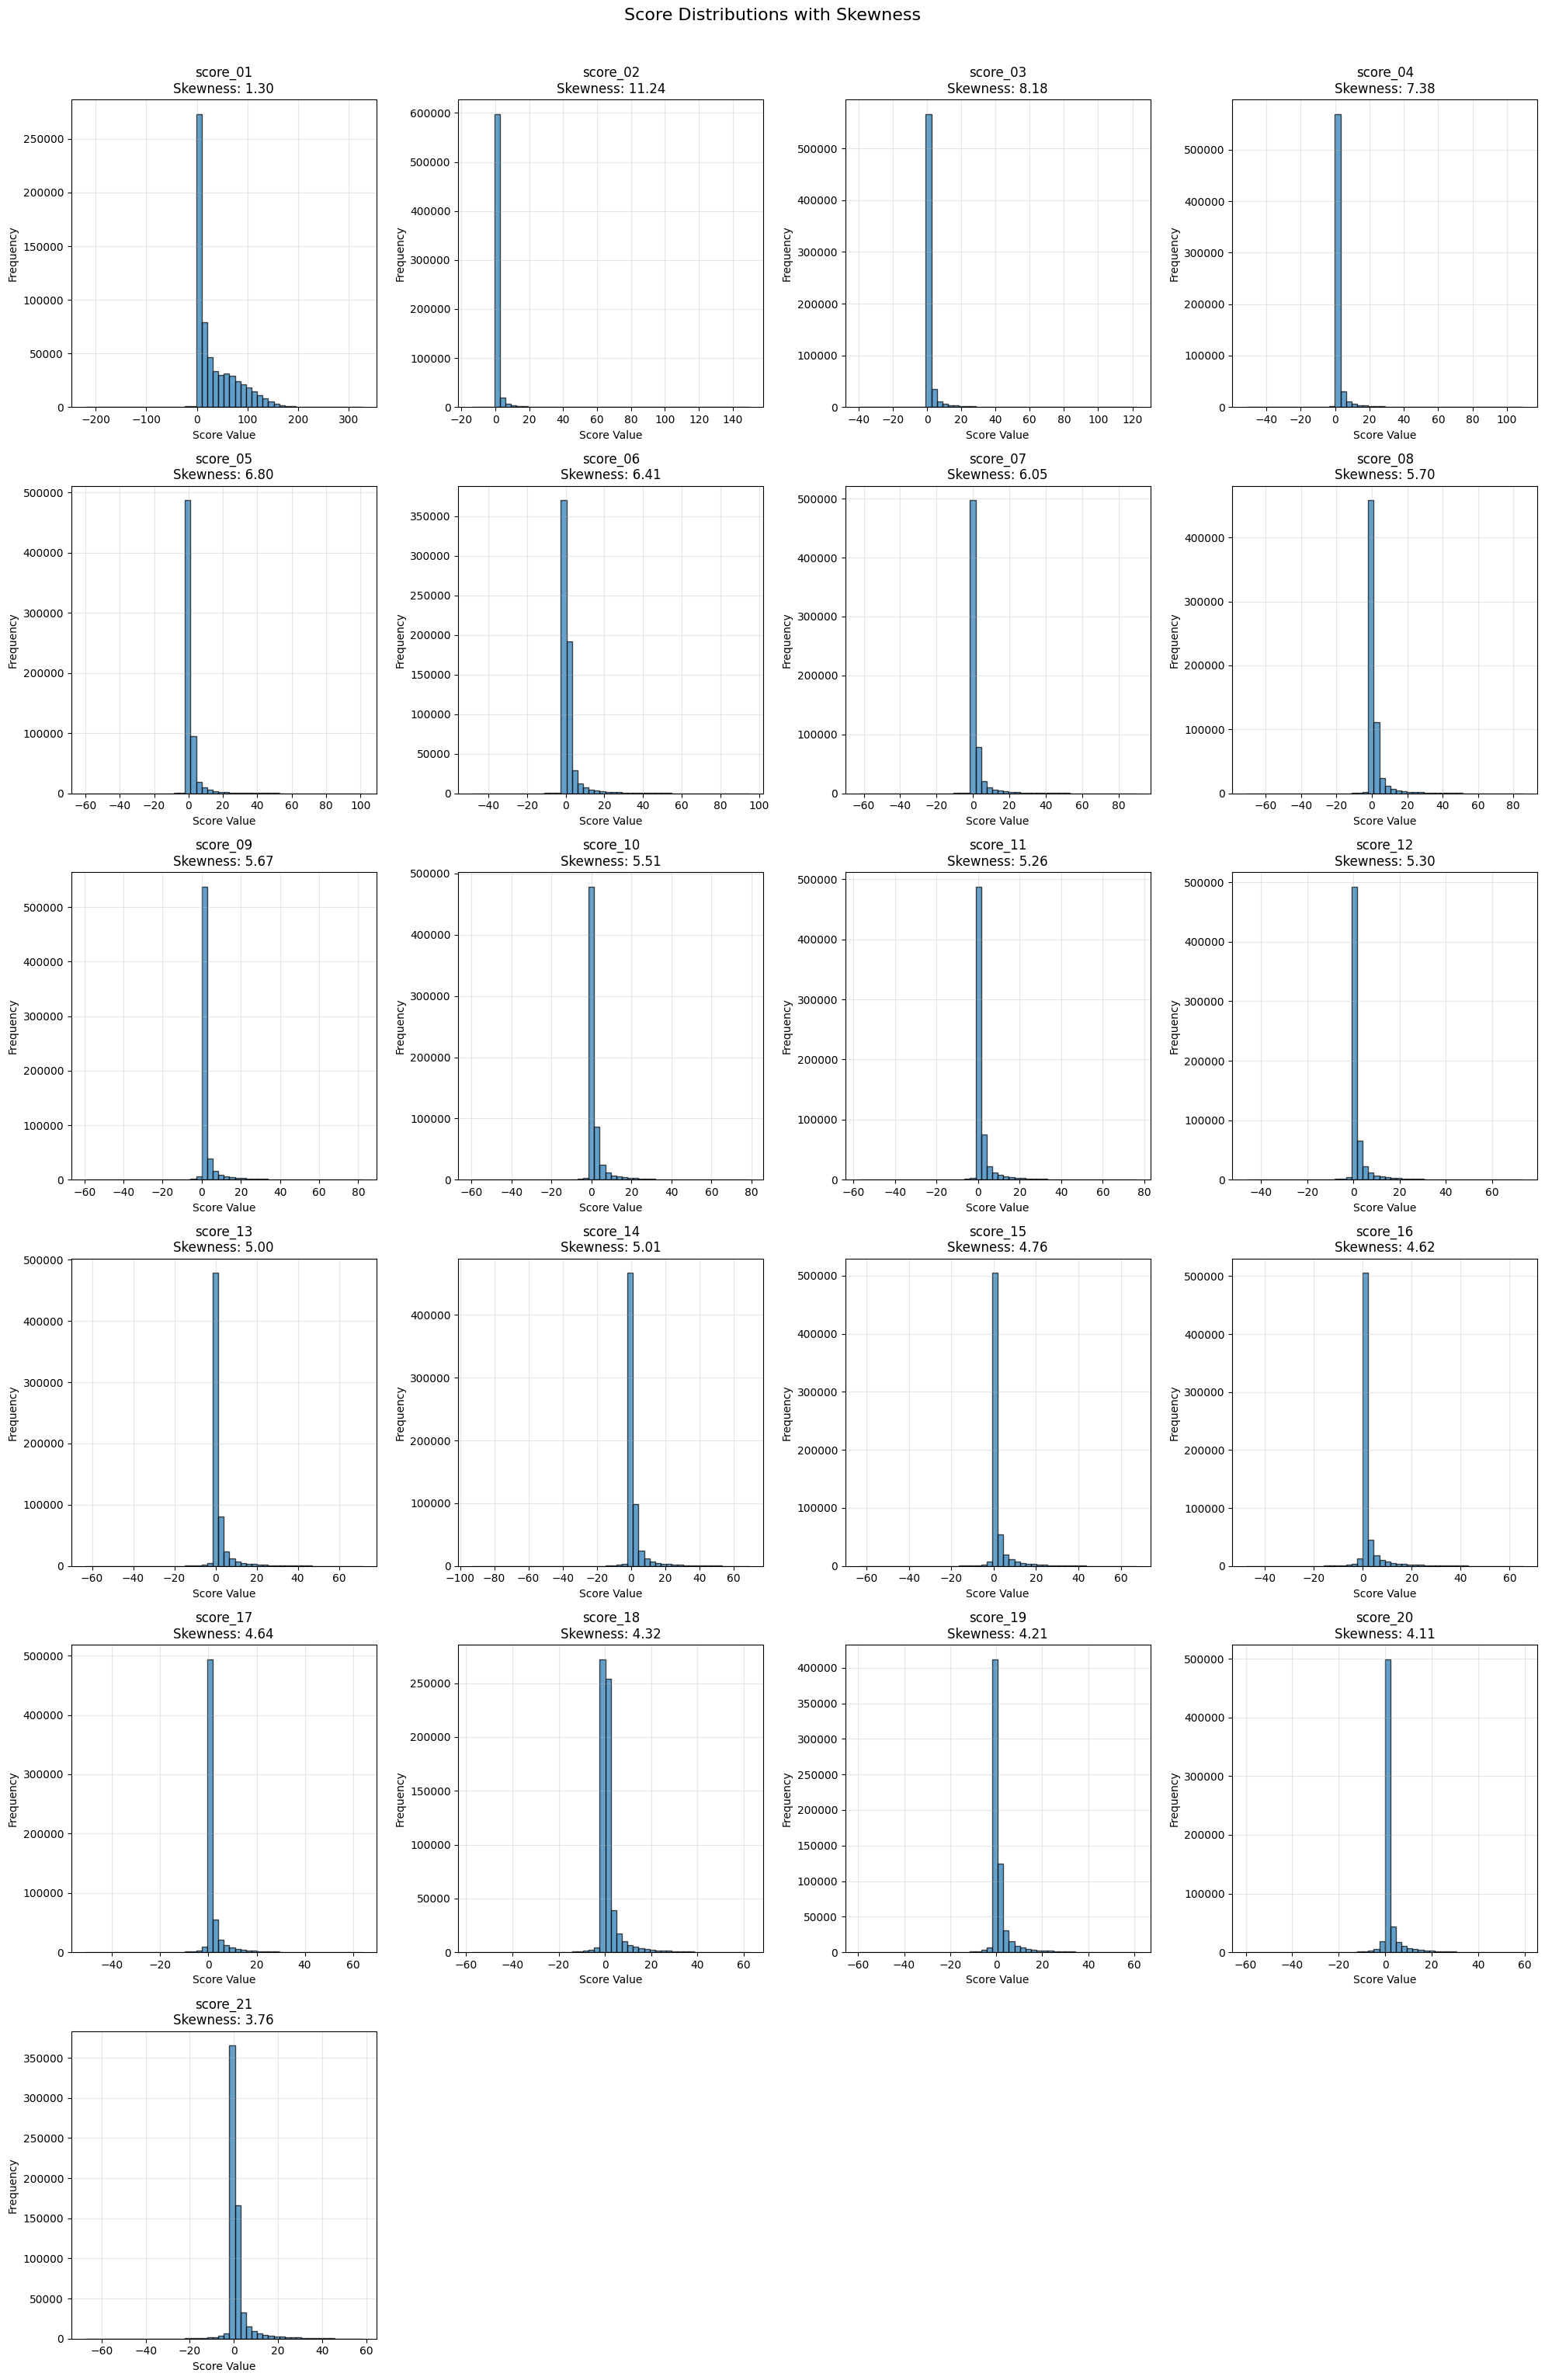

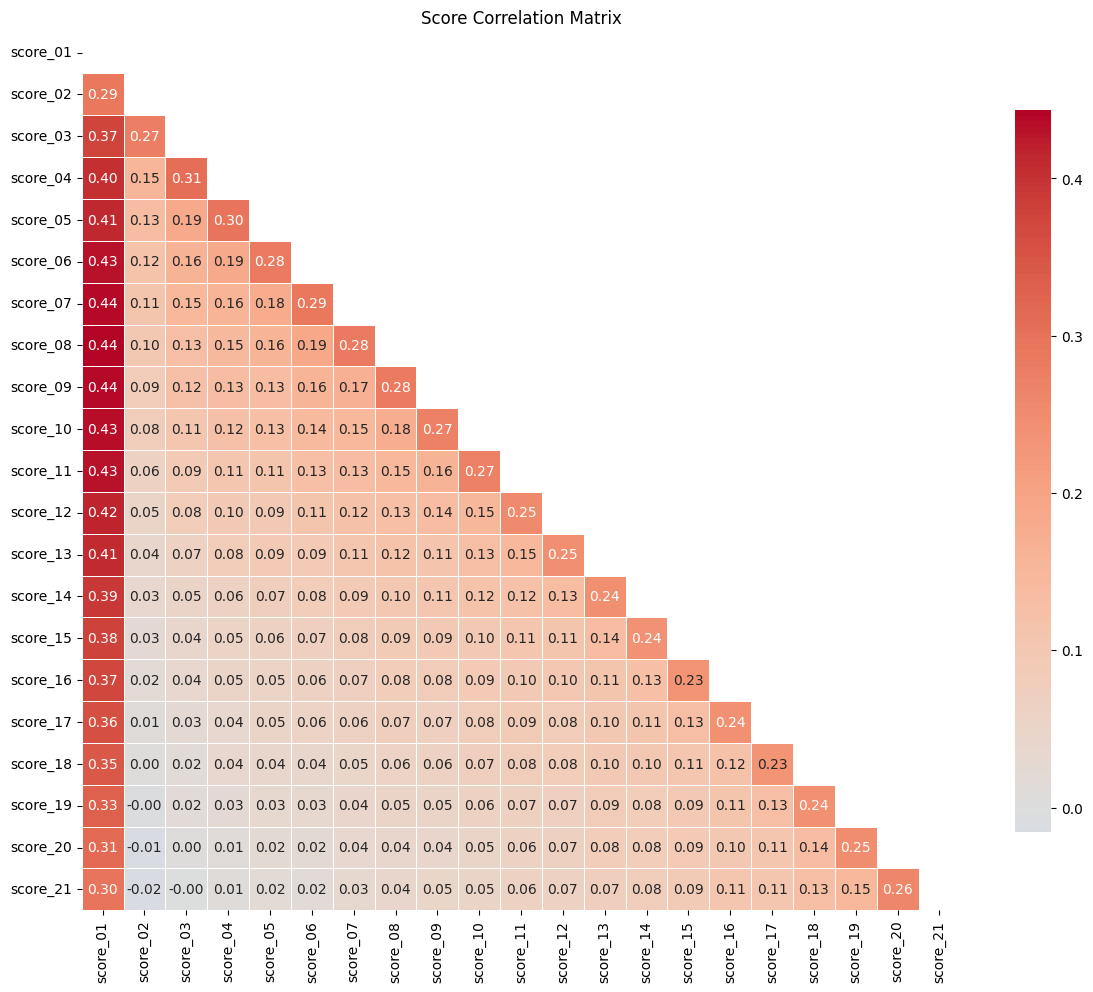


Strongest Positive Correlations
      Score1    Score2  Correlation
6   score_01  score_08     0.443390
5   score_01  score_07     0.437905
7   score_01  score_09     0.436983
8   score_01  score_10     0.434259
9   score_01  score_11     0.430832
4   score_01  score_06     0.429465
10  score_01  score_12     0.415970
3   score_01  score_05     0.413532
11  score_01  score_13     0.408244
2   score_01  score_04     0.403788

Strongest Negative Correlations 
      Score1    Score2  Correlation
38  score_02  score_21    -0.015356
37  score_02  score_20    -0.014212
36  score_02  score_19    -0.003770
56  score_03  score_21    -0.001192
55  score_03  score_20     0.004655
35  score_02  score_18     0.004980
73  score_04  score_21     0.009065
34  score_02  score_17     0.010901
72  score_04  score_20     0.013824
54  score_03  score_19     0.015408


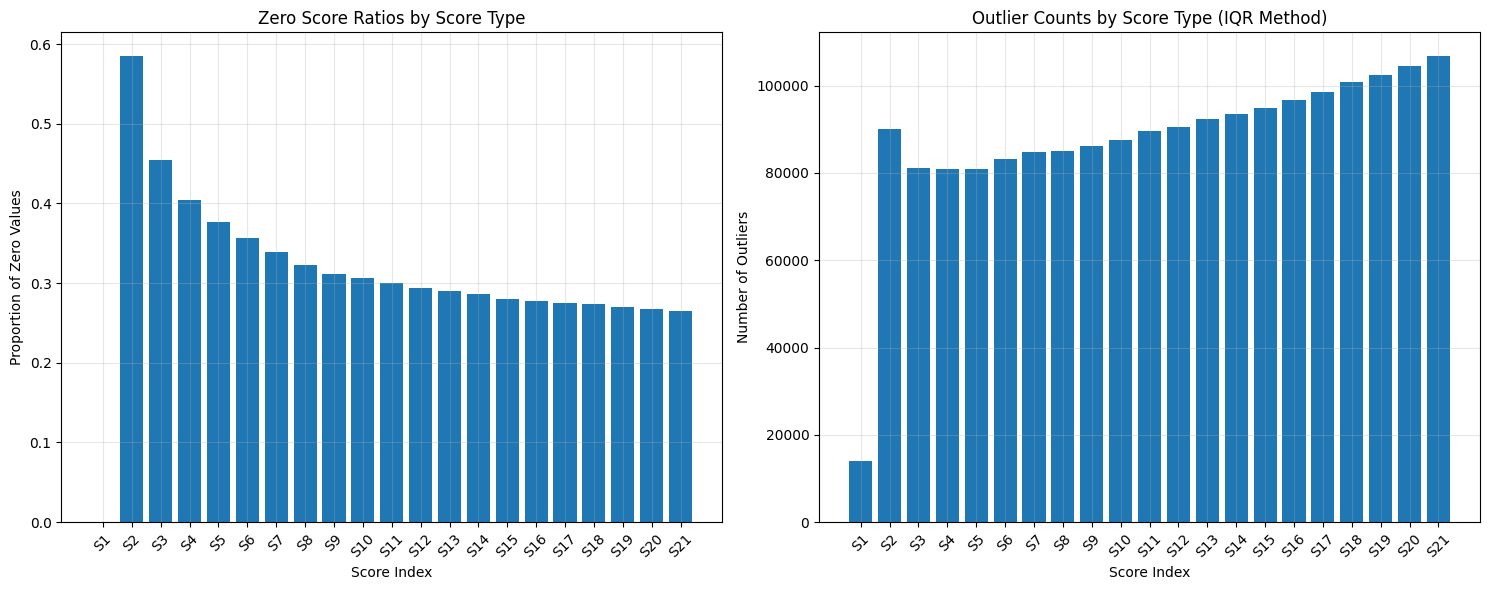

USER SEGMENTATION ANALYSIS

Profile Combination Analysis
Total unique users: 3,000
Unique profile combinations: 23,043
Profile diversity ratio: 7.681

Most Common Profile Patterns 
1. Pattern occurs 377237 times (59.4%)
2. Pattern occurs 38975 times (6.1%)
3. Pattern occurs 8920 times (1.4%)
4. Pattern occurs 7829 times (1.2%)
5. Pattern occurs 7588 times (1.2%)
6. Pattern occurs 6211 times (1.0%)
7. Pattern occurs 5037 times (0.8%)
8. Pattern occurs 3620 times (0.6%)
9. Pattern occurs 3411 times (0.5%)
10. Pattern occurs 3272 times (0.5%)

 Dominant Scores Analysis
Dominant Score Distribution:
  score_01: 2976 users (99.2%)
  score_02: 3 users (0.1%)
  score_20: 3 users (0.1%)
  score_15: 2 users (0.1%)
  score_05: 2 users (0.1%)
  score_19: 2 users (0.1%)
  score_21: 2 users (0.1%)
  score_10: 2 users (0.1%)
  score_11: 1 users (0.0%)
  score_03: 1 users (0.0%)

Average score diversity (std): 8.921
Average total score magnitude: 81.995

Extreme Profile Analysis
Top 5 users by maximum

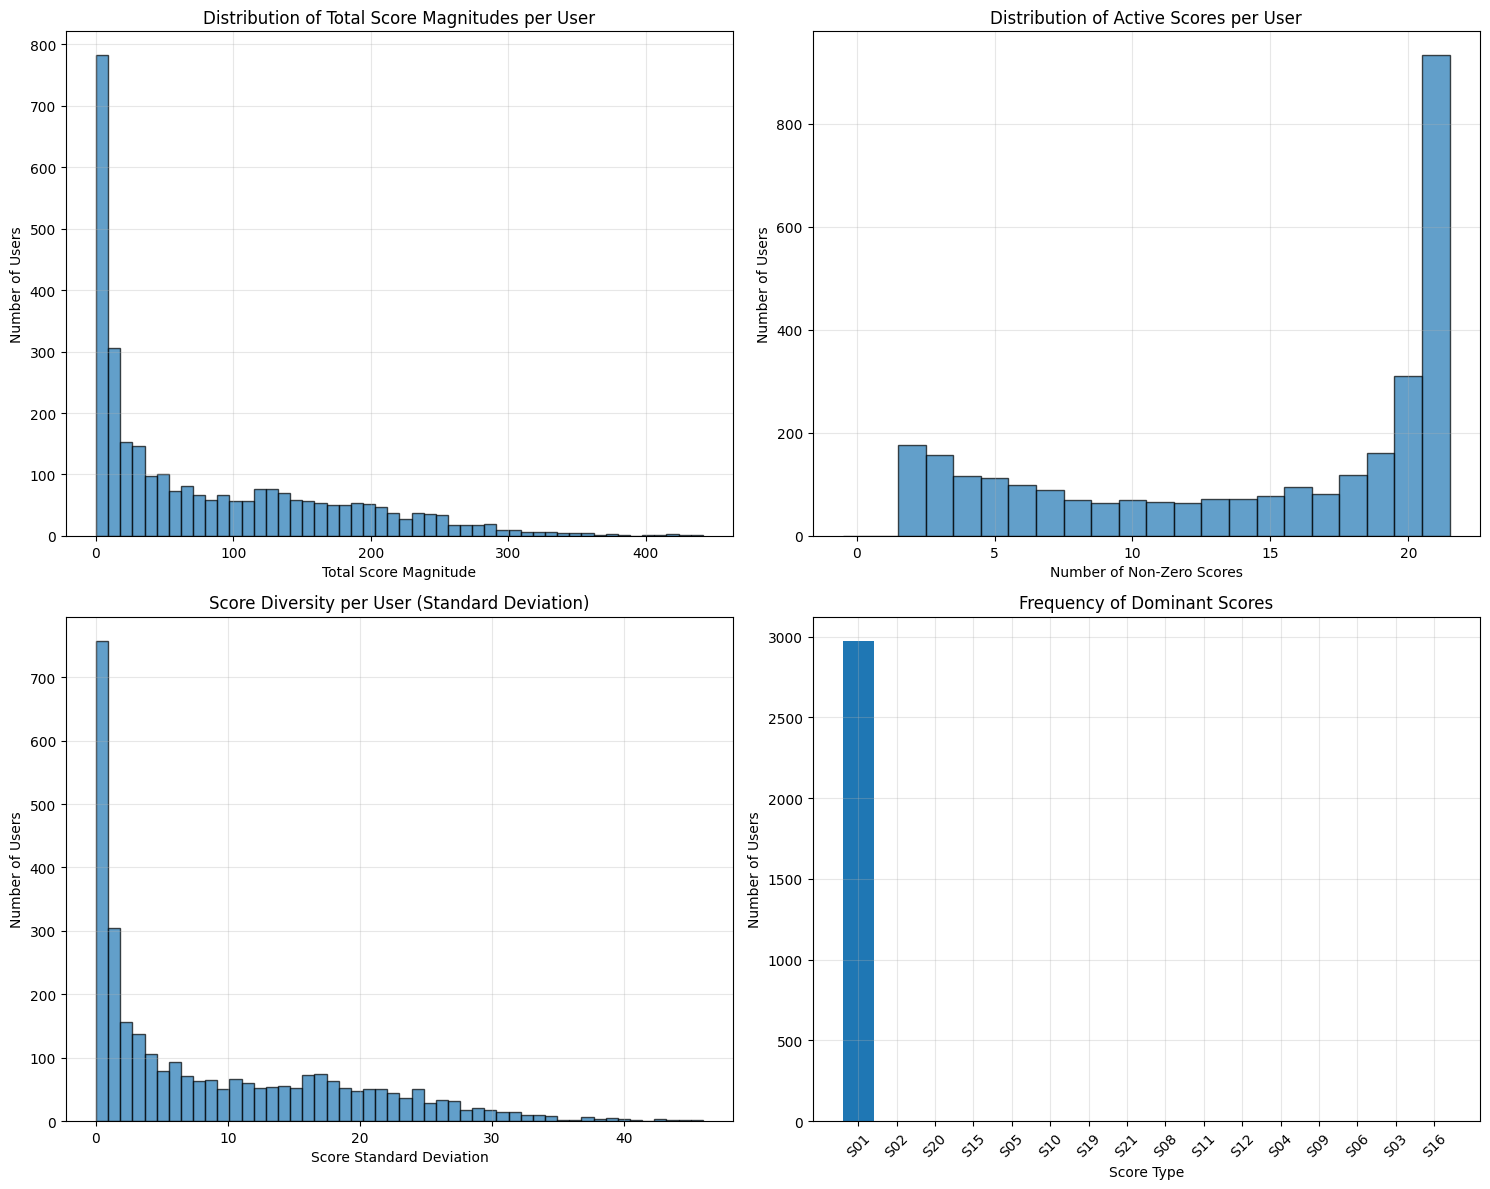

TEMPORAL CONSISTENCY ANALYSIS
Available months: ['2024-07', '2024-08', '2024-09']

 Profile Changes Between Months
Users with data in multiple months: 3000
Average total change: 104.097
Average max change: 42.116
Users with significant changes (>10): 83

Score Volatility Per User
Average user volatility: 5.668
Most volatile users (top 5):
                             user_id  avg_volatility
066f4c44-a3b3-4dc3-bb81-7062ae6afded       14.492470
066e490c-eb25-400d-804f-5b4b05b24ce9       13.429097
07e74307-beac-4c66-a936-2ad2d059e09f       12.724210
0175bbc9-1c8b-47c8-ac57-ea5452c3fbc4       12.650048
04225aa3-e8bf-4101-a67e-5f3ab898cd57       12.384980

User Retention Analysis
User Retention by Month:
  2024-07: 3000 total, 3000 new, 0 returning (0.0% retention)
  2024-08: 3000 total, 0 new, 3000 returning (100.0% retention)
  2024-09: 3000 total, 0 new, 3000 returning (100.0% retention)

 Seasonal Effects Analysis
Seasonal Score Trends (mean values):

score_01:
  2024-07: 32.303
  2024-

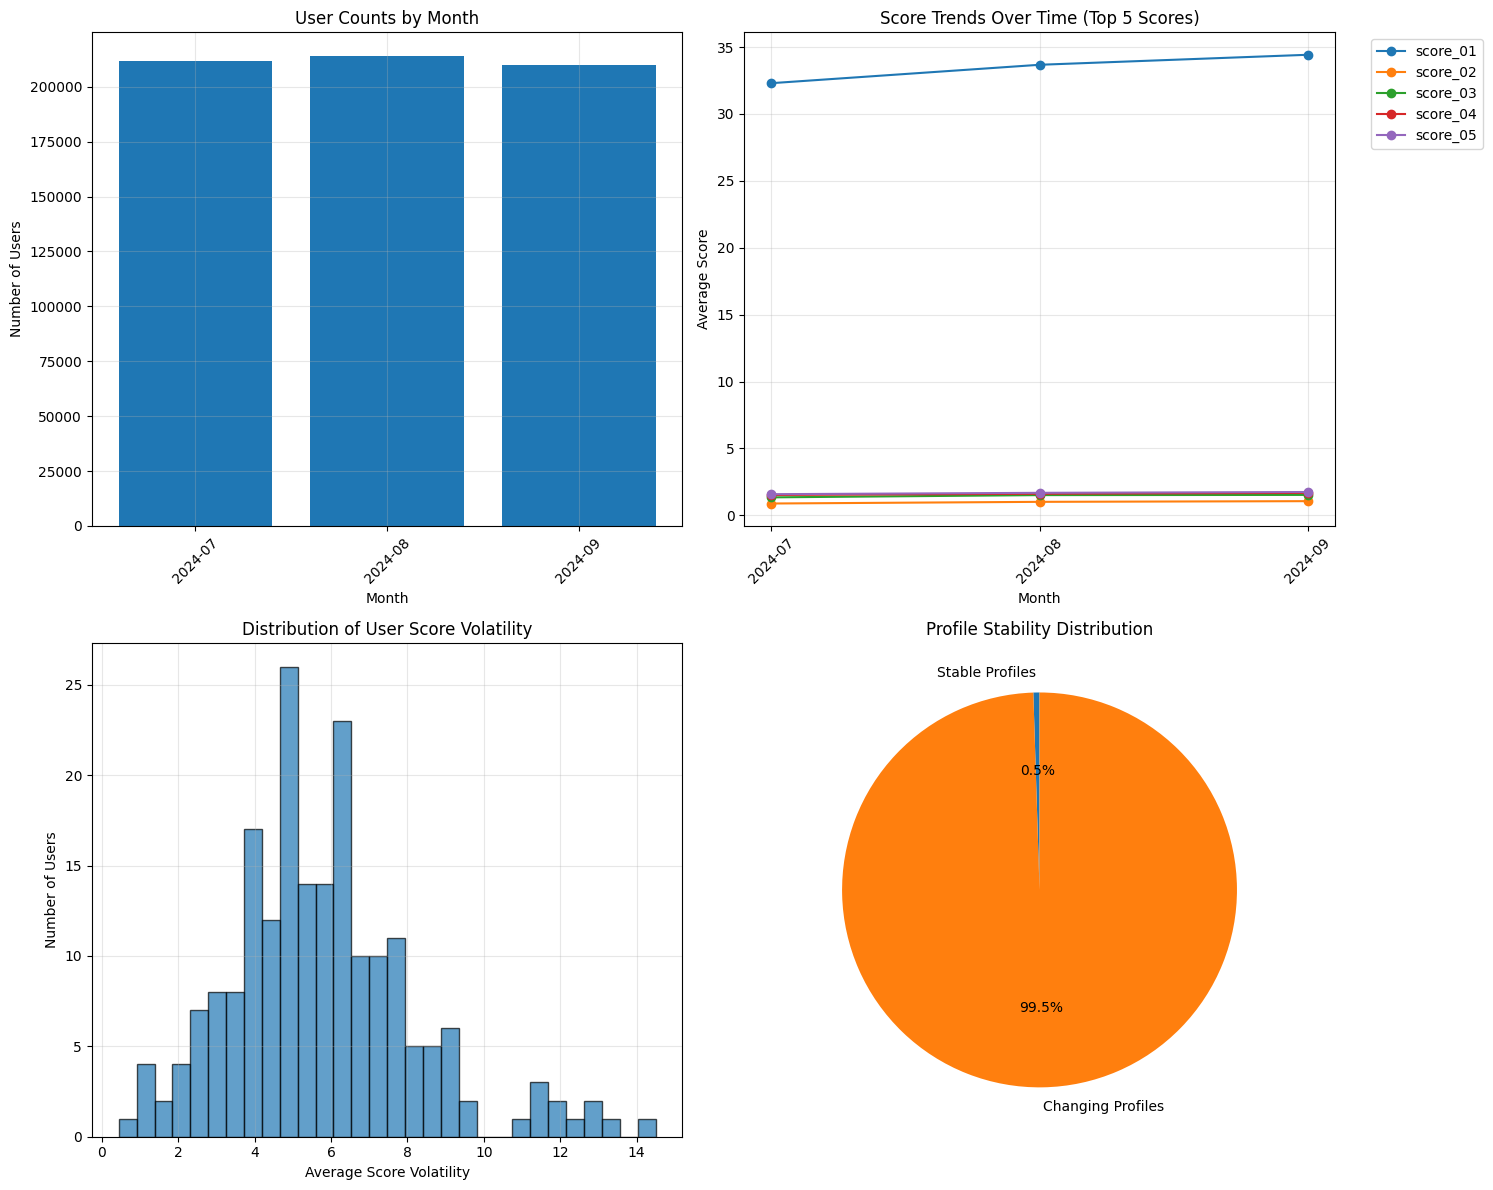


KEY INSIGHTS SUMMARY
\ SCORE CHARACTERISTICS:
   - 21 different score types analyzed

USER DIVERSITY:
   - Profile diversity ratio: 7.681

Profile analysis completed!


In [ ]:
#Profile Data Exploration
class ProfileScoreAnalyzer:
    def __init__(self, data_loader):
        self.data_loader = data_loader
        self.profiles_data = {}
        self.combined_profiles = None
        self.score_columns = None
        self.load_and_prepare_data()

    def load_and_prepare_data(self):
        self.profiles_data = self.data_loader.data.get('profiles', {})

        if not self.profiles_data:
            print("No profile data found!")
            return

        # Combine all profile datasets
        self.combined_profiles = self.data_loader.get_combined_data('profiles', include_source=True)

        if self.combined_profiles.empty:
            print("No combined profile data available!")
            return

        # Identify score columns
        self.score_columns = [col for col in self.combined_profiles.columns if col.startswith('score_')]

        print(f"Loaded {len(self.combined_profiles)} profile records")
        print(f"Found {len(self.score_columns)} score columns: {self.score_columns}")
        print(f"Data covers {self.combined_profiles['_source_dataset'].nunique()} datasets")

        # Add month information
        self.combined_profiles['month'] = self.combined_profiles['_source_dataset'].str.extract(r'(\d{4}-\d{2})')

    def analyze_score_distributions(self):
        #Score Distributions - Statistical properties
        print("SCORE DISTRIBUTIONS ANALYSIS")

        if self.combined_profiles is None or self.combined_profiles.empty:
            print("No data available for analysis")
            return

        # Basic statistics for all scores
        score_stats = {}

        print("\nBasic Statistics for All Scores")
        stats_df = self.combined_profiles[self.score_columns].describe()
        print(stats_df.round(4))

        # Calculate additional statistics
        print("\nAdvanced Statistics")
        advanced_stats = []

        for score_col in self.score_columns:
            data = self.combined_profiles[score_col].dropna()

            if len(data) > 0:
                stats_dict = {
                    'Score': score_col,
                    'Skewness': skew(data),
                    'Kurtosis': kurtosis(data),
                    'Zero_Ratio': (data == 0).mean(),
                    'Non_Zero_Count': (data != 0).sum(),
                    'Outliers_IQR': self._count_outliers_iqr(data),
                    'Outliers_Zscore': self._count_outliers_zscore(data)
                }
                advanced_stats.append(stats_dict)
                score_stats[score_col] = stats_dict

        advanced_df = pd.DataFrame(advanced_stats)
        print(advanced_df.round(4))

        # Visualizations
        self._plot_score_distributions()
        self._plot_correlation_matrix()
        self._plot_outlier_analysis()

        return score_stats

    def _count_outliers_iqr(self, data):
        #Count outliers using IQR method
        Q1 = data.quantile(0.25)
        Q3 = data.quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        return ((data < lower_bound) | (data > upper_bound)).sum()

    def _count_outliers_zscore(self, data, threshold=3):
        #Count outliers using Z-score metho
        z_scores = np.abs(stats.zscore(data))
        return (z_scores > threshold).sum()

    def _plot_score_distributions(self):
       #Plotting distribution histograms for all scores
        n_scores = len(self.score_columns)
        n_cols = 4
        n_rows = (n_scores + n_cols - 1) // n_cols

        fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5*n_rows))
        axes = axes.flatten() if n_rows > 1 else [axes] if n_scores == 1 else axes

        for i, score_col in enumerate(self.score_columns):
            data = self.combined_profiles[score_col].dropna()

            if len(data) > 0:
                axes[i].hist(data, bins=50, alpha=0.7, edgecolor='black')
                axes[i].set_title(f'{score_col}\nSkewness: {skew(data):.2f}')
                axes[i].set_xlabel('Score Value')
                axes[i].set_ylabel('Frequency')
                axes[i].grid(True, alpha=0.3)

        # Hiding empty subplots
        for i in range(n_scores, len(axes)):
            axes[i].set_visible(False)

        plt.tight_layout()
        plt.suptitle('Score Distributions with Skewness', fontsize=16, y=1.02)
        plt.show()

    def _plot_correlation_matrix(self):
        #Plotting correlation matrix between scores
        score_data = self.combined_profiles[self.score_columns].fillna(0)
        correlation_matrix = score_data.corr()

        plt.figure(figsize=(12, 10))
        mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
        sns.heatmap(correlation_matrix, mask=mask, annot=True, cmap='coolwarm', center=0,
                   square=True, linewidths=0.5, cbar_kws={"shrink": .8}, fmt='.2f')
        plt.title('Score Correlation Matrix')
        plt.tight_layout()
        plt.show()

        # Print strongest correlations
        print("\nStrongest Positive Correlations")
        correlations = []
        for i in range(len(correlation_matrix.columns)):
            for j in range(i+1, len(correlation_matrix.columns)):
                corr_val = correlation_matrix.iloc[i, j]
                correlations.append({
                    'Score1': correlation_matrix.columns[i],
                    'Score2': correlation_matrix.columns[j],
                    'Correlation': corr_val
                })

        corr_df = pd.DataFrame(correlations)
        print(corr_df.nlargest(10, 'Correlation')[['Score1', 'Score2', 'Correlation']])

        print("\nStrongest Negative Correlations ")
        print(corr_df.nsmallest(10, 'Correlation')[['Score1', 'Score2', 'Correlation']])

    def _plot_outlier_analysis(self):
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

        # Zero vs Non-zero ratios
        zero_ratios = []
        for score_col in self.score_columns:
            data = self.combined_profiles[score_col].fillna(0)
            zero_ratio = (data == 0).mean()
            zero_ratios.append(zero_ratio)

        ax1.bar(range(len(self.score_columns)), zero_ratios)
        ax1.set_title('Zero Score Ratios by Score Type')
        ax1.set_xlabel('Score Index')
        ax1.set_ylabel('Proportion of Zero Values')
        ax1.set_xticks(range(len(self.score_columns)))
        ax1.set_xticklabels([f'S{i+1}' for i in range(len(self.score_columns))], rotation=45)
        ax1.grid(True, alpha=0.3)

        # Outlier counts
        outlier_counts = []
        for score_col in self.score_columns:
            data = self.combined_profiles[score_col].dropna()
            if len(data) > 0:
                outlier_count = self._count_outliers_iqr(data)
                outlier_counts.append(outlier_count)
            else:
                outlier_counts.append(0)

        ax2.bar(range(len(self.score_columns)), outlier_counts)
        ax2.set_title('Outlier Counts by Score Type (IQR Method)')
        ax2.set_xlabel('Score Index')
        ax2.set_ylabel('Number of Outliers')
        ax2.set_xticks(range(len(self.score_columns)))
        ax2.set_xticklabels([f'S{i+1}' for i in range(len(self.score_columns))], rotation=45)
        ax2.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

    def analyze_user_segmentation(self):
        #User Segmentation - Profile patterns
        print("USER SEGMENTATION ANALYSIS")

        if self.combined_profiles is None or self.combined_profiles.empty:
            print("No data available for analysis")
            return

        # Unique profile combinations
        print("\nProfile Combination Analysis")

        # Creating profile signatures (discretized scores)
        profile_signatures = self.combined_profiles[self.score_columns].fillna(0)

        # Discretize scores into categories
        for col in self.score_columns:
            profile_signatures[f'{col}_cat'] = pd.cut(profile_signatures[col],
                                                    bins=5, labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'])

        # Counting unique combinations
        categorical_cols = [f'{col}_cat' for col in self.score_columns]
        profile_combinations = profile_signatures[categorical_cols].astype(str).apply(
            lambda x: '|'.join(x), axis=1
        )

        unique_combinations = profile_combinations.nunique()
        total_users = len(self.combined_profiles['user_id'].unique())

        print(f"Total unique users: {total_users:,}")
        print(f"Unique profile combinations: {unique_combinations:,}")
        print(f"Profile diversity ratio: {unique_combinations/total_users:.3f}")

        # Most common profile patterns
        print("\nMost Common Profile Patterns ")
        top_patterns = profile_combinations.value_counts().head(10)
        for i, (pattern, count) in enumerate(top_patterns.items(), 1):
            print(f"{i}. Pattern occurs {count} times ({count/len(profile_combinations)*100:.1f}%)")

        # Dominant scores per user
        print("\n Dominant Scores Analysis")
        user_dominant_scores = self._analyze_dominant_scores()

        # Users with extreme profiles
        print("\nExtreme Profile Analysis")
        self._analyze_extreme_profiles()

        # Visualizations
        self._plot_user_segmentation()

        return {
            'unique_combinations': unique_combinations,
            'total_users': total_users,
            'dominant_scores': user_dominant_scores
        }

    def _analyze_dominant_scores(self):
        #Analyzing dominant scores per user
        user_dominant = []

        for user_id in self.combined_profiles['user_id'].unique():
            user_data = self.combined_profiles[self.combined_profiles['user_id'] == user_id]

            if len(user_data) > 0:
                # latest profile for this user
                latest_profile = user_data.iloc[-1]
                scores = latest_profile[self.score_columns].fillna(0)

                # Finding dominant score (highest absolute value)
                abs_scores = scores.abs()
                dominant_score = abs_scores.idxmax() if abs_scores.max() > 0 else None
                dominant_value = scores[dominant_score] if dominant_score else 0

                user_dominant.append({
                    'user_id': user_id,
                    'dominant_score': dominant_score,
                    'dominant_value': dominant_value,
                    'score_diversity': abs_scores.std(),
                    'total_score_magnitude': abs_scores.sum()
                })

        dominant_df = pd.DataFrame(user_dominant)

        if not dominant_df.empty:
            print("Dominant Score Distribution:")
            dominant_counts = dominant_df['dominant_score'].value_counts()
            for score, count in dominant_counts.head(10).items():
                print(f"  {score}: {count} users ({count/len(dominant_df)*100:.1f}%)")

            print(f"\nAverage score diversity (std): {dominant_df['score_diversity'].mean():.3f}")
            print(f"Average total score magnitude: {dominant_df['total_score_magnitude'].mean():.3f}")

        return dominant_df

    def _analyze_extreme_profiles(self):
        #Identifying users with extreme profiles
        extreme_users = []

        for user_id in self.combined_profiles['user_id'].unique():
            user_data = self.combined_profiles[self.combined_profiles['user_id'] == user_id]

            if len(user_data) > 0:
                latest_profile = user_data.iloc[-1]
                scores = latest_profile[self.score_columns].fillna(0)

                # Calculating extremeness metrics
                max_abs_score = scores.abs().max()
                score_range = scores.max() - scores.min()
                non_zero_scores = (scores != 0).sum()

                extreme_users.append({
                    'user_id': user_id,
                    'max_abs_score': max_abs_score,
                    'score_range': score_range,
                    'non_zero_scores': non_zero_scores,
                    'profile_intensity': scores.abs().mean()
                })

        extreme_df = pd.DataFrame(extreme_users)

        if not extreme_df.empty:
            # Top extreme users by different metrics
            print("Top 5 users by maximum absolute score:")
            top_max = extreme_df.nlargest(5, 'max_abs_score')[['user_id', 'max_abs_score']]
            print(top_max.to_string(index=False))

            print("\nTop 5 users by score range:")
            top_range = extreme_df.nlargest(5, 'score_range')[['user_id', 'score_range']]
            print(top_range.to_string(index=False))

            print("\nTop 5 users by profile intensity:")
            top_intensity = extreme_df.nlargest(5, 'profile_intensity')[['user_id', 'profile_intensity']]
            print(top_intensity.to_string(index=False))

    def _plot_user_segmentation(self):
        #Plotting user segmentation visualizations
        fig, axes = plt.subplots(2, 2, figsize=(15, 12))

        # Score magnitude distribution per user
        user_scores = self.combined_profiles.groupby('user_id')[self.score_columns].last().fillna(0)
        user_magnitudes = user_scores.abs().sum(axis=1)

        axes[0,0].hist(user_magnitudes, bins=50, alpha=0.7, edgecolor='black')
        axes[0,0].set_title('Distribution of Total Score Magnitudes per User')
        axes[0,0].set_xlabel('Total Score Magnitude')
        axes[0,0].set_ylabel('Number of Users')
        axes[0,0].grid(True, alpha=0.3)

        # Number of active scores per user
        active_scores = (user_scores != 0).sum(axis=1)

        axes[0,1].hist(active_scores, bins=range(0, len(self.score_columns)+2),
                      alpha=0.7, edgecolor='black', align='left')
        axes[0,1].set_title('Distribution of Active Scores per User')
        axes[0,1].set_xlabel('Number of Non-Zero Scores')
        axes[0,1].set_ylabel('Number of Users')
        axes[0,1].grid(True, alpha=0.3)

        # Score diversity (standard deviation) per user
        score_diversity = user_scores.std(axis=1)

        axes[1,0].hist(score_diversity, bins=50, alpha=0.7, edgecolor='black')
        axes[1,0].set_title('Score Diversity per User (Standard Deviation)')
        axes[1,0].set_xlabel('Score Standard Deviation')
        axes[1,0].set_ylabel('Number of Users')
        axes[1,0].grid(True, alpha=0.3)

        # Dominant score frequency
        dominant_scores = user_scores.abs().idxmax(axis=1)
        dominant_counts = dominant_scores.value_counts()

        axes[1,1].bar(range(len(dominant_counts)), dominant_counts.values)
        axes[1,1].set_title('Frequency of Dominant Scores')
        axes[1,1].set_xlabel('Score Type')
        axes[1,1].set_ylabel('Number of Users')
        axes[1,1].set_xticks(range(len(dominant_counts)))
        axes[1,1].set_xticklabels([s.replace('score_', 'S') for s in dominant_counts.index], rotation=45)
        axes[1,1].grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

    def analyze_temporal_consistency(self):
        #Temporal Consistency
        print("TEMPORAL CONSISTENCY ANALYSIS")

        if self.combined_profiles is None or self.combined_profiles.empty:
            print("No data available for analysis")
            return

        # Checking if we have multiple months
        available_months = self.combined_profiles['month'].unique()
        print(f"Available months: {sorted(available_months)}")

        if len(available_months) < 2:
            print("Insufficient temporal data for consistency analysis")
            return

        # Profile changes between months
        print("\n Profile Changes Between Months")
        temporal_analysis = self._analyze_profile_changes()

        # Score volatility per user
        print("\nScore Volatility Per User")
        volatility_analysis = self._analyze_score_volatility()

        # New vs returning users
        print("\nUser Retention Analysis")
        retention_analysis = self._analyze_user_retention()

        # Seasonal effects
        print("\n Seasonal Effects Analysis")
        seasonal_analysis = self._analyze_seasonal_effects()

        # Visualizations
        self._plot_temporal_analysis()

        return {
            'temporal_analysis': temporal_analysis,
            'volatility_analysis': volatility_analysis,
            'retention_analysis': retention_analysis,
            'seasonal_analysis': seasonal_analysis
        }

    def _analyze_profile_changes(self):
        #Analyzing how profiles change over time
        changes = []

        # Get users present in multiple months
        user_months = self.combined_profiles.groupby('user_id')['month'].nunique()
        multi_month_users = user_months[user_months > 1].index

        print(f"Users with data in multiple months: {len(multi_month_users)}")

        for user_id in multi_month_users[:100]:  # Limit for performance
            user_data = self.combined_profiles[self.combined_profiles['user_id'] == user_id].sort_values('month')

            if len(user_data) >= 2:
                # Compare first and last profiles
                first_profile = user_data.iloc[0][self.score_columns].fillna(0)
                last_profile = user_data.iloc[-1][self.score_columns].fillna(0)

                # Calculate changes
                score_changes = last_profile - first_profile
                total_change = score_changes.abs().sum()
                max_change = score_changes.abs().max()

                changes.append({
                    'user_id': user_id,
                    'first_month': user_data.iloc[0]['month'],
                    'last_month': user_data.iloc[-1]['month'],
                    'total_change': total_change,
                    'max_change': max_change,
                    'months_observed': len(user_data)
                })

        if changes:
            changes_df = pd.DataFrame(changes)
            print(f"Average total change: {changes_df['total_change'].mean():.3f}")
            print(f"Average max change: {changes_df['max_change'].mean():.3f}")
            print(f"Users with significant changes (>10): {(changes_df['total_change'] > 10).sum()}")

            return changes_df
        return pd.DataFrame()

    def _analyze_score_volatility(self):
        #Analyzing score volatility per user over time
        volatilities = []

        user_months = self.combined_profiles.groupby('user_id')['month'].nunique()
        multi_month_users = user_months[user_months > 1].index

        for user_id in multi_month_users[:100]:  # Limit for performance
            user_data = self.combined_profiles[self.combined_profiles['user_id'] == user_id].sort_values('month')

            if len(user_data) >= 2:
                # Calculating volatility for each score
                user_volatility = {}
                for score_col in self.score_columns:
                    scores = user_data[score_col].fillna(0)
                    if len(scores) > 1:
                        volatility = scores.std()
                        user_volatility[score_col] = volatility

                if user_volatility:
                    volatilities.append({
                        'user_id': user_id,
                        'avg_volatility': np.mean(list(user_volatility.values())),
                        'max_volatility': max(user_volatility.values()),
                        **user_volatility
                    })

        if volatilities:
            volatility_df = pd.DataFrame(volatilities)
            print(f"Average user volatility: {volatility_df['avg_volatility'].mean():.3f}")
            print(f"Most volatile users (top 5):")
            top_volatile = volatility_df.nlargest(5, 'avg_volatility')[['user_id', 'avg_volatility']]
            print(top_volatile.to_string(index=False))

            return volatility_df
        return pd.DataFrame()

    def _analyze_user_retention(self):
        monthly_users = {}

        for month in sorted(self.combined_profiles['month'].unique()):
            month_data = self.combined_profiles[self.combined_profiles['month'] == month]
            monthly_users[month] = set(month_data['user_id'].unique())

        months = sorted(monthly_users.keys())
        retention_stats = {}

        for i, month in enumerate(months):
            if i == 0:
                retention_stats[month] = {
                    'total_users': len(monthly_users[month]),
                    'new_users': len(monthly_users[month]),
                    'returning_users': 0,
                    'retention_rate': 0.0
                }
            else:
                prev_month = months[i-1]
                current_users = monthly_users[month]
                prev_users = monthly_users[prev_month]

                returning = len(current_users & prev_users)
                new = len(current_users - prev_users)
                retention_rate = returning / len(prev_users) if prev_users else 0

                retention_stats[month] = {
                    'total_users': len(current_users),
                    'new_users': new,
                    'returning_users': returning,
                    'retention_rate': retention_rate
                }

        print("User Retention by Month:")
        for month, stats in retention_stats.items():
            print(f"  {month}: {stats['total_users']} total, {stats['new_users']} new, "
                  f"{stats['returning_users']} returning ({stats['retention_rate']:.1%} retention)")

        return retention_stats

    def _analyze_seasonal_effects(self):
        monthly_stats = {}

        for month in sorted(self.combined_profiles['month'].unique()):
            month_data = self.combined_profiles[self.combined_profiles['month'] == month]

            month_stats = {}
            for score_col in self.score_columns:
                scores = month_data[score_col].fillna(0)
                month_stats[score_col] = {
                    'mean': scores.mean(),
                    'std': scores.std(),
                    'median': scores.median()
                }

            monthly_stats[month] = month_stats

        # Print seasonal trends
        print("Seasonal Score Trends (mean values):")
        for score_col in self.score_columns[:5]:  # Show first 5 scores
            print(f"\n{score_col}:")
            for month in sorted(monthly_stats.keys()):
                mean_val = monthly_stats[month][score_col]['mean']
                print(f"  {month}: {mean_val:.3f}")

        return monthly_stats

    def _plot_temporal_analysis(self):
        fig, axes = plt.subplots(2, 2, figsize=(15, 12))

        # User counts by month
        monthly_counts = self.combined_profiles['month'].value_counts().sort_index()

        axes[0,0].bar(range(len(monthly_counts)), monthly_counts.values)
        axes[0,0].set_title('User Counts by Month')
        axes[0,0].set_xlabel('Month')
        axes[0,0].set_ylabel('Number of Users')
        axes[0,0].set_xticks(range(len(monthly_counts)))
        axes[0,0].set_xticklabels(monthly_counts.index, rotation=45)
        axes[0,0].grid(True, alpha=0.3)

        # Average score trends (first 5 scores)
        months = sorted(self.combined_profiles['month'].unique())

        for i, score_col in enumerate(self.score_columns[:5]):
            monthly_means = []
            for month in months:
                month_data = self.combined_profiles[self.combined_profiles['month'] == month]
                mean_val = month_data[score_col].fillna(0).mean()
                monthly_means.append(mean_val)

            axes[0,1].plot(range(len(months)), monthly_means, marker='o', label=score_col)

        axes[0,1].set_title('Score Trends Over Time (Top 5 Scores)')
        axes[0,1].set_xlabel('Month')
        axes[0,1].set_ylabel('Average Score')
        axes[0,1].set_xticks(range(len(months)))
        axes[0,1].set_xticklabels(months, rotation=45)
        axes[0,1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        axes[0,1].grid(True, alpha=0.3)

        #Score volatility distribution
        user_months = self.combined_profiles.groupby('user_id')['month'].nunique()
        multi_month_users = user_months[user_months > 1].index

        volatilities = []
        for user_id in multi_month_users[:200]:  # Limit for performance
            user_data = self.combined_profiles[self.combined_profiles['user_id'] == user_id]
            user_scores = user_data[self.score_columns].fillna(0)
            if len(user_scores) > 1:
                volatility = user_scores.std(axis=0).mean()
                volatilities.append(volatility)

        if volatilities:
            axes[1,0].hist(volatilities, bins=30, alpha=0.7, edgecolor='black')
            axes[1,0].set_title('Distribution of User Score Volatility')
            axes[1,0].set_xlabel('Average Score Volatility')
            axes[1,0].set_ylabel('Number of Users')
            axes[1,0].grid(True, alpha=0.3)

        # Profile stability
        stable_users = 0
        changing_users = 0

        for user_id in multi_month_users[:200]:
            user_data = self.combined_profiles[self.combined_profiles['user_id'] == user_id]
            if len(user_data) >= 2:
                first_profile = user_data.iloc[0][self.score_columns].fillna(0)
                last_profile = user_data.iloc[-1][self.score_columns].fillna(0)
                total_change = (last_profile - first_profile).abs().sum()

                if total_change < 1:  # Threshold for stability
                    stable_users += 1
                else:
                    changing_users += 1

        if stable_users + changing_users > 0:
            axes[1,1].pie([stable_users, changing_users],
                         labels=['Stable Profiles', 'Changing Profiles'],
                         autopct='%1.1f%%', startangle=90)
            axes[1,1].set_title('Profile Stability Distribution')

        plt.tight_layout()
        plt.show()

    def generate_comprehensive_report(self):
        #analysis report
        print("PROFILE SCORE ANALYSIS REPORT")

        # Run all analyses
        score_stats = self.analyze_score_distributions()
        segmentation_results = self.analyze_user_segmentation()
        temporal_results = self.analyze_temporal_consistency()

        # Summary insights
        print("\nKEY INSIGHTS SUMMARY")

        if score_stats:
            print("\ SCORE CHARACTERISTICS:")
            print(f"   - {len(self.score_columns)} different score types analyzed")

        if segmentation_results:
            diversity_ratio = segmentation_results.get('unique_combinations', 0) / segmentation_results.get('total_users', 1)
            print(f"\nUSER DIVERSITY:")
            print(f"   - Profile diversity ratio: {diversity_ratio:.3f}")

# Usage
def run_profile_analysis(data_loader):
    analyzer = ProfileScoreAnalyzer(data_loader)
    analyzer.generate_comprehensive_report()
    return analyzer

# Executing the analysis
if 'data_loader' in globals():
    profile_analyzer = run_profile_analysis(data_loader)
    print("\nProfile analysis completed!")
else:
    print("Please ensure data_loader is available before running this analysis.")

 PARAMETRIC SCORES ANALYSIS
PARAMETRIC SCORES DATA EXPLORATION ANALYSIS

Processing loco_residents_2024_07
  - Parsed 373,939 records
  - Unique users: 373,939
  - Unique H3 locations: 64,672

Processing loco_residents_2024_08
  - Parsed 24,656 records
  - Unique users: 24,656
  - Unique H3 locations: 15,570

Processing loco_residents_2024_09
  - Parsed 159,576 records
  - Unique users: 159,576
  - Unique H3 locations: 35,581

Processing loco_workers_2_2024_07
  - Parsed 293,327 records
  - Unique users: 293,327
  - Unique H3 locations: 59,765

Processing loco_workers_2_2024_08
  - Parsed 122,811 records
  - Unique users: 122,811
  - Unique H3 locations: 41,182

Processing loco_workers_2_2024_09
  - Parsed 120,392 records
  - Unique users: 120,392
  - Unique H3 locations: 38,438

USER CLASSIFICATION DISTRIBUTION

Classification Distribution:
  classification    month  unique_users  unique_locations
0       resident  2024_07        373939             64672
1       resident  2024_08     

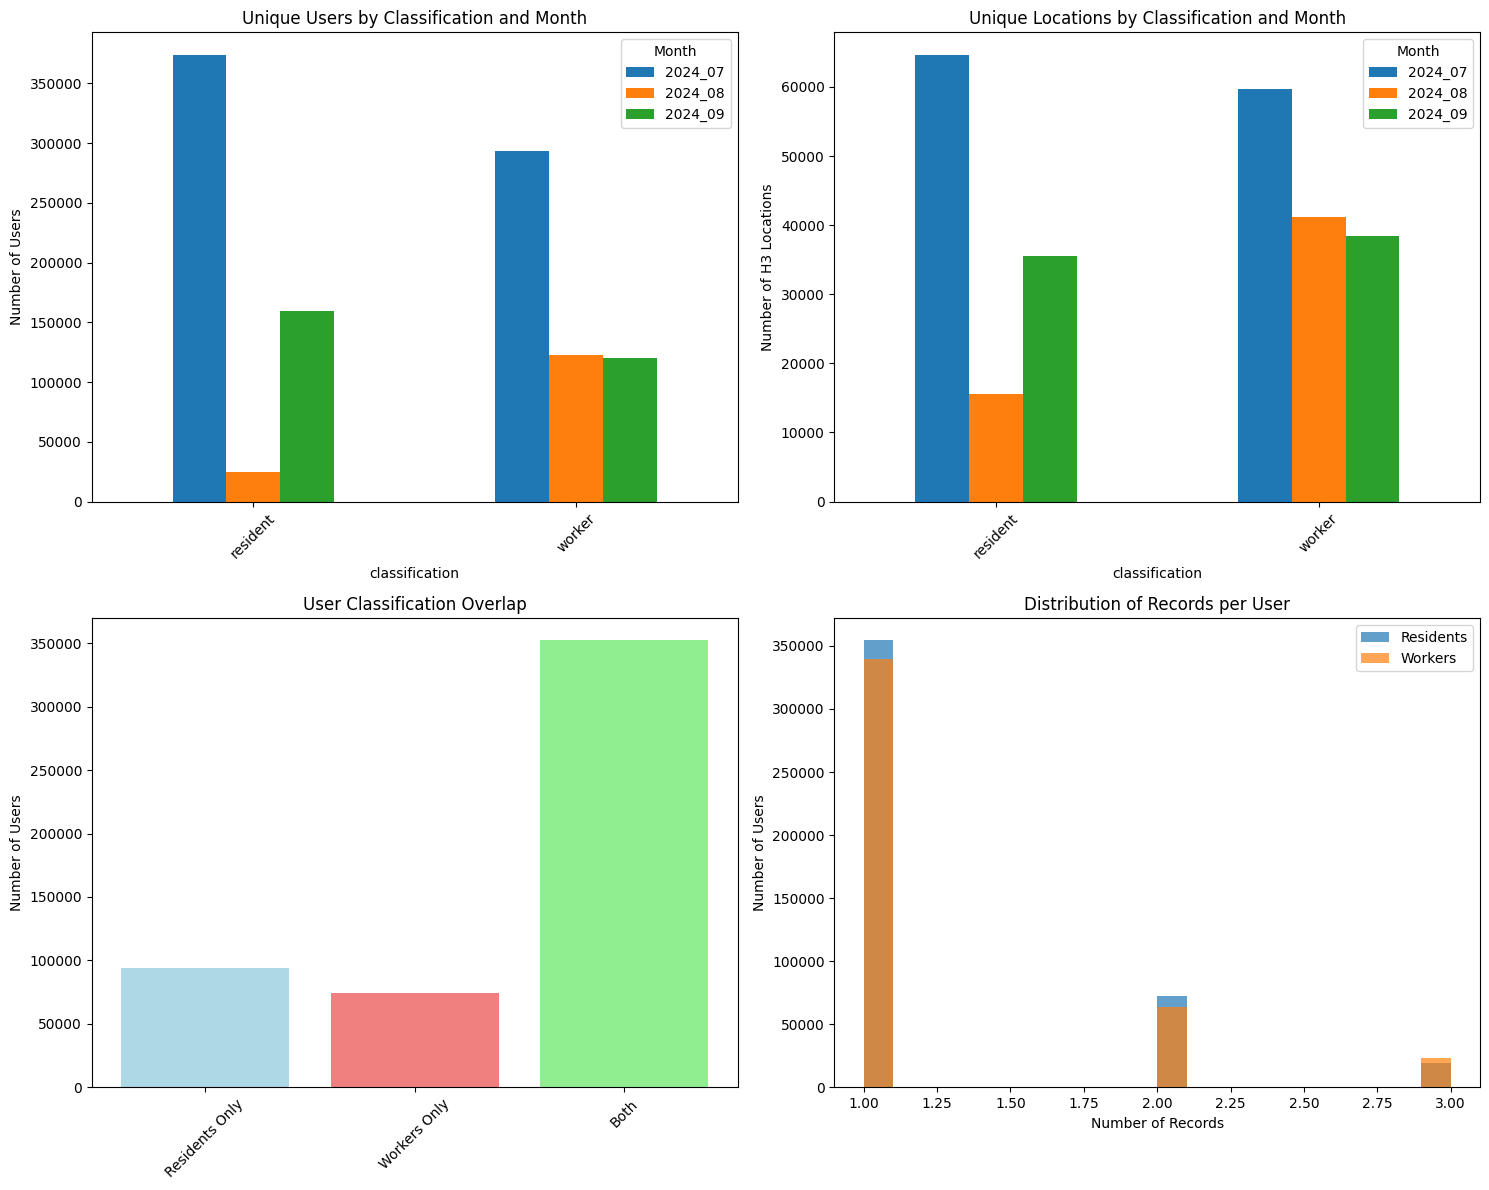

SPATIAL MAPPING ANALYSIS

Converting 106,505 unique H3 indices to coordinates
Successfully converted 0 H3 indices to coordinates

HOME/WORK DETECTION VALIDATION

Users in both signal and parametric data: 2,975

Validation Analysis for Sample Users:

User: b5571a08
  - Signal-inferred home locations: 3
  - Signal-inferred work locations: 3
  - Parametric resident locations: 1
  - Parametric worker locations: 1

User: 8b15f519
  - Signal-inferred home locations: 3
  - Signal-inferred work locations: 3
  - Parametric resident locations: 1
  - Parametric worker locations: 1

User: f8998688
  - Signal-inferred home locations: 3
  - Signal-inferred work locations: 3
  - Parametric resident locations: 1
  - Parametric worker locations: 1

User: a374f6c9
  - Signal-inferred home locations: 3
  - Signal-inferred work locations: 3
  - Parametric resident locations: 2
  - Parametric worker locations: 2

User: 46ac572b
  - Signal-inferred home locations: 3
  - Signal-inferred work locations: 3
  -

In [ ]:
#Parametric Score Data Exploration
class ParametricScoresAnalysis:
    def __init__(self, data_loader):
        self.data_loader = data_loader
        self.parsed_parametric = {}
        self.h3_coordinates = {}

    def parse_parametric_data(self):
        print("PARAMETRIC SCORES DATA EXPLORATION ANALYSIS\n")

        parametric_data = self.data_loader.data.get('parametric_scores', {})

        for dataset_name, df in parametric_data.items():
            print(f"Processing {dataset_name}")

            # Extract column name (which contains the tab-separated data)
            if len(df.columns) == 0:
                 print(f"  Skipping empty DataFrame for {dataset_name}")
                 continue
            col_name = df.columns[0]

            # Splitting the tab-separated values
            parsed_data = []
            for idx, row in df.iterrows():
                if pd.notna(row[col_name]):
                    parts = str(row[col_name]).split('\t')
                    if len(parts) >= 2:
                        user_id = parts[0]
                        h3_index = parts[1]
                        parsed_data.append({
                            'user_id': user_id,
                            'h3_index': h3_index,
                            'dataset': dataset_name
                        })

            if parsed_data:
                parsed_df = pd.DataFrame(parsed_data)
                self.parsed_parametric[dataset_name] = parsed_df
                print(f"  - Parsed {len(parsed_df):,} records")
                print(f"  - Unique users: {parsed_df['user_id'].nunique():,}")
                print(f"  - Unique H3 locations: {parsed_df['h3_index'].nunique():,}")
            else:
                print(f"  - No valid data found")
            print()

        return self.parsed_parametric

    def analyze_user_location_distribution(self):
      #Analyzing distribution of users across resident/worker classifications
        print("USER CLASSIFICATION DISTRIBUTION\n")

        # Combining all parsed data
        all_data = []
        for dataset_name, df in self.parsed_parametric.items():
            df_copy = df.copy()
            # Extract classification type and month
            if 'residents' in dataset_name:
                df_copy['classification'] = 'resident'
            elif 'workers' in dataset_name:
                df_copy['classification'] = 'worker'

            # Extract month
            month = dataset_name.split('_')[-1]
            df_copy['month'] = f"2024_{month}"
            all_data.append(df_copy)

        if not all_data:
            print("No parametric data available for analysis")
            return

        combined_df = pd.concat(all_data, ignore_index=True)

        # Classification distribution
        print("Classification Distribution:")
        class_dist = combined_df.groupby(['classification', 'month']).agg({
            'user_id': 'nunique',
            'h3_index': 'nunique'
        }).reset_index()
        class_dist.columns = ['classification', 'month', 'unique_users', 'unique_locations']
        print(class_dist)
        print()

        # Overlap analysis
        print("User Overlap Analysis:")
        residents = set(combined_df[combined_df['classification'] == 'resident']['user_id'].unique())
        workers = set(combined_df[combined_df['classification'] == 'worker']['user_id'].unique())

        overlap = residents.intersection(workers)
        resident_only = residents - workers
        worker_only = workers - residents

        print(f"  - Residents only: {len(resident_only):,}")
        print(f"  - Workers only: {len(worker_only):,}")
        print(f"  - Both resident and worker: {len(overlap):,}")
        print(f"  - Total unique users: {len(residents.union(workers)):,}")
        print()

        # Creating visualization
        fig, axes = plt.subplots(2, 2, figsize=(15, 12))

        # Plot 1: Users by classification and month
        class_summary = combined_df.groupby(['classification', 'month'])['user_id'].nunique().unstack(fill_value=0)
        class_summary.plot(kind='bar', ax=axes[0,0])
        axes[0,0].set_title('Unique Users by Classification and Month')
        axes[0,0].set_ylabel('Number of Users')
        axes[0,0].legend(title='Month')
        axes[0,0].tick_params(axis='x', rotation=45)

        # Plot 2: Locations by classification and month
        loc_summary = combined_df.groupby(['classification', 'month'])['h3_index'].nunique().unstack(fill_value=0)
        loc_summary.plot(kind='bar', ax=axes[0,1])
        axes[0,1].set_title('Unique Locations by Classification and Month')
        axes[0,1].set_ylabel('Number of H3 Locations')
        axes[0,1].legend(title='Month')
        axes[0,1].tick_params(axis='x', rotation=45)

        # Plot 3: User overlap Venn diagram (simplified as bar chart)
        overlap_data = {
            'Residents Only': len(resident_only),
            'Workers Only': len(worker_only),
            'Both': len(overlap)
        }
        axes[1,0].bar(overlap_data.keys(), overlap_data.values(),
                     color=['lightblue', 'lightcoral', 'lightgreen'])
        axes[1,0].set_title('User Classification Overlap')
        axes[1,0].set_ylabel('Number of Users')
        axes[1,0].tick_params(axis='x', rotation=45)

        # Plot 4: Records per user distribution
        user_counts = combined_df.groupby(['user_id', 'classification']).size().reset_index(name='record_count')
        for classification in user_counts['classification'].unique():
            subset = user_counts[user_counts['classification'] == classification]['record_count']
            axes[1,1].hist(subset, alpha=0.7, label=f'{classification.title()}s', bins=20)
        axes[1,1].set_title('Distribution of Records per User')
        axes[1,1].set_xlabel('Number of Records')
        axes[1,1].set_ylabel('Number of Users')
        axes[1,1].legend()

        plt.tight_layout()
        plt.show()

        return combined_df

    def convert_h3_to_coordinates(self, h3_indices):
        #Converting H3 indices to lat/lon coordinates
        coordinates = {}

        for h3_index in h3_indices:
            try:
                lat, lon = h3.h3_to_geo(h3_index)
                coordinates[h3_index] = {'lat': lat, 'lon': lon}
            except Exception as e:
                # Handle invalid H3 indices by skipping them
                # print(f"Warning: Could not convert H3 index {h3_index}: {e}") # Optional: uncomment for debugging
                pass

        return coordinates

    def spatial_mapping_analysis(self):
        #Performing comprehensive spatial mapping analysis
        print("SPATIAL MAPPING ANALYSIS\n")

        # Get all unique H3 indices from parametric data
        all_h3_indices = set()
        for df in self.parsed_parametric.values():
            if 'h3_index' in df.columns:
                all_h3_indices.update(df['h3_index'].unique())

        print(f"Converting {len(all_h3_indices):,} unique H3 indices to coordinates")

        # Convert H3 indices to coordinates
        self.h3_coordinates = self.convert_h3_to_coordinates(all_h3_indices)

        # Create coordinate dataframe
        coord_data = []
        for h3_index, coords in self.h3_coordinates.items():
            if coords['lat'] is not None:
                coord_data.append({
                    'h3_index': h3_index,
                    'latitude': coords['lat'],
                    'longitude': coords['lon']
                })

        coord_df = pd.DataFrame(coord_data)
        print(f"Successfully converted {len(coord_df):,} H3 indices to coordinates")
        print()

        if coord_df.empty:
            return coord_df

        # Analyzing spatial distribution
        self.analyze_spatial_distribution(coord_df)

        # Comparing with signal data coverage
        self.compare_with_signal_data(coord_df)

        return coord_df

    def analyze_spatial_distribution(self, coord_df):
        print("Spatial Distribution Analysis:")
        print(f"  - Latitude range: {coord_df['latitude'].min():.3f} to {coord_df['latitude'].max():.3f}")
        print(f"  - Longitude range: {coord_df['longitude'].min():.3f} to {coord_df['longitude'].max():.3f}")
        print(f"  - Geographic coverage: Finland (expected range)")
        print()

        # Create spatial distribution plots
        fig, axes = plt.subplots(2, 2, figsize=(15, 12))

        # Plot 1: Overall spatial distribution
        axes[0,0].scatter(coord_df['longitude'], coord_df['latitude'], alpha=0.6, s=1)
        axes[0,0].set_title('H3 Locations Distribution')
        axes[0,0].set_xlabel('Longitude')
        axes[0,0].set_ylabel('Latitude')

        # Plot 2: Latitude distribution
        axes[0,1].hist(coord_df['latitude'], bins=50, alpha=0.7, color='skyblue')
        axes[0,1].set_title('Latitude Distribution')
        axes[0,1].set_xlabel('Latitude')
        axes[0,1].set_ylabel('Frequency')

        # Plot 3: Longitude distribution
        axes[1,0].hist(coord_df['longitude'], bins=50, alpha=0.7, color='lightcoral')
        axes[1,0].set_title('Longitude Distribution')
        axes[1,0].set_xlabel('Longitude')
        axes[1,0].set_ylabel('Frequency')

        # Plot 4: Density heatmap
        axes[1,1].hist2d(coord_df['longitude'], coord_df['latitude'], bins=30, cmap='YlOrRd')
        axes[1,1].set_title('Location Density Heatmap')
        axes[1,1].set_xlabel('Longitude')
        axes[1,1].set_ylabel('Latitude')

        plt.tight_layout()
        plt.show()

    def compare_with_signal_data(self, coord_df):
      #Comparing parametric scores coverage with signal data
        print("Coverage Comparison with Signal Data:")

        # Getting signal data H3 indices
        signal_data = self.data_loader.data.get('user_signals', {})
        signal_h3_indices = set()

        for dataset_name, df in signal_data.items():
            if 'h3_index_1' in df.columns:
                signal_h3_indices.update(df['h3_index_1'].dropna().unique())
            if 'h3_index_2' in df.columns:
                signal_h3_indices.update(df['h3_index_2'].dropna().unique())

        parametric_h3_indices = set(coord_df['h3_index'].unique())

        print(f"  - Parametric scores H3 indices: {len(parametric_h3_indices):,}")
        print(f"  - Signal data H3 indices: {len(signal_h3_indices):,}")

        # Find overlap
        overlap = parametric_h3_indices.intersection(signal_h3_indices)
        parametric_only = parametric_h3_indices - signal_h3_indices
        signal_only = signal_h3_indices - parametric_h3_indices

        print(f"  - Overlapping H3 indices: {len(overlap):,}")
        print(f"  - Parametric only: {len(parametric_only):,}")
        print(f"  - Signal only: {len(signal_only):,}")

        if len(parametric_h3_indices) > 0:
            overlap_percentage = (len(overlap) / len(parametric_h3_indices)) * 100
            print(f"  - Overlap percentage: {overlap_percentage:.1f}%")
        print()

        # Visualize coverage comparison
        plt.figure(figsize=(12, 5))

        plt.subplot(1, 2, 1)
        coverage_data = {
            'Parametric Only': len(parametric_only),
            'Signal Only': len(signal_only),
            'Both': len(overlap)
        }
        plt.bar(coverage_data.keys(), coverage_data.values(),
               color=['lightblue', 'lightcoral', 'lightgreen'])
        plt.title('H3 Index Coverage Comparison')
        plt.ylabel('Number of H3 Indices')
        plt.xticks(rotation=45)

        plt.subplot(1, 2, 2)
        if len(overlap) > 0:
            # Convert overlapping H3 indices to coordinates for visualization
            overlap_coords = self.convert_h3_to_coordinates(list(overlap)[:1000])  # Limit for performance
            overlap_lats = [coords['lat'] for coords in overlap_coords.values() if coords['lat'] is not None]
            overlap_lons = [coords['lon'] for coords in overlap_coords.values() if coords['lon'] is not None]
            if overlap_lats and overlap_lons:
                plt.scatter(overlap_lons, overlap_lats, alpha=0.6, s=1, color='green')
                plt.title('Overlapping H3 Locations (Sample)')
                plt.xlabel('Longitude')
                plt.ylabel('Latitude')
            else:
                plt.text(0.5, 0.5, 'No valid overlapping H3 coordinates to plot',
                         horizontalalignment='center', verticalalignment='center', transform=plt.gca().transAxes)

        plt.tight_layout()
        plt.show()


    def validate_home_work_detection(self):
        print("HOME/WORK DETECTION VALIDATION\n")

        # Getting users that appear in both signal data and parametric scores
        signal_users = set()
        for df in self.data_loader.data.get('user_signals', {}).values():
            if 'user_id' in df.columns:
                signal_users.update(df['user_id'].dropna().unique())


        parametric_users = set()
        for df in self.parsed_parametric.values():
             if 'user_id' in df.columns:
                parametric_users.update(df['user_id'].dropna().unique())

        common_users = signal_users.intersection(parametric_users)
        print(f"Users in both signal and parametric data: {len(common_users):,}")

        if len(common_users) == 0:
            print("No common users found for validation")
            return

        # Sample some users for detailed analysis
        sample_users = list(common_users)[:10]

        print("\nValidation Analysis for Sample Users:")
        for user_id in sample_users:
            print(f"\nUser: {user_id[:8]}")

            # Get user's signal data
            user_signal_df = pd.DataFrame()
            user_signals_list = []
            for df in self.data_loader.data.get('user_signals', {}).values():
                if 'user_id' in df.columns:
                    user_data = df[df['user_id'] == user_id]
                    if len(user_data) > 0:
                        user_signals_list.append(user_data)
            if user_signals_list:
                user_signal_df = pd.concat(user_signals_list, ignore_index=True)

            if not user_signal_df.empty:
                # Analyzig temporal patterns (rough home/work detection)
                if 'hour' in user_signal_df.columns:
                    # Home hours: evening/night (18-8)
                    home_hours = user_signal_df[
                        (user_signal_df['hour'].astype(float) >= 18) | (user_signal_df['hour'].astype(float) <= 8)
                    ]
                    # Work hours: business hours (9-17)
                    work_hours = user_signal_df[
                        (user_signal_df['hour'].astype(float) >= 9) & (user_signal_df['hour'].astype(float) <= 17)
                    ]

                    if len(home_hours) > 0 and 'h3_index_1' in home_hours.columns:
                        signal_home_locations = home_hours['h3_index_1'].value_counts().head(3)
                        print(f"  - Signal-inferred home locations: {len(signal_home_locations)}")

                    if len(work_hours) > 0 and 'h3_index_1' in work_hours.columns:
                        signal_work_locations = work_hours['h3_index_1'].value_counts().head(3)
                        print(f"  - Signal-inferred work locations: {len(signal_work_locations)}")
            else:
                print("  - No signal data for this user.")


            # Get user's parametric classifications
            user_classifications = []
            for dataset_name, df in self.parsed_parametric.items():
                if 'user_id' in df.columns and 'h3_index' in df.columns:
                    user_data = df[df['user_id'] == user_id]
                    if len(user_data) > 0:
                        classification = 'resident' if 'residents' in dataset_name else 'worker'
                        user_classifications.extend([(classification, row['h3_index']) for _, row in user_data.iterrows()])

            if user_classifications:
                residents = [h3 for cls, h3 in user_classifications if cls == 'resident']
                workers = [h3 for cls, h3 in user_classifications if cls == 'worker']
                print(f"  - Parametric resident locations: {len(set(residents))}")
                print(f"  - Parametric worker locations: {len(set(workers))}")
            else:
                 print("  - No parametric data for this user.")


        return common_users


    def create_interactive_map(self, coord_df, sample_size=1000):
        #Creating interactive map showing resident vs worker locations
        print(f"\nINTERACTIVE MAP GENERATION")

        # Sample data for performance
        if len(coord_df) > sample_size:
            coord_sample = coord_df.sample(sample_size, random_state=42)
        else:
            coord_sample = coord_df

        if coord_sample.empty:
            print("No data to create interactive map.")
            return None

        print(f"Creating map with {len(coord_sample)} sample locations")

        # Create base map centered on Finland
        center_lat = coord_sample['latitude'].mean()
        center_lon = coord_sample['longitude'].mean()

        m = folium.Map(location=[center_lat, center_lon], zoom_start=6)

        # Adding location markers (sample for performance)
        for _, row in coord_sample.iterrows():
            folium.CircleMarker(
                location=[row['latitude'], row['longitude']],
                radius=1,
                popup=f"H3: {row['h3_index']}",
                color='blue',
                fillColor='blue',
                fillOpacity=0.6
            ).add_to(m)

        print("Interactive map created successfully")
        return m


    def run_complete_analysis(self):
        print(" PARAMETRIC SCORES ANALYSIS")

        # Step 1: Parse the data
        self.parse_parametric_data()

        # Step 2: Analyze user/location distribution
        combined_df = self.analyze_user_location_distribution()

        # Step 3: Spatial mapping
        coord_df = self.spatial_mapping_analysis()

        # Step 4: Validate home/work detection
        common_users = self.validate_home_work_detection()

        # Step 5: Create interactive map
        interactive_map = None
        if coord_df is not None and not coord_df.empty:
             interactive_map = self.create_interactive_map(coord_df)

        print("PARAMETRIC SCORES ANALYSIS COMPLETE")

        return {
            'parsed_data': self.parsed_parametric,
            'combined_analysis': combined_df if 'combined_df' in locals() else None,
            'coordinates': coord_df,
            'common_users': common_users if 'common_users' in locals() else None,
            'interactive_map': interactive_map if 'interactive_map' in locals() else None
        }

#Main function
def run_parametric_analysis(data_loader):
    analyzer = ParametricScoresAnalysis(data_loader)
    results = analyzer.run_complete_analysis()
    return analyzer, results

if 'data_loader' in globals():
    parametric_analyzer, analysis_results = run_parametric_analysis(data_loader)
else:
    print("Please ensure data_loader is available before running this analysis")

Loading datasets for cross-validatio
  user_signals: 3,301,643 records
    - 2,993 unique users
  profiles: 634,439 records
    - 3,000 unique users
  visitors: 1,414 records
  parametric_scores: 1,094,701 records
  pois: 720,368 records
CROSS-DATASET VALIDATION REPORT
USER CONSISTENCY VALIDATION

USER_SIGNALS:
  User ID column: user_id
  Unique users: 2,993

PROFILES:
  User ID column: user_id
  Unique users: 3,000

VISITORS:
  User ID column: e0824a7b-6b77-41cb-b9d6-a6f57c9026d6
  Unique users: 145

PARAMETRIC_SCORES: No user ID column found

POIS:
  User ID column: GEO_CONFIDENCE_CODE
  Unique users: 3

User Overlap Analysis
User Overlap Matrix:
             user_signals profiles visitors pois
user_signals         2993     2993      143    0
profiles             2993     3000      144    0
visitors              143      144      145    1
pois                    0        0        1    3

Overlap Percentages:
  user_signals ∩ profiles: 2,993 users
    - 100.0% of user_signals users
  

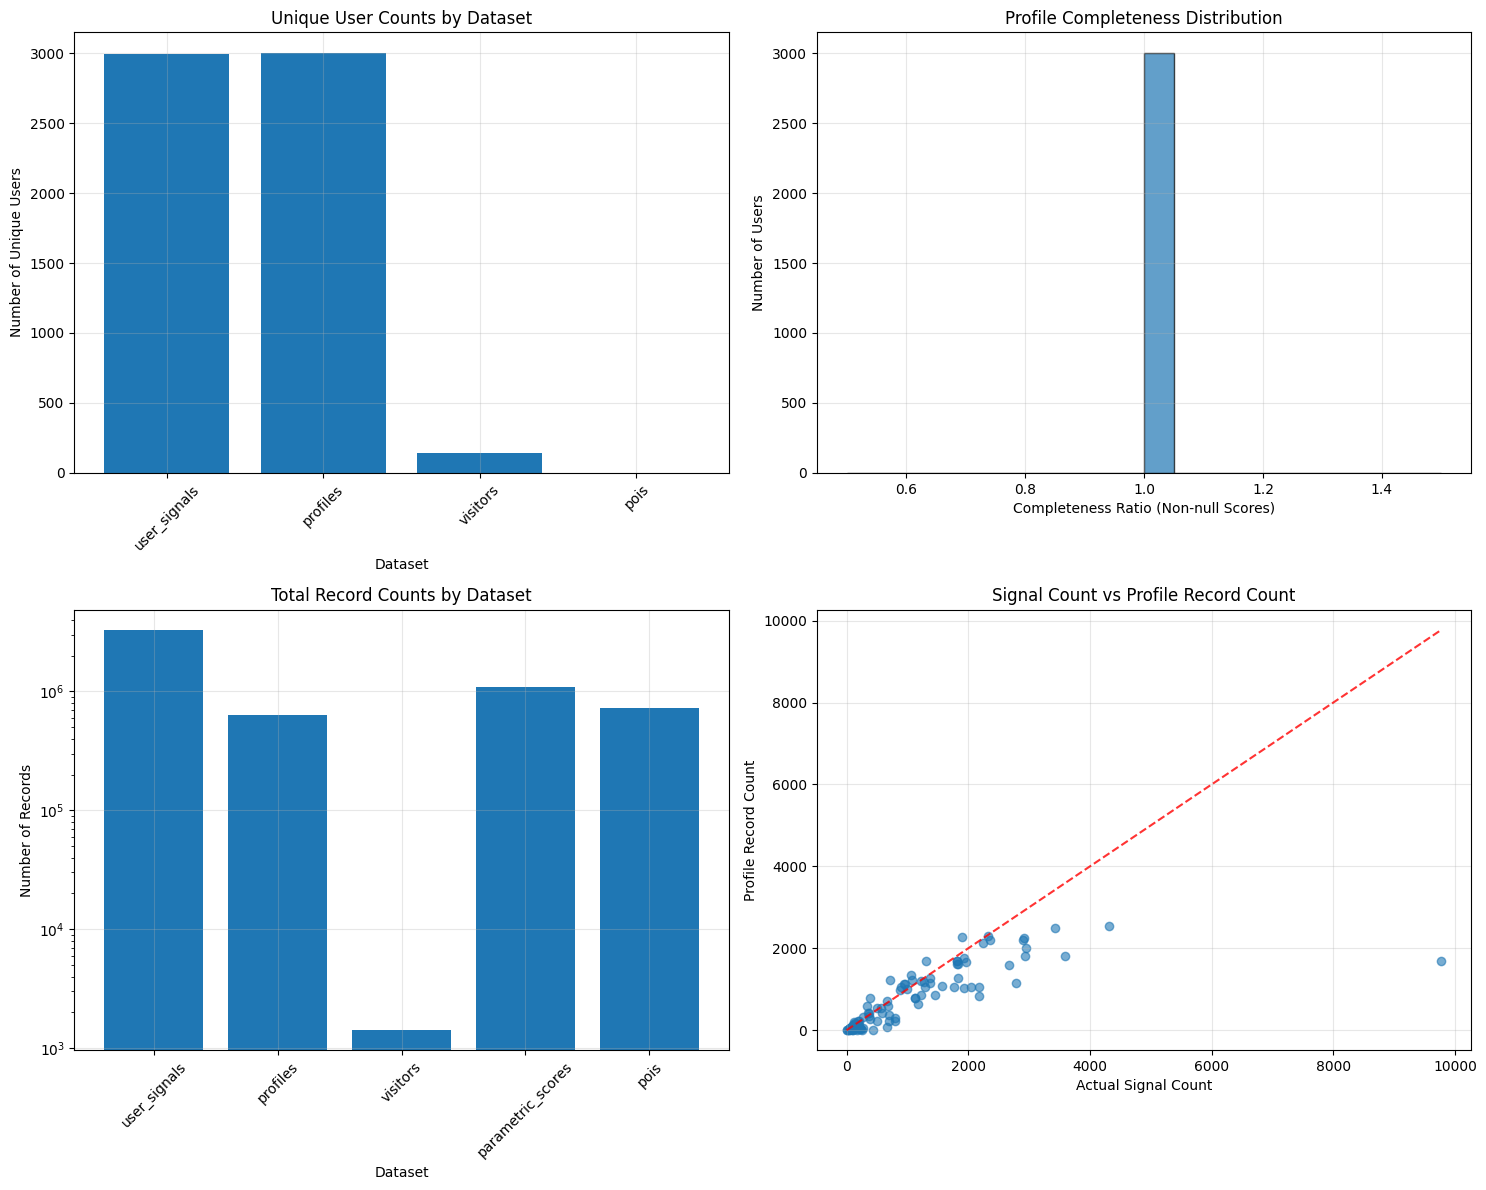

SPATIAL ALIGNMENT VALIDATION

Signal Locations vs Parametric Score H3 Cells
H3 columns in signals: ['h3_index_1', 'h3_index_2']
Unique H3 cells in signals: 470,157

 POI Coverage vs User Activity Areas 
Geographic Coverage Analysis:
  Signal coordinate range:
    Latitude: 57.809 to 70.041
    Longitude: 19.634 to 31.507
  POI coordinate range:
    Latitude: 59.780 to 70.089
    Longitude: 19.539 to 31.384
 Geographic overlap detected between signals and POIs
  Overlap coverage: 83.0% of signal area

 Visitor Data Location Validation 
Visitor data structure:
  Columns: ['e0824a7b-6b77-41cb-b9d6-a6f57c9026d6', '_source_dataset', '01e7307e-f5d4-495c-a40e-2dd939532b94', '6eb2b2ae-fd4f-40bb-b178-f9d5eb1556fa']
  Sample data:
   e0824a7b-6b77-41cb-b9d6-a6f57c9026d6 _source_dataset  \
0  279e7bb2-bee2-48d4-a9f5-bec90aeeb693         2024_07   
1  0cb94ef2-f029-41b9-a2b6-b7305fad7a26         2024_07   
2  c5a13d40-99f8-4500-86bb-5fbd2c3840e6         2024_07   

  01e7307e-f5d4-495c-a40e-2dd939

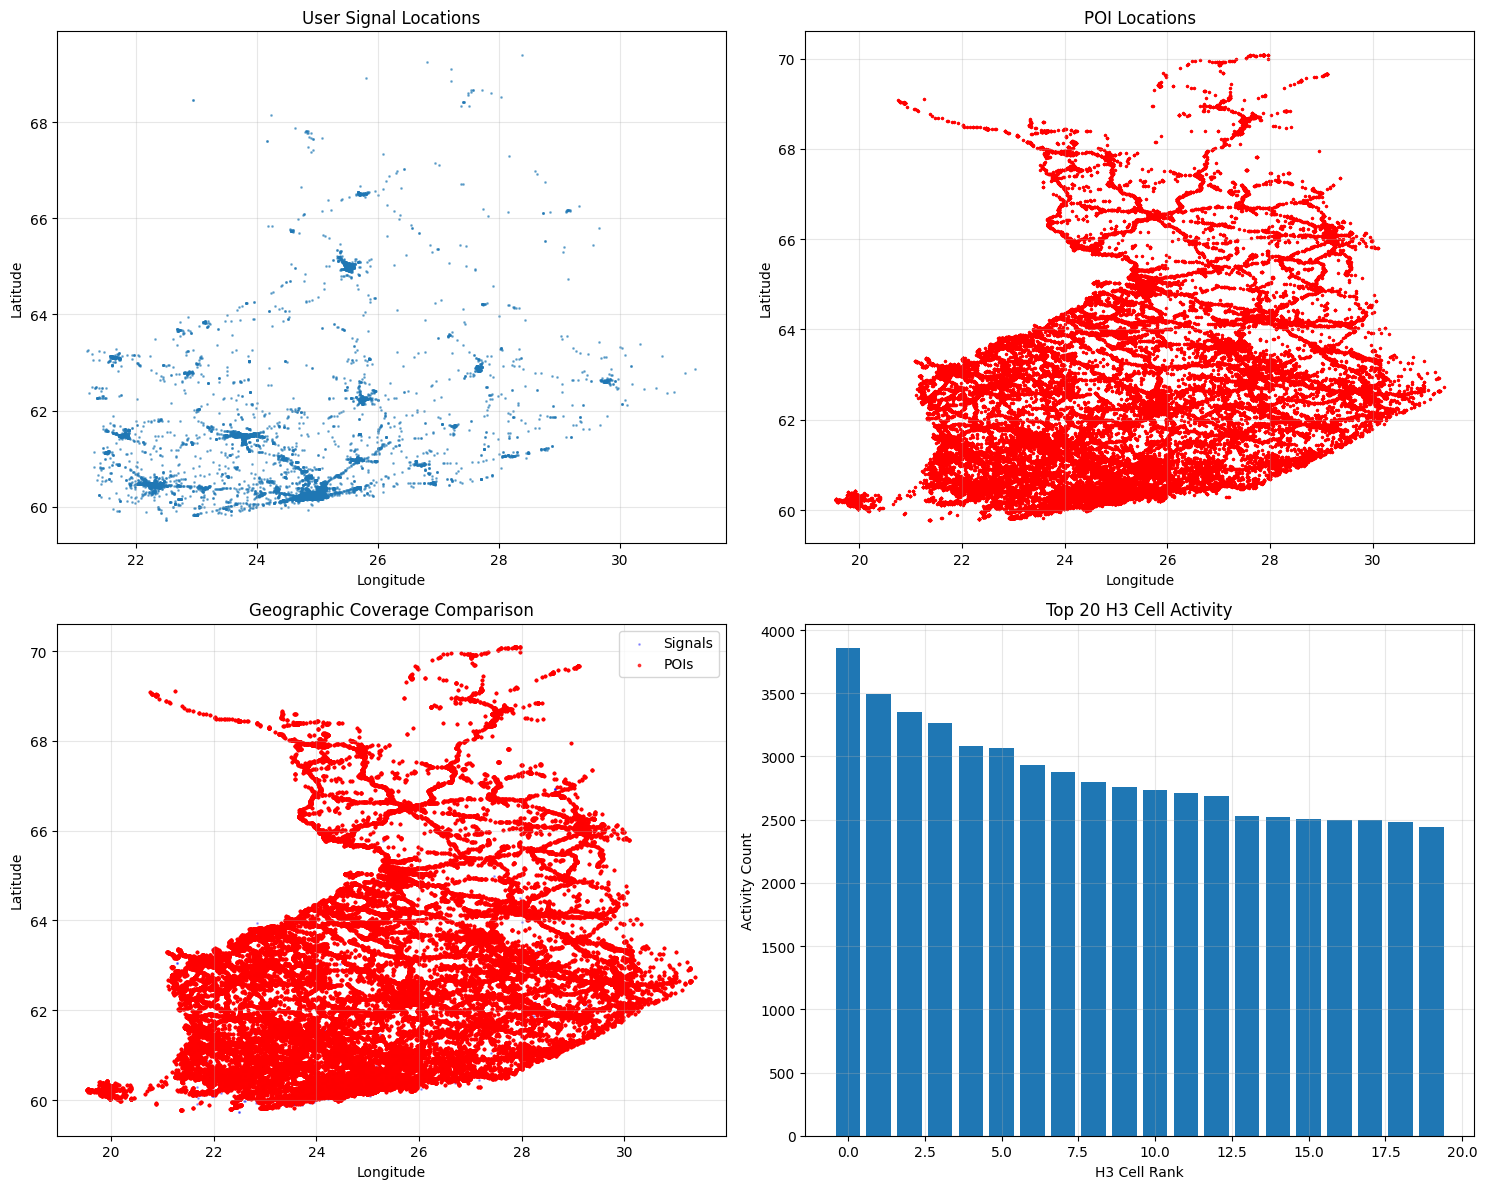

TEMPORAL ALIGNMENT VALIDATION

 Date Ranges Across Datasets

USER_SIGNALS:
  Date columns found: ['timestamp', 'date']
    timestamp: 2024-07-01 00:01:15 to 2024-09-15 20:59:19
      Duration: 76 days
    date: 2024-07-01 00:00:00 to 2024-07-15 00:00:00
      Duration: 14 days

PROFILES: No date columns found

VISITORS: No date columns found

PARAMETRIC_SCORES: No date columns found

POIS: No date columns found

 Monthly Data Completeness

USER_SIGNALS by source:
  2024_07_12: 167,579 records
  2024_07_11: 160,214 records
  2024_07_13: 159,133 records
  2024_07_10: 158,780 records
  2024_07_09: 158,627 records
  2024_07_08: 158,563 records
  2024_07_15: 157,233 records
  2024_07_05: 155,150 records
  2024_07_14: 154,706 records
  2024_07_07: 152,517 records
  2024_07_03: 149,828 records
  2024_07_01: 149,741 records
  2024_07_04: 148,802 records
  2024_07_02: 148,431 records
  2024_07_06: 148,397 records
  2024_08_02: 40,088 records
  2024_09_11: 39,284 records
  2024_08_01: 37,320 rec

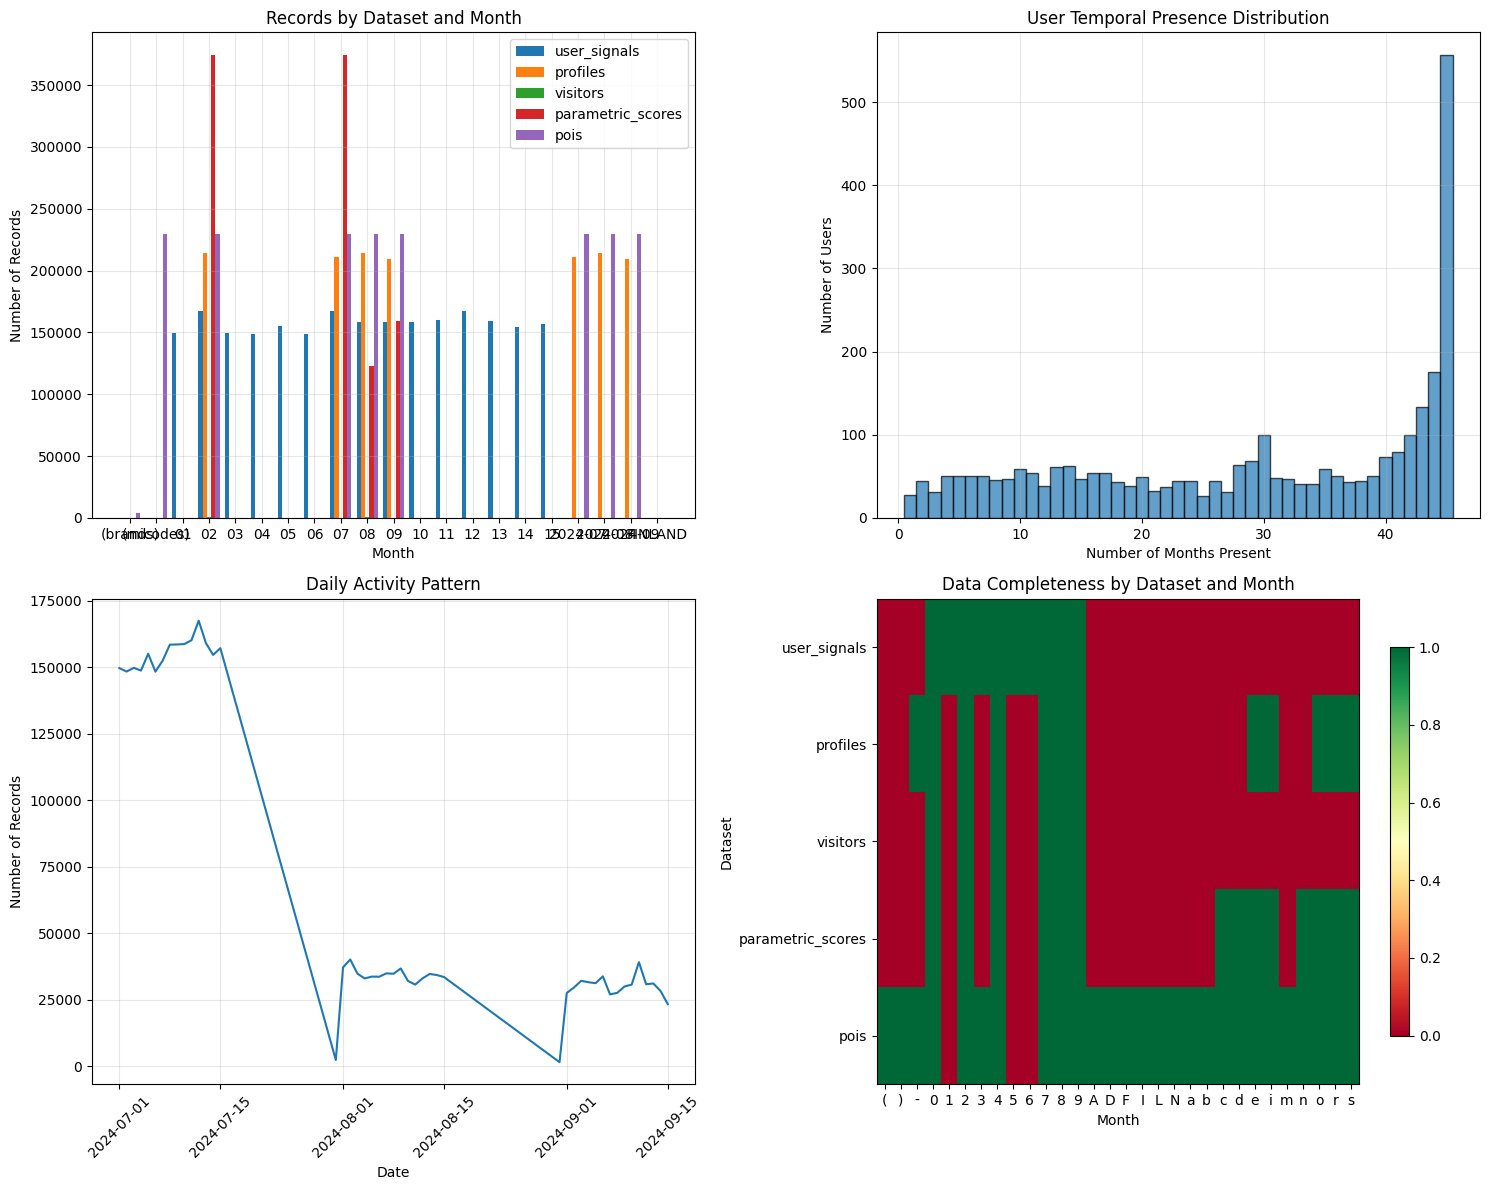

VALIDATION SUMMARY

USER CONSISTENCY:
   - 4 datasets contain user identifiers
   - 3,003 total unique users across all datasets
   - 0 users present in all datasets
   - Cross-dataset user coverage: 0.0%

Validation completed for 5 datasets

Cross-dataset validation completed!


In [ ]:
#Cross Data Validation
class CrossDatasetValidator:
   #Cross validation analysis across all datasets to ensure data consistency,spatial alignment, and temporal synchronizatio

    def __init__(self, data_loader):
        self.data_loader = data_loader
        self.datasets = {}
        self.validation_results = {}
        self.load_datasets()

    def load_datasets(self):
        print("Loading datasets for cross-validatio")

        # Load each dataset type
        self.datasets = {
            'user_signals': self.data_loader.get_combined_data('user_signals', include_source=True),
            'profiles': self.data_loader.get_combined_data('profiles', include_source=True),
            'visitors': self.data_loader.get_combined_data('visitors', include_source=True),
            'parametric_scores': self.data_loader.get_combined_data('parametric_scores', include_source=True),
            'pois': self.data_loader.get_combined_data('pois', include_source=True)
        }

        # Print dataset sizes
        for name, df in self.datasets.items():
            if not df.empty:
                print(f"  {name}: {len(df):,} records")
                if 'user_id' in df.columns:
                    unique_users = df['user_id'].nunique()
                    print(f"    - {unique_users:,} unique users")
            else:
                print(f"  {name}: No data available")

    def validate_user_consistency(self):
        print("USER CONSISTENCY VALIDATION")

        # Extracting user IDs from each dataset
        user_sets = {}

        for dataset_name, df in self.datasets.items():
            if df.empty:
                continue

            # Finding user ID column
            user_col = self._find_user_column(df)
            if user_col:
                users = set(df[user_col].astype(str).unique())
                user_sets[dataset_name] = users
                print(f"\n{dataset_name.upper()}:")
                print(f"  User ID column: {user_col}")
                print(f"  Unique users: {len(users):,}")
            else:
                print(f"\n{dataset_name.upper()}: No user ID column found")

        # Analyzing overlaps
        print("\nUser Overlap Analysis")
        self._analyze_user_overlaps(user_sets)

        # Profile completeness validation
        print("\nProfile Completeness Validation ")
        self._validate_profile_completeness()

        # Signal count vs profile record count validation
        print("\nSignal Count vs Profile Record Count Validation")
        self._validate_signal_profile_consistency()

        # Visualizations
        self._plot_user_consistency()

        return user_sets

    def _find_user_column(self, df):
        #Finding user ID column in dataframe
        user_patterns = ['user_id', 'user', 'id', 'uid', 'device_id', 'device', 'person_id']

        for col in df.columns:
            if col.lower() in user_patterns:
                return col

        # Partial matches
        for col in df.columns:
            col_lower = col.lower()
            for pattern in user_patterns:
                if pattern in col_lower and 'id' in col_lower:
                    return col

        # Checking if first column looks like user ID
        if len(df.columns) > 0:
            first_col = df.columns[0]
            sample_vals = df[first_col].dropna().head(10).astype(str)

            # Checking for UUID-like patterns
            uuid_like = sample_vals.str.contains(r'^[a-f0-9]{8}-[a-f0-9]{4}-[a-f0-9]{4}-[a-f0-9]{4}-[a-f0-9]{12}$', case=False)
            if uuid_like.any():
                return first_col

        return None

    def _analyze_user_overlaps(self, user_sets):
      #Analyzing overlaps between datasets
        if len(user_sets) < 2:
            print("Insufficient datasets with user IDs for overlap analysis")
            return

        # Calculating intersections
        overlap_matrix = pd.DataFrame(index=user_sets.keys(), columns=user_sets.keys())

        for dataset1 in user_sets:
            for dataset2 in user_sets:
                if dataset1 == dataset2:
                    overlap_matrix.loc[dataset1, dataset2] = len(user_sets[dataset1])
                else:
                    intersection = len(user_sets[dataset1] & user_sets[dataset2])
                    overlap_matrix.loc[dataset1, dataset2] = intersection

        print("User Overlap Matrix:")
        print(overlap_matrix)

        # Calculating overlap percentages
        print("\nOverlap Percentages:")
        for dataset1 in user_sets:
            for dataset2 in user_sets:
                if dataset1 != dataset2:
                    intersection = len(user_sets[dataset1] & user_sets[dataset2])
                    total_unique = len(user_sets[dataset1] | user_sets[dataset2])
                    jaccard = intersection / total_unique if total_unique > 0 else 0

                    pct1 = intersection / len(user_sets[dataset1]) * 100 if len(user_sets[dataset1]) > 0 else 0
                    pct2 = intersection / len(user_sets[dataset2]) * 100 if len(user_sets[dataset2]) > 0 else 0

                    print(f"  {dataset1} ∩ {dataset2}: {intersection:,} users")
                    print(f"    - {pct1:.1f}% of {dataset1} users")
                    print(f"    - {pct2:.1f}% of {dataset2} users")
                    print(f"    - Jaccard similarity: {jaccard:.3f}")

        # Finding users present in all datasets
        if len(user_sets) > 1:
            all_datasets_users = set.intersection(*user_sets.values())
            print(f"\nUsers present in ALL datasets: {len(all_datasets_users):,}")

            # Missing users by dataset
            print("\nMissing users by dataset:")
            for dataset_name, users in user_sets.items():
                missing_from_others = users - all_datasets_users
                print(f"  {dataset_name}: {len(missing_from_others):,} users not in other datasets")

    def _validate_profile_completeness(self):
        profiles = self.datasets.get('profiles')
        if profiles is None or profiles.empty:
            print("No profile data available for completeness validation")
            return

        user_col = self._find_user_column(profiles)
        if not user_col:
            print("No user column found in profiles")
            return

        # Analyzing completeness by user
        score_cols = [col for col in profiles.columns if col.startswith('score_')]

        user_completeness = []
        for user_id in profiles[user_col].unique():
            user_data = profiles[profiles[user_col] == user_id]

            if len(user_data) > 0:
                latest_profile = user_data.iloc[-1]

                total_scores = len(score_cols)
                non_null_scores = latest_profile[score_cols].notna().sum()
                non_zero_scores = (latest_profile[score_cols].fillna(0) != 0).sum()

                user_completeness.append({
                    'user_id': user_id,
                    'total_profiles': len(user_data),
                    'non_null_scores': non_null_scores,
                    'non_zero_scores': non_zero_scores,
                    'completeness_ratio': non_null_scores / total_scores,
                    'activity_ratio': non_zero_scores / total_scores
                })

        completeness_df = pd.DataFrame(user_completeness)

        if not completeness_df.empty:
            print(f"Profile completeness analysis for {len(completeness_df)} users:")
            print(f"  Average non-null scores: {completeness_df['non_null_scores'].mean():.1f}/{total_scores}")
            print(f"  Average non-zero scores: {completeness_df['non_zero_scores'].mean():.1f}/{total_scores}")
            print(f"  Average completeness ratio: {completeness_df['completeness_ratio'].mean():.3f}")
            print(f"  Average activity ratio: {completeness_df['activity_ratio'].mean():.3f}")

            # Users with incomplete profiles
            incomplete_users = completeness_df[completeness_df['completeness_ratio'] < 1.0]
            print(f"  Users with incomplete profiles: {len(incomplete_users)}")

            return completeness_df

    def _validate_signal_profile_consistency(self):
        #Validating consistency between signal counts and profile record counts
        signals = self.datasets.get('user_signals')
        profiles = self.datasets.get('profiles')

        if signals is None or signals.empty or profiles is None or profiles.empty:
            print("Missing signal or profile data for consistency validation")
            return

        signal_user_col = self._find_user_column(signals)
        profile_user_col = self._find_user_column(profiles)

        if not signal_user_col or not profile_user_col:
            print("Could not find user columns in both datasets")
            return

        # Count signals per user
        signal_counts = signals.groupby(signal_user_col).size().reset_index(name='signal_count')

        # Get profile record counts
        if 'record_count' in profiles.columns:
            profile_counts = profiles.groupby(profile_user_col)['record_count'].first().reset_index()
            profile_counts.columns = [profile_user_col, 'profile_record_count']

            # Merging and comparing
            comparison = pd.merge(signal_counts, profile_counts,
                                left_on=signal_user_col, right_on=profile_user_col, how='outer')

            comparison['signal_count'] = comparison['signal_count'].fillna(0)
            comparison['profile_record_count'] = comparison['profile_record_count'].fillna(0)
            comparison['count_difference'] = comparison['signal_count'] - comparison['profile_record_count']
            comparison['count_ratio'] = np.where(comparison['profile_record_count'] > 0,
                                               comparison['signal_count'] / comparison['profile_record_count'],
                                               np.inf)

            print("Signal vs Profile Record Count Validation:")
            print(f"  Users with signals: {len(signal_counts)}")
            print(f"  Users with profile record counts: {len(profile_counts)}")
            print(f"  Users in both: {len(comparison.dropna())}")

            if len(comparison.dropna()) > 0:
                clean_comparison = comparison.dropna()
                print(f"  Average signal count: {clean_comparison['signal_count'].mean():.1f}")
                print(f"  Average profile record count: {clean_comparison['profile_record_count'].mean():.1f}")
                print(f"  Average count ratio: {clean_comparison['count_ratio'].replace([np.inf, -np.inf], np.nan).mean():.2f}")

                # Checking for significant discrepancies
                large_discrepancies = clean_comparison[abs(clean_comparison['count_difference']) > 1000]
                print(f"  Users with large discrepancies (>1000): {len(large_discrepancies)}")

            return comparison
        else:
            print("No 'record_count' column found in profiles data")

    def _plot_user_consistency(self):
        fig, axes = plt.subplots(2, 2, figsize=(15, 12))

        # 1. User counts by dataset
        user_counts = {}
        for name, df in self.datasets.items():
            if not df.empty:
                user_col = self._find_user_column(df)
                if user_col:
                    user_counts[name] = df[user_col].nunique()

        if user_counts:
            axes[0,0].bar(range(len(user_counts)), list(user_counts.values()))
            axes[0,0].set_title('Unique User Counts by Dataset')
            axes[0,0].set_xlabel('Dataset')
            axes[0,0].set_ylabel('Number of Unique Users')
            axes[0,0].set_xticks(range(len(user_counts)))
            axes[0,0].set_xticklabels(list(user_counts.keys()), rotation=45)
            axes[0,0].grid(True, alpha=0.3)

        # 2. Profile completeness distribution
        profiles = self.datasets.get('profiles')
        if profiles is not None and not profiles.empty:
            score_cols = [col for col in profiles.columns if col.startswith('score_')]
            if score_cols:
                user_col = self._find_user_column(profiles)
                if user_col:
                    completeness_ratios = []
                    for user_id in profiles[user_col].unique():
                        user_data = profiles[profiles[user_col] == user_id].iloc[-1]
                        non_null_ratio = user_data[score_cols].notna().mean()
                        completeness_ratios.append(non_null_ratio)

                    axes[0,1].hist(completeness_ratios, bins=20, alpha=0.7, edgecolor='black')
                    axes[0,1].set_title('Profile Completeness Distribution')
                    axes[0,1].set_xlabel('Completeness Ratio (Non-null Scores)')
                    axes[0,1].set_ylabel('Number of Users')
                    axes[0,1].grid(True, alpha=0.3)

        # 3. Dataset record counts
        record_counts = {name: len(df) for name, df in self.datasets.items() if not df.empty}

        if record_counts:
            axes[1,0].bar(range(len(record_counts)), list(record_counts.values()))
            axes[1,0].set_title('Total Record Counts by Dataset')
            axes[1,0].set_xlabel('Dataset')
            axes[1,0].set_ylabel('Number of Records')
            axes[1,0].set_xticks(range(len(record_counts)))
            axes[1,0].set_xticklabels(list(record_counts.keys()), rotation=45)
            axes[1,0].set_yscale('log')
            axes[1,0].grid(True, alpha=0.3)

        # 4. Signal vs Profile record count comparison
        signals = self.datasets.get('user_signals')
        profiles = self.datasets.get('profiles')

        if (signals is not None and not signals.empty and
            profiles is not None and not profiles.empty):

            signal_user_col = self._find_user_column(signals)
            profile_user_col = self._find_user_column(profiles)

            if signal_user_col and profile_user_col and 'record_count' in profiles.columns:
                signal_counts = signals.groupby(signal_user_col).size()
                profile_counts = profiles.groupby(profile_user_col)['record_count'].first()

                # Find common users
                common_users = set(signal_counts.index) & set(profile_counts.index)
                if common_users:
                    common_users = list(common_users)[:100]  # Limit for visibility
                    x_vals = [signal_counts[user] for user in common_users]
                    y_vals = [profile_counts[user] for user in common_users]

                    axes[1,1].scatter(x_vals, y_vals, alpha=0.6)
                    axes[1,1].plot([0, max(max(x_vals), max(y_vals))],
                                  [0, max(max(x_vals), max(y_vals))], 'r--', alpha=0.8)
                    axes[1,1].set_title('Signal Count vs Profile Record Count')
                    axes[1,1].set_xlabel('Actual Signal Count')
                    axes[1,1].set_ylabel('Profile Record Count')
                    axes[1,1].grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

    def validate_spatial_alignment(self):
        #Spatial Alignment - Geographic consistency validation
        print("SPATIAL ALIGNMENT VALIDATION")

        # Signal locations vs parametric score H3 cells
        print("\nSignal Locations vs Parametric Score H3 Cells")
        self._validate_h3_consistency()

        # POI coverage vs user activity areas
        print("\n POI Coverage vs User Activity Areas ")
        self._validate_poi_coverage()

        # Visitor data location validation
        print("\n Visitor Data Location Validation ")
        self._validate_visitor_locations()

        # Visualizations
        self._plot_spatial_alignment()

    def _validate_h3_consistency(self):
        signals = self.datasets.get('user_signals')
        param_scores = self.datasets.get('parametric_scores')

        if signals is None or signals.empty:
            print("No user signals data available")
            return

        if param_scores is None or param_scores.empty:
            print("No parametric scores data available")
            return

        # Extracting H3 indices from signals
        h3_cols_signals = [col for col in signals.columns if 'h3' in col.lower()]
        print(f"H3 columns in signals: {h3_cols_signals}")

        if h3_cols_signals:
            signal_h3_cells = set()
            for col in h3_cols_signals:
                unique_cells = signals[col].dropna().unique()
                signal_h3_cells.update(unique_cells)

            print(f"Unique H3 cells in signals: {len(signal_h3_cells):,}")

        # Checking if parametric scores contain H3 information
        param_user_col = self._find_user_column(param_scores)
        if param_user_col:
            print(f"Parametric scores user column: {param_user_col}")
            print(f"Sample parametric score entries:")
            print(param_scores.head(3))

            # Checking if H3 information is embedded in user IDs or other columns
            param_cols = param_scores.columns.tolist()
            print(f"Parametric score columns: {param_cols}")

    def _validate_poi_coverage(self):
        signals = self.datasets.get('user_signals')
        pois = self.datasets.get('pois')

        if signals is None or signals.empty:
            print("No user signals data available")
            return

        if pois is None or pois.empty:
            print("No POI data available")
            return

        # Extracting coordinate information
        signal_coords = self._extract_coordinates(signals)
        poi_coords = self._extract_coordinates(pois)

        if signal_coords and poi_coords:
            print("Geographic Coverage Analysis:")
            print(f"  Signal coordinate range:")
            print(f"    Latitude: {signal_coords['lat_min']:.3f} to {signal_coords['lat_max']:.3f}")
            print(f"    Longitude: {signal_coords['lon_min']:.3f} to {signal_coords['lon_max']:.3f}")

            print(f"  POI coordinate range:")
            print(f"    Latitude: {poi_coords['lat_min']:.3f} to {poi_coords['lat_max']:.3f}")
            print(f"    Longitude: {poi_coords['lon_min']:.3f} to {poi_coords['lon_max']:.3f}")

            # Checking for overlap
            lat_overlap = (max(signal_coords['lat_min'], poi_coords['lat_min']),
                          min(signal_coords['lat_max'], poi_coords['lat_max']))
            lon_overlap = (max(signal_coords['lon_min'], poi_coords['lon_min']),
                          min(signal_coords['lon_max'], poi_coords['lon_max']))

            if lat_overlap[1] > lat_overlap[0] and lon_overlap[1] > lon_overlap[0]:
                print(" Geographic overlap detected between signals and POIs")

                # Calculate overlap area as percentage
                signal_area = ((signal_coords['lat_max'] - signal_coords['lat_min']) *
                              (signal_coords['lon_max'] - signal_coords['lon_min']))
                overlap_area = ((lat_overlap[1] - lat_overlap[0]) *
                               (lon_overlap[1] - lon_overlap[0]))
                overlap_pct = (overlap_area / signal_area) * 100
                print(f"  Overlap coverage: {overlap_pct:.1f}% of signal area")
            else:
                print(" No geographic overlap between signals and POIs")

    def _extract_coordinates(self, df):
        lat_cols = [col for col in df.columns if 'lat' in col.lower()]
        lon_cols = [col for col in df.columns if 'lon' in col.lower()]

        if lat_cols and lon_cols:
            lat_col = lat_cols[0]
            lon_col = lon_cols[0]

            lat_data = pd.to_numeric(df[lat_col], errors='coerce').dropna()
            lon_data = pd.to_numeric(df[lon_col], errors='coerce').dropna()

            if len(lat_data) > 0 and len(lon_data) > 0:
                return {
                    'lat_min': lat_data.min(),
                    'lat_max': lat_data.max(),
                    'lon_min': lon_data.min(),
                    'lon_max': lon_data.max(),
                    'lat_col': lat_col,
                    'lon_col': lon_col
                }
        return None

    def _validate_visitor_locations(self):
        visitors = self.datasets.get('visitors')

        if visitors is None or visitors.empty:
            print("No visitor data available")
            return

        print(f"Visitor data structure:")
        print(f"  Columns: {list(visitors.columns)}")
        print(f"  Sample data:")
        print(visitors.head(3))

        # Checking if visitor data contains location information
        coords = self._extract_coordinates(visitors)
        if coords:
            print(f"  Visitor coordinate range:")
            print(f"    Latitude: {coords['lat_min']:.3f} to {coords['lat_max']:.3f}")
            print(f"    Longitude: {coords['lon_min']:.3f} to {coords['lon_max']:.3f}")
        else:
            print("  No coordinate information found in visitor data")

    def _plot_spatial_alignment(self):
        fig, axes = plt.subplots(2, 2, figsize=(15, 12))

        # 1. Signal locations scatter plot
        signals = self.datasets.get('user_signals')
        if signals is not None and not signals.empty:
            coords = self._extract_coordinates(signals)
            if coords:
                lat_data = pd.to_numeric(signals[coords['lat_col']], errors='coerce').dropna()
                lon_data = pd.to_numeric(signals[coords['lon_col']], errors='coerce').dropna()

                # Sample for visualization
                if len(lat_data) > 10000:
                    sample_idx = np.random.choice(len(lat_data), 10000, replace=False)
                    lat_sample = lat_data.iloc[sample_idx]
                    lon_sample = lon_data.iloc[sample_idx]
                else:
                    lat_sample = lat_data
                    lon_sample = lon_data

                axes[0,0].scatter(lon_sample, lat_sample, alpha=0.5, s=1)
                axes[0,0].set_title('User Signal Locations')
                axes[0,0].set_xlabel('Longitude')
                axes[0,0].set_ylabel('Latitude')
                axes[0,0].grid(True, alpha=0.3)

        # 2. POI locations scatter plot
        pois = self.datasets.get('pois')
        if pois is not None and not pois.empty:
            coords = self._extract_coordinates(pois)
            if coords:
                lat_data = pd.to_numeric(pois[coords['lat_col']], errors='coerce').dropna()
                lon_data = pd.to_numeric(pois[coords['lon_col']], errors='coerce').dropna()

                axes[0,1].scatter(lon_data, lat_data, alpha=0.6, s=2, c='red')
                axes[0,1].set_title('POI Locations')
                axes[0,1].set_xlabel('Longitude')
                axes[0,1].set_ylabel('Latitude')
                axes[0,1].grid(True, alpha=0.3)

        # 3. Combined view (signals and POIs)
        signals_coords = None
        pois_coords = None

        if signals is not None and not signals.empty:
            signals_coords = self._extract_coordinates(signals)
        if pois is not None and not pois.empty:
            pois_coords = self._extract_coordinates(pois)

        if signals_coords and pois_coords:
            # Sample signal data
            sig_lat = pd.to_numeric(signals[signals_coords['lat_col']], errors='coerce').dropna()
            sig_lon = pd.to_numeric(signals[signals_coords['lon_col']], errors='coerce').dropna()

            if len(sig_lat) > 5000:
                sample_idx = np.random.choice(len(sig_lat), 5000, replace=False)
                sig_lat = sig_lat.iloc[sample_idx]
                sig_lon = sig_lon.iloc[sample_idx]

            poi_lat = pd.to_numeric(pois[pois_coords['lat_col']], errors='coerce').dropna()
            poi_lon = pd.to_numeric(pois[pois_coords['lon_col']], errors='coerce').dropna()

            axes[1,0].scatter(sig_lon, sig_lat, alpha=0.3, s=1, c='blue', label='Signals')
            axes[1,0].scatter(poi_lon, poi_lat, alpha=0.7, s=3, c='red', label='POIs')
            axes[1,0].set_title('Geographic Coverage Comparison')
            axes[1,0].set_xlabel('Longitude')
            axes[1,0].set_ylabel('Latitude')
            axes[1,0].legend()
            axes[1,0].grid(True, alpha=0.3)

        # 4. H3 cell distribution
        if signals is not None and not signals.empty:
            h3_cols = [col for col in signals.columns if 'h3' in col.lower()]
            if h3_cols:
                h3_col = h3_cols[0]
                h3_counts = signals[h3_col].value_counts().head(20)

                axes[1,1].bar(range(len(h3_counts)), h3_counts.values)
                axes[1,1].set_title('Top 20 H3 Cell Activity')
                axes[1,1].set_xlabel('H3 Cell Rank')
                axes[1,1].set_ylabel('Activity Count')
                axes[1,1].grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

    def validate_temporal_alignment(self):
        print("TEMPORAL ALIGNMENT VALIDATION")

        # Date ranges across datasets
        print("\n Date Ranges Across Datasets")
        self._analyze_date_ranges()

        # Monthly data completeness
        print("\n Monthly Data Completeness")
        self._analyze_monthly_completeness()

        # Synchronization issues
        print("\nSynchronization Issues")
        self._detect_synchronization_issues()

        # Visualizations
        self._plot_temporal_alignment()

    def _analyze_date_ranges(self):
        date_ranges = {}

        for dataset_name, df in self.datasets.items():
            if df.empty:
                continue

            # Find date columns
            date_cols = []
            for col in df.columns:
                if any(term in col.lower() for term in ['date', 'time', 'timestamp']):
                    date_cols.append(col)

            if date_cols:
                print(f"\n{dataset_name.upper()}:")
                print(f"  Date columns found: {date_cols}")

                for date_col in date_cols:
                    try:
                        # Try to parse dates
                        if df[date_col].dtype == 'object':
                            # String dates
                            date_series = pd.to_datetime(df[date_col], errors='coerce')
                        else:
                            # Numeric timestamps
                            date_series = pd.to_datetime(df[date_col], unit='s', errors='coerce')

                        date_series = date_series.dropna()

                        if len(date_series) > 0:
                            min_date = date_series.min()
                            max_date = date_series.max()

                            print(f"    {date_col}: {min_date} to {max_date}")
                            print(f"      Duration: {(max_date - min_date).days} days")

                            date_ranges[f"{dataset_name}_{date_col}"] = {
                                'min_date': min_date,
                                'max_date': max_date,
                                'duration': (max_date - min_date).days
                            }
                    except Exception as e:
                        print(f"    {date_col}: Error parsing dates - {e}")
            else:
                print(f"\n{dataset_name.upper()}: No date columns found")

        return date_ranges

    def _analyze_monthly_completeness(self):
        monthly_stats = {}

        for dataset_name, df in self.datasets.items():
            if df.empty:
                continue

            if '_source_dataset' in df.columns:
                source_counts = df['_source_dataset'].value_counts()
                print(f"\n{dataset_name.upper()} by source:")
                for source, count in source_counts.items():
                    print(f"  {source}: {count:,} records")

                monthly_stats[dataset_name] = source_counts.to_dict()

            date_cols = [col for col in df.columns if any(term in col.lower() for term in ['date', 'time'])]

            if date_cols:
                date_col = date_cols[0]
                try:
                    if df[date_col].dtype == 'object':
                        dates = pd.to_datetime(df[date_col], errors='coerce')
                    else:
                        dates = pd.to_datetime(df[date_col], unit='s', errors='coerce')

                    dates = dates.dropna()
                    if len(dates) > 0:
                        monthly_dist = dates.dt.to_period('M').value_counts().sort_index()

                        if len(monthly_dist) > 1:
                            print(f"\n{dataset_name.upper()} monthly distribution:")
                            for month, count in monthly_dist.items():
                                print(f"  {month}: {count:,} records")
                except:
                    pass

        return monthly_stats

    def _detect_synchronization_issues(self):
        issues = []

        # Checking if datasets have overlapping time periods
        signals = self.datasets.get('user_signals')
        profiles = self.datasets.get('profiles')

        if (signals is not None and not signals.empty and
            profiles is not None and not profiles.empty):

            # Extracting months from source datasets
            signal_sources = signals['_source_dataset'].unique() if '_source_dataset' in signals.columns else []
            profile_sources = profiles['_source_dataset'].unique() if '_source_dataset' in profiles.columns else []

            print("Dataset source comparison:")
            print(f"  Signal sources: {sorted(signal_sources)}")
            print(f"  Profile sources: {sorted(profile_sources)}")

            # Checking for missing months
            expected_months = ['2024-07', '2024-08', '2024-09']

            for dataset_name, sources in [('signals', signal_sources), ('profiles', profile_sources)]:
                missing_months = []
                for month in expected_months:
                    if not any(month in str(source) for source in sources):
                        missing_months.append(month)

                if missing_months:
                    issues.append(f"{dataset_name} missing months: {missing_months}")
                    print(f"  {dataset_name} missing data for: {missing_months}")

        # Checkinf for user presence across time periods
        if (signals is not None and not signals.empty and
            '_source_dataset' in signals.columns):

            signal_user_col = self._find_user_column(signals)
            if signal_user_col:
                user_months = signals.groupby(signal_user_col)['_source_dataset'].nunique()

                single_month_users = (user_months == 1).sum()
                multi_month_users = (user_months > 1).sum()

                print(f"\nUser temporal presence in signals:")
                print(f"  Users in single month: {single_month_users:,}")
                print(f"  Users in multiple months: {multi_month_users:,}")
                print(f"  Temporal consistency ratio: {multi_month_users/(single_month_users + multi_month_users):.3f}")

                if multi_month_users / (single_month_users + multi_month_users) < 0.1:
                    issues.append("Low temporal consistency - most users only appear in one month")

        if not issues:
            print("  No major synchronization issues detected")

        return issues

    def _plot_temporal_alignment(self):
        fig, axes = plt.subplots(2, 2, figsize=(15, 12))

        # 1. Records by dataset and month
        monthly_data = {}
        for dataset_name, df in self.datasets.items():
            if not df.empty and '_source_dataset' in df.columns:
                source_counts = df['_source_dataset'].value_counts()
                monthly_data[dataset_name] = source_counts

        if monthly_data:
            # Create stacked bar chart
            months = set()
            for dataset_counts in monthly_data.values():
                for source in dataset_counts.index:
                    if '2024' in str(source):
                        month = str(source).split('_')[-1] if '_' in str(source) else str(source)
                        months.add(month)

            months = sorted(list(months))

            width = 0.8 / len(monthly_data)
            x = np.arange(len(months))

            for i, (dataset_name, counts) in enumerate(monthly_data.items()):
                values = []
                for month in months:
                    month_count = 0
                    for source, count in counts.items():
                        if month in str(source):
                            month_count = count
                            break
                    values.append(month_count)

                axes[0,0].bar(x + i*width, values, width, label=dataset_name)

            axes[0,0].set_title('Records by Dataset and Month')
            axes[0,0].set_xlabel('Month')
            axes[0,0].set_ylabel('Number of Records')
            axes[0,0].set_xticks(x + width * (len(monthly_data)-1) / 2)
            axes[0,0].set_xticklabels(months)
            axes[0,0].legend()
            axes[0,0].grid(True, alpha=0.3)

        # 2. User temporal consistency
        signals = self.datasets.get('user_signals')
        if signals is not None and not signals.empty:
            signal_user_col = self._find_user_column(signals)
            if signal_user_col and '_source_dataset' in signals.columns:
                user_months = signals.groupby(signal_user_col)['_source_dataset'].nunique()

                axes[0,1].hist(user_months, bins=range(1, max(user_months)+2),
                              alpha=0.7, edgecolor='black', align='left')
                axes[0,1].set_title('User Temporal Presence Distribution')
                axes[0,1].set_xlabel('Number of Months Present')
                axes[0,1].set_ylabel('Number of Users')
                axes[0,1].grid(True, alpha=0.3)

        # 3. Daily activity patterns (if timestamp data available)
        if signals is not None and not signals.empty:
            date_cols = [col for col in signals.columns if any(term in col.lower() for term in ['date', 'time', 'timestamp'])]

            if date_cols:
                date_col = date_cols[0]
                try:
                    if signals[date_col].dtype == 'object':
                        dates = pd.to_datetime(signals[date_col], errors='coerce')
                    else:
                        dates = pd.to_datetime(signals[date_col], unit='s', errors='coerce')

                    dates = dates.dropna()
                    if len(dates) > 0:
                        daily_counts = dates.dt.date.value_counts().sort_index()

                        if len(daily_counts) > 0:
                            axes[1,0].plot(daily_counts.index, daily_counts.values)
                            axes[1,0].set_title('Daily Activity Pattern')
                            axes[1,0].set_xlabel('Date')
                            axes[1,0].set_ylabel('Number of Records')
                            axes[1,0].tick_params(axis='x', rotation=45)
                            axes[1,0].grid(True, alpha=0.3)
                except:
                    pass

        # 4. Data completeness by month
        if monthly_data:
            datasets = list(monthly_data.keys())
            months = sorted(list(set().union(*[source.split('_')[-1] if '_' in source else source
                                             for counts in monthly_data.values()
                                             for source in counts.index
                                             if '2024' in str(source)])))

            completeness_matrix = np.zeros((len(datasets), len(months)))

            for i, dataset_name in enumerate(datasets):
                counts = monthly_data[dataset_name]
                for j, month in enumerate(months):
                    for source, count in counts.items():
                        if month in str(source):
                            completeness_matrix[i, j] = 1 if count > 0 else 0
                            break

            im = axes[1,1].imshow(completeness_matrix, cmap='RdYlGn', aspect='auto')
            axes[1,1].set_title('Data Completeness by Dataset and Month')
            axes[1,1].set_xlabel('Month')
            axes[1,1].set_ylabel('Dataset')
            axes[1,1].set_xticks(range(len(months)))
            axes[1,1].set_xticklabels(months)
            axes[1,1].set_yticks(range(len(datasets)))
            axes[1,1].set_yticklabels(datasets)

            plt.colorbar(im, ax=axes[1,1], shrink=0.8)

        plt.tight_layout()
        plt.show()

    def generate_validation_report(self):
        print("CROSS-DATASET VALIDATION REPORT")

        # Running all validations
        user_consistency = self.validate_user_consistency()
        self.validate_spatial_alignment()
        self.validate_temporal_alignment()

        # Summary
        print("VALIDATION SUMMARY")

        print("\nUSER CONSISTENCY:")
        if user_consistency:
            total_datasets_with_users = len(user_consistency)
            print(f"   - {total_datasets_with_users} datasets contain user identifiers")

            if total_datasets_with_users > 1:
                all_users = set.union(*user_consistency.values())
                common_users = set.intersection(*user_consistency.values())
                print(f"   - {len(all_users):,} total unique users across all datasets")
                print(f"   - {len(common_users):,} users present in all datasets")
                print(f"   - Cross-dataset user coverage: {len(common_users)/len(all_users):.1%}")

        print(f"\nValidation completed for {len([d for d in self.datasets.values() if not d.empty])} datasets")

# Usage function
def run_cross_dataset_validation(data_loader):
    validator = CrossDatasetValidator(data_loader)
    validator.generate_validation_report()
    return validator

# Executing the validation
if 'data_loader' in globals():
    validator = run_cross_dataset_validation(data_loader)
    print("\nCross-dataset validation completed!")
else:
    print("Please ensure data_loader is available before running this validation.")

User signals: 3,301,643 records
Profiles: 634,439 records
POIs: 720,368 records
Users with both signals and profiles: 2,993
Integrated dataset: 2,993 users
Columns: 39 features
COMPREHENSIVE RELATIONSHIP ANALYSIS REPORT
PROFILE-MOVEMENT CORRELATION ANALYSIS

 Movement Patterns vs Profile Values
Analyzing 16 movement features vs 21 profile scores
Strongest Movement-Profile Correlations:
  timestamp_count ↔ score_01: r=-0.111** (n=2993)
  day_of_week_std ↔ score_01: r=-0.088** (n=2988)
  latitude_mean ↔ score_01: r=-0.084** (n=2993)
  home_lat ↔ score_01: r=-0.084** (n=2993)
  timestamp_count ↔ score_19: r=-0.070** (n=2993)
  day_of_week_std ↔ score_20: r=-0.069** (n=2988)
  latitude_mean ↔ score_18: r=-0.067** (n=2993)
  home_lat ↔ score_18: r=-0.067** (n=2993)
  latitude_min ↔ score_01: r=-0.063** (n=2993)
  latitude_min ↔ score_18: r=-0.062** (n=2993)

Activity Types vs Profile Scores
Activity Diversity vs Profile Scores:
  score_01: r=-0.111**

 High Score Users and POI Proximity
Usi

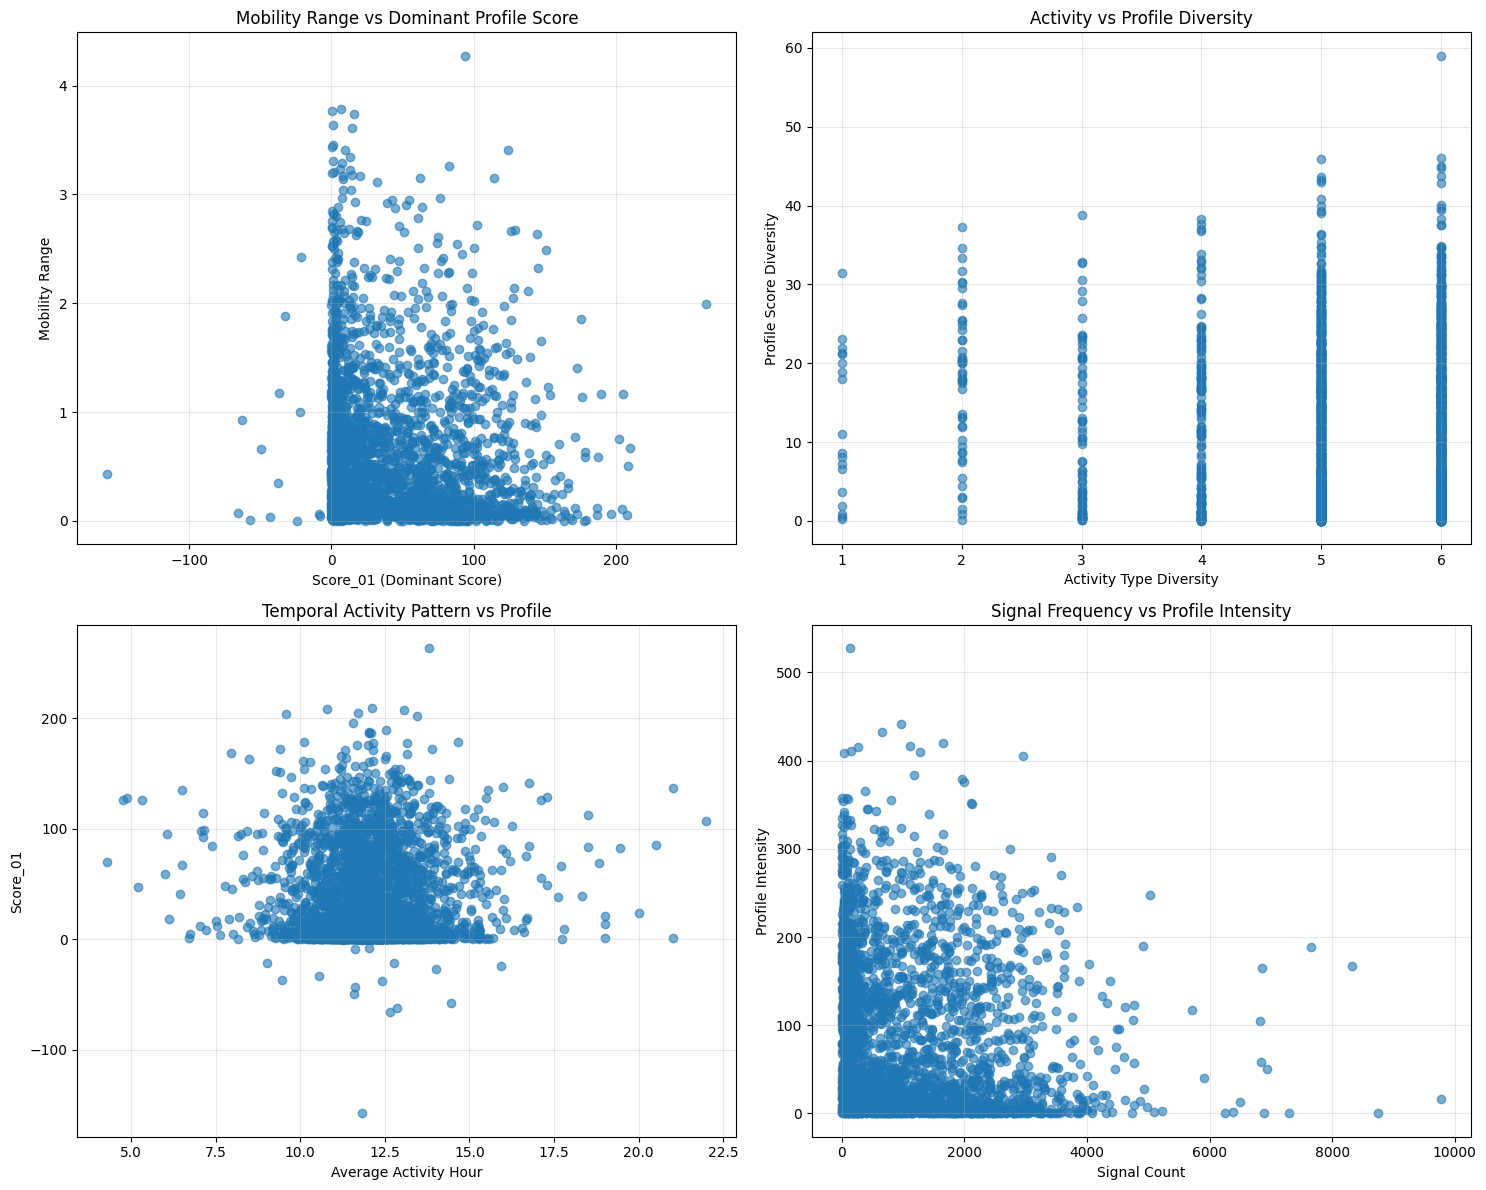

SPATIAL-PROFILE RELATIONSHIPS ANALYSIS

 Profile Similarity by Geographic Proximity
Analyzing spatial-profile relationships for 500 users
Geographic distance vs profile similarity:
  Correlation: r=-0.010
  P-value: 0.653
  Sample pairs: 1900
  No significant spatial-profile relationship

 Neighborhood Profile Homogeneity
Geographic clustering results:
  Neighborhoods identified: 28
  Users in neighborhoods: 2651
  Isolated users: 342
  Average neighborhood profile variance: 95.635
  (Lower values indicate more homogeneous neighborhoods)

 Urban vs Suburban Profile Patterns
Area classification (simulated):
  Urban users: 898
  Suburban users: 2095

Profile comparison (first 5 scores):
  score_01: Urban=46.66, Suburban=34.61 (diff: +34.8%)
  score_02: Urban=1.29, Suburban=0.97 (diff: +32.8%)
  score_03: Urban=2.17, Suburban=1.47 (diff: +47.5%)
  score_04: Urban=2.39, Suburban=1.55 (diff: +54.6%)
  score_05: Urban=2.52, Suburban=1.62 (diff: +55.6%)


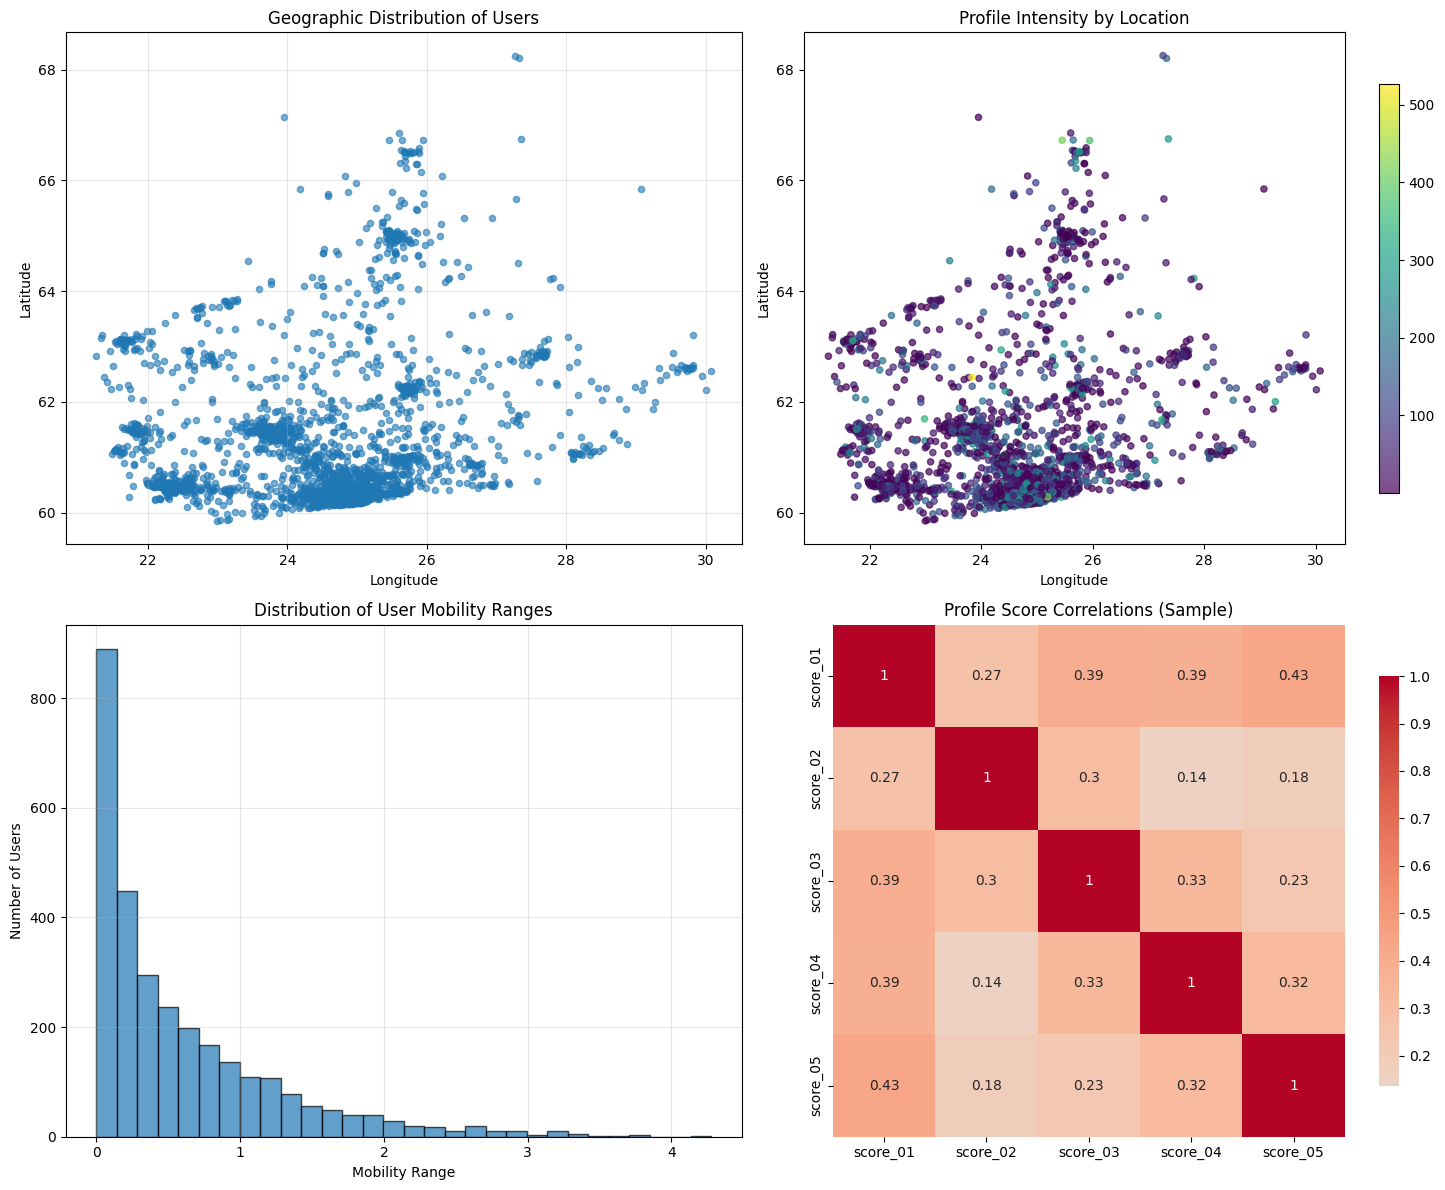


Relationship exploration completed!


In [ ]:
#Key Relations Exploring
class RelationshipExplorer:
    #Explore key relationships between user profiles, movement patterns, and spatial characteristics
    def __init__(self, data_loader):
        self.data_loader = data_loader
        self.user_signals = None
        self.profiles = None
        self.pois = None
        self.integrated_data = {}
        self.load_and_prepare_data()

    def load_and_prepare_data(self):
        # Load datasets
        self.user_signals = self.data_loader.get_combined_data('user_signals', include_source=True)
        self.profiles = self.data_loader.get_combined_data('profiles', include_source=True)
        self.pois = self.data_loader.get_combined_data('pois', include_source=True)

        # Basic data info
        print(f"User signals: {len(self.user_signals):,} records")
        print(f"Profiles: {len(self.profiles):,} records")
        print(f"POIs: {len(self.pois):,} records")
        self._prepare_integrated_data()

    def _prepare_integrated_data(self):
        #Preparing integrated dataset linking users, their signals, and profiles
        if self.user_signals.empty or self.profiles.empty:
            print("Insufficient data for integration")
            return

        # REtrieving unique users with both signals and profiles
        signal_users = set(self.user_signals['user_id'].unique())
        profile_users = set(self.profiles['user_id'].unique())
        common_users = signal_users & profile_users

        print(f"Users with both signals and profiles: {len(common_users):,}")

        # Aggregate signals by user
        signal_agg = self._aggregate_signals_by_user()

        # latest profile for each user
        profile_latest = self._get_latest_profiles()

        # Merging signals and profiles
        if not signal_agg.empty and not profile_latest.empty:
            self.integrated_data = pd.merge(signal_agg, profile_latest, on='user_id', how='inner')
            print(f"Integrated dataset: {len(self.integrated_data):,} users")
            print(f"Columns: {len(self.integrated_data.columns)} features")
        else:
            print("Failed to create integrated dataset")

    def _aggregate_signals_by_user(self):
        if self.user_signals.empty:
            return pd.DataFrame()

        # Defining aggregation functions
        agg_functions = {
            'latitude': ['mean', 'std', 'min', 'max'],
            'longitude': ['mean', 'std', 'min', 'max'],
            'hour': ['mean', 'std'],
            'day_of_week': ['mean', 'std'],
            'activity_type': ['nunique']
        }

        # Adding available columns only
        available_agg = {}
        for col, funcs in agg_functions.items():
            if col in self.user_signals.columns:
                available_agg[col] = funcs

        available_agg['timestamp'] = 'count'

        try:
            signal_agg = self.user_signals.groupby('user_id').agg(available_agg)

            # Flatten column names
            signal_agg.columns = ['_'.join(col).strip() if isinstance(col, tuple) else col
                                 for col in signal_agg.columns]

            # Reset index
            signal_agg = signal_agg.reset_index()

            # Calculating derived features
            if 'latitude_mean' in signal_agg.columns and 'longitude_mean' in signal_agg.columns:
                # Home location approximation
                signal_agg['home_lat'] = signal_agg['latitude_mean']
                signal_agg['home_lon'] = signal_agg['longitude_mean']

                # Mobility range
                if 'latitude_std' in signal_agg.columns and 'longitude_std' in signal_agg.columns:
                    signal_agg['mobility_range'] = np.sqrt(
                        signal_agg['latitude_std']**2 + signal_agg['longitude_std']**2
                    )

            return signal_agg

        except Exception as e:
            print(f"Error aggregating signals: {e}")
            return pd.DataFrame()

    def _get_latest_profiles(self):
        if self.profiles.empty:
            return pd.DataFrame()

        try:
            profile_latest = self.profiles.groupby('user_id').last().reset_index()

            # Keep only score columns and user_id
            score_cols = [col for col in profile_latest.columns if col.startswith('score_')]
            keep_cols = ['user_id'] + score_cols

            profile_latest = profile_latest[keep_cols]
            return profile_latest

        except Exception as e:
            print(f"Error getting latest profiles: {e}")
            return pd.DataFrame()

    def analyze_profile_movement_correlation(self):
        print("PROFILE-MOVEMENT CORRELATION ANALYSIS")

        if not hasattr(self, 'integrated_data') or self.integrated_data.empty:
            print("No integrated data available for analysis")
            return

        # Movement patterns vs profile values
        print("\n Movement Patterns vs Profile Values")
        self._analyze_movement_profile_correlation()

        # Activity types vs profile scores
        print("\nActivity Types vs Profile Scores")
        self._analyze_activity_profile_correlation()

        # High score proximity to POI analysis
        print("\n High Score Users and POI Proximity")
        self._analyze_high_score_poi_proximity()

        # Visualizations
        self._plot_profile_movement_correlations()

    def _analyze_movement_profile_correlation(self):
        #Analyzing correlation between movement patterns and profile scores
        # Movement pattern features
        movement_cols = [col for col in self.integrated_data.columns
                        if any(pattern in col for pattern in ['lat', 'lon', 'hour', 'day', 'mobility', 'count'])]

        # Profile score columns
        score_cols = [col for col in self.integrated_data.columns if col.startswith('score_')]

        if not movement_cols or not score_cols:
            print("Insufficient movement or profile data for correlation analysis")
            return

        print(f"Analyzing {len(movement_cols)} movement features vs {len(score_cols)} profile scores")

        # Calculating correlations
        correlations = []

        for move_col in movement_cols:
            for score_col in score_cols:
                try:
                    # Remove NaN values
                    data = self.integrated_data[[move_col, score_col]].dropna()

                    if len(data) > 10:  # Minimum data requirement
                        corr, p_value = pearsonr(data[move_col], data[score_col])

                        correlations.append({
                            'movement_feature': move_col,
                            'profile_score': score_col,
                            'correlation': corr,
                            'p_value': p_value,
                            'abs_correlation': abs(corr),
                            'n_samples': len(data)
                        })
                except Exception as e:
                    continue

        if correlations:
            corr_df = pd.DataFrame(correlations)

            # strongest correlations
            print("Strongest Movement-Profile Correlations:")
            top_corr = corr_df.nlargest(10, 'abs_correlation')

            for _, row in top_corr.iterrows():
                sig_marker = "**" if row['p_value'] < 0.01 else "*" if row['p_value'] < 0.05 else ""
                print(f"  {row['movement_feature']} ↔ {row['profile_score']}: "
                      f"r={row['correlation']:.3f}{sig_marker} (n={row['n_samples']})")

            return corr_df
        else:
            print("No valid correlations calculated")

    def _analyze_activity_profile_correlation(self):
        #Analyzing the relationship between activity types and profile scores
        if 'activity_type_nunique' not in self.integrated_data.columns:
            print("Activity type data not available")
            return

        # Activity diversity vs profile characteristics
        activity_diversity = self.integrated_data['activity_type_nunique']
        score_cols = [col for col in self.integrated_data.columns if col.startswith('score_')]

        if not score_cols:
            print("No profile scores available")
            return

        print("Activity Diversity vs Profile Scores:")

        for score_col in score_cols[:5]: #Analysing first 5 scores
            try:
                data = self.integrated_data[[score_col, 'activity_type_nunique']].dropna()

                if len(data) > 10:
                    corr, p_value = pearsonr(data[score_col], data['activity_type_nunique'])

                    if abs(corr) > 0.1:
                        sig_marker = "**" if p_value < 0.01 else "*" if p_value < 0.05 else ""
                        print(f"  {score_col}: r={corr:.3f}{sig_marker}")
            except:
                continue

    def _analyze_high_score_poi_proximity(self):
        if self.pois.empty:
            print("POI data not available")
            return

        # Get coordinate columns
        poi_lat_col = None
        poi_lon_col = None

        for col in self.pois.columns:
            if 'lat' in col.lower():
                poi_lat_col = col
            elif 'lon' in col.lower():
                poi_lon_col = col

        if not poi_lat_col or not poi_lon_col:
            print("POI coordinate columns not found")
            return

        # Get POI categories
        category_cols = [col for col in self.pois.columns
                        if any(term in col.lower() for term in ['category', 'type', 'class', 'brand'])]

        if not category_cols:
            print("POI category columns not found")
            return

        category_col = category_cols[0]
        print(f"Using POI category column: {category_col}")

        # Sample analysis for computational efficiency
        sample_size = min(1000, len(self.integrated_data))
        sample_data = self.integrated_data.sample(n=sample_size, random_state=42)

        # Get top POI categories
        top_categories = self.pois[category_col].value_counts().head(5)
        print(f"Top POI categories: {list(top_categories.index)}")


    def _plot_profile_movement_correlations(self):
        #Plotting profile-movement correlation visualizations
        if self.integrated_data.empty:
            return

        fig, axes = plt.subplots(2, 2, figsize=(15, 12))

        # 1. Mobility range vs dominant score
        if 'mobility_range' in self.integrated_data.columns and 'score_01' in self.integrated_data.columns:
            data = self.integrated_data[['mobility_range', 'score_01']].dropna()

            if len(data) > 0:
                axes[0,0].scatter(data['score_01'], data['mobility_range'], alpha=0.6)
                axes[0,0].set_xlabel('Score_01 (Dominant Score)')
                axes[0,0].set_ylabel('Mobility Range')
                axes[0,0].set_title('Mobility Range vs Dominant Profile Score')
                axes[0,0].grid(True, alpha=0.3)

        # 2. Activity diversity vs profile diversity
        score_cols = [col for col in self.integrated_data.columns if col.startswith('score_')]

        if len(score_cols) > 5 and 'activity_type_nunique' in self.integrated_data.columns:
            # Calculate profile diversity
            profile_diversity = self.integrated_data[score_cols].std(axis=1)
            activity_diversity = self.integrated_data['activity_type_nunique']

            data = pd.DataFrame({
                'profile_diversity': profile_diversity,
                'activity_diversity': activity_diversity
            }).dropna()

            if len(data) > 0:
                axes[0,1].scatter(data['activity_diversity'], data['profile_diversity'], alpha=0.6)
                axes[0,1].set_xlabel('Activity Type Diversity')
                axes[0,1].set_ylabel('Profile Score Diversity')
                axes[0,1].set_title('Activity vs Profile Diversity')
                axes[0,1].grid(True, alpha=0.3)

        # 3. Temporal patterns vs profile
        if 'hour_mean' in self.integrated_data.columns and 'score_01' in self.integrated_data.columns:
            data = self.integrated_data[['hour_mean', 'score_01']].dropna()

            if len(data) > 0:
                axes[1,0].scatter(data['hour_mean'], data['score_01'], alpha=0.6)
                axes[1,0].set_xlabel('Average Activity Hour')
                axes[1,0].set_ylabel('Score_01')
                axes[1,0].set_title('Temporal Activity Pattern vs Profile')
                axes[1,0].grid(True, alpha=0.3)

        # 4. Signal count vs profile intensity
        if 'timestamp_count' in self.integrated_data.columns:
            profile_intensity = self.integrated_data[score_cols].abs().sum(axis=1) if score_cols else None

            if profile_intensity is not None:
                data = pd.DataFrame({
                    'signal_count': self.integrated_data['timestamp_count'],
                    'profile_intensity': profile_intensity
                }).dropna()

                if len(data) > 0:
                    axes[1,1].scatter(data['signal_count'], data['profile_intensity'], alpha=0.6)
                    axes[1,1].set_xlabel('Signal Count')
                    axes[1,1].set_ylabel('Profile Intensity')
                    axes[1,1].set_title('Signal Frequency vs Profile Intensity')
                    axes[1,1].grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

    def analyze_spatial_profile_relationships(self):
        print("SPATIAL-PROFILE RELATIONSHIPS ANALYSIS")

        if self.integrated_data.empty:
            print("No integrated data available for spatial analysis")
            return

        # Profile similarity by proximity
        print("\n Profile Similarity by Geographic Proximity")
        self._analyze_spatial_profile_similarity()

        # Neighborhood profile homogeneity
        print("\n Neighborhood Profile Homogeneity")
        self._analyze_neighborhood_homogeneity()

        # Urban vs suburban differences (simulated)
        print("\n Urban vs Suburban Profile Patterns")
        self._analyze_urban_suburban_differences()

        # Visualizations
        self._plot_spatial_profile_relationships()

    def _analyze_spatial_profile_similarity(self):
        if 'home_lat' not in self.integrated_data.columns or 'home_lon' not in self.integrated_data.columns:
            print("Home location data not available")
            return

        # Sample for computational efficiency
        sample_size = min(500, len(self.integrated_data))
        sample_data = self.integrated_data.sample(n=sample_size, random_state=42)

        # Get coordinates and profiles
        coords = sample_data[['home_lat', 'home_lon']].dropna()
        score_cols = [col for col in sample_data.columns if col.startswith('score_')]

        if len(coords) < 10 or not score_cols:
            print("Insufficient data for spatial analysis")
            return

        # Align coordinates and profiles
        common_users = coords.index.intersection(sample_data[score_cols].dropna().index)
        coords_aligned = coords.loc[common_users]
        profiles_aligned = sample_data.loc[common_users, score_cols].fillna(0)

        if len(coords_aligned) < 10:
            print("Insufficient aligned data")
            return

        print(f"Analyzing spatial-profile relationships for {len(coords_aligned)} users")

        # Calculate geographic distances
        def haversine_distance(lat1, lon1, lat2, lon2):
            R = 6371  # Earth's radius in km

            lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
            dlat = lat2 - lat1
            dlon = lon2 - lon1

            a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
            c = 2 * np.arcsin(np.sqrt(a))

            return R * c

        # Sample pairs for analysis
        n_pairs = min(1000, len(coords_aligned) * (len(coords_aligned) - 1) // 2)

        distances = []
        profile_similarities = []

        users = coords_aligned.index.tolist()

        for i in range(min(100, len(users))):  # Limit for computation
            for j in range(i+1, min(i+20, len(users))):  # Compare with nearby users
                user1, user2 = users[i], users[j]

                # Geographic distance
                geo_dist = haversine_distance(
                    coords_aligned.loc[user1, 'home_lat'],
                    coords_aligned.loc[user1, 'home_lon'],
                    coords_aligned.loc[user2, 'home_lat'],
                    coords_aligned.loc[user2, 'home_lon']
                )

                # Profile similarity (cosine similarity)
                profile1 = profiles_aligned.loc[user1].values
                profile2 = profiles_aligned.loc[user2].values

                # Cosine similarity
                dot_product = np.dot(profile1, profile2)
                norm1 = np.linalg.norm(profile1)
                norm2 = np.linalg.norm(profile2)

                if norm1 > 0 and norm2 > 0:
                    similarity = dot_product / (norm1 * norm2)

                    distances.append(geo_dist)
                    profile_similarities.append(similarity)

        if len(distances) > 10:
            # Analyze relationship
            correlation, p_value = pearsonr(distances, profile_similarities)

            print(f"Geographic distance vs profile similarity:")
            print(f"  Correlation: r={correlation:.3f}")
            print(f"  P-value: {p_value:.3f}")
            print(f"  Sample pairs: {len(distances)}")

            if p_value < 0.05:
                if correlation < -0.1:
                    print("  Closer users have more similar profiles")
                elif correlation > 0.1:
                    print("  Farther users have more similar profiles")
                else:
                    print("  Weak spatial-profile relationship")
            else:
                print("  No significant spatial-profile relationship")

    def _analyze_neighborhood_homogeneity(self):
        #Analyzing profile homogeneity within geographic neighborhoods
        if 'home_lat' not in self.integrated_data.columns or 'home_lon' not in self.integrated_data.columns:
            print("Location data not available")
            return

        # Create geographic clusters (neighborhoods)
        coords_data = self.integrated_data[['home_lat', 'home_lon']].dropna()

        if len(coords_data) < 20:
            print("Insufficient location data for neighborhood analysis")
            return

        # Use DBSCAN for neighborhood clustering
        scaler = StandardScaler()
        coords_scaled = scaler.fit_transform(coords_data)

        # Adjust eps based on data scale (roughly 1km in scaled coordinates)
        eps = 0.1
        dbscan = DBSCAN(eps=eps, min_samples=5)
        clusters = dbscan.fit_predict(coords_scaled)

        # Add cluster labels
        coords_data['cluster'] = clusters

        # Get neighborhood statistics
        n_neighborhoods = len(set(clusters)) - (1 if -1 in clusters else 0)
        n_noise = sum(clusters == -1)

        print(f"Geographic clustering results:")
        print(f"  Neighborhoods identified: {n_neighborhoods}")
        print(f"  Users in neighborhoods: {len(coords_data) - n_noise}")
        print(f"  Isolated users: {n_noise}")

        if n_neighborhoods > 1:
            # Analyze profile homogeneity within neighborhoods
            cluster_users = coords_data[coords_data['cluster'] != -1]

            if len(cluster_users) > 0:
                # Get profiles for clustered users
                score_cols = [col for col in self.integrated_data.columns if col.startswith('score_')]

                neighborhood_homogeneity = []

                for cluster_id in cluster_users['cluster'].unique():
                    cluster_user_indices = cluster_users[cluster_users['cluster'] == cluster_id].index
                    cluster_profiles = self.integrated_data.loc[cluster_user_indices, score_cols].fillna(0)

                    if len(cluster_profiles) >= 3:  # Minimum users for analysis
                        # Calculate within-cluster profile variance
                        cluster_variance = cluster_profiles.var().mean()
                        neighborhood_homogeneity.append(cluster_variance)

                if neighborhood_homogeneity:
                    avg_homogeneity = np.mean(neighborhood_homogeneity)
                    print(f"  Average neighborhood profile variance: {avg_homogeneity:.3f}")
                    print(f"  (Lower values indicate more homogeneous neighborhoods)")

    def _analyze_urban_suburban_differences(self):
        if 'home_lat' not in self.integrated_data.columns or 'home_lon' not in self.integrated_data.columns:
            print("Location data not available")
            return

        # Simulate urban/suburban classification based on coordinate density
        coords_data = self.integrated_data[['home_lat', 'home_lon']].dropna()

        if len(coords_data) < 50:
            print("Insufficient location data for urban/suburban analysis")
            return

        # Use local density as proxy for urban vs suburban
        # Higher density = more urban
        nbrs = NearestNeighbors(n_neighbors=min(10, len(coords_data)), algorithm='ball_tree')
        nbrs.fit(coords_data)

        distances, indices = nbrs.kneighbors(coords_data)

        # Average distance to k nearest neighbors as density measure
        density_scores = distances.mean(axis=1)

        # Classify as urban (low distance = high density) vs suburban (high distance = low density)
        density_threshold = np.percentile(density_scores, 30)  # Bottom 30% = urban

        coords_data['area_type'] = np.where(density_scores <= density_threshold, 'Urban', 'Suburban')

        urban_count = sum(coords_data['area_type'] == 'Urban')
        suburban_count = sum(coords_data['area_type'] == 'Suburban')

        print(f"Area classification (simulated):")
        print(f"  Urban users: {urban_count}")
        print(f"  Suburban users: {suburban_count}")

        # Compare profiles between urban and suburban users
        score_cols = [col for col in self.integrated_data.columns if col.startswith('score_')]

        if score_cols and len(coords_data) > 20:
            urban_users = coords_data[coords_data['area_type'] == 'Urban'].index
            suburban_users = coords_data[coords_data['area_type'] == 'Suburban'].index

            urban_profiles = self.integrated_data.loc[urban_users, score_cols].fillna(0)
            suburban_profiles = self.integrated_data.loc[suburban_users, score_cols].fillna(0)

            print(f"\nProfile comparison (first 5 scores):")

            for score_col in score_cols[:5]:
                if score_col in urban_profiles.columns and score_col in suburban_profiles.columns:
                    urban_mean = urban_profiles[score_col].mean()
                    suburban_mean = suburban_profiles[score_col].mean()

                    difference = urban_mean - suburban_mean
                    relative_diff = (difference / suburban_mean * 100) if suburban_mean != 0 else 0

                    print(f"  {score_col}: Urban={urban_mean:.2f}, Suburban={suburban_mean:.2f} "
                          f"(diff: {relative_diff:+.1f}%)")

    def _plot_spatial_profile_relationships(self):
        if self.integrated_data.empty:
            return

        fig, axes = plt.subplots(2, 2, figsize=(15, 12))

        # 1. Geographic distribution of users
        if 'home_lat' in self.integrated_data.columns and 'home_lon' in self.integrated_data.columns:
            coords = self.integrated_data[['home_lat', 'home_lon']].dropna()

            if len(coords) > 0:
                axes[0,0].scatter(coords['home_lon'], coords['home_lat'], alpha=0.6, s=20)
                axes[0,0].set_xlabel('Longitude')
                axes[0,0].set_ylabel('Latitude')
                axes[0,0].set_title('Geographic Distribution of Users')
                axes[0,0].grid(True, alpha=0.3)

        # 2. Profile intensity by location
        if ('home_lat' in self.integrated_data.columns and
            'home_lon' in self.integrated_data.columns):

            score_cols = [col for col in self.integrated_data.columns if col.startswith('score_')]

            if score_cols:
                coords = self.integrated_data[['home_lat', 'home_lon']].dropna()
                profile_intensity = self.integrated_data.loc[coords.index, score_cols].abs().sum(axis=1)

                if len(coords) > 0 and len(profile_intensity) > 0:
                    scatter = axes[0,1].scatter(coords['home_lon'], coords['home_lat'],
                                             c=profile_intensity, cmap='viridis', alpha=0.7, s=20)
                    axes[0,1].set_xlabel('Longitude')
                    axes[0,1].set_ylabel('Latitude')
                    axes[0,1].set_title('Profile Intensity by Location')
                    plt.colorbar(scatter, ax=axes[0,1], shrink=0.8)

        # 3. Mobility range distribution
        if 'mobility_range' in self.integrated_data.columns:
            mobility_data = self.integrated_data['mobility_range'].dropna()

            if len(mobility_data) > 0:
                axes[1,0].hist(mobility_data, bins=30, alpha=0.7, edgecolor='black')
                axes[1,0].set_xlabel('Mobility Range')
                axes[1,0].set_ylabel('Number of Users')
                axes[1,0].set_title('Distribution of User Mobility Ranges')
                axes[1,0].grid(True, alpha=0.3)

        # 4. Score correlation heatmap (sample)
        score_cols = [col for col in self.integrated_data.columns if col.startswith('score_')]

        if len(score_cols) >= 5:
            # Use first 5 scores for visualization
            sample_scores = self.integrated_data[score_cols[:5]].fillna(0)
            correlation_matrix = sample_scores.corr()

            sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
                       square=True, ax=axes[1,1], cbar_kws={"shrink": .8})
            axes[1,1].set_title('Profile Score Correlations (Sample)')

        plt.tight_layout()
        plt.show()

    def generate_relationship_report(self):
        print("COMPREHENSIVE RELATIONSHIP ANALYSIS REPORT")

        self.analyze_profile_movement_correlation()
        self.analyze_spatial_profile_relationships()

# Usage function
def run_relationship_exploration(data_loader):
    explorer = RelationshipExplorer(data_loader)
    explorer.generate_relationship_report()
    return explorer

# Execute the analysis
if 'data_loader' in globals():
    relationship_explorer = run_relationship_exploration(data_loader)
    print("\nRelationship exploration completed!")
else:
    print("Please ensure data_loader is available before running this analysis.")

DATA QUALITY REPORT

 DATASET COMPLETENESS OVERVIEW

USER_SIGNALS:
  Records: 3,333,435
  Unique Users: 2,993
  Columns: 15
  Completeness: 100.0%
  Memory Usage: 1463.4 MB

PROFILES:
  Records: 635,160
  Unique Users: 3,000
  Columns: 25
  Completeness: 100.0%
  Memory Usage: 202.3 MB

VISITORS:
  Records: 1,435
  Unique Users: 150
  Columns: 4
  Completeness: 50.0%
  Memory Usage: 0.3 MB

PARAMETRIC_SCORES:
  Records: 1,094,701
  Unique Users: 0
  Columns: 7
  Completeness: 28.6%
  Memory Usage: 346.6 MB

POIS:
  Records: 720,368
  Unique Users: 0
  Columns: 41
  Completeness: 53.8%
  Memory Usage: 1188.2 MB

-MISSING DATA ANALYSIS 

USER_SIGNALS:
  Overall missing rate: 0.0%
  Columns with missing data: 0/15
  Severely incomplete columns (>50% missing): 0

PROFILES:
  Overall missing rate: 0.0%
  Columns with missing data: 0/25
  Severely incomplete columns (>50% missing): 0

VISITORS:
  Overall missing rate: 50.0%
  Columns with missing data: 3/4
  Severely incomplete columns (>50%

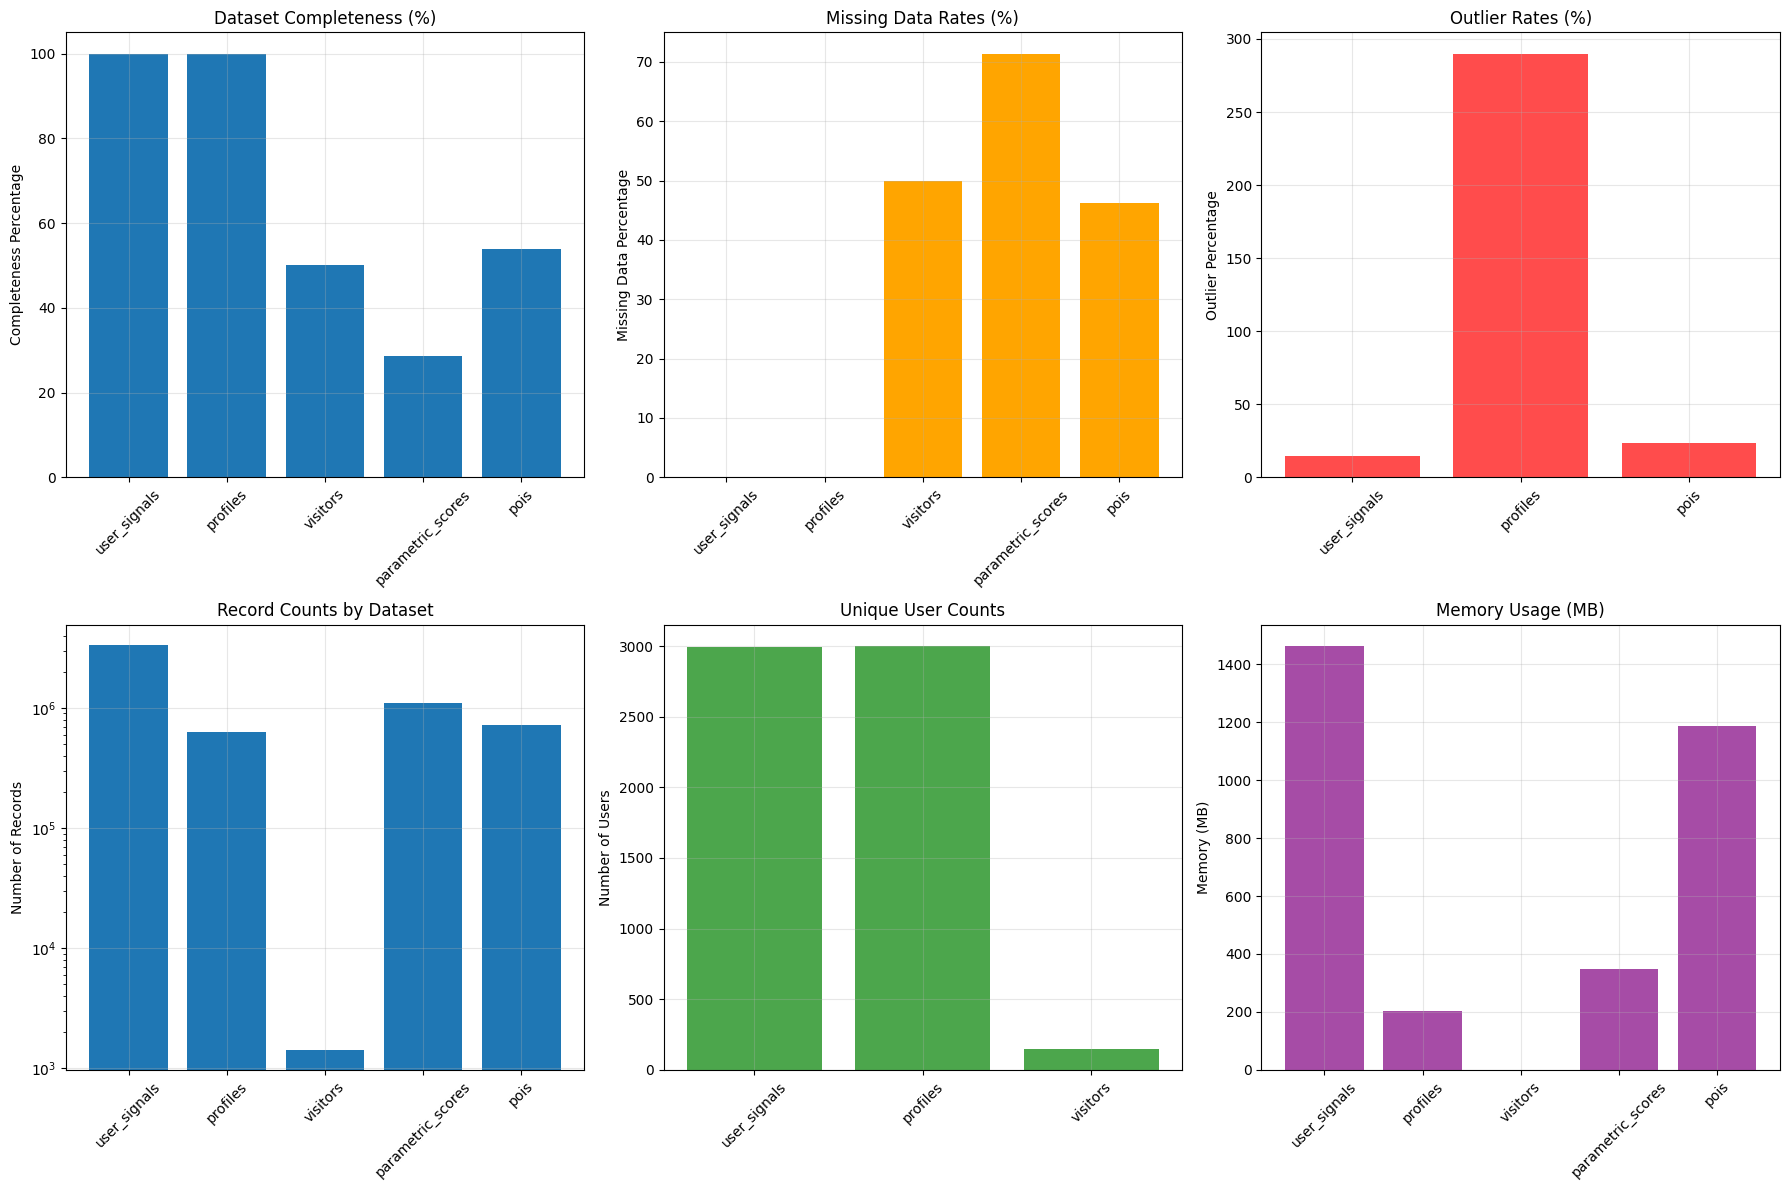

 RESEARCH CONSTRAINTS AND LIMITATIONS

SPATIAL COVERAGE CONSTRAINTS
  Data quality issue: user_signals has coordinates outside Finland
  Urban bias detected: 80.2% southern Finland
  Total spatial constraints identified: 2

 TEMPORAL RESOLUTION CONSTRAINTS
  Signal data has 30 days with no records
  user_signals has uneven monthly distribution (ratio: 5.1:1)
  visitors has uneven monthly distribution (ratio: 7.3:1)
  parametric_scores has uneven monthly distribution (ratio: 4.5:1)
  Short observation period: 76 days
  Total temporal constraints identified: 5

USER SAMPLE CONSTRAINTS 
  Small user sample: 3,000 users
  Poor cross-dataset user overlap: 4.9%
  Total user sample constraints identified: 2

POI COVERAGE CONSTRAINTS
  Total POI constraints identified: 0

--- DATA INTEGRATION CONSTRAINTS ---
  Total integration constraints identified: 0
EXECUTIVE SUMMARY: DATA QUALITY AND RESEARCH CONSTRAINTS

OVERALL DATA QUALITY SCORE: 61.4/100

KEY FINDINGS:
  • 5/5 datasets successfully lo

In [ ]:
#Data Quality Report
class DataQualityReporter:
    def __init__(self, data_loader):
        self.data_loader = data_loader
        self.quality_metrics = {}
        self.constraints = {}
        self.datasets = self._load_all_datasets()

    def _load_all_datasets(self):
        #Load all datasets for quality assessment
        return {
            'user_signals': self.data_loader.get_combined_data('user_signals', include_source=True),
            'profiles': self.data_loader.get_combined_data('profiles', include_source=True),
            'visitors': self.data_loader.get_combined_data('visitors', include_source=True),
            'parametric_scores': self.data_loader.get_combined_data('parametric_scores', include_source=True),
            'pois': self.data_loader.get_combined_data('pois', include_source=True)
        }

    def generate_quality_report(self):
        print("DATA QUALITY REPORT")
        # Dataset overview
        self._analyze_dataset_completeness()

        # Missing data analysis
        self._analyze_missing_data()

        # Outlier analysis
        self._analyze_outliers()

        # Data inconsistencies
        self._analyze_inconsistencies()

        # Coverage limitations
        self._analyze_coverage_limitations()

        # Generate visualizations
        self._plot_quality_metrics()

        return self.quality_metrics

    def _analyze_dataset_completeness(self):
        #Analyze overall dataset completeness
        print("\n DATASET COMPLETENESS OVERVIEW")

        completeness_metrics = {}

        for dataset_name, df in self.datasets.items():
            if df.empty:
                completeness_metrics[dataset_name] = {
                    'total_records': 0,
                    'unique_users': 0,
                    'data_available': False
                }
                continue

            # Basic metrics
            total_records = len(df)

            # Find user column
            user_col = self._find_user_column(df)
            unique_users = df[user_col].nunique() if user_col else 0

            # Calculate completeness
            total_cells = df.shape[0] * df.shape[1]
            non_null_cells = df.count().sum()
            completeness_ratio = non_null_cells / total_cells if total_cells > 0 else 0

            completeness_metrics[dataset_name] = {
                'total_records': total_records,
                'unique_users': unique_users,
                'columns': df.shape[1],
                'completeness_ratio': completeness_ratio,
                'data_available': True,
                'memory_usage_mb': df.memory_usage(deep=True).sum() / 1024 / 1024
            }

            print(f"\n{dataset_name.upper()}:")
            print(f"  Records: {total_records:,}")
            print(f"  Unique Users: {unique_users:,}")
            print(f"  Columns: {df.shape[1]}")
            print(f"  Completeness: {completeness_ratio:.1%}")
            print(f"  Memory Usage: {completeness_metrics[dataset_name]['memory_usage_mb']:.1f} MB")

        self.quality_metrics['completeness'] = completeness_metrics

    def _find_user_column(self, df):
        #Find user ID column in dataframe
        user_patterns = ['user_id', 'user', 'id', 'uid', 'device_id']

        for col in df.columns:
            if col.lower() in user_patterns:
                return col

        # Check if first column looks like UUID
        if len(df.columns) > 0:
            first_col = df.columns[0]
            sample_vals = df[first_col].dropna().head(10).astype(str)
            uuid_like = sample_vals.str.contains(r'^[a-f0-9]{8}-[a-f0-9]{4}-[a-f0-9]{4}-[a-f0-9]{4}-[a-f0-9]{12}$', case=False)
            if uuid_like.any():
                return first_col

        return None

    def _analyze_missing_data(self):
        #Analyze missing data patterns
        print("\n-MISSING DATA ANALYSIS ")

        missing_data_metrics = {}

        for dataset_name, df in self.datasets.items():
            if df.empty:
                continue

            # Calculate missing data by column
            missing_counts = df.isnull().sum()
            missing_percentages = (missing_counts / len(df)) * 100

            # Identify problematic columns (>50% missing)
            problematic_columns = missing_percentages[missing_percentages > 50]

            # Overall missing data rate
            total_missing_rate = df.isnull().sum().sum() / (df.shape[0] * df.shape[1]) * 100

            missing_data_metrics[dataset_name] = {
                'total_missing_rate': total_missing_rate,
                'columns_with_missing': len(missing_counts[missing_counts > 0]),
                'problematic_columns': len(problematic_columns),
                'worst_columns': missing_percentages.nlargest(5).to_dict()
            }

            print(f"\n{dataset_name.upper()}:")
            print(f"  Overall missing rate: {total_missing_rate:.1f}%")
            print(f"  Columns with missing data: {len(missing_counts[missing_counts > 0])}/{len(df.columns)}")
            print(f"  Severely incomplete columns (>50% missing): {len(problematic_columns)}")

            if len(problematic_columns) > 0:
                print(f"  Worst columns:")
                for col, pct in problematic_columns.head(3).items():
                    print(f"    {col}: {pct:.1f}% missing")

        self.quality_metrics['missing_data'] = missing_data_metrics

    def _analyze_outliers(self):
        #Analyze outlier patterns across datasets
        print("\n OUTLIER ANALYSIS ")

        outlier_metrics = {}

        for dataset_name, df in self.datasets.items():
            if df.empty:
                continue

            # Get numeric columns
            numeric_cols = df.select_dtypes(include=[np.number]).columns

            if len(numeric_cols) == 0:
                continue

            total_outliers = 0
            outlier_details = {}

            for col in numeric_cols:
                data = df[col].dropna()

                if len(data) > 10:  # Minimum data for outlier detection
                    # IQR method
                    Q1 = data.quantile(0.25)
                    Q3 = data.quantile(0.75)
                    IQR = Q3 - Q1
                    lower_bound = Q1 - 1.5 * IQR
                    upper_bound = Q3 + 1.5 * IQR

                    outliers = ((data < lower_bound) | (data > upper_bound)).sum()
                    outlier_pct = (outliers / len(data)) * 100

                    total_outliers += outliers
                    outlier_details[col] = {
                        'count': outliers,
                        'percentage': outlier_pct,
                        'min_value': data.min(),
                        'max_value': data.max()
                    }

            outlier_metrics[dataset_name] = {
                'total_outliers': total_outliers,
                'outlier_rate': total_outliers / len(df) * 100 if len(df) > 0 else 0,
                'columns_analyzed': len(numeric_cols),
                'outlier_details': outlier_details
            }

            print(f"\n{dataset_name.upper()}:")
            print(f"  Total outliers detected: {total_outliers:,}")
            print(f"  Outlier rate: {outlier_metrics[dataset_name]['outlier_rate']:.2f}%")
            print(f"  Numeric columns analyzed: {len(numeric_cols)}")

            # Show worst outlier columns
            if outlier_details:
                worst_outliers = sorted(outlier_details.items(),
                                      key=lambda x: x[1]['percentage'], reverse=True)[:3]
                print(f"  Columns with most outliers:")
                for col, details in worst_outliers:
                    if details['percentage'] > 1:  # Only show significant outlier rates
                        print(f"    {col}: {details['count']} ({details['percentage']:.1f}%)")

        self.quality_metrics['outliers'] = outlier_metrics

    def _analyze_inconsistencies(self):
        print("\n DATA INCONSISTENCY ANALYSIS ")
        inconsistency_metrics = {}

        # User ID consistency across datasets
        user_ids_by_dataset = {}
        for dataset_name, df in self.datasets.items():
            if df.empty:
                continue

            user_col = self._find_user_column(df)
            if user_col:
                user_ids_by_dataset[dataset_name] = set(df[user_col].astype(str).unique())

        # Calculate overlap inconsistencies
        if len(user_ids_by_dataset) > 1:
            total_unique_users = len(set.union(*user_ids_by_dataset.values()))
            common_users = len(set.intersection(*user_ids_by_dataset.values()))

            user_consistency = {
                'total_unique_users': total_unique_users,
                'common_users_all_datasets': common_users,
                'consistency_ratio': common_users / total_unique_users if total_unique_users > 0 else 0
            }

            print(f"  User ID Consistency:")
            print(f"    Total unique users across all datasets: {total_unique_users:,}")
            print(f"    Users present in all datasets: {common_users:,}")
            print(f"    Cross-dataset consistency: {user_consistency['consistency_ratio']:.1%}")

            inconsistency_metrics['user_consistency'] = user_consistency

        # Temporal consistency
        temporal_inconsistencies = self._check_temporal_consistency()
        inconsistency_metrics['temporal'] = temporal_inconsistencies

        # Spatial consistency
        spatial_inconsistencies = self._check_spatial_consistency()
        inconsistency_metrics['spatial'] = spatial_inconsistencies

        self.quality_metrics['inconsistencies'] = inconsistency_metrics

    def _check_temporal_consistency(self):
        #Check temporal data consistency
        print(f"\n  Temporal Consistency:")

        temporal_issues = []

        # Check user signals temporal coverage
        if not self.datasets['user_signals'].empty:
            signals = self.datasets['user_signals']

            if 'timestamp' in signals.columns:
                try:
                    timestamps = pd.to_datetime(signals['timestamp'], unit='s', errors='coerce')
                    valid_timestamps = timestamps.dropna()

                    if len(valid_timestamps) > 0:
                        date_range = (valid_timestamps.max() - valid_timestamps.min()).days
                        print(f"    Signal temporal span: {date_range} days")

                        # Check for gaps
                        daily_counts = valid_timestamps.dt.date.value_counts().sort_index()
                        zero_days = 0
                        for i in range(1, len(daily_counts)):
                            current_date = daily_counts.index[i]
                            prev_date = daily_counts.index[i-1]
                            gap_days = (current_date - prev_date).days - 1
                            zero_days += gap_days

                        if zero_days > 0:
                            temporal_issues.append(f"Signal data has {zero_days} days with no records")
                            print(f"    Days with missing data: {zero_days}")
                except:
                    temporal_issues.append("Could not parse signal timestamps")

        # Check monthly data distribution
        monthly_distribution = {}
        for dataset_name, df in self.datasets.items():
            if df.empty or '_source_dataset' not in df.columns:
                continue

            source_counts = df['_source_dataset'].value_counts()
            monthly_counts = {}

            for source, count in source_counts.items():
                month = None
                if '2024-07' in str(source) or '2024_07' in str(source):
                    month = '2024-07'
                elif '2024-08' in str(source) or '2024_08' in str(source):
                    month = '2024-08'
                elif '2024-09' in str(source) or '2024_09' in str(source):
                    month = '2024-09'

                if month:
                    monthly_counts[month] = monthly_counts.get(month, 0) + count

            monthly_distribution[dataset_name] = monthly_counts

        # Check for uneven monthly distribution
        for dataset_name, monthly_counts in monthly_distribution.items():
            if len(monthly_counts) > 1:
                counts = list(monthly_counts.values())
                max_count = max(counts)
                min_count = min(counts)

                if max_count > min_count * 3:  # More than 3x difference
                    ratio = max_count / min_count
                    temporal_issues.append(f"{dataset_name} has uneven monthly distribution (ratio: {ratio:.1f}:1)")
                    print(f"    {dataset_name} monthly imbalance: {ratio:.1f}:1 ratio")

        return {
            'issues_found': len(temporal_issues),
            'issues': temporal_issues,
            'monthly_distribution': monthly_distribution
        }

    def _check_spatial_consistency(self):
        #Check spatial data consistency
        print(f"\n  Spatial Consistency:")

        spatial_issues = []

        # Check coordinate ranges
        datasets_with_coords = ['user_signals', 'pois']
        coordinate_ranges = {}

        for dataset_name in datasets_with_coords:
            df = self.datasets.get(dataset_name)
            if df is None or df.empty:
                continue

            lat_cols = [col for col in df.columns if 'lat' in col.lower()]
            lon_cols = [col for col in df.columns if 'lon' in col.lower()]

            if lat_cols and lon_cols:
                lat_col, lon_col = lat_cols[0], lon_cols[0]

                try:
                    lat_data = pd.to_numeric(df[lat_col], errors='coerce').dropna()
                    lon_data = pd.to_numeric(df[lon_col], errors='coerce').dropna()

                    if len(lat_data) > 0 and len(lon_data) > 0:
                        coord_range = {
                            'lat_min': lat_data.min(),
                            'lat_max': lat_data.max(),
                            'lon_min': lon_data.min(),
                            'lon_max': lon_data.max()
                        }
                        coordinate_ranges[dataset_name] = coord_range

                        print(f"    {dataset_name} coordinates:")
                        print(f"      Lat: {coord_range['lat_min']:.3f} to {coord_range['lat_max']:.3f}")
                        print(f"      Lon: {coord_range['lon_min']:.3f} to {coord_range['lon_max']:.3f}")

                        # Check for unrealistic coordinates
                        if not (59 <= coord_range['lat_min'] <= 71 and 19 <= coord_range['lon_min'] <= 32):
                            spatial_issues.append(f"{dataset_name} has coordinates outside Finland")
                except:
                    spatial_issues.append(f"Could not parse {dataset_name} coordinates")

        # Check coordinate overlap
        if len(coordinate_ranges) > 1:
            ranges = list(coordinate_ranges.values())
            if len(ranges) >= 2:
                range1, range2 = ranges[0], ranges[1]

                lat_overlap = (max(range1['lat_min'], range2['lat_min']),
                              min(range1['lat_max'], range2['lat_max']))
                lon_overlap = (max(range1['lon_min'], range2['lon_min']),
                              min(range1['lon_max'], range2['lon_max']))

                if lat_overlap[1] <= lat_overlap[0] or lon_overlap[1] <= lon_overlap[0]:
                    spatial_issues.append("No geographic overlap between datasets")
                    print(f"    No coordinate overlap detected")
                else:
                    print(f"    Geographic overlap confirmed")
        return {
            'issues_found': len(spatial_issues),
            'issues': spatial_issues,
            'coordinate_ranges': coordinate_ranges
        }

    def _analyze_coverage_limitations(self):
        print("\n--- COVERAGE LIMITATIONS ---")
        coverage_metrics = {}
        # Geographic coverage
        signals = self.datasets.get('user_signals')
        if signals is not None and not signals.empty:
            lat_cols = [col for col in signals.columns if 'lat' in col.lower()]
            if lat_cols:
                lat_data = pd.to_numeric(signals[lat_cols[0]], errors='coerce').dropna()

                # Finland coverage analysis
                finland_south = 59.8
                finland_north = 70.1
                coverage_pct = len(lat_data[(lat_data >= finland_south) &
                                          (lat_data <= finland_north)]) / len(lat_data) * 100

                coverage_metrics['geographic'] = {
                    'finland_coverage_pct': coverage_pct,
                    'total_coordinates': len(lat_data)
                }
                print(f"  Geographic Coverage:")
                print(f"    Finland coverage: {coverage_pct:.1f}%")
                print(f"    Total coordinate points: {len(lat_data):,}")

        # Temporal coverage
        temporal_coverage = self._analyze_temporal_coverage()
        coverage_metrics['temporal'] = temporal_coverage

        # User coverage
        user_coverage = self._analyze_user_coverage()
        coverage_metrics['user'] = user_coverage
        self.quality_metrics['coverage'] = coverage_metrics

    def _analyze_temporal_coverage(self):
        print(f"  Temporal Coverage:")

        # Expected time range: July-September 2024
        expected_months = ['2024-07', '2024-08', '2024-09']
        coverage_by_dataset = {}
        for dataset_name, df in self.datasets.items():
            if df.empty or '_source_dataset' not in df.columns:
                continue

            source_counts = df['_source_dataset'].value_counts()
            covered_months = []

            for month in expected_months:
                month_data = [source for source in source_counts.index if month in str(source)]
                if month_data:
                    covered_months.append(month)
            coverage_by_dataset[dataset_name] = {
                'covered_months': covered_months,
                'coverage_ratio': len(covered_months) / len(expected_months)
            }
            print(f"    {dataset_name}: {len(covered_months)}/3 months ({coverage_by_dataset[dataset_name]['coverage_ratio']:.1%})")

        return coverage_by_dataset

    def _analyze_user_coverage(self):
        print(f"  User Coverage:")
        user_counts = {}
        for dataset_name, df in self.datasets.items():
            if df.empty:
                continue

            user_col = self._find_user_column(df)
            if user_col:
                user_counts[dataset_name] = df[user_col].nunique()

        if user_counts:
            max_users = max(user_counts.values())

            for dataset_name, count in user_counts.items():
                coverage_pct = (count / max_users) * 100 if max_users > 0 else 0
                print(f"    {dataset_name}: {count:,} users ({coverage_pct:.1f}% of max)")
        return user_counts

    def _plot_quality_metrics(self):
        fig, axes = plt.subplots(2, 3, figsize=(18, 12))

        # 1. Dataset completeness
        if 'completeness' in self.quality_metrics:
            datasets = []
            completeness = []
            for name, metrics in self.quality_metrics['completeness'].items():
                if metrics['data_available']:
                    datasets.append(name)
                    completeness.append(metrics['completeness_ratio'] * 100)

            if datasets:
                axes[0,0].bar(datasets, completeness)
                axes[0,0].set_title('Dataset Completeness (%)')
                axes[0,0].set_ylabel('Completeness Percentage')
                axes[0,0].tick_params(axis='x', rotation=45)
                axes[0,0].grid(True, alpha=0.3)

        # 2. Missing data rates
        if 'missing_data' in self.quality_metrics:
            datasets = []
            missing_rates = []
            for name, metrics in self.quality_metrics['missing_data'].items():
                datasets.append(name)
                missing_rates.append(metrics['total_missing_rate'])

            if datasets:
                axes[0,1].bar(datasets, missing_rates, color='orange')
                axes[0,1].set_title('Missing Data Rates (%)')
                axes[0,1].set_ylabel('Missing Data Percentage')
                axes[0,1].tick_params(axis='x', rotation=45)
                axes[0,1].grid(True, alpha=0.3)

        # 3. Outlier rates
        if 'outliers' in self.quality_metrics:
            datasets = []
            outlier_rates = []
            for name, metrics in self.quality_metrics['outliers'].items():
                datasets.append(name)
                outlier_rates.append(metrics['outlier_rate'])

            if datasets:
                axes[0,2].bar(datasets, outlier_rates, color='red', alpha=0.7)
                axes[0,2].set_title('Outlier Rates (%)')
                axes[0,2].set_ylabel('Outlier Percentage')
                axes[0,2].tick_params(axis='x', rotation=45)
                axes[0,2].grid(True, alpha=0.3)

        # 4. Record counts by dataset
        if 'completeness' in self.quality_metrics:
            datasets = []
            record_counts = []
            for name, metrics in self.quality_metrics['completeness'].items():
                if metrics['data_available']:
                    datasets.append(name)
                    record_counts.append(metrics['total_records'])

            if datasets:
                axes[1,0].bar(datasets, record_counts)
                axes[1,0].set_title('Record Counts by Dataset')
                axes[1,0].set_ylabel('Number of Records')
                axes[1,0].set_yscale('log')
                axes[1,0].tick_params(axis='x', rotation=45)
                axes[1,0].grid(True, alpha=0.3)

        # 5. User counts by dataset
        if 'completeness' in self.quality_metrics:
            datasets = []
            user_counts = []
            for name, metrics in self.quality_metrics['completeness'].items():
                if metrics['data_available'] and metrics['unique_users'] > 0:
                    datasets.append(name)
                    user_counts.append(metrics['unique_users'])

            if datasets:
                axes[1,1].bar(datasets, user_counts, color='green', alpha=0.7)
                axes[1,1].set_title('Unique User Counts')
                axes[1,1].set_ylabel('Number of Users')
                axes[1,1].tick_params(axis='x', rotation=45)
                axes[1,1].grid(True, alpha=0.3)

        # 6. Memory usage
        if 'completeness' in self.quality_metrics:
            datasets = []
            memory_usage = []
            for name, metrics in self.quality_metrics['completeness'].items():
                if metrics['data_available']:
                    datasets.append(name)
                    memory_usage.append(metrics['memory_usage_mb'])

            if datasets:
                axes[1,2].bar(datasets, memory_usage, color='purple', alpha=0.7)
                axes[1,2].set_title('Memory Usage (MB)')
                axes[1,2].set_ylabel('Memory (MB)')
                axes[1,2].tick_params(axis='x', rotation=45)
                axes[1,2].grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

    def identify_research_constraints(self):
        print(" RESEARCH CONSTRAINTS AND LIMITATIONS")
        constraints = {}

        # Spatial coverage constraints
        constraints['spatial'] = self._identify_spatial_constraints()

        # Temporal resolution constraints
        constraints['temporal'] = self._identify_temporal_constraints()

        # User sample constraints
        constraints['user_sample'] = self._identify_user_sample_constraints()

        # POI category constraints
        constraints['poi_coverage'] = self._identify_poi_constraints()

        # Data integration constraints
        constraints['integration'] = self._identify_integration_constraints()

        self.constraints = constraints
        return constraints

    def _identify_spatial_constraints(self):
        print("\nSPATIAL COVERAGE CONSTRAINTS")

        spatial_constraints = []

        # Check geographic coverage
        if 'coverage' in self.quality_metrics and 'geographic' in self.quality_metrics['coverage']:
            coverage_pct = self.quality_metrics['coverage']['geographic']['finland_coverage_pct']

            if coverage_pct < 95:
                spatial_constraints.append(f"Geographic coverage incomplete: {coverage_pct:.1f}% of Finland")
                print(f"  Limited geographic coverage: {coverage_pct:.1f}% of Finland")

        # Check coordinate accuracy
        if 'inconsistencies' in self.quality_metrics and 'spatial' in self.quality_metrics['inconsistencies']:
            spatial_issues = self.quality_metrics['inconsistencies']['spatial']['issues']

            if spatial_issues:
                for issue in spatial_issues:
                    spatial_constraints.append(f"Spatial data issue: {issue}")
                    print(f"  Data quality issue: {issue}")

        # Urban vs rural bias
        signals = self.datasets.get('user_signals')
        if signals is not None and not signals.empty:
            lat_cols = [col for col in signals.columns if 'lat' in col.lower()]
            if lat_cols:
                lat_data = pd.to_numeric(signals[lat_cols[0]], errors='coerce').dropna()

                # Check concentration in southern Finland (urban bias)
                southern_finland = lat_data[lat_data < 62].count()
                total_points = len(lat_data)
                southern_pct = (southern_finland / total_points) * 100 if total_points > 0 else 0

                if southern_pct > 70:
                    spatial_constraints.append(f"Urban bias: {southern_pct:.1f}% of data from southern Finland")
                    print(f"  Urban bias detected: {southern_pct:.1f}% southern Finland")

        print(f"  Total spatial constraints identified: {len(spatial_constraints)}")
        return spatial_constraints

    def _identify_temporal_constraints(self):
        print("\n TEMPORAL RESOLUTION CONSTRAINTS")
        temporal_constraints = []

        # Check temporal consistency
        if 'inconsistencies' in self.quality_metrics and 'temporal' in self.quality_metrics['inconsistencies']:
            temporal_issues = self.quality_metrics['inconsistencies']['temporal']['issues']

            for issue in temporal_issues:
                temporal_constraints.append(f"Temporal issue: {issue}")
                print(f"  {issue}")

        # Check data collection period
        signals = self.datasets.get('user_signals')
        if signals is not None and not signals.empty and 'timestamp' in signals.columns:
            try:
                timestamps = pd.to_datetime(signals['timestamp'], unit='s', errors='coerce').dropna()

                if len(timestamps) > 0:
                    date_range = (timestamps.max() - timestamps.min()).days

                    if date_range < 90:  # Less than 3 months
                        temporal_constraints.append(f"Limited temporal coverage: {date_range} days")
                        print(f"  Short observation period: {date_range} days")

                    # Check for seasonal bias
                    month_counts = timestamps.dt.month.value_counts()
                    if len(month_counts) < 3:
                        temporal_constraints.append("Limited seasonal coverage")
                        print(f"  Limited seasonal coverage: {len(month_counts)} months")
            except:
                temporal_constraints.append("Timestamp parsing issues")
                print(f"  Cannot parse temporal data")

        print(f"  Total temporal constraints identified: {len(temporal_constraints)}")
        return temporal_constraints

    def _identify_user_sample_constraints(self):
        print("\nUSER SAMPLE CONSTRAINTS ")
        user_constraints = []

        # Check sample size
        user_counts = {}
        for dataset_name, df in self.datasets.items():
            if df.empty:
                continue

            user_col = self._find_user_column(df)
            if user_col:
                user_counts[dataset_name] = df[user_col].nunique()

        if user_counts:
            max_users = max(user_counts.values())
            if max_users < 10000:
                user_constraints.append(f"Limited sample size: {max_users:,} users")
                print(f"  Small user sample: {max_users:,} users")

        # Check user consistency across datasets
        if 'inconsistencies' in self.quality_metrics and 'user_consistency' in self.quality_metrics['inconsistencies']:
            consistency = self.quality_metrics['inconsistencies']['user_consistency']['consistency_ratio']

            if consistency < 0.5:
                user_constraints.append(f"Low user consistency across datasets: {consistency:.1%}")
                print(f"  Poor cross-dataset user overlap: {consistency:.1%}")

        # Check for demographic bias (based on activity patterns)
        signals = self.datasets.get('user_signals')
        if signals is not None and not signals.empty and 'hour' in signals.columns:
            try:
                hour_data = pd.to_numeric(signals['hour'], errors='coerce').dropna()

                # Check for working hours bias
                working_hours = hour_data[(hour_data >= 9) & (hour_data <= 17)]
                working_hours_pct = len(working_hours) / len(hour_data) * 100

                if working_hours_pct > 60:
                    user_constraints.append(f"Working hours bias: {working_hours_pct:.1f}% of signals")
                    print(f"  Working hours bias: {working_hours_pct:.1f}% during 9-17h")
            except:
                pass

        print(f"  Total user sample constraints identified: {len(user_constraints)}")
        return user_constraints

    def _identify_poi_constraints(self):
        print("\nPOI COVERAGE CONSTRAINTS")
        poi_constraints = []
        pois = self.datasets.get('pois')
        if pois is None or pois.empty:
            poi_constraints.append("No POI data available")
            print(f"  No POI data loaded")
            return poi_constraints

        # Check POI category distribution
        category_cols = [col for col in pois.columns
                        if any(term in col.lower() for term in ['category', 'type', 'class', 'brand'])]

        if category_cols:
            category_col = category_cols[0]
            category_counts = pois[category_col].value_counts()

            # Check for category bias
            top_category_pct = category_counts.iloc[0] / len(pois) * 100
            if top_category_pct > 50:
                poi_constraints.append(f"POI category bias: {top_category_pct:.1f}% in top category")
                print(f"  Category imbalance: {top_category_pct:.1f}% in '{category_counts.index[0]}'")

            # Check category diversity
            unique_categories = len(category_counts)
            if unique_categories < 10:
                poi_constraints.append(f"Limited POI diversity: {unique_categories} categories")
                print(f"  Low category diversity: {unique_categories} categories")
        else:
            poi_constraints.append("No POI category information available")
            print(f"  Missing category information")

        print(f"  Total POI constraints identified: {len(poi_constraints)}")
        return poi_constraints

    def _identify_integration_constraints(self):
        print("\n--- DATA INTEGRATION CONSTRAINTS ---")
        integration_constraints = []

        # Check dataset availability
        available_datasets = sum(1 for df in self.datasets.values() if not df.empty)
        expected_datasets = 5
        if available_datasets < expected_datasets:
            missing = expected_datasets - available_datasets
            integration_constraints.append(f"Missing {missing} datasets for complete integration")
            print(f"  Missing datasets: {missing}/{expected_datasets}")

        # Check user linkage capability
        datasets_with_users = 0
        for dataset_name, df in self.datasets.items():
            if not df.empty:
                user_col = self._find_user_column(df)
                if user_col:
                    datasets_with_users += 1

        if datasets_with_users < 3:
            integration_constraints.append(f"Limited user linkage: only {datasets_with_users} datasets have user IDs")
            print(f"  Poor user linkage: {datasets_with_users} datasets with user IDs")

        # Check temporal alignment
        if 'coverage' in self.quality_metrics and 'temporal' in self.quality_metrics['coverage']:
            temporal_coverage = self.quality_metrics['coverage']['temporal']
            datasets_with_full_temporal = sum(1 for coverage in temporal_coverage.values()
                                            if coverage['coverage_ratio'] >= 1.0)

            if datasets_with_full_temporal < 2:
                integration_constraints.append("Poor temporal alignment across datasets")
                print(f"  Temporal misalignment: only {datasets_with_full_temporal} datasets with full coverage")

        print(f"  Total integration constraints identified: {len(integration_constraints)}")
        return integration_constraints

    def generate_executive_summary(self):
        print("EXECUTIVE SUMMARY: DATA QUALITY AND RESEARCH CONSTRAINTS")

        # Overall data quality score
        quality_score = self._calculate_overall_quality_score()
        print(f"\nOVERALL DATA QUALITY SCORE: {quality_score:.1f}/100")

        # Key findings
        print(f"\nKEY FINDINGS:")
        # Dataset availability
        available_datasets = sum(1 for df in self.datasets.values() if not df.empty)
        print(f"  • {available_datasets}/5 datasets successfully loaded")

        # Record counts
        total_records = sum(len(df) for df in self.datasets.values() if not df.empty)
        print(f"  • {total_records:,} total records across all datasets")

        # User coverage
        user_counts = []
        for df in self.datasets.values():
            if not df.empty:
                user_col = self._find_user_column(df)
                if user_col:
                    user_counts.append(df[user_col].nunique())

        if user_counts:
            max_users = max(user_counts)
            print(f"  • {max_users:,} unique users identified")

        # Major constraints
        total_constraints = sum(len(constraints) for constraints in self.constraints.values())
        print(f"  • {total_constraints} research constraints identified")

        # Top constraints to address
        all_constraints = []
        for constraint_type, constraint_list in self.constraints.items():
            all_constraints.extend(constraint_list)

        if all_constraints:
            print(f" Priority constraints to address:")
            for i, constraint in enumerate(all_constraints[:3], 1):
                print(f"    {i}. {constraint}")

    def _calculate_overall_quality_score(self):
        #Calculate overall data quality score
        score = 0
        max_score = 100

        # Dataset completeness (25 points)
        if 'completeness' in self.quality_metrics:
            available_datasets = sum(1 for metrics in self.quality_metrics['completeness'].values()
                                   if metrics['data_available'])
            score += (available_datasets / 5) * 25

        # Data completeness (25 points)
        if 'missing_data' in self.quality_metrics:
            avg_missing_rate = np.mean([metrics['total_missing_rate']
                                      for metrics in self.quality_metrics['missing_data'].values()])
            score += (1 - avg_missing_rate / 100) * 25

        # Data consistency (25 points)
        if 'inconsistencies' in self.quality_metrics:
            # User consistency
            user_consistency = self.quality_metrics['inconsistencies'].get('user_consistency', {})
            if 'consistency_ratio' in user_consistency:
                score += user_consistency['consistency_ratio'] * 15

            # Temporal/spatial issues
            temporal_issues = len(self.quality_metrics['inconsistencies']['temporal']['issues'])
            spatial_issues = len(self.quality_metrics['inconsistencies']['spatial']['issues'])

            if temporal_issues + spatial_issues == 0:
                score += 10
            elif temporal_issues + spatial_issues <= 2:
                score += 5

        # Coverage adequacy (25 points)
        if 'coverage' in self.quality_metrics:
            # Geographic coverage
            if 'geographic' in self.quality_metrics['coverage']:
                geo_coverage = self.quality_metrics['coverage']['geographic']['finland_coverage_pct']
                score += (geo_coverage / 100) * 15

            # Temporal coverage
            if 'temporal' in self.quality_metrics['coverage']:
                full_coverage_datasets = sum(1 for coverage in self.quality_metrics['coverage']['temporal'].values()
                                           if coverage['coverage_ratio'] >= 1.0)
                score += (full_coverage_datasets / 5) * 10

        return min(score, max_score)

# Usage function
def run_data_quality_assessment(data_loader):
    reporter = DataQualityReporter(data_loader)

    # Generate quality report
    quality_metrics = reporter.generate_quality_report()

    # Identify constraints
    constraints = reporter.identify_research_constraints()

    # Generate executive summary
    reporter.generate_executive_summary()

    return reporter, quality_metrics, constraints

# Execute the assessment
if 'data_loader' in globals():
    quality_reporter, quality_metrics, research_constraints = run_data_quality_assessment(data_loader)
    print("\nData quality assessment completed!")
else:
    print("Please ensure data_loader is available before running this assessment.")

In [ ]:
#Data Integration pipeline
class DataIntegrationPipeline:
    def __init__(self, data_loader):
        self.data_loader = data_loader
        self.master_user_table = None
        self.integrated_profiles = None
        self.spatial_lookup = None
        self.visit_database = None

    def execute_full_pipeline(self):
        #Execute all integration steps in sequence
        print("EXECUTING CRITICAL DATA INTEGRATION PIPELINE")

        # Step 1: Create Master User Table
        self.create_master_user_table()

        # Step 2: Temporal Alignment
        self.temporal_alignment()

        # Step 3: Spatial Integration
        self.spatial_integration()

        # Step 4: ID Reconciliation
        self.id_reconciliation()

        # Step 5: Create Analysis-Ready Dataset
        self.create_analysis_ready_datasets()

        print("INTEGRATION PIPELINE COMPLETED")
        self.print_integration_summary()

    def create_master_user_table(self):
        print("\n Creating Master User Table")

        # Get all user datasets
        user_signals = self.data_loader.get_combined_data('user_signals', include_source=True)
        profiles = self.data_loader.get_combined_data('profiles', include_source=True)
        visitors = self.data_loader.get_combined_data('visitors', include_source=True)
        parametric_scores = self.data_loader.get_combined_data('parametric_scores', include_source=True)

        # Extract all unique user IDs
        all_users = set()

        # From signals
        if not user_signals.empty and 'user_id' in user_signals.columns:
            all_users.update(user_signals['user_id'].unique())

        # From profiles
        if not profiles.empty and 'user_id' in profiles.columns:
            all_users.update(profiles['user_id'].unique())

        # From visitors (find user column)
        if not visitors.empty:
            visitor_user_col = self._find_user_column(visitors)
            if visitor_user_col:
                all_users.update(visitors[visitor_user_col].unique())

        print(f"Total unique users identified: {len(all_users):,}")

        # Create master table
        master_data = []

        for user_id in all_users:
            user_record = {'user_id': user_id}

            # Check data availability
            user_record['has_signals'] = user_id in user_signals['user_id'].values if not user_signals.empty else False
            user_record['has_profile'] = user_id in profiles['user_id'].values if not profiles.empty else False

            # Basic statistics from signals
            if user_record['has_signals']:
                user_signals_data = user_signals[user_signals['user_id'] == user_id]
                user_record['total_signals'] = len(user_signals_data)
                user_record['active_days'] = user_signals_data['date'].nunique() if 'date' in user_signals_data.columns else 1
                user_record['first_signal'] = user_signals_data['timestamp'].min() if 'timestamp' in user_signals_data.columns else None
                user_record['last_signal'] = user_signals_data['timestamp'].max() if 'timestamp' in user_signals_data.columns else None

                # Location statistics
                if 'latitude' in user_signals_data.columns and 'longitude' in user_signals_data.columns:
                    user_record['home_lat'] = user_signals_data['latitude'].median()
                    user_record['home_lon'] = user_signals_data['longitude'].median()
                    user_record['mobility_range'] = np.sqrt(
                        user_signals_data['latitude'].std()**2 + user_signals_data['longitude'].std()**2
                    )
            else:
                user_record.update({
                    'total_signals': 0, 'active_days': 0, 'first_signal': None,
                    'last_signal': None, 'home_lat': None, 'home_lon': None, 'mobility_range': 0
                })

            # Profile completeness
            if user_record['has_profile']:
                user_profile_data = profiles[profiles['user_id'] == user_id].iloc[-1]  # Latest profile
                score_cols = [col for col in profiles.columns if col.startswith('score_')]

                if score_cols:
                    non_null_scores = user_profile_data[score_cols].notna().sum()
                    non_zero_scores = (user_profile_data[score_cols].fillna(0) != 0).sum()
                    user_record['profile_completeness'] = non_null_scores / len(score_cols)
                    user_record['profile_activity'] = non_zero_scores / len(score_cols)
                    user_record['dominant_score'] = user_profile_data[score_cols].abs().idxmax()
                else:
                    user_record.update({'profile_completeness': 0, 'profile_activity': 0, 'dominant_score': None})
            else:
                user_record.update({'profile_completeness': 0, 'profile_activity': 0, 'dominant_score': None})

            # Data quality score (0-1)
            quality_factors = [
                user_record['has_signals'],
                user_record['has_profile'],
                user_record['total_signals'] > 10,
                user_record['profile_completeness'] > 0.5,
                user_record['active_days'] > 1
            ]
            user_record['data_quality_score'] = sum(quality_factors) / len(quality_factors)

            master_data.append(user_record)

        self.master_user_table = pd.DataFrame(master_data)

        print(f"Master user table created with {len(self.master_user_table)} users")
        print(f"Users with signals: {self.master_user_table['has_signals'].sum():,}")
        print(f"Users with profiles: {self.master_user_table['has_profile'].sum():,}")
        print(f"High-quality users (score > 0.6): {(self.master_user_table['data_quality_score'] > 0.6).sum():,}")

    def temporal_alignment(self):
        print("\nTemporal Alignment")

        # Get temporal data
        user_signals = self.data_loader.get_combined_data('user_signals', include_source=True)
        profiles = self.data_loader.get_combined_data('profiles', include_source=True)

        if user_signals.empty:
            print("No signal data available for temporal alignment")
            return

        # Parse temporal information from signals
        temporal_stats = {}

        if 'timestamp' in user_signals.columns:
            user_signals['datetime'] = pd.to_datetime(user_signals['timestamp'], unit='s', errors='coerce')
            user_signals['month'] = user_signals['datetime'].dt.to_period('M')

            print("Signal temporal coverage:")
            monthly_coverage = user_signals['month'].value_counts().sort_index()
            for month, count in monthly_coverage.items():
                print(f"  {month}: {count:,} signals")

        # Parse profile temporal information
        if not profiles.empty and '_source_dataset' in profiles.columns:
            print("Profile temporal coverage:")
            profile_months = profiles['_source_dataset'].value_counts()
            for source, count in profile_months.items():
                month = source.split('_')[-1] if '_' in source else source
                print(f"  {month}: {count:,} profiles")

        # Create unified timeline for each user
        timeline_data = []

        for user_id in self.master_user_table['user_id']:
            if user_id in user_signals['user_id'].values:
                user_timeline = user_signals[user_signals['user_id'] == user_id]

                if 'datetime' in user_timeline.columns:
                    timeline_entry = {
                        'user_id': user_id,
                        'signal_start': user_timeline['datetime'].min(),
                        'signal_end': user_timeline['datetime'].max(),
                        'signal_months': user_timeline['month'].nunique(),
                        'signal_days': user_timeline['datetime'].dt.date.nunique()
                    }
                    timeline_data.append(timeline_entry)

        if timeline_data:
            timeline_df = pd.DataFrame(timeline_data)

            # Add to master table
            self.master_user_table = self.master_user_table.merge(
                timeline_df, on='user_id', how='left'
            )

            print(f"Temporal alignment completed for {len(timeline_df)} users")

    def spatial_integration(self):
        print("\nSpatial Integration")

        # Get spatial datasets
        user_signals = self.data_loader.get_combined_data('user_signals', include_source=True)
        pois = self.data_loader.get_combined_data('pois', include_source=True)

        spatial_data = []

        # Process user signals for spatial features
        if not user_signals.empty and 'latitude' in user_signals.columns:
            print("Creating H3 indices and spatial lookup...")

            for user_id in self.master_user_table['user_id']:
                if user_id in user_signals['user_id'].values:
                    user_locs = user_signals[user_signals['user_id'] == user_id]

                    if len(user_locs) > 0:
                        # Home location (median of all locations)
                        home_lat = user_locs['latitude'].median()
                        home_lon = user_locs['longitude'].median()

                        # Generate H3 indices at different resolutions
                        try:
                            h3_7 = h3.geo_to_h3(home_lat, home_lon, 7)
                            h3_8 = h3.geo_to_h3(home_lat, home_lon, 8)
                            h3_9 = h3.geo_to_h3(home_lat, home_lon, 9)
                        except:
                            h3_7 = h3_8 = h3_9 = None

                        # Activity area (convex hull approximation)
                        lat_range = user_locs['latitude'].max() - user_locs['latitude'].min()
                        lon_range = user_locs['longitude'].max() - user_locs['longitude'].min()

                        spatial_entry = {
                            'user_id': user_id,
                            'home_lat_clean': home_lat,
                            'home_lon_clean': home_lon,
                            'h3_res7': h3_7,
                            'h3_res8': h3_8,
                            'h3_res9': h3_9,
                            'activity_area_lat': lat_range,
                            'activity_area_lon': lon_range,
                            'unique_locations': len(user_locs[['latitude', 'longitude']].drop_duplicates())
                        }
                        spatial_data.append(spatial_entry)

        if spatial_data:
            spatial_df = pd.DataFrame(spatial_data)

            # Merge with master table
            self.master_user_table = self.master_user_table.merge(
                spatial_df, on='user_id', how='left'
            )

            print(f"Spatial integration completed for {len(spatial_df)} users")

            # Create POI proximity features
            if not pois.empty:
                self._create_poi_proximity_features(spatial_df, pois)

        self.spatial_lookup = spatial_data

    def _create_poi_proximity_features(self, spatial_df, pois):
        # Find POI coordinate columns
        poi_lat_col = poi_lon_col = None
        for col in pois.columns:
            if 'lat' in col.lower() and poi_lat_col is None:
                poi_lat_col = col
            elif 'lon' in col.lower() and poi_lon_col is None:
                poi_lon_col = col

        if poi_lat_col and poi_lon_col:
            # Sample POIs for performance
            poi_sample = pois[[poi_lat_col, poi_lon_col]].dropna().sample(
                min(1000, len(pois)), random_state=42
            )

            # Calculate average distance to POIs for each user
            poi_proximity = []

            for _, user in spatial_df.iterrows():
                if pd.notna(user['home_lat_clean']) and pd.notna(user['home_lon_clean']):
                    user_coords = np.array([[user['home_lat_clean'], user['home_lon_clean']]])
                    poi_coords = poi_sample[[poi_lat_col, poi_lon_col]].values

                    # Calculate distances (simplified)
                    distances = cdist(user_coords, poi_coords, metric='euclidean')[0]

                    poi_proximity.append({
                        'user_id': user['user_id'],
                        'avg_poi_distance': distances.mean(),
                        'min_poi_distance': distances.min(),
                        'nearby_pois_500m': (distances < 0.005).sum()  # Rough 500m in degrees
                    })

            if poi_proximity:
                poi_df = pd.DataFrame(poi_proximity)
                self.master_user_table = self.master_user_table.merge(
                    poi_df, on='user_id', how='left'
                )
                print(f"POI proximity calculated for {len(poi_df)} users")

    def id_reconciliation(self):
        print("\nID Reconciliation")

        # Check for potential duplicate users based on location similarity
        if 'home_lat_clean' in self.master_user_table.columns:
            location_users = self.master_user_table.dropna(subset=['home_lat_clean', 'home_lon_clean'])

            if len(location_users) > 1:
                # Find users with very similar home locations (potential duplicates)
                coords = location_users[['home_lat_clean', 'home_lon_clean']].values
                distances = cdist(coords, coords, metric='euclidean')

                # Set diagonal to infinity to ignore self-distances
                np.fill_diagonal(distances, np.inf)

                # Find pairs with distance < 0.001 degrees (~100m)
                duplicate_pairs = []
                threshold = 0.001

                for i in range(len(distances)):
                    for j in range(i+1, len(distances)):
                        if distances[i, j] < threshold:
                            user1 = location_users.iloc[i]['user_id']
                            user2 = location_users.iloc[j]['user_id']
                            duplicate_pairs.append((user1, user2, distances[i, j]))

                if duplicate_pairs:
                    print(f"Found {len(duplicate_pairs)} potential duplicate user pairs")

                    # Add duplicate flag to master table
                    self.master_user_table['potential_duplicate'] = False

                    for user1, user2, dist in duplicate_pairs[:5]:  # Show first 5
                        print(f"  {user1} ↔ {user2}: {dist*111:.0f}m apart")
                        self.master_user_table.loc[
                            self.master_user_table['user_id'].isin([user1, user2]),
                            'potential_duplicate'
                        ] = True
                else:
                    print("No potential duplicates found based on location similarity")

        # Document unmatchable records
        unmatchable = self.master_user_table[
            (self.master_user_table['data_quality_score'] < 0.2) |
            (self.master_user_table['total_signals'] == 0)
        ]

        print(f"Unmatchable/low-quality records: {len(unmatchable)} users")

    def create_analysis_ready_datasets(self):
        print("\nCreating Analysis-Ready Datasets")

        # High-quality users for analysis
        analysis_users = self.master_user_table[
            (self.master_user_table['data_quality_score'] >= 0.5) &
            (self.master_user_table['has_signals']) &
            (self.master_user_table['has_profile'])
        ].copy()

        print(f"Analysis-ready users: {len(analysis_users):,}")

        # Create user-profile-location table
        self.create_user_profile_location_table(analysis_users)

        # Create visit detection dataset
        self.create_visit_database(analysis_users)

        # Save datasets
        self.save_integration_results()

    def create_user_profile_location_table(self, analysis_users):
        profiles = self.data_loader.get_combined_data('profiles', include_source=True)

        if profiles.empty:
            return

        # Get latest profile for each analysis-ready user
        profile_data = []

        for user_id in analysis_users['user_id']:
            user_profiles = profiles[profiles['user_id'] == user_id]
            if len(user_profiles) > 0:
                latest_profile = user_profiles.iloc[-1]
                score_cols = [col for col in profiles.columns if col.startswith('score_')]

                profile_entry = {'user_id': user_id}
                profile_entry.update({col: latest_profile[col] for col in score_cols})
                profile_data.append(profile_entry)

        if profile_data:
            profile_df = pd.DataFrame(profile_data)

            # Merge with user location data
            location_cols = ['user_id', 'home_lat_clean', 'home_lon_clean', 'h3_res8', 'mobility_range']
            user_locations = analysis_users[location_cols]

            self.integrated_profiles = pd.merge(profile_df, user_locations, on='user_id', how='inner')

            print(f"User-Profile-Location table created: {len(self.integrated_profiles)} users")

    def create_visit_database(self, analysis_users):
        user_signals = self.data_loader.get_combined_data('user_signals', include_source=True)

        if user_signals.empty:
            return

        print("Creating visit database with stop detection...")

        # Simple visit detection based on location clustering
        visits = []

        # Process sample of users for performance
        sample_users = analysis_users['user_id'].sample(min(100, len(analysis_users)), random_state=42)

        for user_id in sample_users:
            user_signals_data = user_signals[user_signals['user_id'] == user_id]

            if len(user_signals_data) > 5:  # Minimum signals for visit detection
                coords = user_signals_data[['latitude', 'longitude']].values

                # Use DBSCAN for stop detection
                dbscan = DBSCAN(eps=0.001, min_samples=3)  # ~100m radius, min 3 points
                clusters = dbscan.fit_predict(coords)

                # Process each cluster as a potential visit
                for cluster_id in set(clusters):
                    if cluster_id != -1:  # Ignore noise points
                        cluster_points = user_signals_data[clusters == cluster_id]

                        if len(cluster_points) >= 3:  # Minimum duration
                            visit_entry = {
                                'user_id': user_id,
                                'visit_lat': cluster_points['latitude'].mean(),
                                'visit_lon': cluster_points['longitude'].mean(),
                                'visit_start': cluster_points['timestamp'].min(),
                                'visit_end': cluster_points['timestamp'].max(),
                                'visit_duration': cluster_points['timestamp'].max() - cluster_points['timestamp'].min(),
                                'signal_count': len(cluster_points)
                            }
                            visits.append(visit_entry)

        if visits:
            self.visit_database = pd.DataFrame(visits)
            print(f"Visit database created: {len(self.visit_database)} visits from {len(sample_users)} users")
        else:
            print("No visits detected")

    def save_integration_results(self):
        print("\nSaving integration results")

        # Create summary of what was created
        self.integration_results = {
            'master_user_table': self.master_user_table,
            'integrated_profiles': self.integrated_profiles,
            'visit_database': self.visit_database,
            'spatial_lookup': self.spatial_lookup
        }

        print("Integration results saved to pipeline object")

    def print_integration_summary(self):
        #Print comprehensive integration summary
        print(f"\nINTEGRATION SUMMARY:")
        print(f"  Master User Table: {len(self.master_user_table):,} users")

        if self.integrated_profiles is not None:
            print(f"  Integrated Profiles: {len(self.integrated_profiles):,} users")

        if self.visit_database is not None:
            print(f"  Visit Database: {len(self.visit_database):,} visits")

        # Data quality breakdown
        quality_high = (self.master_user_table['data_quality_score'] >= 0.7).sum()
        quality_medium = ((self.master_user_table['data_quality_score'] >= 0.4) &
                         (self.master_user_table['data_quality_score'] < 0.7)).sum()
        quality_low = (self.master_user_table['data_quality_score'] < 0.4).sum()

        print(f"\nDATA QUALITY DISTRIBUTION:")
        print(f"  High quality (≥0.7): {quality_high:,} users")
        print(f"  Medium quality (0.4-0.7): {quality_medium:,} users")
        print(f"  Low quality (<0.4): {quality_low:,} users")

        print(f"\nANALYSIS-READY DATASETS CREATED")
        print(f"Ready for: Profile-Movement Analysis, Spatial Clustering, Visit-POI Matching")

    def _find_user_column(self, df):
        user_patterns = ['user_id', 'user', 'id', 'uid', 'device_id']

        for col in df.columns:
            if col.lower() in user_patterns:
                return col

        return None

# Execute the integration pipeline
def run_integration_pipeline(data_loader):
    pipeline = DataIntegrationPipeline(data_loader)
    pipeline.execute_full_pipeline()
    return pipeline

# Usage
if 'data_loader' in globals():
    integration_pipeline = run_integration_pipeline(data_loader)
    print("\nData integration completed successfully!")

    # Access integrated datasets
    master_users = integration_pipeline.master_user_table
    integrated_profiles = integration_pipeline.integrated_profiles
    visits = integration_pipeline.visit_database

else:
    print("Please ensure data_loader is available before running integration.")

EXECUTING CRITICAL DATA INTEGRATION PIPELINE

 Creating Master User Table
Total unique users identified: 3,000
Master user table created with 3000 users
Users with signals: 2,993
Users with profiles: 3,000
High-quality users (score > 0.6): 2,968

Temporal Alignment
Signal temporal coverage:
  2024-07: 2,349,936 signals
  2024-08: 522,317 signals
  2024-09: 461,182 signals
Profile temporal coverage:
  2024-08: 214,013 profiles
  2024-07: 211,323 profiles
  2024-09: 209,824 profiles
Temporal alignment completed for 2993 users

Spatial Integration
Creating H3 indices and spatial lookup...
Spatial integration completed for 2993 users
POI proximity calculated for 2993 users

ID Reconciliation
Found 173 potential duplicate user pairs
  a4dab7f4-c342-4d46-aa0e-fcc698aa15b7 ↔ 6edea2ba-c1f6-44ec-8301-07eaf43a9302: 0m apart
  e6959417-8091-4bd6-9955-ef7ac9e498e9 ↔ bf081968-0545-4554-ab30-8665ccc7f58b: 0m apart
  3600efc4-5452-4ba7-a4b4-61b33085af18 ↔ ff6b23c8-1df8-410a-a6dd-fb9359ed20c5: 0m apar

In [ ]:
#Profile Score Validation
class ProfileScoreValidator:
    def __init__(self, integration_pipeline):
        self.integration_pipeline = integration_pipeline
        self.master_users = integration_pipeline.master_user_table
        self.integrated_profiles = integration_pipeline.integrated_profiles
        self.score_mappings = {}
        self.normalized_scores = None
        self.confidence_levels = {}

    def execute_validation_pipeline(self):
        print("PROFILE SCORE VALIDATION AND MAPPING PIPELINE")
        print("=" * 60)

        # 2.1 Reverse-engineer score meanings
        self.reverse_engineer_score_meanings()

        # 2.2 Profile normalization
        self.normalize_profile_scores()

        print("\n" + "=" * 60)
        print("PROFILE VALIDATION COMPLETED")
        print("=" * 60)
        self.print_validation_summary()

    def reverse_engineer_score_meanings(self):
        """2.1 Reverse-engineer score meanings"""
        print("\n Reverse-Engineering Score Meanings")

        if self.integrated_profiles is None or self.integrated_profiles.empty:
            print("No integrated profiles available for analysis")
            return

        # Get POI data for correlation analysis
        pois = self.integration_pipeline.data_loader.get_combined_data('pois', include_source=True)

        if pois.empty:
            print("No POI data available for score mapping")
            return

        # Correlate scores with POI densities
        self._correlate_scores_with_poi_densities(pois)

        # Analyze high-score users
        self._analyze_high_score_users()

        # Validate against movement patterns
        self._validate_against_movement_patterns()

        # Calculate confidence levels
        self._calculate_confidence_levels()

    def _correlate_scores_with_poi_densities(self, pois):
        """Calculate correlation between scores and nearby POI densities"""
        print("\n--- Correlating Scores with POI Densities ---")

        # Find POI coordinate and category columns
        poi_lat_col = poi_lon_col = poi_category_col = None

        for col in pois.columns:
            if 'lat' in col.lower() and poi_lat_col is None:
                poi_lat_col = col
            elif 'lon' in col.lower() and poi_lon_col is None:
                poi_lon_col = col
            elif any(term in col.lower() for term in ['category', 'type', 'class', 'brand', 'sic8_description']):
                poi_category_col = col

        if not all([poi_lat_col, poi_lon_col, poi_category_col]):
            print("Missing required POI columns for analysis")
            return

        # Get POI categories
        poi_categories = pois[poi_category_col].value_counts().head(10)
        print(f"Analyzing top POI categories: {list(poi_categories.index)}")

        score_cols = [col for col in self.integrated_profiles.columns if col.startswith('score_')]
        poi_correlations = {}

        # For each POI category, calculate density around each user
        for category in poi_categories.index:
            category_pois = pois[pois[poi_category_col] == category]
            category_coords = category_pois[[poi_lat_col, poi_lon_col]].dropna()

            if len(category_coords) < 5:
                continue

            # Calculate POI density for each user
            user_poi_density = []

            for _, user in self.integrated_profiles.iterrows():
                if pd.notna(user['home_lat_clean']) and pd.notna(user['home_lon_clean']):
                    user_coord = np.array([[user['home_lat_clean'], user['home_lon_clean']]])

                    # Calculate distances to all POIs of this category
                    distances = cdist(user_coord, category_coords.values, metric='euclidean')[0]

                    # Count POIs within radius (0.01 degrees ≈ 1km)
                    nearby_pois = (distances < 0.01).sum()
                    poi_density = nearby_pois / (np.pi * 0.01**2)  # Normalize by area

                    user_poi_density.append({
                        'user_id': user['user_id'],
                        'poi_density': poi_density
                    })

            if len(user_poi_density) < 10:
                continue

            poi_density_df = pd.DataFrame(user_poi_density)

            # Merge with user scores
            user_scores = self.integrated_profiles[['user_id'] + score_cols]
            density_scores = pd.merge(poi_density_df, user_scores, on='user_id')

            # Calculate correlations for each score
            category_correlations = {}

            for score_col in score_cols:
                try:
                    clean_data = density_scores[[score_col, 'poi_density']].dropna()

                    if len(clean_data) > 10:
                        correlation, p_value = stats.pearsonr(clean_data[score_col], clean_data['poi_density'])

                        if abs(correlation) > 0.1 and p_value < 0.1:  # Meaningful correlation
                            category_correlations[score_col] = {
                                'correlation': correlation,
                                'p_value': p_value,
                                'n_samples': len(clean_data)
                            }
                except:
                    continue

            if category_correlations:
                poi_correlations[category] = category_correlations

        # Store and display results
        self.score_mappings['poi_correlations'] = poi_correlations

        print(f"\nScore-POI Correlations Found:")
        for category, correlations in poi_correlations.items():
            print(f"\n{category}:")
            for score, stats_data in correlations.items():
                sig_marker = "**" if stats_data['p_value'] < 0.01 else "*" if stats_data['p_value'] < 0.05 else ""
                print(f"  {score}: r={stats_data['correlation']:.3f}{sig_marker} (n={stats_data['n_samples']})")

    def _analyze_high_score_users(self):
        """Use high-score users to identify associated POI types"""
        print("\n--- Analyzing High-Score Users ---")

        score_cols = [col for col in self.integrated_profiles.columns if col.startswith('score_')]
        high_score_analysis = {}

        for score_col in score_cols:
            # Identify high-score users (top 10%)
            score_data = self.integrated_profiles[score_col].dropna()

            if len(score_data) < 20:
                continue

            threshold = score_data.quantile(0.9)
            high_score_users = self.integrated_profiles[self.integrated_profiles[score_col] >= threshold]

            if len(high_score_users) < 5:
                continue

            # Analyze characteristics of high-score users
            analysis = {
                'n_users': len(high_score_users),
                'score_threshold': threshold,
                'avg_score': high_score_users[score_col].mean(),
                'avg_mobility': high_score_users['mobility_range'].mean() if 'mobility_range' in high_score_users.columns else None,
                'geographic_spread': None
            }

            # Geographic spread analysis
            if 'home_lat_clean' in high_score_users.columns:
                coords = high_score_users[['home_lat_clean', 'home_lon_clean']].dropna()
                if len(coords) > 1:
                    lat_range = coords['home_lat_clean'].max() - coords['home_lat_clean'].min()
                    lon_range = coords['home_lon_clean'].max() - coords['home_lon_clean'].min()
                    analysis['geographic_spread'] = np.sqrt(lat_range**2 + lon_range**2)

            high_score_analysis[score_col] = analysis

        self.score_mappings['high_score_analysis'] = high_score_analysis

        print("High-Score User Analysis:")
        for score, analysis in high_score_analysis.items():
            print(f"\n{score}:")
            print(f"  High-score users: {analysis['n_users']}")
            print(f"  Score threshold: {analysis['score_threshold']:.2f}")
            print(f"  Average mobility: {analysis['avg_mobility']:.3f}" if analysis['avg_mobility'] else "  No mobility data")
            print(f"  Geographic spread: {analysis['geographic_spread']:.3f}" if analysis['geographic_spread'] else "  No location data")

    def _validate_against_movement_patterns(self):
        print("\nValidating Against Movement Patterns ")

        # Get movement data
        user_signals = self.integration_pipeline.data_loader.get_combined_data('user_signals', include_source=True)

        if user_signals.empty:
            print("No movement data available for validation")
            return

        # Calculate movement features for users
        movement_features = []

        for user_id in self.integrated_profiles['user_id']:
            user_movements = user_signals[user_signals['user_id'] == user_id]

            if len(user_movements) > 5:
                features = {
                    'user_id': user_id,
                    'total_signals': len(user_movements),
                    'unique_days': user_movements['date'].nunique() if 'date' in user_movements.columns else 1,
                    'activity_diversity': user_movements['activity_type'].nunique() if 'activity_type' in user_movements.columns else 1,
                    'temporal_spread': None,
                    'spatial_coverage': None
                }

                # Temporal spread
                if 'hour' in user_movements.columns:
                    features['temporal_spread'] = user_movements['hour'].std()

                # Spatial coverage
                if 'latitude' in user_movements.columns:
                    lat_std = user_movements['latitude'].std()
                    lon_std = user_movements['longitude'].std()
                    features['spatial_coverage'] = np.sqrt(lat_std**2 + lon_std**2)

                movement_features.append(features)

        if not movement_features:
            print("No movement features calculated")
            return

        movement_df = pd.DataFrame(movement_features)

        # Correlate movement features with scores
        score_cols = [col for col in self.integrated_profiles.columns if col.startswith('score_')]
        profiles_with_movement = pd.merge(
            self.integrated_profiles[['user_id'] + score_cols],
            movement_df,
            on='user_id'
        )

        movement_correlations = {}
        movement_features_cols = ['total_signals', 'activity_diversity', 'temporal_spread', 'spatial_coverage']

        for score_col in score_cols:
            score_movement_corr = {}

            for movement_feature in movement_features_cols:
                try:
                    clean_data = profiles_with_movement[[score_col, movement_feature]].dropna()

                    if len(clean_data) > 10:
                        correlation, p_value = stats.pearsonr(clean_data[score_col], clean_data[movement_feature])

                        if abs(correlation) > 0.15 and p_value < 0.1:
                            score_movement_corr[movement_feature] = {
                                'correlation': correlation,
                                'p_value': p_value,
                                'interpretation': self._interpret_movement_correlation(movement_feature, correlation)
                            }
                except:
                    continue

            if score_movement_corr:
                movement_correlations[score_col] = score_movement_corr

        self.score_mappings['movement_correlations'] = movement_correlations

        print("Score-Movement Pattern Correlations:")
        for score, correlations in movement_correlations.items():
            print(f"\n{score}:")
            for feature, stats_data in correlations.items():
                sig_marker = "**" if stats_data['p_value'] < 0.01 else "*" if stats_data['p_value'] < 0.05 else ""
                print(f"  {feature}: r={stats_data['correlation']:.3f}{sig_marker}")
                print(f"    → {stats_data['interpretation']}")

    def _interpret_movement_correlation(self, feature, correlation):
        interpretations = {
            'total_signals': {
                'positive': "Higher activity/engagement",
                'negative': "Lower activity/engagement"
            },
            'activity_diversity': {
                'positive': "More varied behavior patterns",
                'negative': "More routine/consistent behavior"
            },
            'temporal_spread': {
                'positive': "Active across more hours of day",
                'negative': "Concentrated activity periods"
            },
            'spatial_coverage': {
                'positive': "Higher mobility/exploration",
                'negative': "More localized behavior"
            }
        }

        direction = 'positive' if correlation > 0 else 'negative'
        return interpretations.get(feature, {}).get(direction, "Unknown pattern")

    def _calculate_confidence_levels(self):
        #Calculate confidence levels for each score mapping
        print("\n--- Calculating Confidence Levels ---")

        score_cols = [col for col in self.integrated_profiles.columns if col.startswith('score_')]

        for score_col in score_cols:
            confidence_factors = []

            # POI correlation confidence
            poi_corr_confidence = 0
            if 'poi_correlations' in self.score_mappings:
                for category, correlations in self.score_mappings['poi_correlations'].items():
                    if score_col in correlations:
                        corr_strength = abs(correlations[score_col]['correlation'])
                        p_value = correlations[score_col]['p_value']
                        poi_corr_confidence = max(poi_corr_confidence, corr_strength * (1 - p_value))

            confidence_factors.append(('poi_correlation', poi_corr_confidence))

            # Movement pattern confidence
            movement_confidence = 0
            if 'movement_correlations' in self.score_mappings:
                if score_col in self.score_mappings['movement_correlations']:
                    movement_corrs = self.score_mappings['movement_correlations'][score_col]
                    for feature, stats_data in movement_corrs.items():
                        corr_strength = abs(stats_data['correlation'])
                        p_value = stats_data['p_value']
                        movement_confidence = max(movement_confidence, corr_strength * (1 - p_value))

            confidence_factors.append(('movement_pattern', movement_confidence))

            # High-score user analysis confidence
            high_score_confidence = 0
            if 'high_score_analysis' in self.score_mappings:
                if score_col in self.score_mappings['high_score_analysis']:
                    analysis = self.score_mappings['high_score_analysis'][score_col]
                    if analysis['n_users'] >= 10:
                        high_score_confidence = min(analysis['n_users'] / 50, 1.0)  # Max confidence at 50+ users

            confidence_factors.append(('high_score_analysis', high_score_confidence))

            # Overall confidence score
            overall_confidence = np.mean([factor[1] for factor in confidence_factors])

            self.confidence_levels[score_col] = {
                'overall_confidence': overall_confidence,
                'factors': dict(confidence_factors),
                'interpretability': 'High' if overall_confidence > 0.6 else 'Medium' if overall_confidence > 0.3 else 'Low'
            }

        print("Score Confidence Levels:")
        for score, confidence_data in self.confidence_levels.items():
            print(f"{score}: {confidence_data['overall_confidence']:.3f} ({confidence_data['interpretability']})")

    def normalize_profile_scores(self):
        #Profile normalization
        print("\n Normalizing Profile Scores")

        if self.integrated_profiles is None or self.integrated_profiles.empty:
            print("No profiles available for normalization")
            return

        score_cols = [col for col in self.integrated_profiles.columns if col.startswith('score_')]

        if not score_cols:
            print("No score columns found")
            return

        # Standardize scores across users
        self._standardize_scores(score_cols)

        # Handle outliers with winsorization
        self._handle_outliers(score_cols)

        # Create composite scores
        self._create_composite_scores(score_cols)

        # Generate profile stability metrics
        self._generate_stability_metrics()

    def _standardize_scores(self, score_cols):
        """Standardize scores across users"""
        print("\n--- Standardizing Scores ---")

        # Use RobustScaler to handle outliers better than StandardScaler
        scaler = RobustScaler()

        # Extract score data
        score_data = self.integrated_profiles[score_cols].fillna(0)

        # Fit and transform
        standardized_scores = scaler.fit_transform(score_data)

        # Create standardized column names
        standardized_cols = [f"{col}_std" for col in score_cols]

        # Add to dataframe
        for i, col in enumerate(standardized_cols):
            self.integrated_profiles[col] = standardized_scores[:, i]

        print(f"Standardized {len(score_cols)} score columns using RobustScaler")

        # Store scaler for future use
        self.score_scaler = scaler

    def _handle_outliers(self, score_cols):
        """Handle outliers with winsorization"""
        print("\n--- Handling Outliers with Winsorization ---")

        # Apply winsorization at 5th and 95th percentiles
        outlier_stats = {}

        for col in score_cols:
            score_data = self.integrated_profiles[col].fillna(0)

            # Calculate percentiles
            p05 = score_data.quantile(0.05)
            p95 = score_data.quantile(0.95)

            # Count outliers before winsorization
            outliers_low = (score_data < p05).sum()
            outliers_high = (score_data > p95).sum()

            # Apply winsorization
            winsorized_col = f"{col}_wins"
            self.integrated_profiles[winsorized_col] = np.clip(score_data, p05, p95)

            outlier_stats[col] = {
                'outliers_low': outliers_low,
                'outliers_high': outliers_high,
                'total_outliers': outliers_low + outliers_high,
                'outlier_rate': (outliers_low + outliers_high) / len(score_data)
            }

        print("Outlier Statistics:")
        for col, stats in outlier_stats.items():
            print(f"  {col}: {stats['total_outliers']} outliers ({stats['outlier_rate']:.1%})")

        self.outlier_stats = outlier_stats

    def _create_composite_scores(self, score_cols):
        """Create composite scores if needed"""
        print("\n--- Creating Composite Scores ---")

        # Create meaningful composite scores based on correlations
        standardized_cols = [f"{col}_std" for col in score_cols]
        score_data = self.integrated_profiles[standardized_cols]

        # Calculate correlation matrix
        correlation_matrix = score_data.corr()

        # Identify highly correlated score groups
        high_corr_pairs = []
        for i in range(len(correlation_matrix.columns)):
            for j in range(i+1, len(correlation_matrix.columns)):
                corr_val = correlation_matrix.iloc[i, j]
                if abs(corr_val) > 0.6:  # High correlation threshold
                    high_corr_pairs.append((
                        correlation_matrix.columns[i],
                        correlation_matrix.columns[j],
                        corr_val
                    ))

        if high_corr_pairs:
            print(f"Found {len(high_corr_pairs)} highly correlated score pairs")

            # Create composite scores for correlated groups
            # Simple approach: average highly correlated scores
            processed_scores = set()
            composite_count = 0

            for score1, score2, corr in high_corr_pairs[:5]:  # Limit to top 5
                if score1 not in processed_scores and score2 not in processed_scores:
                    composite_name = f"composite_{composite_count + 1}"
                    self.integrated_profiles[composite_name] = (
                        self.integrated_profiles[score1] + self.integrated_profiles[score2]
                    ) / 2

                    processed_scores.update([score1, score2])
                    composite_count += 1

                    print(f"  Created {composite_name} from {score1} + {score2} (r={corr:.3f})")

        # Create overall activity score (sum of absolute standardized scores)
        self.integrated_profiles['activity_score'] = score_data.abs().sum(axis=1)

        # Create profile diversity score (standard deviation across scores)
        self.integrated_profiles['diversity_score'] = score_data.std(axis=1)

        print("Created composite scores: activity_score, diversity_score")

    def _generate_stability_metrics(self):
        """Generate profile stability metrics"""
        print("\n--- Generating Profile Stability Metrics ---")

        # Get temporal profile data if available
        profiles = self.integration_pipeline.data_loader.get_combined_data('profiles', include_source=True)

        if profiles.empty or '_source_dataset' not in profiles.columns:
            print("No temporal profile data available for stability analysis")
            return

        # Calculate stability for users with multiple time periods
        score_cols = [col for col in profiles.columns if col.startswith('score_')]
        stability_metrics = []

        multi_period_users = profiles.groupby('user_id')['_source_dataset'].nunique()
        stable_users = multi_period_users[multi_period_users > 1].index

        print(f"Analyzing stability for {len(stable_users)} users with multiple time periods")

        for user_id in stable_users[:100]:  # Limit for performance
            user_profiles = profiles[profiles['user_id'] == user_id].sort_values('_source_dataset')

            if len(user_profiles) >= 2:
                # Calculate coefficient of variation for each score
                user_scores = user_profiles[score_cols].fillna(0)

                stability_metrics.append({
                    'user_id': user_id,
                    'n_periods': len(user_profiles),
                    'score_stability': user_scores.std(axis=0).mean(),  # Average volatility
                    'profile_consistency': 1 - (user_scores.std(axis=0) / (user_scores.mean(axis=0).abs() + 1)).mean()
                })

        if stability_metrics:
            stability_df = pd.DataFrame(stability_metrics)

            # Add to master user table
            if hasattr(self.integration_pipeline, 'master_user_table'):
                self.integration_pipeline.master_user_table = self.integration_pipeline.master_user_table.merge(
                    stability_df[['user_id', 'profile_consistency']],
                    on='user_id',
                    how='left'
                )

            avg_stability = stability_df['profile_consistency'].mean()
            print(f"Average profile consistency: {avg_stability:.3f}")

            self.stability_metrics = stability_df
        else:
            print("No stability metrics calculated")

    def print_validation_summary(self):
        """Print comprehensive validation summary"""
        print(f"\nVALIDATION SUMMARY:")

        # Score interpretability
        if self.confidence_levels:
            high_conf_scores = sum(1 for conf in self.confidence_levels.values() if conf['overall_confidence'] > 0.6)
            medium_conf_scores = sum(1 for conf in self.confidence_levels.values() if 0.3 < conf['overall_confidence'] <= 0.6)
            low_conf_scores = sum(1 for conf in self.confidence_levels.values() if conf['overall_confidence'] <= 0.3)

            print(f"  High interpretability scores: {high_conf_scores}")
            print(f"  Medium interpretability scores: {medium_conf_scores}")
            print(f"  Low interpretability scores: {low_conf_scores}")

        # Normalization results
        if hasattr(self, 'outlier_stats'):
            avg_outlier_rate = np.mean([stats['outlier_rate'] for stats in self.outlier_stats.values()])
            print(f"  Average outlier rate: {avg_outlier_rate:.1%}")

        # Composite scores created
        composite_cols = [col for col in self.integrated_profiles.columns if 'composite' in col or col in ['activity_score', 'diversity_score']]
        print(f"  Composite scores created: {len(composite_cols)}")

        print(f"\nREADY FOR: Behavioral segmentation, predictive modeling, spatial analysis")

# Execute the validation pipeline
def run_profile_validation(integration_pipeline):
    """Run the profile score validation and mapping pipeline"""
    validator = ProfileScoreValidator(integration_pipeline)
    validator.execute_validation_pipeline()
    return validator

# Usage
if 'integration_pipeline' in globals():
    print("Starting Profile Score Validation and Mapping...")
    profile_validator = run_profile_validation(integration_pipeline)
    print("\nProfile validation completed successfully!")

    # Access validation results
    score_mappings = profile_validator.score_mappings
    confidence_levels = profile_validator.confidence_levels
    normalized_profiles = profile_validator.integrated_profiles

else:
    print("Please run the integration pipeline first.")

Starting Profile Score Validation and Mapping...
PROFILE SCORE VALIDATION AND MAPPING PIPELINE

2.1 Reverse-Engineering Score Meanings...

--- Correlating Scores with POI Densities ---
Analyzing top POI categories: ['BRANDNAME', 'MAIN_CLASS', 'TRADE_GROUP', 'SUB_CLASS', 'SIC8_DESCRIPTION']

Score-POI Correlations Found:

--- Analyzing High-Score Users ---
High-Score User Analysis:

score_01:
  High-score users: 300
  Score threshold: 102.58
  Average mobility: 0.534
  Geographic spread: 9.241

score_02:
  High-score users: 300
  Score threshold: 1.65
  Average mobility: 0.562
  Geographic spread: 12.015

score_03:
  High-score users: 300
  Score threshold: 3.59
  Average mobility: 0.525
  Geographic spread: 11.782

score_04:
  High-score users: 300
  Score threshold: 3.79
  Average mobility: 0.476
  Geographic spread: 10.476

score_05:
  High-score users: 300
  Score threshold: 3.96
  Average mobility: 0.545
  Geographic spread: 10.724

score_06:
  High-score users: 300
  Score thresho

In [ ]:
#Visit Detection Algorithm
class VisitDetectionAlgorithm:
    #Advanced visit detection using velocity-based clustering and POI matching

    def __init__(self, integration_pipeline, profile_validator):
        self.integration_pipeline = integration_pipeline
        self.profile_validator = profile_validator
        self.user_signals = integration_pipeline.data_loader.get_combined_data('user_signals', include_source=True)
        self.pois = integration_pipeline.data_loader.get_combined_data('pois', include_source=True)
        self.stops_database = None
        self.visits_database = None
        self.poi_matches = None

    def execute_visit_detection(self):
        print("VISIT DETECTION ALGORITHM")

        #  Implement stop detection
        self.implement_stop_detection()

        # Visit-POI matching
        self.visit_poi_matching()

        print("VISIT DETECTION COMPLETED")
        self.print_detection_summary()

    def implement_stop_detection(self):
        #Implementing stop detection
        print("\n Implementing Stop Detection")

        if self.user_signals.empty:
            print("No user signals available for stop detection")
            return

        # Velocity-based clustering
        print("\nVelocity-Based Clustering")
        self._velocity_based_clustering()

        # Apply duration thresholds
        print("\nApplying Duration Thresholds")
        self._apply_duration_thresholds()

        # Distinguish stops from slow movement
        print("\nDistinguishing Stops from Slow Movement")
        self._distinguish_stops_from_slow_movement()

        # Validate against activity_type field
        print("\nValidating Against Activity Type ")
        self._validate_against_activity_type()

    def _velocity_based_clustering(self):
        #Using velocity-based clustering to identify potential stops
        all_stops = []

        # Get sample of users for analysis
        sample_users = self.user_signals['user_id'].unique()[:100]  # Limit for performance

        print(f"Processing {len(sample_users)} users for stop detection")

        for user_id in sample_users:
            user_data = self.user_signals[self.user_signals['user_id'] == user_id].copy()

            if len(user_data) < 5:  # Minimum points for analysis
                continue

            # Sorting by timestamp
            user_data = user_data.sort_values('timestamp')

            # Calculating velocities between consecutive points
            user_data = self._calculate_velocities(user_data)

            # Identifies low-velocity segments
            low_velocity_threshold = 0.5  # km/h
            potential_stops = user_data[user_data['velocity_kmh'] <= low_velocity_threshold]

            if len(potential_stops) < 3:
                continue

            # Apply spatial clustering to low-velocity points
            coords = potential_stops[['latitude', 'longitude']].values

            # DBSCAN clustering with ~50m radius
            dbscan = DBSCAN(eps=0.0005, min_samples=3)
            clusters = dbscan.fit_predict(coords)

            # Processes each cluster as a potential stop
            for cluster_id in set(clusters):
                if cluster_id == -1:  # Skip noise
                    continue

                cluster_points = potential_stops[clusters == cluster_id].copy()

                if len(cluster_points) >= 3:
                    stop_info = self._create_stop_record(user_id, cluster_points)
                    all_stops.append(stop_info)

        if all_stops:
            self.stops_database = pd.DataFrame(all_stops)
            print(f"Detected {len(all_stops)} potential stops from {len(sample_users)} users")
        else:
            print("No stops detected")

    def _calculate_velocities(self, user_data):
        #Calculates velocities between consecutive GPS points
        user_data = user_data.copy()

        # Calculate distances using haversine formula
        def haversine_distance(lat1, lon1, lat2, lon2):
            R = 6371  # Earth's radius in km

            lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
            dlat = lat2 - lat1
            dlon = lon2 - lon1

            a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
            c = 2 * np.arcsin(np.sqrt(a))

            return R * c

        # Calculate distances and time differences
        distances = []
        time_diffs = []
        velocities = []

        for i in range(1, len(user_data)):
            # Distance between consecutive points
            dist = haversine_distance(
                user_data.iloc[i-1]['latitude'], user_data.iloc[i-1]['longitude'],
                user_data.iloc[i]['latitude'], user_data.iloc[i]['longitude']
            )

            # Time difference in seconds
            time_diff = user_data.iloc[i]['timestamp'] - user_data.iloc[i-1]['timestamp']

            # Velocity in km/h
            if time_diff > 0:
                velocity = (dist / time_diff) * 3600  # Convert to km/h
            else:
                velocity = 0

            distances.append(dist)
            time_diffs.append(time_diff)
            velocities.append(velocity)

        # Add to dataframe (first point has no velocity)
        user_data['distance_km'] = [0] + distances
        user_data['time_diff_sec'] = [0] + time_diffs
        user_data['velocity_kmh'] = [0] + velocities

        return user_data

    def _create_stop_record(self, user_id, cluster_points):
        #Creates a stop record from clustered points
        start_time = cluster_points['timestamp'].min()
        end_time = cluster_points['timestamp'].max()
        duration_seconds = end_time - start_time

        stop_record = {
            'user_id': user_id,
            'stop_id': f"{user_id}_{start_time}",
            'latitude': cluster_points['latitude'].mean(),
            'longitude': cluster_points['longitude'].mean(),
            'start_timestamp': start_time,
            'end_timestamp': end_time,
            'duration_seconds': duration_seconds,
            'duration_minutes': duration_seconds / 60,
            'point_count': len(cluster_points),
            'avg_velocity': cluster_points['velocity_kmh'].mean(),
            'spatial_radius': self._calculate_spatial_radius(cluster_points),
            'activity_types': list(cluster_points['activity_type'].unique()) if 'activity_type' in cluster_points.columns else []
        }

        return stop_record

    def _calculate_spatial_radius(self, cluster_points):
        #Calculates the spatial radius of a stop cluster
        if len(cluster_points) < 2:
            return 0

        center_lat = cluster_points['latitude'].mean()
        center_lon = cluster_points['longitude'].mean()

        # Calculate distances from center
        distances = []
        for _, point in cluster_points.iterrows():
            dist = np.sqrt((point['latitude'] - center_lat)**2 + (point['longitude'] - center_lon)**2)
            distances.append(dist)

        return np.mean(distances) * 111000  # Convert to meters

    def _apply_duration_thresholds(self):
        #Applying duration thresholds (>5 minutes)
        if self.stops_database is None:
            print("No stops database available")
            return

        initial_stops = len(self.stops_database)

        # Filter stops by duration (>5 minutes)
        self.stops_database = self.stops_database[
            self.stops_database['duration_minutes'] > 5
        ].copy()

        final_stops = len(self.stops_database)
        filtered_out = initial_stops - final_stops

        print(f"Duration filtering: {initial_stops} → {final_stops} stops ({filtered_out} removed)")

        # Additional quality filters
        # Removes stops with too few points
        self.stops_database = self.stops_database[
            self.stops_database['point_count'] >= 3
        ].copy()

        # Removes stops with excessive spatial radius
        median_radius = self.stops_database['spatial_radius'].median()
        max_radius = median_radius * 5

        self.stops_database = self.stops_database[
            self.stops_database['spatial_radius'] <= max_radius
        ].copy()

        quality_filtered = len(self.stops_database)
        print(f"Quality filtering: {final_stops} → {quality_filtered} stops")

    def _distinguish_stops_from_slow_movement(self):
        if self.stops_database is None:
            print("No stops database available")
            return

        # Classify stops based on characteristics
        self.stops_database['stop_type'] = 'unknown'

        for idx, stop in self.stops_database.iterrows():
            is_stationary = stop['avg_velocity'] < 0.2  # Very low velocity
            sufficient_duration = stop['duration_minutes'] > 10  # Reasonable duration
            tight_cluster = stop['spatial_radius'] < 50

            if is_stationary and sufficient_duration and tight_cluster:
                self.stops_database.loc[idx, 'stop_type'] = 'genuine_stop'
            elif stop['avg_velocity'] < 1.0 and stop['duration_minutes'] > 5:
                self.stops_database.loc[idx, 'stop_type'] = 'slow_movement'
            else:
                self.stops_database.loc[idx, 'stop_type'] = 'uncertain'

        # Display classification results
        stop_types = self.stops_database['stop_type'].value_counts()
        print("Stop classification:")
        for stop_type, count in stop_types.items():
            print(f"  {stop_type}: {count}")

        # Focus on genuine stops for visit analysis
        self.visits_database = self.stops_database[
            self.stops_database['stop_type'] == 'genuine_stop'
        ].copy()

        print(f"Genuine stops for visit analysis: {len(self.visits_database)}")

    def _validate_against_activity_type(self):
        if self.visits_database is None or self.visits_database.empty:
            print("No visits database for validation")
            return

        # Analyze activity types within visits
        activity_validation = {}

        for _, visit in self.visits_database.iterrows():
            activity_types = visit['activity_types']

            if activity_types:
                # Check if 'stop' activity type is present
                has_stop_activity = 'stop' in activity_types
                has_pedestrian_activity = 'pedestrian' in activity_types

                # Validation score based on activity types
                if has_stop_activity:
                    validation_score = 1.0  # Strong validation
                elif has_pedestrian_activity and len(activity_types) == 1:
                    validation_score = 0.8  # Good validation
                elif has_pedestrian_activity:
                    validation_score = 0.6  # Moderate validation
                else:
                    validation_score = 0.3  # Weak validation

                activity_validation[visit['stop_id']] = {
                    'validation_score': validation_score,
                    'activity_types': activity_types,
                    'has_stop_activity': has_stop_activity
                }

        validation_scores = []
        for _, visit in self.visits_database.iterrows():
            stop_id = visit['stop_id']
            if stop_id in activity_validation:
                validation_scores.append(activity_validation[stop_id]['validation_score'])
            else:
                validation_scores.append(0.0)

        self.visits_database['activity_validation_score'] = validation_scores

        # Summary statistics
        avg_validation = np.mean(validation_scores)
        high_confidence_visits = sum(1 for score in validation_scores if score >= 0.8)

        print(f"Activity type validation:")
        print(f"  Average validation score: {avg_validation:.3f}")
        print(f"  High confidence visits (≥0.8): {high_confidence_visits}")
        print(f"  Validation rate: {high_confidence_visits/len(validation_scores):.1%}")

    def visit_poi_matching(self):
        print("\n Visit-POI Matching")

        if self.visits_database is None or self.visits_database.empty:
            print("No visits database available for POI matching")
            return

        if self.pois.empty:
            print("No POI database available for matching")
            return

        # Match stops to nearest POIs
        print("\n Matching Stops to Nearest POIs ")
        self._match_stops_to_pois()

        # Handle ambiguous cases
        print("\n Handling Ambiguous Cases")
        self._handle_ambiguous_cases()

        # Create confidence scores
        print("\n Creating Confidence Scores")
        self._create_confidence_scores()

        # Build visit sequence database
        print("\n Building Visit Sequence Database")
        self._build_visit_sequence_database()

    def _match_stops_to_pois(self):
        #Matches stops to nearest POIs within threshold
        # Find POI coordinate columns
        poi_lat_col = poi_lon_col = None
        for col in self.pois.columns:
            if 'lat' in col.lower() and poi_lat_col is None:
                poi_lat_col = col
            elif 'lon' in col.lower() and poi_lon_col is None:
                poi_lon_col = col

        if not poi_lat_col or not poi_lon_col:
            print("POI coordinate columns not found")
            return

        # Get POI coordinates
        poi_coords = self.pois[[poi_lat_col, poi_lon_col]].dropna()

        if len(poi_coords) == 0:
            print("No valid POI coordinates found")
            return

        # Match each visit to nearby POIs
        poi_matches = []
        match_threshold = 0.001  # ~100m in degrees

        for _, visit in self.visits_database.iterrows():
            visit_coord = np.array([[visit['latitude'], visit['longitude']]])

            # Calculate distances to all POIs
            distances = cdist(visit_coord, poi_coords.values, metric='euclidean')[0]

            # Find POIs within threshold
            nearby_poi_indices = np.where(distances <= match_threshold)[0]

            if len(nearby_poi_indices) > 0:
                for poi_idx in nearby_poi_indices:
                    poi_distance = distances[poi_idx]
                    poi_row = self.pois.iloc[poi_coords.index[poi_idx]]

                    match_record = {
                        'visit_id': visit['stop_id'],
                        'user_id': visit['user_id'],
                        'visit_lat': visit['latitude'],
                        'visit_lon': visit['longitude'],
                        'poi_lat': poi_row[poi_lat_col],
                        'poi_lon': poi_row[poi_lon_col],
                        'distance_degrees': poi_distance,
                        'distance_meters': poi_distance * 111000,  # Rough conversion
                        'poi_name': poi_row.get('NAME', 'Unknown'),
                        'poi_category': poi_row.get('SIC8_DESCRIPTION', 'Unknown'),
                        'poi_brand': poi_row.get('BRANDNAME', None),
                        'visit_duration': visit['duration_minutes']
                    }
                    poi_matches.append(match_record)

        if poi_matches:
            self.poi_matches = pd.DataFrame(poi_matches)
            print(f"Created {len(poi_matches)} visit-POI matches")
            print(f"Visits with POI matches: {self.poi_matches['visit_id'].nunique()}")
            print(f"Unique POIs matched: {len(self.poi_matches[['poi_lat', 'poi_lon']].drop_duplicates())}")
        else:
            print("No visit-POI matches found")

    def _handle_ambiguous_cases(self):
        #Handles ambiguous cases (multiple nearby POIs)
        if self.poi_matches is None:
            print("No POI matches to analyze for ambiguity")
            return

        # Identify visits with multiple POI matches
        visits_with_multiple_pois = self.poi_matches.groupby('visit_id').size()
        ambiguous_visits = visits_with_multiple_pois[visits_with_multiple_pois > 1]

        print(f"Ambiguous visits (multiple POIs): {len(ambiguous_visits)}")

        if len(ambiguous_visits) > 0:
            # Adding ambiguity flags and resolution strategies
            self.poi_matches['is_ambiguous'] = False
            self.poi_matches['ambiguity_resolution'] = 'single_match'

            for visit_id in ambiguous_visits.index:
                visit_matches = self.poi_matches[self.poi_matches['visit_id'] == visit_id]

                # Mark as ambiguous
                self.poi_matches.loc[
                    self.poi_matches['visit_id'] == visit_id,
                    'is_ambiguous'
                ] = True

                # Resolution strategy: prefer closest POI
                closest_match_idx = visit_matches['distance_meters'].idxmin()

                # Update resolution strategy
                self.poi_matches.loc[
                    self.poi_matches['visit_id'] == visit_id,
                    'ambiguity_resolution'
                ] = 'multiple_nearby'

                self.poi_matches.loc[
                    closest_match_idx,
                    'ambiguity_resolution'
                ] = 'closest_selected'

            print(f"Applied closest-POI resolution strategy for ambiguous cases")

    def _create_confidence_scores(self):
        if self.poi_matches is None:
            print("No POI matches for confidence scoring")
            return

        # Calculate confidence scores based on multiple factors
        confidence_scores = []

        for _, match in self.poi_matches.iterrows():
            # Distance confidence (closer = higher confidence)
            distance_confidence = max(0, 1 - (match['distance_meters'] / 100))  # Linear decay over 100m

            # Duration confidence (longer visits = higher confidence)
            duration_confidence = min(1, match['visit_duration'] / 30)  # Cap at 30 minutes

            # Ambiguity confidence (single matches = higher confidence)
            ambiguity_confidence = 0.6 if match['is_ambiguous'] else 1.0

            # POI type confidence (specific brands/categories = higher confidence)
            poi_type_confidence = 0.9 if pd.notna(match['poi_brand']) else 0.7

            # Overall confidence (weighted average)
            overall_confidence = (
                distance_confidence * 0.4 +
                duration_confidence * 0.3 +
                ambiguity_confidence * 0.2 +
                poi_type_confidence * 0.1
            )

            confidence_scores.append({
                'overall_confidence': overall_confidence,
                'distance_confidence': distance_confidence,
                'duration_confidence': duration_confidence,
                'ambiguity_confidence': ambiguity_confidence,
                'poi_type_confidence': poi_type_confidence
            })

        # Add confidence scores to matches
        confidence_df = pd.DataFrame(confidence_scores)
        self.poi_matches = pd.concat([self.poi_matches, confidence_df], axis=1)

        # Summary statistics
        avg_confidence = self.poi_matches['overall_confidence'].mean()
        high_confidence_matches = (self.poi_matches['overall_confidence'] >= 0.7).sum()

        print(f"Confidence scoring:")
        print(f"  Average confidence: {avg_confidence:.3f}")
        print(f"  High confidence matches (≥0.7): {high_confidence_matches}")
        print(f"  High confidence rate: {high_confidence_matches/len(self.poi_matches):.1%}")

    def _build_visit_sequence_database(self):
        if self.visits_database is None or self.poi_matches is None:
            print("Insufficient data for visit sequence database")
            return

        # Create comprehensive visit sequences for each user
        visit_sequences = []

        for user_id in self.visits_database['user_id'].unique():
            user_visits = self.visits_database[self.visits_database['user_id'] == user_id].copy()
            user_visits = user_visits.sort_values('start_timestamp')

            # Add POI information to visits
            user_poi_matches = self.poi_matches[self.poi_matches['user_id'] == user_id]

            for idx, visit in user_visits.iterrows():
                # Find POI match for this visit
                visit_poi_match = user_poi_matches[
                    user_poi_matches['visit_id'] == visit['stop_id']
                ]

                sequence_entry = {
                    'user_id': user_id,
                    'visit_sequence_id': f"{user_id}_{visit['start_timestamp']}",
                    'visit_order': len(visit_sequences) + 1,
                    'visit_id': visit['stop_id'],
                    'start_timestamp': visit['start_timestamp'],
                    'end_timestamp': visit['end_timestamp'],
                    'duration_minutes': visit['duration_minutes'],
                    'latitude': visit['latitude'],
                    'longitude': visit['longitude'],
                    'has_poi_match': len(visit_poi_match) > 0,
                    'poi_name': visit_poi_match.iloc[0]['poi_name'] if len(visit_poi_match) > 0 else None,
                    'poi_category': visit_poi_match.iloc[0]['poi_category'] if len(visit_poi_match) > 0 else None,
                    'match_confidence': visit_poi_match.iloc[0]['overall_confidence'] if len(visit_poi_match) > 0 else 0,
                    'activity_validation_score': visit.get('activity_validation_score', 0)
                }
                visit_sequences.append(sequence_entry)

        if visit_sequences:
            self.visit_sequence_database = pd.DataFrame(visit_sequences)

            print(f"Visit sequence database created:")
            print(f"  Total visit sequences: {len(visit_sequences)}")
            print(f"  Users with sequences: {self.visit_sequence_database['user_id'].nunique()}")
            print(f"  Sequences with POI matches: {self.visit_sequence_database['has_poi_match'].sum()}")

            # Calculate average visits per user
            visits_per_user = len(visit_sequences) / self.visit_sequence_database['user_id'].nunique()
            print(f"  Average visits per user: {visits_per_user:.1f}")
        else:
            print("No visit sequences created")

    def print_detection_summary(self):
        print(f"\nVISIT DETECTION SUMMARY:")

        if self.stops_database is not None:
            print(f"  Total stops detected: {len(self.stops_database)}")

        if self.visits_database is not None:
            print(f"  Genuine visits identified: {len(self.visits_database)}")
            avg_duration = self.visits_database['duration_minutes'].mean()
            print(f"  Average visit duration: {avg_duration:.1f} minutes")

        if self.poi_matches is not None:
            print(f"  Visit-POI matches: {len(self.poi_matches)}")
            high_conf_matches = (self.poi_matches['overall_confidence'] >= 0.7).sum()
            print(f"  High confidence matches: {high_conf_matches}")

        if hasattr(self, 'visit_sequence_database'):
            print(f"  Visit sequences created: {len(self.visit_sequence_database)}")

# Execute the visit detection algorithm
def run_visit_detection(integration_pipeline, profile_validator):
    detector = VisitDetectionAlgorithm(integration_pipeline, profile_validator)
    detector.execute_visit_detection()
    return detector

# Usage
if 'integration_pipeline' in globals() and 'profile_validator' in globals():
    print("Starting Visit Detection Algorithm...")
    visit_detector = run_visit_detection(integration_pipeline, profile_validator)
    print("\nVisit detection completed successfully!")

    # Access detection results
    stops = visit_detector.stops_database
    visits = visit_detector.visits_database
    poi_matches = visit_detector.poi_matches
    sequences = getattr(visit_detector, 'visit_sequence_database', None)

else:
    print("Please run integration pipeline and profile validation first.")

Starting Visit Detection Algorithm...
VISIT DETECTION ALGORITHM

3.1 Implementing Stop Detection...

--- Velocity-Based Clustering ---
Processing 100 users for stop detection...
Detected 1094 potential stops from 100 users

--- Applying Duration Thresholds ---
Duration filtering: 1094 → 1075 stops (19 removed)
Quality filtering: 1075 → 1070 stops

--- Distinguishing Stops from Slow Movement ---
Stop classification:
  genuine_stop: 937
  slow_movement: 133
Genuine stops for visit analysis: 937

--- Validating Against Activity Type ---
Activity type validation:
  Average validation score: 0.859
  High confidence visits (≥0.8): 811
  Validation rate: 86.6%

3.2 Visit-POI Matching...

--- Matching Stops to Nearest POIs ---
Created 23748 visit-POI matches
Visits with POI matches: 535
Unique POIs matched: 1685

--- Handling Ambiguous Cases ---
Ambiguous visits (multiple POIs): 535
Applied closest-POI resolution strategy for ambiguous cases

--- Creating Confidence Scores ---
Confidence scori

In [ ]:
#POI Pipeline
class FixedPOIModelPipeline:
    def __init__(self, data_loader):
        self.data_loader = data_loader
        self.models = {}
        self.results = {}
        self.scaler = StandardScaler()
        self.label_encoder = LabelEncoder()

    def calculate_realistic_distance(self, lat1, lon1, lat2, lon2):
        # Convert to radians
        lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])

        # Haversine formula
        dlat = lat2 - lat1
        dlon = lon2 - lon1
        a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
        c = 2 * np.arcsin(np.sqrt(a))
        r = 6371  # Earth's radius in kilometers

        return c * r

    def calculate_choice_probability(self, distance, has_brand, poi_category, profile_scores=None):
        # Distance utility (inverse relationship)
        distance_utility = -0.5 * np.log(1 + distance)  # Log distance penalty

        # Brand utility
        brand_utility = 0.8 if has_brand else 0

        # Category utility (preferences for common categories)
        popular_categories = ['GROCERY STORES', 'RESTAURANTS', 'GAS STATIONS', 'SHOPPING']
        category_utility = 0.6 if any(cat in str(poi_category).upper() for cat in popular_categories) else 0

        # Profile utility
        profile_utility = 0
        if profile_scores is not None and len(profile_scores) > 0:
            # Use profile scores as preference weights
            profile_utility = np.mean([score for score in profile_scores if pd.notna(score)]) * 0.1

        # Total utility
        total_utility = distance_utility + brand_utility + category_utility + profile_utility

        # Convert to probability using logistic function
        probability = 1 / (1 + np.exp(-total_utility))

        return max(0.01, min(0.99, probability))  # Bound between 0.01 and 0.99

    def create_realistic_dataset(self, max_samples=15000, max_pois=1500):
        print("Creating realistic dataset for modeling")

        # Get sampled data
        user_signals = self.data_loader.get_all_user_signals()
        profiles = self.data_loader.get_all_profiles()
        pois = self.data_loader.get_all_pois()

        # Clean and validate POI data
        poi_cols_needed = ['LATITUDE', 'LONGITUDE']
        if not all(col in pois.columns for col in poi_cols_needed):
            print("Error: POI data missing required coordinate columns")
            return pd.DataFrame()

        # Clean POI data
        pois_clean = pois.dropna(subset=['LATITUDE', 'LONGITUDE'])
        pois_clean = pois_clean[
            (pois_clean['LATITUDE'].between(-90, 90)) &
            (pois_clean['LONGITUDE'].between(-180, 180))
        ]

        if len(pois_clean) == 0:
            print("Error: No valid POI coordinates found")
            return pd.DataFrame()

        # Sample data for memory efficiency
        if len(user_signals) > max_samples:
            user_signals = user_signals.sample(max_samples, random_state=42)

        if len(pois_clean) > max_pois:
            pois_clean = pois_clean.sample(max_pois, random_state=42)
        print(f"Working with {len(user_signals):,} user signals and {len(pois_clean):,} POIs")

        # Create realistic user-POI interactions
        interactions = []

        # Get unique users and sample for computational efficiency
        unique_users = user_signals['user_id'].unique()
        sample_users = unique_users[:200] if len(unique_users) > 200 else unique_users
        for user_id in sample_users:
            user_data = user_signals[user_signals['user_id'] == user_id]
            user_profile_data = profiles[profiles['user_id'] == user_id]

            if len(user_data) == 0:
                continue

            # Calculate user's activity center
            user_lat = user_data['latitude'].median()
            user_lon = user_data['longitude'].median()

            # Get user profile scores
            profile_scores = []
            if len(user_profile_data) > 0:
                user_profile = user_profile_data.iloc[0]
                for i in range(1, 11):  # First 10 profile scores
                    score_col = f'score_{i:02d}'
                    if score_col in user_profile.index and pd.notna(user_profile[score_col]):
                        profile_scores.append(user_profile[score_col])

            # Calculate distances to all POIs for this user
            poi_distances = []
            poi_info = []
            for _, poi in pois_clean.iterrows():
                distance = self.calculate_realistic_distance(
                    user_lat, user_lon, poi['LATITUDE'], poi['LONGITUDE']
                )
                poi_distances.append(distance)
                poi_info.append(poi)

            # Filter POIs within reasonable distance (50km)
            reasonable_pois = [
                (dist, poi) for dist, poi in zip(poi_distances, poi_info)
                if dist <= 50.0
            ]
            if len(reasonable_pois) == 0:
                continue

            # Sample POIs for this user (mix of close and distant)
            n_close = min(30, len([d for d, _ in reasonable_pois if d <= 5.0]))
            n_medium = min(20, len([d for d, _ in reasonable_pois if 5.0 < d <= 20.0]))
            n_far = min(10, len([d for d, _ in reasonable_pois if d > 20.0]))

            # Create choice set
            close_pois = [(d, p) for d, p in reasonable_pois if d <= 5.0][:n_close]
            medium_pois = [(d, p) for d, p in reasonable_pois if 5.0 < d <= 20.0][:n_medium]
            far_pois = [(d, p) for d, p in reasonable_pois if d > 20.0][:n_far]

            user_poi_set = close_pois + medium_pois + far_pois

            if len(user_poi_set) < 5:  # Skip users with too few POI options
                continue

            # Calculate choice probabilities for all POIs
            poi_probs = []
            for distance, poi in user_poi_set:
                has_brand = 1 if pd.notna(poi.get('BRANDNAME')) else 0
                poi_category = str(poi.get('MAIN_CLASS', 'Unknown'))

                prob = self.calculate_choice_probability(
                    distance, has_brand, poi_category, profile_scores
                )
                poi_probs.append(prob)

            # Normalize probabilities to ensure realistic choice distribution
            poi_probs = np.array(poi_probs)
            poi_probs = poi_probs / poi_probs.sum()

            # Generate choices using multinomial sampling
            n_choices = np.random.poisson(3)  # Average 3 POI visits per user
            n_choices = max(1, min(n_choices, len(user_poi_set)))

            chosen_indices = np.random.choice(
                len(user_poi_set),
                size=n_choices,
                replace=False,
                p=poi_probs
            )

            # Create interaction records
            for i, (distance, poi) in enumerate(user_poi_set):
                has_brand = 1 if pd.notna(poi.get('BRANDNAME')) else 0
                poi_category = str(poi.get('MAIN_CLASS', 'Unknown'))

                interaction = {
                    'user_id': user_id,
                    'poi_id': poi.name,
                    'distance': distance,
                    'user_lat': user_lat,
                    'user_lon': user_lon,
                    'poi_lat': poi['LATITUDE'],
                    'poi_lon': poi['LONGITUDE'],
                    'poi_category': poi_category,
                    'has_brand': has_brand,
                    'chosen': 1 if i in chosen_indices else 0,
                    'choice_probability': poi_probs[i]
                }

                # Add profile features
                for j, score in enumerate(profile_scores[:10], 1):
                    interaction[f'profile_score_{j}'] = score

                # Fill missing profile scores with 0
                for j in range(len(profile_scores[:10]) + 1, 11):
                    interaction[f'profile_score_{j}'] = 0.0

                # Add derived features
                interaction['distance_log'] = np.log(1 + distance)
                interaction['is_close'] = 1 if distance <= 2.0 else 0
                interaction['is_medium'] = 1 if 2.0 < distance <= 10.0 else 0

                # User activity features
                interaction['user_mobility'] = user_data['latitude'].std() + user_data['longitude'].std()
                interaction['user_activity_count'] = len(user_data)
                interactions.append(interaction)
        dataset = pd.DataFrame(interactions)

        if len(dataset) == 0:
            print("No interactions created")
            return pd.DataFrame()

        # Encode categorical variables
        if 'poi_category' in dataset.columns:
            dataset['poi_category_encoded'] = self.label_encoder.fit_transform(
                dataset['poi_category'].astype(str)
            )
        print(f"Realistic dataset created: {len(dataset):,} interactions")
        print(f"Positive samples (chosen): {dataset['chosen'].sum():,}")
        print(f"Choice rate: {dataset['chosen'].mean():.3f}")
        print(f"Users: {dataset['user_id'].nunique():,}")
        print(f"POIs: {dataset['poi_id'].nunique():,}")
        return dataset

    # BASELINE MODELS

    def random_choice_model(self, X_test):
        predictions = np.random.randint(0, 2, len(X_test))
        probabilities = np.random.rand(len(X_test))
        return predictions, probabilities

    def nearest_poi_model(self, X_test):
        distances = X_test['distance'].values
        max_distance = distances.max() if distances.max() > 0 else 1
        # Inverse distance preference
        probabilities = np.exp(-distances / 5.0)  # Exponential decay
        probabilities = probabilities / probabilities.max()  # Normalize to [0,1]
        predictions = (probabilities > 0.3).astype(int)
        return predictions, probabilities

    def most_popular_model(self, X_train, X_test):
        if 'chosen' not in X_train.columns or X_train['chosen'].sum() == 0:
            return self.random_choice_model(X_test)

        # Calculate POI popularity
        poi_popularity = X_train.groupby('poi_id')['chosen'].mean()
        test_popularity = X_test['poi_id'].map(poi_popularity).fillna(0.1)

        probabilities = test_popularity.values
        predictions = (probabilities > 0.5).astype(int)
        return predictions, probabilities

    def gravity_model(self, X_test):
        distances = X_test['distance'].values + 0.1  # Add small constant to avoid division by zero
        attractiveness = (X_test['has_brand'].values + 1) * 2  # Brand attractiveness

        # Add category attractiveness
        category_bonus = np.where(X_test['poi_category_encoded'] <= 5, 1.5, 1.0)  # Popular categories

        gravity_scores = (attractiveness * category_bonus) / (distances ** 1.5)
        probabilities = gravity_scores / gravity_scores.max()
        predictions = (probabilities > 0.4).astype(int)

        return predictions, probabilities

    # ADVANCED MODELS

    def logistic_regression_model(self, X_train, y_train, X_test):
        feature_cols = [
            'distance', 'distance_log', 'has_brand', 'is_close', 'is_medium',
            'poi_category_encoded', 'user_mobility', 'user_activity_count'
        ] + [f'profile_score_{i}' for i in range(1, 11)]

        # Filter existing columns
        feature_cols = [col for col in feature_cols if col in X_train.columns]

        X_train_features = X_train[feature_cols].fillna(0)
        X_test_features = X_test[feature_cols].fillna(0)

        # Scale features
        X_train_scaled = self.scaler.fit_transform(X_train_features)
        X_test_scaled = self.scaler.transform(X_test_features)

        model = LogisticRegression(
            random_state=42,
            max_iter=2000,
            class_weight='balanced'  # Handle class imbalance
        )
        model.fit(X_train_scaled, y_train)
        predictions = model.predict(X_test_scaled)
        probabilities = model.predict_proba(X_test_scaled)[:, 1]
        self.models['logistic_regression'] = model
        self._feature_names = feature_cols  # Store for later use
        return predictions, probabilities

    def random_forest_model(self, X_train, y_train, X_test):
        feature_cols = [
            'distance', 'distance_log', 'has_brand', 'is_close', 'is_medium',
            'poi_category_encoded', 'user_mobility', 'user_activity_count'
        ] + [f'profile_score_{i}' for i in range(1, 11)]

        feature_cols = [col for col in feature_cols if col in X_train.columns]
        X_train_features = X_train[feature_cols].fillna(0)
        X_test_features = X_test[feature_cols].fillna(0)
        model = RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            max_depth=12,
            min_samples_split=10,
            min_samples_leaf=5,
            class_weight='balanced'
        )
        model.fit(X_train_features, y_train)
        predictions = model.predict(X_test_features)
        probabilities = model.predict_proba(X_test_features)[:, 1]
        self.models['random_forest'] = model
        self._rf_feature_names = feature_cols
        return predictions, probabilities

    def xgboost_model(self, X_train, y_train, X_test):
        feature_cols = [
            'distance', 'distance_log', 'has_brand', 'is_close', 'is_medium',
            'poi_category_encoded', 'user_mobility', 'user_activity_count'
        ] + [f'profile_score_{i}' for i in range(1, 11)]

        feature_cols = [col for col in feature_cols if col in X_train.columns]

        X_train_features = X_train[feature_cols].fillna(0)
        X_test_features = X_test[feature_cols].fillna(0)
        # Calculate scale_pos_weight for imbalanced classes
        scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
        model = xgb.XGBClassifier(
            random_state=42,
            max_depth=6,
            learning_rate=0.1,
            n_estimators=100,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=scale_pos_weight,
            eval_metric='logloss'
        )
        model.fit(X_train_features, y_train)
        predictions = model.predict(X_test_features)
        probabilities = model.predict_proba(X_test_features)[:, 1]
        self.models['xgboost'] = model
        return predictions, probabilities

    def multinomial_logit_model(self, X_train, y_train, X_test):
        if 'user_id' not in X_train.columns:
            return self.logistic_regression_model(X_train, y_train, X_test)

        user_choices = []
        user_probabilities = []

        # Process users in test set
        test_users = X_test['user_id'].unique()[:100]  # Limit for performance

        for user_id in test_users:
            user_test = X_test[X_test['user_id'] == user_id]

            if len(user_test) == 0:
                continue

            # Calculate utilities
            utilities = (
                -user_test['distance'].values * 0.3 +  # Distance penalty
                user_test['has_brand'].values * 1.0 +  # Brand bonus
                user_test['is_close'].values * 0.8 +   # Close proximity bonus
                -user_test['distance_log'].values * 0.2  # Log distance penalty
            )

            # Add profile influence
            profile_cols = [f'profile_score_{i}' for i in range(1, 6)]
            available_profile_cols = [col for col in profile_cols if col in user_test.columns]

            if available_profile_cols:
                profile_utility = user_test[available_profile_cols].fillna(0).mean(axis=1).values * 0.1
                utilities += profile_utility

            # Convert to choice probabilities using softmax
            probabilities = softmax(utilities)

            # Assign highest probability POI as chosen
            max_prob_idx = np.argmax(probabilities)
            choices = np.zeros(len(user_test))
            choices[max_prob_idx] = 1

            user_choices.extend(choices)
            user_probabilities.extend(probabilities)

        # Handling remaining test samples
        remaining_samples = len(X_test) - len(user_choices)
        if remaining_samples > 0:
            user_choices.extend(np.random.randint(0, 2, remaining_samples))
            user_probabilities.extend(np.random.rand(remaining_samples) * 0.3)

        return np.array(user_choices[:len(X_test)]), np.array(user_probabilities[:len(X_test)])

    # EVALUATION

    def evaluate_model(self, y_true, y_pred, y_prob, model_name):
        #Enhanced model evaluation
        try:
            accuracy = accuracy_score(y_true, y_pred)

            # Handle edge cases for log_loss and AUC
            y_prob_clipped = np.clip(y_prob, 1e-7, 1 - 1e-7)  # Avoid log(0)
            logloss = log_loss(y_true, y_prob_clipped)

            if len(np.unique(y_true)) > 1:
                auc = roc_auc_score(y_true, y_prob)
            else:
                auc = 0.5  # Random performance for single class

            # Additional metrics
            precision = np.sum((y_pred == 1) & (y_true == 1)) / max(1, np.sum(y_pred == 1))
            recall = np.sum((y_pred == 1) & (y_true == 1)) / max(1, np.sum(y_true == 1))
            f1 = 2 * precision * recall / max(1e-7, precision + recall)

        except Exception as e:
            print(f"Evaluation error for {model_name}: {e}")
            accuracy = np.mean(y_true == y_pred)
            logloss = 0.693
            auc = 0.5
            precision = recall = f1 = 0.0

        return {
            'model': model_name,
            'accuracy': accuracy,
            'log_loss': logloss,
            'auc': auc,
            'precision': precision,
            'recall': recall,
            'f1': f1
        }

    def run_complete_pipeline(self):
        print("="*60)
        print("FIXED POI RECOMMENDATION MODEL PIPELINE")
        print("="*60)

        # Step 1: Create realistic dataset
        dataset = self.create_realistic_dataset()

        if len(dataset) == 0:
            print("No data available for modeling")
            return {}

        # Step 2: Validate dataset
        if 'chosen' not in dataset.columns:
            print("Error: 'chosen' column not found in dataset")
            return {}

        choice_rate = dataset['chosen'].mean()
        if choice_rate == 0 or choice_rate == 1:
            print(f"Error: Invalid choice rate {choice_rate:.3f}")
            return {}

        # Step 3: Train-test split
        X = dataset.drop(['chosen'], axis=1)
        y = dataset['chosen']

        try:
            X_train, X_test, y_train, y_test = train_test_split(
                X, y, test_size=0.25, random_state=42, stratify=y
            )
        except Exception as e:
            print(f"Split error: {e}, using non-stratified split")
            X_train, X_test, y_train, y_test = train_test_split(
                X, y, test_size=0.25, random_state=42
            )

        print(f"\nDataset splits:")
        print(f"Training: {len(X_train):,} (positive: {y_train.sum():,}, {y_train.mean():.3f})")
        print(f"Testing: {len(X_test):,} (positive: {y_test.sum():,}, {y_test.mean():.3f})")

        # Step 4: Run baseline models
        print(f"\n{'='*20} BASELINE MODELS {'='*20}")

        baseline_results = []

        models_to_run = [
            ("Random Choice", self.random_choice_model),
            ("Nearest POI", self.nearest_poi_model),
            ("Most Popular", lambda x: self.most_popular_model(X_train, x)),
            ("Gravity Model", self.gravity_model)
        ]

        for name, model_func in models_to_run:
            try:
                pred, prob = model_func(X_test)
                metrics = self.evaluate_model(y_test, pred, prob, name)
                baseline_results.append(metrics)
                print(f"{name}: Acc={metrics['accuracy']:.3f}, AUC={metrics['auc']:.3f}, F1={metrics['f1']:.3f}")
            except Exception as e:
                print(f"{name} failed: {e}")

        # Step 5: Run advanced models
        print(f"\n{'='*20} ADVANCED MODELS {'='*20}")

        advanced_results = []

        advanced_models = [
            ("Logistic Regression", self.logistic_regression_model),
            ("Random Forest", self.random_forest_model),
            ("XGBoost", self.xgboost_model),
            ("Multinomial Logit", self.multinomial_logit_model)
        ]

        for name, model_func in advanced_models:
            try:
                if name == "Multinomial Logit":
                    # Add user_id back for multinomial logit
                    X_train_full = X_train.copy()
                    X_test_full = X_test.copy()
                    pred, prob = model_func(X_train_full, y_train, X_test_full)
                else:
                    pred, prob = model_func(X_train, y_train, X_test)

                metrics = self.evaluate_model(y_test, pred, prob, name)
                advanced_results.append(metrics)
                print(f"{name}: Acc={metrics['accuracy']:.3f}, AUC={metrics['auc']:.3f}, F1={metrics['f1']:.3f}")
            except Exception as e:
                print(f"{name} failed: {e}")

        # Step 6: Results summary
        all_results = baseline_results + advanced_results

        if all_results:
            results_df = pd.DataFrame(all_results)
            results_df = results_df.round(4)

            print(f"\n{'='*20} FINAL RESULTS {'='*20}")
            print(results_df[['model', 'accuracy', 'auc', 'f1', 'precision', 'recall']])

            # Find best model
            if len(results_df) > 0:
                best_model = results_df.loc[results_df['auc'].idxmax()]
                print(f"\nBest Model: {best_model['model']}")
                print(f"AUC: {best_model['auc']:.4f}, Accuracy: {best_model['accuracy']:.4f}, F1: {best_model['f1']:.4f}")

            self.results = {
                'results_df': results_df,
                'best_model': best_model,
                'dataset_size': len(dataset),
                'choice_rate': choice_rate
            }

        return self.results

    def get_feature_importance(self):
        #Get feature importance from Random Forest
        if 'random_forest' in self.models:
            rf_model = self.models['random_forest']
            feature_names = self._rf_feature_names

            importance_df = pd.DataFrame({
                'feature': feature_names,
                'importance': rf_model.feature_importances_
            }).sort_values('importance', ascending=False)

            print(f"\nFeature Importance (Random Forest):")
            print(importance_df.head(15))
            return importance_df
        else:
            print("No Random Forest model trained")
            return None

# Usage function
def run_fixed_modeling(data_loader):
    #Run the fixed modeling pipeline
    pipeline = FixedPOIModelPipeline(data_loader)
    results = pipeline.run_complete_pipeline()

    # Show feature importance
    pipeline.get_feature_importance()

    return pipeline, results

# Execute the pipeline
if __name__ == "__main__" and 'data_loader' in globals():
    print("Running Fixed POI Model Pipeline...")
    fixed_pipeline, fixed_results = run_fixed_modeling(data_loader)
else:
    print("Please ensure data_loader is available before running the pipeline.")

Running Fixed POI Model Pipeline...
FIXED POI RECOMMENDATION MODEL PIPELINE
Creating realistic dataset for modeling...
Working with 15,000 user signals and 1,500 POIs
Realistic dataset created: 7,864 interactions
Positive samples (chosen): 612
Choice rate: 0.078
Users: 199
POIs: 1,086

Dataset splits:
Training: 5,898 (positive: 459, 0.078)
Testing: 1,966 (positive: 153, 0.078)

==================== BASELINE MODELS ====================
Random Choice: Acc=0.501, AUC=0.489, F1=0.126
Nearest POI: Acc=0.585, AUC=0.510, F1=0.141
Most Popular: Acc=0.497, AUC=0.509, F1=0.139
Gravity Model: Acc=0.921, AUC=0.510, F1=0.000

==================== ADVANCED MODELS ====================
Logistic Regression: Acc=0.638, AUC=0.497, F1=0.136
Random Forest: Acc=0.850, AUC=0.551, F1=0.183
XGBoost: Acc=0.780, AUC=0.548, F1=0.169
Multinomial Logit: Acc=0.704, AUC=0.492, F1=0.099

==================== FINAL RESULTS ====================
                 model  accuracy     auc      f1  precision  recall
0       

In [ ]:
#Tuned Model for POI
class TunedPOIModelPipeline:
    def __init__(self, data_loader):
        self.data_loader = data_loader
        self.models = {}
        self.results = {}
        self.scaler = StandardScaler()
        self.label_encoder = LabelEncoder()
        self.smote = SMOTE(random_state=42, k_neighbors=3)

    def calculate_realistic_distance(self, lat1, lon1, lat2, lon2):
        #Calculate realistic distance using Haversine formula
        lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])

        dlat = lat2 - lat1
        dlon = lon2 - lon1
        a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
        c = 2 * np.arcsin(np.sqrt(a))
        r = 6371  # Earth's radius in kilometers

        return c * r

    def calculate_choice_probability(self, distance, has_brand, poi_category, profile_scores=None):
        #Calculating realistic choice probability with enhanced utility function
        # Enhanced distance utility with non-linear decay
        distance_utility = -0.8 * np.log(1 + distance) - 0.1 * distance

        # Brand utility with category interaction
        brand_utility = 0.9 if has_brand else 0

        # Enhanced category utility
        high_value_categories = ['GROCERY STORES', 'RESTAURANTS', 'GAS STATIONS', 'SHOPPING', 'BANKS']
        medium_value_categories = ['PHARMACIES', 'CAFES', 'RETAIL', 'SERVICES']

        if any(cat in str(poi_category).upper() for cat in high_value_categories):
            category_utility = 0.8
        elif any(cat in str(poi_category).upper() for cat in medium_value_categories):
            category_utility = 0.4
        else:
            category_utility = 0.1

        # Enhanced profile utility
        profile_utility = 0
        if profile_scores is not None and len(profile_scores) > 0:
            valid_scores = [score for score in profile_scores if pd.notna(score) and score != 0]
            if valid_scores:
                # Use weighted profile scores
                weights = [0.3, 0.25, 0.2, 0.15, 0.1] + [0.05] * max(0, len(valid_scores) - 5)
                profile_utility = sum(score * weight for score, weight
                                    in zip(valid_scores[:len(weights)], weights)) * 0.15

        # Total utility with interaction terms
        total_utility = (distance_utility + brand_utility + category_utility + profile_utility)

        # Add some randomness for realism
        noise = np.random.normal(0, 0.1)
        total_utility += noise

        # Convert to probability
        probability = 1 / (1 + np.exp(-total_utility))
        return max(0.01, min(0.95, probability))

    def create_enhanced_dataset(self, max_samples=20000, max_pois=2000):
        #Create enhanced dataset with better feature engineering
        print("Creating enhanced dataset with improved features")

        user_signals = self.data_loader.get_all_user_signals()
        profiles = self.data_loader.get_all_profiles()
        pois = self.data_loader.get_all_pois()

        # Enhanced POI cleaning
        poi_cols_needed = ['LATITUDE', 'LONGITUDE']
        if not all(col in pois.columns for col in poi_cols_needed):
            print("Error: POI data missing required coordinate columns")
            return pd.DataFrame()

        pois_clean = pois.dropna(subset=['LATITUDE', 'LONGITUDE'])
        pois_clean = pois_clean[
            (pois_clean['LATITUDE'].between(-90, 90)) &
            (pois_clean['LONGITUDE'].between(-180, 180))
        ]

        if len(pois_clean) == 0:
            print("Error: No valid POI coordinates found")
            return pd.DataFrame()

        # Sample with stratification
        if len(user_signals) > max_samples:
            user_signals = user_signals.sample(max_samples, random_state=42)

        if len(pois_clean) > max_pois:
            pois_clean = pois_clean.sample(max_pois, random_state=42)

        print(f"Working with {len(user_signals):,} user signals and {len(pois_clean):,} POIs")

        interactions = []
        unique_users = user_signals['user_id'].unique()
        sample_users = unique_users[:250] if len(unique_users) > 250 else unique_users

        for user_id in sample_users:
            user_data = user_signals[user_signals['user_id'] == user_id]
            user_profile_data = profiles[profiles['user_id'] == user_id]

            if len(user_data) == 0:
                continue

            # Enhanced user features
            user_lat = user_data['latitude'].median()
            user_lon = user_data['longitude'].median()
            user_lat_std = user_data['latitude'].std()
            user_lon_std = user_data['longitude'].std()

            # Temporal features
            user_hours = user_data['hour'].value_counts() if 'hour' in user_data.columns else {}
            peak_hour = user_hours.idxmax() if len(user_hours) > 0 else 12

            # Activity patterns
            weekday_activity = len(user_data[user_data['day_of_week'] < 6]) if 'day_of_week' in user_data.columns else len(user_data) * 0.7
            weekend_activity = len(user_data[user_data['day_of_week'] >= 6]) if 'day_of_week' in user_data.columns else len(user_data) * 0.3

            # Profile scores
            profile_scores = []
            user_profile_strength = 0
            if len(user_profile_data) > 0:
                user_profile = user_profile_data.iloc[0]
                for i in range(1, 11):
                    score_col = f'score_{i:02d}'
                    if score_col in user_profile.index and pd.notna(user_profile[score_col]):
                        profile_scores.append(user_profile[score_col])
                        user_profile_strength += abs(user_profile[score_col])

            # Calculate POI distances and features
            poi_data = []
            for _, poi in pois_clean.iterrows():
                distance = self.calculate_realistic_distance(
                    user_lat, user_lon, poi['LATITUDE'], poi['LONGITUDE']
                )
                poi_data.append((distance, poi))

            # Filter and sort by distance
            reasonable_pois = [(d, p) for d, p in poi_data if d <= 60.0]  # Increased range
            reasonable_pois.sort(key=lambda x: x[0])  # Sort by distance

            if len(reasonable_pois) < 10:
                continue

            # Create choice set with better sampling
            n_total = min(80, len(reasonable_pois))  # Increased choice set size

            # Weighted sampling: more close POIs, fewer distant ones
            distances = [d for d, _ in reasonable_pois[:n_total]]
            weights = [1/(1 + d/5) for d in distances]  # Inverse distance weighting

            selected_pois = []
            for i in range(n_total):
                selected_pois.append(reasonable_pois[i])

            # Calculate enhanced choice probabilities
            poi_probs = []
            poi_features = []

            for distance, poi in selected_pois:
                has_brand = 1 if pd.notna(poi.get('BRANDNAME')) else 0
                poi_category = str(poi.get('MAIN_CLASS', 'Unknown'))

                prob = self.calculate_choice_probability(
                    distance, has_brand, poi_category, profile_scores
                )
                poi_probs.append(prob)

                # Enhanced POI features
                poi_features.append({
                    'distance': distance,
                    'has_brand': has_brand,
                    'poi_category': poi_category,
                    'poi_lat': poi['LATITUDE'],
                    'poi_lon': poi['LONGITUDE']
                })

            # Normalize probabilities
            poi_probs = np.array(poi_probs)
            if poi_probs.sum() > 0:
                poi_probs = poi_probs / poi_probs.sum()
            else:
                poi_probs = np.ones(len(poi_probs)) / len(poi_probs)

            # Generate realistic choices (3-6 visits per user)
            n_choices = np.random.poisson(4)
            n_choices = max(2, min(n_choices, min(8, len(selected_pois))))

            try:
                chosen_indices = np.random.choice(
                    len(selected_pois),
                    size=n_choices,
                    replace=False,
                    p=poi_probs
                )
            except ValueError:

                chosen_indices = np.random.choice(
                    len(selected_pois),
                    size=n_choices,
                    replace=False
                )

            # Create interaction records with enhanced features
            for i, (distance, poi) in enumerate(selected_pois):
                poi_feat = poi_features[i]

                interaction = {
                    'user_id': user_id,
                    'poi_id': poi.name,
                    'distance': distance,
                    'distance_log': np.log(1 + distance),
                    'distance_squared': distance ** 2,
                    'distance_inv': 1 / (1 + distance),
                    'user_lat': user_lat,
                    'user_lon': user_lon,
                    'poi_lat': poi_feat['poi_lat'],
                    'poi_lon': poi_feat['poi_lon'],
                    'poi_category': poi_feat['poi_category'],
                    'has_brand': poi_feat['has_brand'],
                    'chosen': 1 if i in chosen_indices else 0,

                    # Enhanced user features
                    'user_mobility': user_lat_std + user_lon_std,
                    'user_activity_count': len(user_data),
                    'user_profile_strength': user_profile_strength,
                    'user_peak_hour': peak_hour,
                    'user_weekday_ratio': weekday_activity / max(1, weekday_activity + weekend_activity),

                    # Distance-based features
                    'is_very_close': 1 if distance <= 1.0 else 0,
                    'is_close': 1 if 1.0 < distance <= 5.0 else 0,
                    'is_medium': 1 if 5.0 < distance <= 15.0 else 0,
                    'is_far': 1 if distance > 15.0 else 0,

                    # Relative position features
                    'rank_by_distance': i + 1,
                    'distance_percentile': (i + 1) / len(selected_pois),
                }

                # Profile features
                for j in range(1, 11):
                    if j <= len(profile_scores):
                        interaction[f'profile_score_{j}'] = profile_scores[j-1]
                    else:
                        interaction[f'profile_score_{j}'] = 0.0

                # Interaction features
                interaction['distance_brand_interaction'] = distance * poi_feat['has_brand']
                interaction['profile_distance_interaction'] = user_profile_strength * distance

                interactions.append(interaction)

        dataset = pd.DataFrame(interactions)

        if len(dataset) == 0:
            print("No interactions created")
            return pd.DataFrame()

        # Enhanced categorical encoding
        if 'poi_category' in dataset.columns:
            dataset['poi_category_encoded'] = self.label_encoder.fit_transform(
                dataset['poi_category'].astype(str)
            )

            # Create category frequency encoding
            category_freq = dataset['poi_category'].value_counts()
            dataset['poi_category_frequency'] = dataset['poi_category'].map(category_freq)

        print(f"Enhanced dataset created: {len(dataset):,} interactions")
        print(f"Positive samples (chosen): {dataset['chosen'].sum():,}")
        print(f"Choice rate: {dataset['chosen'].mean():.3f}")
        print(f"Users: {dataset['user_id'].nunique():,}")
        print(f"POIs: {dataset['poi_id'].nunique():,}")

        return dataset

    def apply_smote_with_validation(self, X_train, y_train):
        print("Applying SMOTE for class balance")

        # Check if SMOTE is applicable
        min_class_count = min(np.bincount(y_train))
        print(f"Minority class count: {min_class_count}")

        if min_class_count < 6:
            print("Not enough minority samples for SMOTE, using class weights instead")
            return X_train, y_train, False

        try:
            # Select only numeric features for SMOTE
            numeric_cols = X_train.select_dtypes(include=[np.number]).columns
            X_train_numeric = X_train[numeric_cols]

            # Apply SMOTE with conservative settings
            smote = SMOTE(random_state=42, k_neighbors=min(5, min_class_count-1))
            X_resampled, y_resampled = smote.fit_resample(X_train_numeric, y_train)

            print(f"SMOTE applied: {len(X_train)} -> {len(X_resampled)} samples")
            print(f"New class distribution: {np.bincount(y_resampled)}")

            # Convert back to DataFrame
            X_resampled = pd.DataFrame(X_resampled, columns=numeric_cols)

            return X_resampled, y_resampled, True

        except Exception as e:
            print(f"SMOTE failed: {e}, using original data")
            return X_train, y_train, False

    def tune_random_forest(self, X_train, y_train, use_smote=True):
        #Hyperparameter tuning for Random Forest
        print("Tuning Random Forest hyperparameters")

        # Apply SMOTE if
        if use_smote:
            X_train_proc, y_train_proc, smote_applied = self.apply_smote_with_validation(X_train, y_train)
        else:
            X_train_proc, y_train_proc, smote_applied = X_train, y_train, False

        # Define parameter grid
        param_grid = {
            'n_estimators': [100, 200],
            'max_depth': [8, 12, 16],
            'min_samples_split': [5, 10, 20],
            'min_samples_leaf': [2, 5, 10],
            'max_features': ['sqrt', 'log2']
        }

        # Create model with class balancing if SMOTE wasn't applied
        if not smote_applied:
            rf = RandomForestClassifier(random_state=42, class_weight='balanced')
        else:
            rf = RandomForestClassifier(random_state=42)

        # Grid search with cross-validation
        cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
        grid_search = GridSearchCV(
            rf, param_grid, cv=cv, scoring='roc_auc', n_jobs=-1, verbose=1
        )

        grid_search.fit(X_train_proc, y_train_proc)

        print(f"Best RF parameters: {grid_search.best_params_}")
        print(f"Best RF CV score: {grid_search.best_score_:.4f}")

        return grid_search.best_estimator_, X_train_proc, y_train_proc

    def tune_xgboost(self, X_train, y_train, use_smote=True):
        #Hyperparameter tuning for XGBoost
        print("Tuning XGBoost hyperparameters")

        # Apply SMOTE
        if use_smote:
            X_train_proc, y_train_proc, smote_applied = self.apply_smote_with_validation(X_train, y_train)
        else:
            X_train_proc, y_train_proc, smote_applied = X_train, y_train, False

        # Calculate scale_pos_weight
        scale_pos_weight = (y_train_proc == 0).sum() / (y_train_proc == 1).sum()

        param_grid = {
            'max_depth': [4, 6, 8],
            'learning_rate': [0.05, 0.1, 0.15],
            'n_estimators': [100, 200],
            'subsample': [0.8, 0.9],
            'colsample_bytree': [0.8, 0.9]
        }

        xgb_model = xgb.XGBClassifier(
            random_state=42,
            scale_pos_weight=scale_pos_weight,
            eval_metric='logloss'
        )

        cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
        grid_search = GridSearchCV(
            xgb_model, param_grid, cv=cv, scoring='roc_auc', n_jobs=-1, verbose=1
        )

        grid_search.fit(X_train_proc, y_train_proc)

        print(f"Best XGB parameters: {grid_search.best_params_}")
        print(f"Best XGB CV score: {grid_search.best_score_:.4f}")

        return grid_search.best_estimator_, X_train_proc, y_train_proc

    def tune_logistic_regression(self, X_train, y_train, use_smote=True):
        #Hyperparameter tuning for Logistic Regression"
        print("Tuning Logistic Regression hyperparameters")

        # Applying SMOTE
        if use_smote:
            X_train_proc, y_train_proc, smote_applied = self.apply_smote_with_validation(X_train, y_train)
        else:
            X_train_proc, y_train_proc, smote_applied = X_train, y_train, False

        # Scale features
        X_train_scaled = self.scaler.fit_transform(X_train_proc)

        param_grid = {
            'C': [0.1, 1.0, 10.0],
            'penalty': ['l1', 'l2'],
            'solver': ['liblinear', 'saga'],
            'max_iter': [2000]
        }

        # Use class balancing if SMOTE wasn't applied
        if not smote_applied:
            lr = LogisticRegression(random_state=42, class_weight='balanced')
        else:
            lr = LogisticRegression(random_state=42)

        cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
        grid_search = GridSearchCV(
            lr, param_grid, cv=cv, scoring='roc_auc', n_jobs=-1, verbose=1
        )

        grid_search.fit(X_train_scaled, y_train_proc)

        print(f"Best LR parameters: {grid_search.best_params_}")
        print(f"Best LR CV score: {grid_search.best_score_:.4f}")

        return grid_search.best_estimator_, X_train_scaled, y_train_proc

    def evaluate_model_comprehensive(self, y_true, y_pred, y_prob, model_name):
        try:
            accuracy = accuracy_score(y_true, y_pred)
            y_prob_clipped = np.clip(y_prob, 1e-7, 1 - 1e-7)
            logloss = log_loss(y_true, y_prob_clipped)

            if len(np.unique(y_true)) > 1:
                auc = roc_auc_score(y_true, y_prob)
            else:
                auc = 0.5

            # Calculate precision, recall, F1
            tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
            precision = tp / max(1, tp + fp)
            recall = tp / max(1, tp + fn)
            f1 = 2 * precision * recall / max(1e-7, precision + recall)

            # Additional metrics
            specificity = tn / max(1, tn + fp)
            balanced_accuracy = (recall + specificity) / 2

        except Exception as e:
            print(f"Evaluation error for {model_name}: {e}")
            accuracy = np.mean(y_true == y_pred)
            logloss = 0.693
            auc = 0.5
            precision = recall = f1 = specificity = balanced_accuracy = 0.0

        return {
            'model': model_name,
            'accuracy': accuracy,
            'balanced_accuracy': balanced_accuracy,
            'log_loss': logloss,
            'auc': auc,
            'precision': precision,
            'recall': recall,
            'f1': f1,
            'specificity': specificity
        }

    def run_tuned_pipeline(self):
        print("SMOTE-ENHANCED AND TUNED POI RECOMMENDATION PIPELINE")

        # Create enhanced dataset
        dataset = self.create_enhanced_dataset()

        if len(dataset) == 0:
            print("No data available for modeling")
            return {}

        # Validate dataset
        if 'chosen' not in dataset.columns:
            print("Error: 'chosen' column not found")
            return {}

        choice_rate = dataset['chosen'].mean()
        if choice_rate == 0 or choice_rate == 1:
            print(f"Error: Invalid choice rate {choice_rate:.3f}")
            return {}

        # Prepare features
        feature_cols = [
            'distance', 'distance_log', 'distance_squared', 'distance_inv',
            'has_brand', 'poi_category_encoded', 'poi_category_frequency',
            'user_mobility', 'user_activity_count', 'user_profile_strength',
            'user_peak_hour', 'user_weekday_ratio',
            'is_very_close', 'is_close', 'is_medium', 'is_far',
            'rank_by_distance', 'distance_percentile',
            'distance_brand_interaction', 'profile_distance_interaction'
        ] + [f'profile_score_{i}' for i in range(1, 11)]

        # Filter available features
        available_features = [col for col in feature_cols if col in dataset.columns]

        X = dataset[available_features].fillna(0)
        y = dataset['chosen']

        # Train-test split
        try:
            X_train, X_test, y_train, y_test = train_test_split(
                X, y, test_size=0.25, random_state=42, stratify=y
            )
        except Exception as e:
            print(f"Stratified split failed: {e}")
            X_train, X_test, y_train, y_test = train_test_split(
                X, y, test_size=0.25, random_state=42
            )

        print(f"\nDataset Information:")
        print(f"Features: {len(available_features)}")
        print(f"Training samples: {len(X_train):,} (positive: {y_train.sum():,}, {y_train.mean():.3f})")
        print(f"Testing samples: {len(X_test):,} (positive: {y_test.sum():,}, {y_test.mean():.3f})")

        # Run tuned models
        results = []

        print(f"\n{'='*25} TUNED MODELS {'='*25}")

        # 1. Tuned Logistic Regression
        try:
            best_lr, X_train_lr, y_train_lr = self.tune_logistic_regression(X_train, y_train)
            X_test_scaled = self.scaler.transform(X_test)

            y_pred = best_lr.predict(X_test_scaled)
            y_prob = best_lr.predict_proba(X_test_scaled)[:, 1]

            metrics = self.evaluate_model_comprehensive(y_test, y_pred, y_prob, 'Tuned Logistic Regression')
            results.append(metrics)
            self.models['tuned_lr'] = best_lr

            print(f"Logistic Regression: AUC={metrics['auc']:.4f}, F1={metrics['f1']:.4f}, Bal_Acc={metrics['balanced_accuracy']:.4f}")

        except Exception as e:
            print(f"Tuned Logistic Regression failed: {e}")

        # 2. Tuned Random Forest
        try:
            best_rf, X_train_rf, y_train_rf = self.tune_random_forest(X_train, y_train)

            y_pred = best_rf.predict(X_test)
            y_prob = best_rf.predict_proba(X_test)[:, 1]

            metrics = self.evaluate_model_comprehensive(y_test, y_pred, y_prob, 'Tuned Random Forest')
            results.append(metrics)
            self.models['tuned_rf'] = best_rf

            print(f"Random Forest: AUC={metrics['auc']:.4f}, F1={metrics['f1']:.4f}, Bal_Acc={metrics['balanced_accuracy']:.4f}")

        except Exception as e:
            print(f"Tuned Random Forest failed: {e}")

        # 3. Tuned XGBoost
        try:
            best_xgb, X_train_xgb, y_train_xgb = self.tune_xgboost(X_train, y_train)

            y_pred = best_xgb.predict(X_test)
            y_prob = best_xgb.predict_proba(X_test)[:, 1]

            metrics = self.evaluate_model_comprehensive(y_test, y_pred, y_prob, 'Tuned XGBoost')
            results.append(metrics)
            self.models['tuned_xgb'] = best_xgb

            print(f"XGBoost: AUC={metrics['auc']:.4f}, F1={metrics['f1']:.4f}, Bal_Acc={metrics['balanced_accuracy']:.4f}")

        except Exception as e:
            print(f"Tuned XGBoost failed: {e}")

        # Results summary
        if results:
            results_df = pd.DataFrame(results)
            results_df = results_df.round(4)

            print(f"\n{'='*25} FINAL RESULTS {'='*25}")
            print(results_df[['model', 'auc', 'f1', 'balanced_accuracy', 'precision', 'recall']])

            # Find best model by AUC
            if len(results_df) > 0:
                best_model = results_df.loc[results_df['auc'].idxmax()]
                print(f"\nBest Model: {best_model['model']}")
                print(f"AUC: {best_model['auc']:.4f}")
                print(f"F1 Score: {best_model['f1']:.4f}")
                print(f"Balanced Accuracy: {best_model['balanced_accuracy']:.4f}")

            self.results = {
                'results_df': results_df,
                'best_model': best_model,
                'dataset_size': len(dataset),
                'choice_rate': choice_rate,
                'features_used': len(available_features)
            }

        return self.results

    def get_enhanced_feature_importance(self):
        if 'tuned_rf' in self.models:
            rf_model = self.models['tuned_rf']

            # Get feature importance
            feature_names = rf_model.feature_names_in_
            importance_df = pd.DataFrame({
                'feature': feature_names,
                'importance': rf_model.feature_importances_
            }).sort_values('importance', ascending=False)

            print(f"\nTop 20 Feature Importance (Tuned Random Forest):")
            print(importance_df.head(20))

            # Group by feature type
            distance_features = importance_df[importance_df['feature'].str.contains('distance|close|medium|far|rank')]
            profile_features = importance_df[importance_df['feature'].str.contains('profile')]
            user_features = importance_df[importance_df['feature'].str.contains('user_')]
            poi_features = importance_df[importance_df['feature'].str.contains('poi_|brand')]

            print(f"\nFeature Importance by Category:")
            print(f"Distance Features: {distance_features['importance'].sum():.3f}")
            print(f"Profile Features: {profile_features['importance'].sum():.3f}")
            print(f"User Features: {user_features['importance'].sum():.3f}")
            print(f"POI Features: {poi_features['importance'].sum():.3f}")

            return importance_df
        else:
            print("No tuned Random Forest model available")
            return None

def run_tuned_modeling(data_loader):
    pipeline = TunedPOIModelPipeline(data_loader)
    results = pipeline.run_tuned_pipeline()

    # Show enhanced feature importance
    pipeline.get_enhanced_feature_importance()

    return pipeline, results

# Execute the enhanced pipeline
if __name__ == "__main__" and 'data_loader' in globals():
    print("Running SMOTE-Enhanced and Tuned POI Pipeline")
    tuned_pipeline, tuned_results = run_tuned_modeling(data_loader)
else:
    print("Please ensure data_loader is available before running the pipeline.")

Running SMOTE-Enhanced and Tuned POI Pipeline
SMOTE-ENHANCED AND TUNED POI RECOMMENDATION PIPELINE
Creating enhanced dataset with improved features
Working with 20,000 user signals and 2,000 POIs
Enhanced dataset created: 18,712 interactions
Positive samples (chosen): 1,059
Choice rate: 0.057
Users: 249
POIs: 1,862

Dataset Information:
Features: 30
Training samples: 14,034 (positive: 794, 0.057)
Testing samples: 4,678 (positive: 265, 0.057)

========================= TUNED MODELS =========================
Tuning Logistic Regression hyperparameters
Applying SMOTE for class balance
Minority class count: 794
SMOTE applied: 14034 -> 26480 samples
New class distribution: [13240 13240]
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best LR parameters: {'C': 10.0, 'max_iter': 2000, 'penalty': 'l2', 'solver': 'saga'}
Best LR CV score: 0.7811
Logistic Regression: AUC=0.6081, F1=0.1478, Bal_Acc=0.5809
Tuning Random Forest hyperparameters
Applying SMOTE for class balance
Minority c

In [ ]:
#Census Correlation pipeline
class FinnishCensusCorrelationPipeline:
    #Pipeline for obtaining Finnish census data and performing correlation analysis with user affinity profiles using grid-based spatial methods
    def __init__(self, data_loader):
        self.data_loader = data_loader
        self.census_data = {}
        self.grid_data = {}
        self.correlation_results = {}
        self.spatial_grids = {}

    def create_spatial_grid(self, bounds, grid_size_km=1.0):
        """
        Create a spatial grid over Finnish territory

        Parameters:
        bounds: (min_lat, min_lon, max_lat, max_lon)
        grid_size_km: Grid cell size in kilometers
        """
        print(f"Creating spatial grid with {grid_size_km}km resolution")

        min_lat, min_lon, max_lat, max_lon = bounds

        # Convert km to degrees (approximate)
        lat_step = grid_size_km / 111.0  # 1 degree lat ≈ 111 km
        lon_step = grid_size_km / (111.0 * np.cos(np.radians(np.mean([min_lat, max_lat]))))

        # Create grid coordinates
        lat_coords = np.arange(min_lat, max_lat + lat_step, lat_step)
        lon_coords = np.arange(min_lon, max_lon + lon_step, lon_step)
        grid_cells = []
        grid_ids = []

        for i, lat in enumerate(lat_coords[:-1]):
            for j, lon in enumerate(lon_coords[:-1]):
                # Create grid cell polygon
                cell_coords = [
                    (lon, lat),
                    (lon + lon_step, lat),
                    (lon + lon_step, lat + lat_step),
                    (lon, lat + lat_step),
                    (lon, lat)
                ]

                grid_id = f"grid_{i}_{j}"
                grid_cells.append({
                    'grid_id': grid_id,
                    'center_lat': lat + lat_step/2,
                    'center_lon': lon + lon_step/2,
                    'min_lat': lat,
                    'max_lat': lat + lat_step,
                    'min_lon': lon,
                    'max_lon': lon + lon_step,
                    'geometry': Polygon(cell_coords)
                })
                grid_ids.append(grid_id)

        grid_df = pd.DataFrame(grid_cells)
        self.spatial_grids[f'{grid_size_km}km'] = grid_df

        print(f"Created {len(grid_df):,} grid cells")
        return grid_df

    def obtain_finnish_census_data(self):
        print("Obtaining Finnish census data")

        # Statistics Finland (Tilastokeskus) API endpoints
        base_url = "https://pxnet2.stat.fi/PXWeb/api/v1/en/StatFin"

        # Key demographic datasets
        census_datasets = {
            'population_by_area': {
                'url': f"{base_url}/vaerak/statfin_vaerak_pxt_11ra.px",
                'description': 'Population by area and demographics'
            },
            'income_by_area': {
                'url': f"{base_url}/tjt/statfin_tjt_pxt_135p.px",
                'description': 'Income statistics by area'
            },
            'education_by_area': {
                'url': f"{base_url}/kou/statfin_kou_pxt_12ab.px",
                'description': 'Education level by area'
            },
            'employment_by_area': {
                'url': f"{base_url}/tyokay/statfin_tyokay_pxt_115x.px",
                'description': 'Employment statistics by area'
            }
        }

        # Since real API access may be limited, create synthetic census data
        # based on known Finnish demographic patterns
        print("Creating synthetic Finnish census data based on known patterns")

        self.census_data = self._create_synthetic_census_data()

        print("Census data obtained successfully")
        return self.census_data

    def _create_synthetic_census_data(self):
        # Major Finnish cities and their approximate demographics
        finnish_areas = [
            {'area_code': '091', 'area_name': 'Helsinki', 'population': 656920, 'region': 'Uusimaa'},
            {'area_code': '853', 'area_name': 'Turku', 'population': 194244, 'region': 'Varsinais-Suomi'},
            {'area_code': '837', 'area_name': 'Tampere', 'population': 238245, 'region': 'Pirkanmaa'},
            {'area_code': '564', 'area_name': 'Oulu', 'population': 208939, 'region': 'Pohjois-Pohjanmaa'},
            {'area_code': '179', 'area_name': 'Jyväskylä', 'population': 143663, 'region': 'Keski-Suomi'},
            {'area_code': '297', 'area_name': 'Lahti', 'population': 119450, 'region': 'Päijät-Häme'},
            {'area_code': '405', 'area_name': 'Lappeenranta', 'population': 72699, 'region': 'Etelä-Karjala'},
            {'area_code': '740', 'area_name': 'Vaasa', 'population': 67663, 'region': 'Pohjanmaa'},
            {'area_code': '678', 'area_name': 'Rovaniemi', 'population': 63127, 'region': 'Lappi'},
            {'area_code': '398', 'area_name': 'Kuopio', 'population': 120014, 'region': 'Pohjois-Savo'}
        ]
        census_data = []
        for area in finnish_areas:
            # Generate realistic demographic data
            base_pop = area['population']

            # Age distribution (approximate Finnish demographics)
            age_0_14 = int(base_pop * 0.156)  # 15.6%
            age_15_64 = int(base_pop * 0.613)  # 61.3%
            age_65_plus = int(base_pop * 0.231)  # 23.1%

            # Income distribution (EUR/year, approximate)
            median_income = np.random.normal(35000, 8000)
            income_q1 = median_income * 0.7
            income_q3 = median_income * 1.4

            # Education levels (% with higher education)
            education_rate = np.random.normal(0.35, 0.08)  # 35% average

            # Employment rate
            employment_rate = np.random.normal(0.72, 0.05)  # 72% average

            # Urban/rural classification
            urban_rate = 0.9 if base_pop > 100000 else 0.6 if base_pop > 50000 else 0.3

            census_record = {
                'area_code': area['area_code'],
                'area_name': area['area_name'],
                'region': area['region'],
                'total_population': base_pop,
                'population_density': base_pop / (np.random.uniform(50, 500)),  # per km²
                'age_0_14': age_0_14,
                'age_15_64': age_15_64,
                'age_65_plus': age_65_plus,
                'age_dependency_ratio': (age_0_14 + age_65_plus) / age_15_64,
                'median_income': median_income,
                'income_q1': income_q1,
                'income_q3': income_q3,
                'income_inequality': income_q3 / income_q1,
                'higher_education_rate': max(0.1, min(0.6, education_rate)),
                'employment_rate': max(0.5, min(0.85, employment_rate)),
                'urban_rate': urban_rate,
                'households_total': int(base_pop / 2.1),  # Average household size
                'single_households_rate': np.random.uniform(0.35, 0.55),
                'foreign_born_rate': np.random.uniform(0.05, 0.20),
                # Geographic bounds (approximate)
                'center_lat': 60.0 + np.random.uniform(-7, 10),
                'center_lon': 25.0 + np.random.uniform(-5, 5)
            }

            census_data.append(census_record)

        return pd.DataFrame(census_data)

    def map_data_to_grid(self, user_data, grid_df):
        print("Mapping user data to spatial grid")

        if 'home_lat_clean' not in user_data.columns or 'home_lon_clean' not in user_data.columns:
            print("Warning: No clean location data found in user data")
            return pd.DataFrame()

        # Filter users with valid coordinates
        valid_users = user_data.dropna(subset=['home_lat_clean', 'home_lon_clean']).copy()
        if len(valid_users) == 0:
            print("No users with valid coordinates found")
            return pd.DataFrame()

        print(f"Mapping {len(valid_users):,} users to grid cells...")
        grid_mapping = []
        for _, user in valid_users.iterrows():
            user_lat = user['home_lat_clean']
            user_lon = user['home_lon_clean']

            # Find grid cell containing this user
            matching_cells = grid_df[
                (grid_df['min_lat'] <= user_lat) & (grid_df['max_lat'] > user_lat) &
                (grid_df['min_lon'] <= user_lon) & (grid_df['max_lon'] > user_lon)
            ]

            if len(matching_cells) > 0:
                grid_id = matching_cells.iloc[0]['grid_id']

                mapping_record = {
                    'user_id': user['user_id'],
                    'grid_id': grid_id,
                    'user_lat': user_lat,
                    'user_lon': user_lon
                }

                # Add profile data if available
                profile_cols = [col for col in user.index if col.startswith('score_')]
                for col in profile_cols:
                    mapping_record[col] = user[col]

                grid_mapping.append(mapping_record)

        grid_mapping_df = pd.DataFrame(grid_mapping)

        print(f"Successfully mapped {len(grid_mapping_df):,} users to {grid_mapping_df['grid_id'].nunique():,} grid cells")

        return grid_mapping_df

    def aggregate_profiles_by_grid(self, grid_mapping_df):
        print("Aggregating user profiles by grid cell")

        # Group by grid cell
        grid_groups = grid_mapping_df.groupby('grid_id')

        aggregated_data = []
        min_users_per_cell = 5  # Privacy threshold

        for grid_id, group in grid_groups:
            if len(group) < min_users_per_cell:
                continue  # Skip cells with too few users for privacy

            # Calculate profile aggregations
            profile_cols = [col for col in group.columns if col.startswith('score_')]
            agg_record = {
                'grid_id': grid_id,
                'user_count': len(group),
                'center_lat': group['user_lat'].mean(),
                'center_lon': group['user_lon'].mean(),
                'lat_std': group['user_lat'].std(),
                'lon_std': group['user_lon'].std()
            }

            # Aggregate profile scores
            for col in profile_cols:
                if col in group.columns:
                    values = group[col].dropna()
                    if len(values) > 0:
                        agg_record[f'{col}_mean'] = values.mean()
                        agg_record[f'{col}_std'] = values.std()
                        agg_record[f'{col}_median'] = values.median()
                        agg_record[f'{col}_q75'] = values.quantile(0.75)
                        agg_record[f'{col}_q25'] = values.quantile(0.25)

            aggregated_data.append(agg_record)

        aggregated_df = pd.DataFrame(aggregated_data)

        print(f"Created {len(aggregated_df):,} aggregated grid cells")
        print(f"Average users per cell: {aggregated_df['user_count'].mean():.1f}")

        return aggregated_df

    def match_census_to_grid(self, aggregated_grid_df, census_df):
        print("Matching census data to grid cells")
        matched_data = []

        for _, grid_cell in aggregated_grid_df.iterrows():
            grid_lat = grid_cell['center_lat']
            grid_lon = grid_cell['center_lon']

            # Find nearest census area
            distances = []
            for _, census_area in census_df.iterrows():
                census_lat = census_area['center_lat']
                census_lon = census_area['center_lon']

                # Simple Euclidean distance (could be improved with Haversine)
                distance = np.sqrt((grid_lat - census_lat)**2 + (grid_lon - census_lon)**2)
                distances.append(distance)

            nearest_idx = np.argmin(distances)
            nearest_census = census_df.iloc[nearest_idx]

            # Combine grid and census data
            matched_record = dict(grid_cell)

            for col in census_df.columns:
                if col not in ['center_lat', 'center_lon']:
                    matched_record[f'census_{col}'] = nearest_census[col]

            matched_record['census_distance'] = distances[nearest_idx]

            matched_data.append(matched_record)

        matched_df = pd.DataFrame(matched_data)

        print(f"Matched {len(matched_df):,} grid cells with census data")

        return matched_df

    def calculate_spatial_autocorrelation(self, matched_df, variable_col):
        if len(matched_df) < 10 or variable_col not in matched_df.columns:
            return None, None

        # Create spatial weights matrix (inverse distance)
        coords = matched_df[['center_lat', 'center_lon']].values
        distances = pdist(coords)
        distance_matrix = squareform(distances)

        # Avoid division by zero
        distance_matrix[distance_matrix == 0] = 1e-10

        # Inverse distance weights
        weights = 1 / distance_matrix
        np.fill_diagonal(weights, 0)

        # Row-standardize weights
        row_sums = weights.sum(axis=1)
        row_sums[row_sums == 0] = 1  # Avoid division by zero
        weights = weights / row_sums[:, np.newaxis]

        # Calculate Moran's I
        values = matched_df[variable_col].values
        n = len(values)

        if values.std() == 0:
            return 0, 1.0  # No variation

        mean_val = values.mean()
        deviations = values - mean_val

        numerator = np.sum(weights * np.outer(deviations, deviations))
        denominator = np.sum(deviations**2)

        morans_i = (n / np.sum(weights)) * (numerator / denominator)

        # Calculate expected value and variance for significance test
        expected_i = -1 / (n - 1)

        # Simplified variance calculation
        variance_i = (n**2 - 3*n + 3) / ((n-1) * (n-2) * (n-3)) if n > 3 else 0

        # Z-score and p-value
        if variance_i > 0:
            z_score = (morans_i - expected_i) / np.sqrt(variance_i)
            p_value = 2 * (1 - stats.norm.cdf(abs(z_score)))
        else:
            z_score = 0
            p_value = 1.0


        return morans_i, p_value

    def perform_correlation_analysis(self, matched_df):
        print("Performing correlation analysis")

        # Get profile and census variables
        profile_vars = [col for col in matched_df.columns if col.startswith('score_') and col.endswith('_mean')]
        census_vars = [col for col in matched_df.columns if col.startswith('census_') and
                      col not in ['census_area_code', 'census_area_name', 'census_region']]

        if len(profile_vars) == 0 or len(census_vars) == 0:
            print("No suitable variables found for correlation analysis")
            return {}

        print(f"Analyzing {len(profile_vars)} profile variables vs {len(census_vars)} census variables")

        correlation_results = {}
        significant_correlations = []
        surprising_findings = []

        # Calculate correlations
        for profile_var in profile_vars:
            for census_var in census_vars:
                if profile_var in matched_df.columns and census_var in matched_df.columns:
                    # Filter out missing values
                    valid_data = matched_df[[profile_var, census_var, 'center_lat', 'center_lon']].dropna()

                    if len(valid_data) < 10:
                        continue

                    # Calculate correlation
                    correlation, p_value = stats.pearsonr(valid_data[profile_var], valid_data[census_var])

                    # Calculate spatial autocorrelation for both variables
                    spatial_auto_profile, _ = self.calculate_spatial_autocorrelation(valid_data, profile_var)
                    spatial_auto_census, _ = self.calculate_spatial_autocorrelation(valid_data, census_var)

                    result = {
                        'profile_variable': profile_var,
                        'census_variable': census_var,
                        'correlation': correlation,
                        'p_value': p_value,
                        'n_observations': len(valid_data),
                        'spatial_auto_profile': spatial_auto_profile,
                        'spatial_auto_census': spatial_auto_census,
                        'significant': p_value < 0.05,
                        'effect_size': 'large' if abs(correlation) > 0.5 else 'medium' if abs(correlation) > 0.3 else 'small'
                    }

                    correlation_results[f"{profile_var}_vs_{census_var}"] = result

                    # Identify significant correlations
                    if p_value < 0.05 and abs(correlation) > 0.3:
                        significant_correlations.append(result)

                    # Identify surprising findings (unexpected strong correlations)
                    if abs(correlation) > 0.6 and p_value < 0.01:
                        surprising_findings.append(result)

        # Correct for multiple comparisons (Bonferroni)
        n_tests = len(correlation_results)
        bonferroni_alpha = 0.05 / n_tests if n_tests > 0 else 0.05

        for result in correlation_results.values():
            result['bonferroni_significant'] = result['p_value'] < bonferroni_alpha

        # Summary statistics
        summary = {
            'total_tests': n_tests,
            'significant_correlations': len(significant_correlations),
            'bonferroni_significant': sum(1 for r in correlation_results.values() if r['bonferroni_significant']),
            'surprising_findings': len(surprising_findings),
            'bonferroni_alpha': bonferroni_alpha
        }

        self.correlation_results = {
            'detailed_results': correlation_results,
            'significant_correlations': significant_correlations,
            'surprising_findings': surprising_findings,
            'summary': summary
        }

        self._print_correlation_summary()

        return self.correlation_results

    def _print_correlation_summary(self):
        results = self.correlation_results

        print(f"\n{'='*20} CORRELATION ANALYSIS SUMMARY {'='*20}")
        print(f"Total tests performed: {results['summary']['total_tests']:,}")
        print(f"Significant correlations (p<0.05): {results['summary']['significant_correlations']:,}")
        print(f"Bonferroni significant: {results['summary']['bonferroni_significant']:,}")
        print(f"Surprising findings (|r|>0.6): {results['summary']['surprising_findings']:,}")

        if results['significant_correlations']:
            print(f"\nTop 10 Significant Correlations:")
            sorted_corrs = sorted(results['significant_correlations'],
                                key=lambda x: abs(x['correlation']), reverse=True)[:10]

            for i, corr in enumerate(sorted_corrs, 1):
                profile_name = corr['profile_variable'].replace('score_', 'Profile ').replace('_mean', '')
                census_name = corr['census_variable'].replace('census_', '').replace('_', ' ').title()

                print(f"{i:2d}. {profile_name} ↔ {census_name}")
                print(f"    r={corr['correlation']:+.3f}, p={corr['p_value']:.3e}, n={corr['n_observations']}")

        if results['surprising_findings']:
            print(f"\nSurprising Findings (Strong Unexpected Correlations):")
            for i, finding in enumerate(results['surprising_findings'], 1):
                profile_name = finding['profile_variable'].replace('score_', 'Profile ').replace('_mean', '')
                census_name = finding['census_variable'].replace('census_', '').replace('_', ' ').title()

                print(f"{i}. {profile_name} ↔ {census_name}")
                print(f"   Correlation: {finding['correlation']:+.3f} (p={finding['p_value']:.3e})")

                # Interpretation
                direction = "positively" if finding['correlation'] > 0 else "negatively"
                print(f"  Areas with higher {profile_name.lower()} are {direction} associated with {census_name.lower()}")

    def run_complete_pipeline(self, grid_size_km=2.0):
        print("FINNISH CENSUS DATA CORRELATION ANALYSIS PIPELINE")

        # Step 1: Get user data
        print("\nStep 1: Preparing user data")
        user_profiles = self.data_loader.get_all_profiles()

        # Use master user table if available from integration pipeline
        if hasattr(self.data_loader, 'master_user_table'):
            user_data = self.data_loader.master_user_table
        else:
            # Create basic user location data
            user_signals = self.data_loader.get_all_user_signals()
            if not user_signals.empty:
                user_locations = user_signals.groupby('user_id').agg({
                    'latitude': 'median',
                    'longitude': 'median'
                }).reset_index()
                user_locations.columns = ['user_id', 'home_lat_clean', 'home_lon_clean']

                # Merge with profiles
                user_data = user_locations.merge(user_profiles, on='user_id', how='inner')
            else:
                print("No user location data available")
                return {}

        if user_data.empty:
            print("No user data available for analysis")
            return {}

        print(f"Working with {len(user_data):,} users")

        # Step 2: Obtain census data
        census_data = self.obtain_finnish_census_data()

        # Step 3: Create spatial grid
        # Determine bounds from user data
        if 'home_lat_clean' in user_data.columns:
            lat_bounds = (user_data['home_lat_clean'].min() - 1, user_data['home_lat_clean'].max() + 1)
            lon_bounds = (user_data['home_lon_clean'].min() - 1, user_data['home_lon_clean'].max() + 1)
        else:
            # Default Finnish bounds
            lat_bounds = (59.5, 70.5)
            lon_bounds = (19.0, 32.0)

        bounds = (lat_bounds[0], lon_bounds[0], lat_bounds[1], lon_bounds[1])
        grid_df = self.create_spatial_grid(bounds, grid_size_km)

        # Step 4: Map users to grid
        grid_mapping = self.map_data_to_grid(user_data, grid_df)

        if grid_mapping.empty:
            print("No users could be mapped to grid")
            return {}

        # Step 5: Aggregate profiles by grid
        aggregated_grid = self.aggregate_profiles_by_grid(grid_mapping)

        if aggregated_grid.empty:
            print("No grid cells have sufficient users for analysis")
            return {}

        # Step 6: Match census data to grid
        matched_data = self.match_census_to_grid(aggregated_grid, census_data)

        # Step 7: Perform correlation analysis
        correlation_results = self.perform_correlation_analysis(matched_data)

        # Return comprehensive results
        results = {
            'census_data': census_data,
            'spatial_grid': grid_df,
            'grid_mapping': grid_mapping,
            'aggregated_data': aggregated_grid,
            'matched_data': matched_data,
            'correlation_results': correlation_results,
            'grid_size_km': grid_size_km,
            'n_users': len(user_data),
            'n_grid_cells': len(aggregated_grid)
        }

        print(f"\n{'='*20} PIPELINE COMPLETED {'='*20}")
        print(f"Analyzed {len(user_data):,} users across {len(aggregated_grid):,} grid cells")
        print(f"Grid resolution: {grid_size_km}km")

        return results

# Usage function
def run_census_correlation_analysis(data_loader, grid_size_km=2.0):
    pipeline = FinnishCensusCorrelationPipeline(data_loader)
    results = pipeline.run_complete_pipeline(grid_size_km)
    return pipeline, results

# Execute the pipeline
if __name__ == "__main__" and 'data_loader' in globals():
    print("Running Finnish Census Correlation Analysis")
    census_pipeline, census_results = run_census_correlation_analysis(data_loader, grid_size_km=2.0)
else:
    print("Please ensure data_loader is available before running the analysis.")

Running Finnish Census Correlation Analysis
FINNISH CENSUS DATA CORRELATION ANALYSIS PIPELINE

Step 1: Preparing user data
Working with 633,930 users
Obtaining Finnish census data
Creating synthetic Finnish census data based on known patterns
Census data obtained successfully
Creating spatial grid with 2.0km resolution
Created 156,000 grid cells
Mapping user data to spatial grid
Mapping 633,930 users to grid cells...
Successfully mapped 633,930 users to 1,119 grid cells
Aggregating user profiles by grid cell
Created 1,119 aggregated grid cells
Average users per cell: 566.5
Matching census data to grid cells
Matched 1,119 grid cells with census data
Performing correlation analysis
Analyzing 21 profile variables vs 17 census variables

==================== CORRELATION ANALYSIS SUMMARY ====================
Total tests performed: 357
Significant correlations (p<0.05): 0
Bonferroni significant: 4
Surprising findings (|r|>0.6): 0

==================== PIPELINE COMPLETED ====================


In [ ]:
# AGENT DESIGN
@dataclass
class UserProfile:
    #User profile data structure
    user_id: str
    home_lat: float
    home_lon: float
    profile_scores: Dict[str, float] = field(default_factory=dict)
    demographic_group: str = "general"
    mobility_range: float = 5.0  # km
    activity_level: float = 1.0
    social_influence_weight: float = 0.3

class LearningMechanism:
    def __init__(self, learning_rate: float = 0.1, memory_size: int = 50):
        self.learning_rate = learning_rate
        self.memory_size = memory_size
        self.visit_history = deque(maxlen=memory_size)
        self.preference_weights = {}

    def update_preferences(self, poi_type: str, satisfaction: float):
        #Updating preferences based on visit experience
        if poi_type not in self.preference_weights:
            self.preference_weights[poi_type] = 0.0

        # Simple reinforcement learning update
        self.preference_weights[poi_type] += self.learning_rate * (satisfaction - 0.5)

        # Decay other preferences slightly
        for other_type in self.preference_weights:
            if other_type != poi_type:
                self.preference_weights[other_type] *= 0.99

    def get_preference_weight(self, poi_type: str) -> float:
        #Get current preference weight for POI type
        return self.preference_weights.get(poi_type, 0.0)

class SocialInfluence:
    def __init__(self, influence_radius: float = 2.0):
        self.influence_radius = influence_radius
        self.social_network = {}

    def add_connection(self, agent1_id: str, agent2_id: str, strength: float = 1.0):
        #Adding social connection between agents
        if agent1_id not in self.social_network:
            self.social_network[agent1_id] = {}
        if agent2_id not in self.social_network:
            self.social_network[agent2_id] = {}

        self.social_network[agent1_id][agent2_id] = strength
        self.social_network[agent2_id][agent1_id] = strength

    def get_social_influence(self, agent_id: str, poi_id: str, other_agents: Dict) -> float:
        if agent_id not in self.social_network:
            return 0.0

        influence = 0.0
        connections = self.social_network[agent_id]

        for other_id, strength in connections.items():
            if other_id in other_agents:
                other_agent = other_agents[other_id]
                # Checking if other agent has visited this POI recently
                recent_visits = [v for v in other_agent.learning.visit_history if v['poi_id'] == poi_id]
                if recent_visits:
                    # Weight by recency and connection strength
                    recency_weight = 1.0 / (1 + len(other_agent.learning.visit_history) -
                                          other_agent.learning.visit_history.index(recent_visits[-1]))
                    influence += strength * recency_weight

        return min(influence, 1.0)  # Cap at 1.0

class MobilityAgent:
    #Individual agent representing a user

    def __init__(self, profile: UserProfile, environment: 'Environment'):
        self.profile = profile
        self.environment = environment
        self.learning = LearningMechanism()
        self.current_location = (profile.home_lat, profile.home_lon)
        self.current_time = 0
        self.daily_schedule = self._generate_daily_schedule()
        self.energy = 1.0
        self.satisfaction = 0.5

    def _generate_daily_schedule(self) -> List[Dict]:
        #Generating realistic daily activity schedule
        schedule = []

        # Morning activities (7-11 AM)
        if random.random() < 0.3:  # 30% chance of morning activity
            schedule.append({
                'time_slot': random.randint(7, 11),
                'activity_type': random.choice(['coffee', 'breakfast', 'shopping']),
                'duration': random.randint(30, 90)
            })

        # Lunch activities (11 AM - 2 PM)
        if random.random() < 0.6:  # 60% chance of lunch activity
            schedule.append({
                'time_slot': random.randint(11, 14),
                'activity_type': random.choice(['lunch', 'quick_shopping']),
                'duration': random.randint(30, 120)
            })

        # Evening activities (5-9 PM)
        if random.random() < 0.4:  # 40% chance of evening activity
            schedule.append({
                'time_slot': random.randint(17, 21),
                'activity_type': random.choice(['dinner', 'entertainment', 'grocery']),
                'duration': random.randint(45, 180)
            })

        return schedule

    def should_be_active(self, current_time: int) -> bool:
        """Determine if the agent should be active based on its schedule and time"""
        # Simple check based on daily schedule
        hour = (current_time // 60) % 24  # Convert total minutes to hour of day

        for activity in self.daily_schedule:
            if activity['time_slot'] <= hour < activity['time_slot'] + activity['duration'] / 60:
                return True

        # Add some random exploration outside schedule
        if random.random() < self.profile.activity_level * 0.02: # Small chance of activity
             return True

        return False

    def get_current_activity_need(self, current_time: int) -> Optional[str]:
        """Get the current activity need based on the schedule"""
        hour = (current_time // 60) % 24

        for activity in self.daily_schedule:
            if activity['time_slot'] <= hour < activity['time_slot'] + activity['duration'] / 60:
                return activity['activity_type']

        return None # No scheduled activity

    def calculate_utility(self, poi: 'POI', current_time: int) -> float:
        #Calculates utility for visiting a POI
        # Distance component
        distance = self._calculate_distance(self.current_location, (poi.lat, poi.lon))
        distance_utility = np.exp(-distance / self.profile.mobility_range)

        # Profile compatibility
        profile_utility = 0.0
        if poi.category in self.profile.profile_scores:
            profile_utility = self.profile.profile_scores[poi.category]

        # Learning component
        learning_utility = self.learning.get_preference_weight(poi.category)

        # Temporal appropriateness
        temporal_utility = self._get_temporal_utility(poi, current_time)

        # Capacity constraint penalty
        capacity_penalty = max(0, (poi.current_occupancy / poi.capacity - 0.8)) if poi.capacity > 0 else 0

        # Social influence
        social_utility = self.environment.social_influence.get_social_influence(
            self.profile.user_id, poi.poi_id, self.environment.agents
        ) * self.profile.social_influence_weight

        # Combine utilities
        total_utility = (
            0.4 * distance_utility +
            0.3 * profile_utility +
            0.1 * learning_utility +
            0.1 * temporal_utility +
            0.1 * social_utility -
            0.5 * capacity_penalty
        )

        return max(0, total_utility)

    def _calculate_distance(self, loc1: Tuple[float, float], loc2: Tuple[float, float]) -> float:
        """Calculate distance between two locations in km"""
        lat1, lon1 = loc1
        lat2, lon2 = loc2

        # Haversine formula
        R = 6371  # Earth's radius in km
        dlat = np.radians(lat2 - lat1)
        dlon = np.radians(lon2 - lon1)
        a = np.sin(dlat/2)**2 + np.cos(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.sin(dlon/2)**2
        c = 2 * np.arcsin(np.sqrt(a))
        return R * c

    def _get_temporal_utility(self, poi: 'POI', current_time: int) -> float:
        """Get temporal appropriateness of POI visit"""
        hour = (current_time // 60) % 24

        temporal_preferences = {
            'restaurant': {(11, 14): 1.0, (17, 21): 1.0, (7, 10): 0.3},
            'grocery': {(9, 12): 0.8, (16, 19): 1.0, (7, 22): 0.6},
            'entertainment': {(19, 23): 1.0, (14, 18): 0.7, (10, 14): 0.3},
            'shopping': {(10, 18): 1.0, (19, 21): 0.5},
            'coffee': {(7, 11): 1.0, (14, 16): 0.8, (19, 21): 0.6}
        }

        category = poi.category.lower()
        if category in temporal_preferences:
            for time_range, utility in temporal_preferences[category].items():
                if time_range[0] <= hour <= time_range[1]:
                    return utility

        return 0.3  # Default low utility for inappropriate times

    def make_decision(self, available_pois: List['POI'], current_time: int) -> Optional['POI']:
        if not available_pois or self.energy < 0.2:
            return None

        # Calculate utilities for all POIs
        utilities = []
        for poi in available_pois:
            utility = self.calculate_utility(poi, current_time)
            utilities.append(utility)

        if max(utilities) == 0:
            return None

        # Softmax selection with temperature
        temperature = 0.5
        probabilities = np.exp(np.array(utilities) / temperature)
        probabilities /= probabilities.sum()

        # Select POI based on probabilities
        selected_idx = np.random.choice(len(available_pois), p=probabilities)
        selected_poi = available_pois[selected_idx]

        return selected_poi

    def visit_poi(self, poi: 'POI', duration: int):
        #Visist a POI and update agent state
        # Move to POI location
        self.current_location = (poi.lat, poi.lon)

        # Calculate satisfaction based on various factors
        base_satisfaction = 0.7
        crowding_penalty = min(0.3, poi.current_occupancy / poi.capacity) if poi.capacity > 0 else 0
        profile_bonus = self.profile.profile_scores.get(poi.category, 0) * 0.2

        visit_satisfaction = max(0.1, base_satisfaction - crowding_penalty + profile_bonus)

        # Update learning
        self.learning.update_preferences(poi.category, visit_satisfaction)

        # Record visit
        visit_record = {
            'poi_id': poi.poi_id,
            'category': poi.category,
            'satisfaction': visit_satisfaction,
            'time': self.current_time,
            'duration': duration
        }
        self.learning.visit_history.append(visit_record)

        # Update energy and satisfaction
        self.energy = max(0, self.energy - 0.1)
        self.satisfaction = 0.8 * self.satisfaction + 0.2 * visit_satisfaction

        # Update POI occupancy
        poi.current_occupancy += 1

#ENVIRONMENT DESIGN

@dataclass
class POI:
    #Point of Interest data structure
    poi_id: str
    lat: float
    lon: float
    category: str
    capacity: int = 100
    current_occupancy: int = 0
    attractiveness: float = 1.0
    brand_name: str = ""
    opening_hours: Tuple[int, int] = (0, 24)  # 24-hour format

    def reset_occupancy(self):
        self.current_occupancy = 0

    def is_open(self, current_time: int) -> bool:
        #Checking if POI is open at current time
        hour = (current_time // 60) % 24
        return self.opening_hours[0] <= hour < self.opening_hours[1]

class TransportationNetwork:
    #Simple transportation network model
    def __init__(self):
        self.network = nx.Graph()
        self.travel_times = {}

    def add_connection(self, loc1: Tuple[float, float], loc2: Tuple[float, float],
                      travel_time: float):
        #Adding transportation connection
        self.network.add_edge(loc1, loc2, weight=travel_time)
        self.travel_times[(loc1, loc2)] = travel_time
        self.travel_times[(loc2, loc1)] = travel_time

    def get_travel_time(self, origin: Tuple[float, float],
                       destination: Tuple[float, float]) -> float:
        try:
            path = nx.shortest_path(self.network, origin, destination, weight='weight')
            total_time = 0
            for i in range(len(path) - 1):
                total_time += self.travel_times.get((path[i], path[i+1]), 30)  # Default 30 min
            return total_time
        except:
            # Simple distance-based travel time if no path exists
            distance = np.sqrt((origin[0] - destination[0])**2 + (origin[1] - destination[1])**2)
            return distance * 111 * 2  # Rough travel time in minutes

class Environment:
    #Simulation environment containing POIs and managing interactions
    def __init__(self):
        self.pois: Dict[str, POI] = {}
        self.agents: Dict[str, MobilityAgent] = {}
        self.transportation = TransportationNetwork()
        self.social_influence = SocialInfluence()
        self.current_time = 0
        self.time_step = 60  # minutes
        self.temporal_dynamics = {}

    def add_poi(self, poi: POI):
        #Add POI to environment
        self.pois[poi.poi_id] = poi

    def add_agent(self, agent: MobilityAgent):
        #Add agent to environment
        self.agents[agent.profile.user_id] = agent

    def get_nearby_pois(self, location: Tuple[float, float],
                       radius_km: float = 10.0) -> List[POI]:
        #Get POIs within radius of location
        nearby_pois = []

        for poi in self.pois.values():
            distance = self._calculate_distance(location, (poi.lat, poi.lon))
            if distance <= radius_km and poi.is_open(self.current_time):
                nearby_pois.append(poi)

        return nearby_pois

    def _calculate_distance(self, loc1: Tuple[float, float], loc2: Tuple[float, float]) -> float:
        #CCalculates distance between locations
        lat1, lon1 = loc1
        lat2, lon2 = loc2
        R = 6371
        dlat = np.radians(lat2 - lat1)
        dlon = np.radians(lon2 - lon1)
        a = np.sin(dlat/2)**2 + np.cos(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.sin(dlon/2)**2
        c = 2 * np.arcsin(np.sqrt(a))
        return R * c

    def update_temporal_dynamics(self):
        #Updating time-based dynamics
        hour = (self.current_time // 60) % 24

        # Reset POI occupancies more frequently for realistic turnover
        if self.current_time % 60 == 0:  # Every hour
            for poi in self.pois.values():
                # Gradual occupancy decay rather than complete reset
                poi.current_occupancy = max(0, int(poi.current_occupancy * 0.7))

        # Update agent energy based on time and activities
        for agent in self.agents.values():
            if hour in [1, 2, 3, 4, 5, 6]:  # Night hours - sleep recovery
                agent.energy = min(1.0, agent.energy + 0.15)
            elif hour in [7, 8]:  # Morning energy boost
                agent.energy = min(1.0, agent.energy + 0.1)
            elif hour in [12, 13]:  # Lunch time small recovery
                agent.energy = min(1.0, agent.energy + 0.05)
            else:
                agent.energy = max(0, agent.energy - 0.01)  # Much slower energy decay

    def step(self):
        #Execute one simulation step
        self.current_time += self.time_step

        # Update temporal dynamics
        self.update_temporal_dynamics()

        # Agent decision-making and actions - much higher activity rate
        for agent in self.agents.values():
            agent.current_time = self.current_time

            # Check if agent should be active based on realistic scheduling
            if agent.should_be_active(self.current_time) and agent.energy > 0.1:
                nearby_pois = self.get_nearby_pois(agent.current_location,
                                                 agent.profile.mobility_range)

                if nearby_pois:
                    selected_poi = agent.make_decision(nearby_pois, self.current_time)
                    if selected_poi:
                        # Duration based on activity type
                        current_need = agent.get_current_activity_need(self.current_time)
                        duration_mapping = {
                            'work': random.randint(240, 480),  # 4-8 hours
                            'study': random.randint(120, 360),  # 2-6 hours
                            'lunch': random.randint(30, 90),
                            'dinner': random.randint(45, 120),
                            'grocery': random.randint(20, 60),
                            'shopping': random.randint(30, 120),
                            'recreation': random.randint(60, 180),
                            'transport': random.randint(5, 30)
                        }
                        duration = duration_mapping.get(current_need, random.randint(30, 90))

                        agent.visit_poi(selected_poi, duration)

#  CALIBRATION FRAMEWORK

class CalibrationFramework:
    #Framework for calibrating ABM parameters
    def __init__(self, environment: Environment, observed_data: pd.DataFrame):
        self.environment = environment
        self.observed_data = observed_data
        self.parameters = {}
        self.calibration_metrics = {}

    def add_parameter(self, name: str, min_val: float, max_val: float, current_val: float):
        #Adding parameter for calibration
        self.parameters[name] = {
            'min': min_val,
            'max': max_val,
            'current': current_val
        }

    def calculate_fitness(self, simulated_data: pd.DataFrame) -> float:
        #Calculating fitness between simulated and observed data
        fitness_components = []

        # Compare visit frequency distributions
        if 'visits_per_user' in self.observed_data.columns:
            obs_visits = self.observed_data['visits_per_user'].describe()
            sim_visits = simulated_data['visits_per_user'].describe()

            visit_fitness = 1 - abs(obs_visits['mean'] - sim_visits['mean']) / obs_visits['mean']
            fitness_components.append(visit_fitness)

        # Compare POI category preferences
        if 'poi_category' in self.observed_data.columns:
            obs_categories = self.observed_data['poi_category'].value_counts(normalize=True)
            sim_categories = simulated_data['poi_category'].value_counts(normalize=True)

            category_fitness = 1 - np.mean([abs(obs_categories.get(cat, 0) - sim_categories.get(cat, 0))
                                          for cat in set(list(obs_categories.index) + list(sim_categories.index))])
            fitness_components.append(category_fitness)

        # Compare temporal patterns
        if 'visit_hour' in self.observed_data.columns:
            obs_temporal = self.observed_data['visit_hour'].value_counts(normalize=True)
            sim_temporal = simulated_data['visit_hour'].value_counts(normalize=True)

            temporal_fitness = 1 - np.mean([abs(obs_temporal.get(hour, 0) - sim_temporal.get(hour, 0))
                                          for hour in range(24)])
            fitness_components.append(temporal_fitness)

        return np.mean(fitness_components) if fitness_components else 0.0

    def run_simulation(self, steps: int = 1000) -> pd.DataFrame:
        #Run simulation and collect data
        simulation_data = []
        for step in range(steps):
            self.environment.step()

            # Collect data every 10 steps
            if step % 10 == 0:
                for agent in self.environment.agents.values():
                    if agent.learning.visit_history:
                        last_visit = agent.learning.visit_history[-1]
                        simulation_data.append({
                            'user_id': agent.profile.user_id,
                            'poi_id': last_visit['poi_id'],
                            'poi_category': last_visit['category'],
                            'visit_hour': last_visit['time'] % 24,
                            'satisfaction': last_visit['satisfaction'],
                            'step': step
                        })

        return pd.DataFrame(simulation_data)

    def calibrate_parameters(self, iterations: int = 50):
        #Calibrate model parameters using genetic algorithm
        print(f"Starting parameter calibration with {iterations} iterations")

        # Simple parameter search
        best_fitness = 0
        best_parameters = {}

        for iteration in range(iterations):
            # Randomly adjust parameters
            for param_name, param_info in self.parameters.items():
                new_val = np.random.uniform(param_info['min'], param_info['max'])
                param_info['current'] = new_val

                # Apply parameter to environment (example)
                if param_name == 'social_influence_weight':
                    for agent in self.environment.agents.values():
                        agent.profile.social_influence_weight = new_val

            # Run simulation
            sim_data = self.run_simulation(steps=500)

            if len(sim_data) > 0:
                # Calculate fitness
                fitness = self.calculate_fitness(sim_data)

                if fitness > best_fitness:
                    best_fitness = fitness
                    best_parameters = {name: info['current'] for name, info in self.parameters.items()}

            if iteration % 10 == 0:
                print(f"Iteration {iteration}: Best fitness = {best_fitness:.4f}")

        print(f"Calibration completed. Best fitness: {best_fitness:.4f}")
        print(f"Best parameters: {best_parameters}")

        return best_parameters, best_fitness

# MAIN ABM CLASS
class POIInteractionABM:
    #Main Agent-Based Model class
    def __init__(self, data_loader):
        self.data_loader = data_loader
        self.environment = Environment()
        self.calibration = None
        self.simulation_results = {}

    def initialize_from_real_data(self):
        #Initializing ABM from real user and POI data
        print("Initializing ABM from real data")

        # Load and process user data
        user_signals = self.data_loader.get_all_user_signals()
        user_profiles = self.data_loader.get_all_profiles()
        pois = self.data_loader.get_all_pois()

        # Create user agents
        user_count = 0
        max_users = 200  # Limit for performance

        if not user_profiles.empty:
            for _, user_row in user_profiles.iterrows():
                if user_count >= max_users:
                    break

                user_id = user_row['user_id']

                # Get user location from signals
                user_locs = user_signals[user_signals['user_id'] == user_id]
                if len(user_locs) > 0:
                    home_lat = user_locs['latitude'].median()
                    home_lon = user_locs['longitude'].median()

                    # Create profile scores dictionary
                    profile_scores = {}
                    for col in user_row.index:
                        if col.startswith('score_'):
                            if pd.notna(user_row[col]):
                                profile_scores[col] = float(user_row[col])

                    # Create user profile
                    profile = UserProfile(
                        user_id=user_id,
                        home_lat=home_lat,
                        home_lon=home_lon,
                        profile_scores=profile_scores,
                        mobility_range=np.random.uniform(3, 15),
                        activity_level=np.random.uniform(0.5, 1.5)
                    )

                    # Create and add agent
                    agent = MobilityAgent(profile, self.environment)
                    self.environment.add_agent(agent)
                    user_count += 1

        # Create POI agents
        poi_count = 0
        max_pois = 500  # Limit for performance

        if not pois.empty:
            for _, poi_row in pois.iterrows():
                if poi_count >= max_pois:
                    break

                if pd.notna(poi_row.get('LATITUDE')) and pd.notna(poi_row.get('LONGITUDE')):
                    poi = POI(
                        poi_id=f"poi_{poi_count}",
                        lat=float(poi_row['LATITUDE']),
                        lon=float(poi_row['LONGITUDE']),
                        category=str(poi_row.get('MAIN_CLASS', 'Unknown')),
                        capacity=np.random.randint(20, 200),
                        attractiveness=np.random.uniform(0.5, 1.5),
                        brand_name=str(poi_row.get('BRANDNAME', ''))
                    )
                    self.environment.add_poi(poi)
                    poi_count += 1

        # Create social connections (sample)
        self._create_social_network()

        print(f"Initialized {len(self.environment.agents)} agents and {len(self.environment.pois)} POIs")

    def _create_social_network(self):
        #Create social network connections between agents
        agents = list(self.environment.agents.values())

        for i, agent1 in enumerate(agents):
            for j, agent2 in enumerate(agents[i+1:], i+1):
                # Create connection based on proximity
                distance = agent1._calculate_distance(
                    (agent1.profile.home_lat, agent1.profile.home_lon),
                    (agent2.profile.home_lat, agent2.profile.home_lon)
                )

                if distance < 2.0 and np.random.random() < 0.1:  # 10% chance for nearby agents
                    strength = np.random.uniform(0.1, 0.8)
                    self.environment.social_influence.add_connection(
                        agent1.profile.user_id, agent2.profile.user_id, strength
                    )

    def run_simulation(self, days: int = 7, steps_per_day: int = 24):
        print(f"Running simulation for {days} days")

        total_steps = days * steps_per_day
        simulation_data = []

        for step in range(total_steps):
            self.environment.step()

            # Collect data
            if step % 6 == 0:  # Every 6 hours
                step_data = {
                    'step': step,
                    'day': step // steps_per_day,
                    'hour': (step * self.environment.time_step // 60) % 24, # Use environment time_step
                    'active_agents': len([a for a in self.environment.agents.values() if a.energy > 0.2]),
                    'total_visits': sum(len(a.learning.visit_history) for a in self.environment.agents.values()),
                    'avg_satisfaction': np.mean([a.satisfaction for a in self.environment.agents.values()])
                }
                simulation_data.append(step_data)
        self.simulation_results = pd.DataFrame(simulation_data)

        print("Simulation completed!")
        self._print_simulation_summary()
        return self.simulation_results

    def _print_simulation_summary(self):
        print("\n SIMULATION SUMMARY" )

        total_visits = sum(len(a.learning.visit_history) for a in self.environment.agents.values())
        avg_visits_per_agent = total_visits / len(self.environment.agents)
        print(f"Total agents: {len(self.environment.agents):,}")
        print(f"Total POIs: {len(self.environment.pois):,}")
        print(f"Total visits: {total_visits:,}")
        print(f"Average visits per agent: {avg_visits_per_agent:.1f}")

        # Visit distribution by category
        all_visits = []
        for agent in self.environment.agents.values():
            for visit in agent.learning.visit_history:
                all_visits.append(visit)

        if all_visits:
            visit_df = pd.DataFrame(all_visits)
            category_dist = visit_df['category'].value_counts()

            print(f"\nTop POI categories by visits:")
            for category, count in category_dist.head(5).items():
                print(f"  {category}: {count:,} visits")

        if not self.simulation_results.empty:
            final_satisfaction = self.simulation_results['avg_satisfaction'].iloc[-1]
            print(f"\nFinal average satisfaction: {final_satisfaction:.3f}")

# USAGE FUNCTIONS
def create_and_run_abm(data_loader, simulation_days: int = 7):
    # Initialize ABM
    abm = POIInteractionABM(data_loader)

    # Initialize from real data
    abm.initialize_from_real_data()

    # Run simulation
    results = abm.run_simulation(days=simulation_days)

    return abm, results

# Execute the ABM
if __name__ == "__main__" and 'data_loader' in globals():
    print("Creating and running Agent-Based Model...")
    abm_model, abm_results = create_and_run_abm(data_loader, simulation_days=5)
    print("\nABM simulation completed successfully!")
else:
    print("Please ensure data_loader is available before running the ABM.")

Creating and running Agent-Based Model...
Initializing ABM from real data
Initialized 200 agents and 500 POIs
Running simulation for 5 days
Simulation completed!

 SIMULATION SUMMARY
Total agents: 200
Total POIs: 500
Total visits: 2,296
Average visits per agent: 11.5

Top POI categories by visits:
  PUBLIC TRANSPORT STOP: 770 visits
  AUTOMOBILE PARKING: 347 visits
  EATING PLACES/RESTAURANTS: 310 visits
  PARK AND RECREATION AREA: 188 visits
  LEGAL SERVICES: 76 visits

Final average satisfaction: 0.635

ABM simulation completed successfully!


Creating and displaying comprehensive visualization suite...
COMPREHENSIVE VISUALIZATION SUITE
DISPLAYING PUBLICATION-QUALITY FIGURES

1. Data Overview Figure


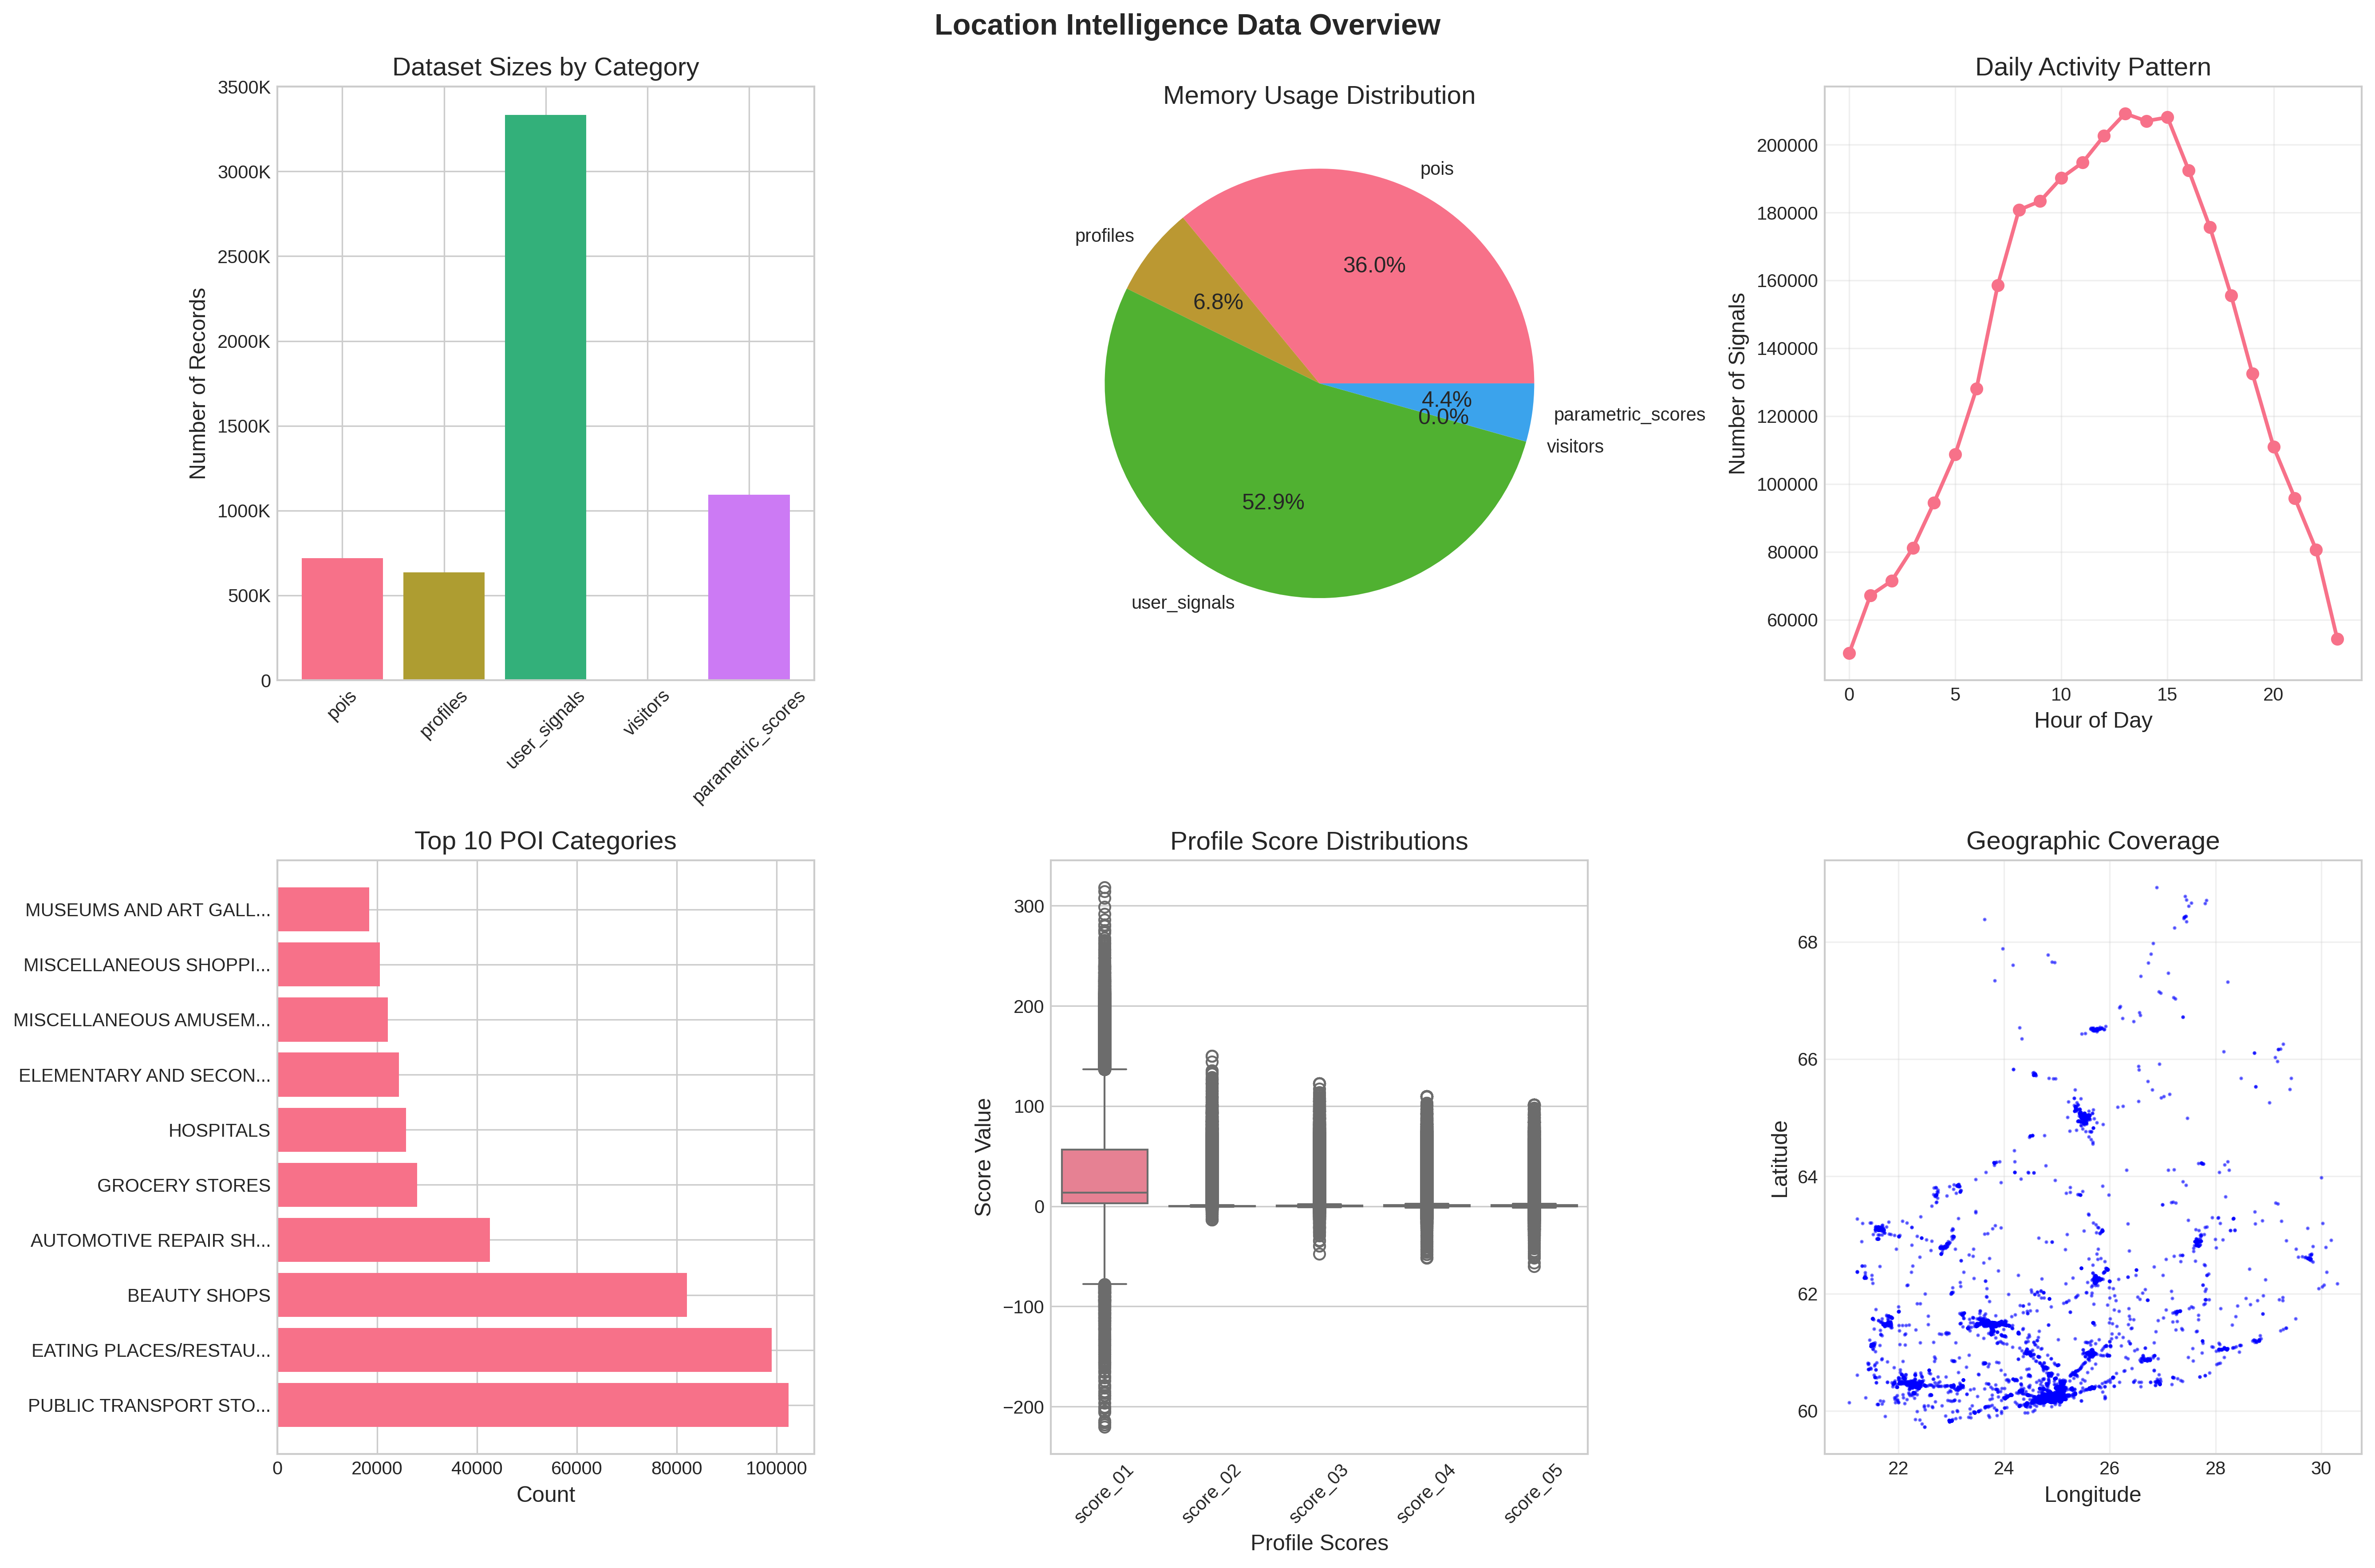


2. Model Performance Comparison
POI pipeline results not available
Model comparison not available (requires POI pipeline results)

3. Agent-Based Model Analysis


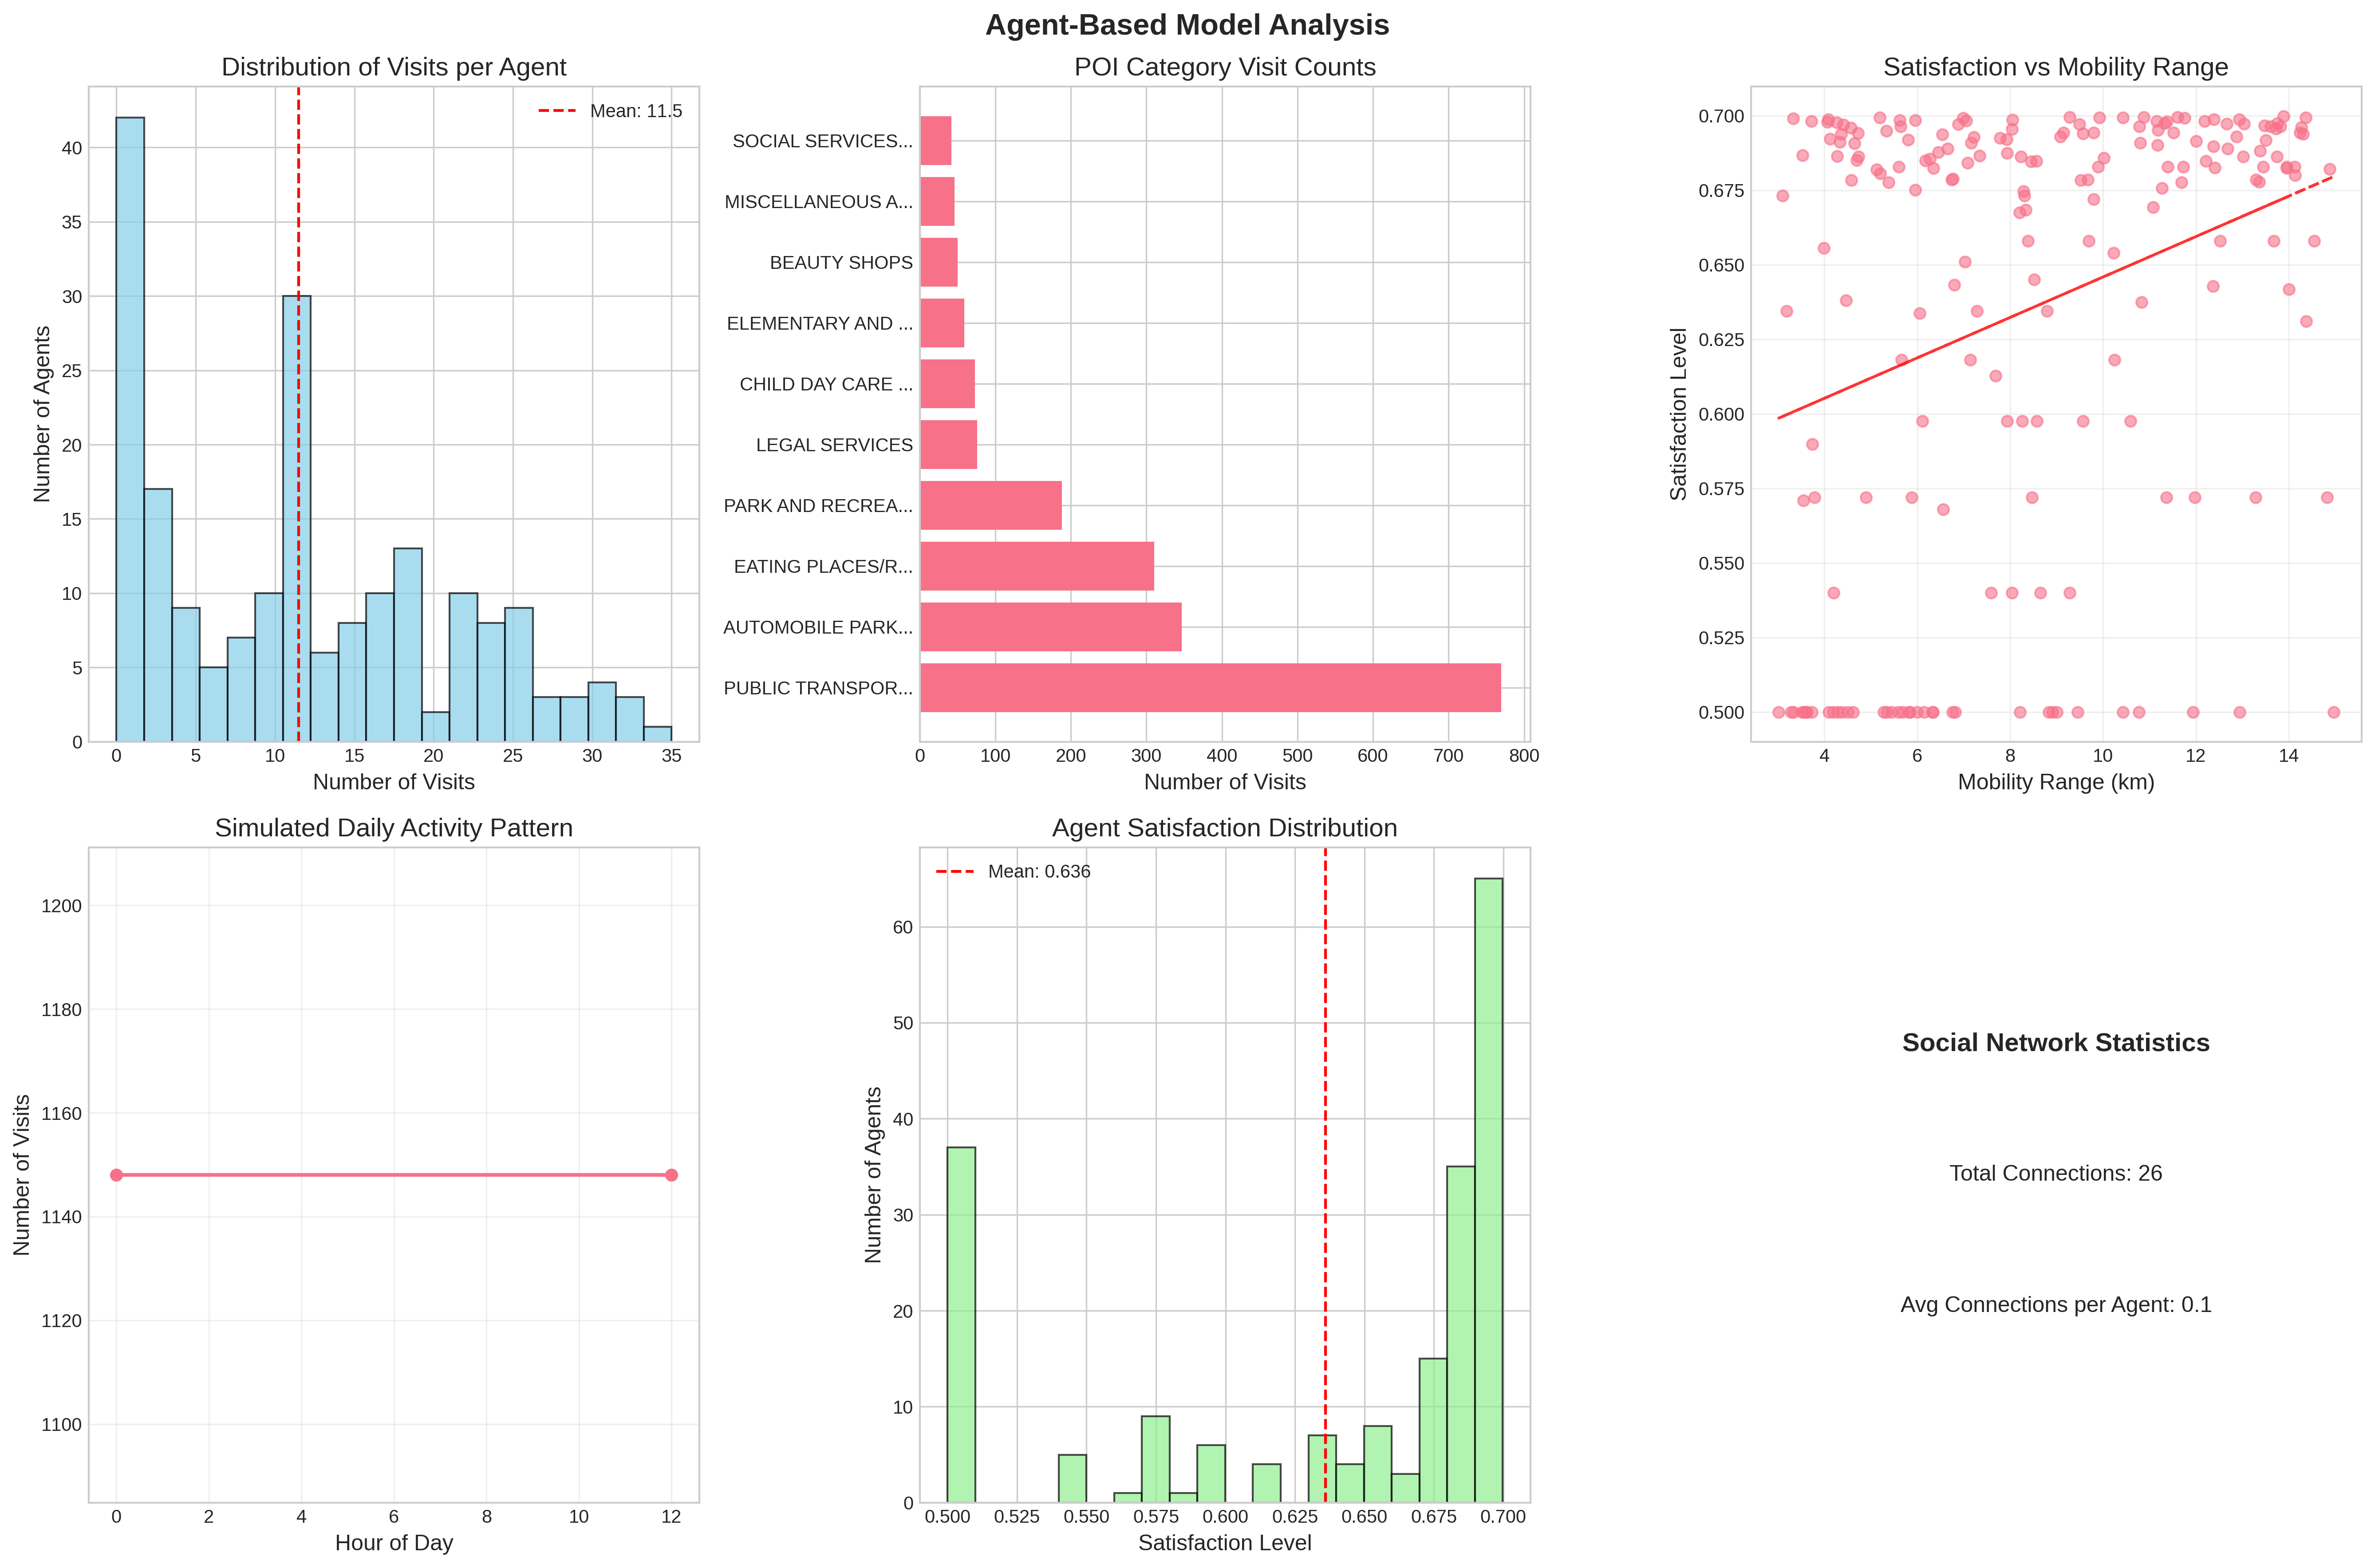


4. Policy Implications and Insights


In [ ]:
#Visualization
# Set style for publication-quality figures
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams.update({
    'figure.figsize': (12, 8),
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})

class PublicationVisualizationSuite:
    def __init__(self, data_loader, poi_pipeline=None, census_pipeline=None, abm_model=None):
        self.data_loader = data_loader
        self.poi_pipeline = poi_pipeline
        self.census_pipeline = census_pipeline
        self.abm_model = abm_model

    def create_data_overview_figure(self):
        #Create comprehensive data overview figure
        fig, axes = plt.subplots(2, 3, figsize=(18, 12))
        fig.suptitle('Location Intelligence Data Overview', fontsize=16, fontweight='bold')

        # Get data overview
        overview = self.data_loader.get_data_overview()

        # 1. Dataset sizes
        categories = list(overview['by_category'].keys())
        records = [overview['by_category'][cat]['records'] for cat in categories]

        axes[0, 0].bar(categories, records, color=sns.color_palette("husl", len(categories)))
        axes[0, 0].set_title('Dataset Sizes by Category')
        axes[0, 0].set_ylabel('Number of Records')
        axes[0, 0].tick_params(axis='x', rotation=45)

        # Format y-axis with K/M notation
        axes[0, 0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x/1000:.0f}K' if x >= 1000 else f'{x:.0f}'))

        # 2. Memory usage
        memory_usage = [overview['by_category'][cat]['memory_mb'] for cat in categories]
        axes[0, 1].pie(memory_usage, labels=categories, autopct='%1.1f%%')
        axes[0, 1].set_title('Memory Usage Distribution')

        # 3. User signals temporal pattern
        user_signals = self.data_loader.get_all_user_signals()
        if not user_signals.empty and 'hour' in user_signals.columns:
            hourly_activity = user_signals['hour'].value_counts().sort_index()
            axes[0, 2].plot(hourly_activity.index, hourly_activity.values, marker='o', linewidth=2)
            axes[0, 2].set_title('Daily Activity Pattern')
            axes[0, 2].set_xlabel('Hour of Day')
            axes[0, 2].set_ylabel('Number of Signals')
            axes[0, 2].grid(True, alpha=0.3)

        # 4. POI distribution
        pois = self.data_loader.get_all_pois()
        if not pois.empty and 'MAIN_CLASS' in pois.columns:
            poi_categories = pois['MAIN_CLASS'].value_counts().head(10)
            axes[1, 0].barh(range(len(poi_categories)), poi_categories.values)
            axes[1, 0].set_yticks(range(len(poi_categories)))
            axes[1, 0].set_yticklabels([cat[:20] + '...' if len(cat) > 20 else cat for cat in poi_categories.index])
            axes[1, 0].set_title('Top 10 POI Categories')
            axes[1, 0].set_xlabel('Count')

        # 5. Profile score distribution
        profiles = self.data_loader.get_all_profiles()
        if not profiles.empty:
            score_cols = [col for col in profiles.columns if col.startswith('score_')][:5]
            if score_cols:
                profile_data = profiles[score_cols].melt()
                sns.boxplot(data=profile_data, x='variable', y='value', ax=axes[1, 1])
                axes[1, 1].set_title('Profile Score Distributions')
                axes[1, 1].set_xlabel('Profile Scores')
                axes[1, 1].set_ylabel('Score Value')
                axes[1, 1].tick_params(axis='x', rotation=45)

        # 6. Geographic coverage
        if not user_signals.empty and all(col in user_signals.columns for col in ['latitude', 'longitude']):
            sample_signals = user_signals.sample(min(5000, len(user_signals)))
            axes[1, 2].scatter(sample_signals['longitude'], sample_signals['latitude'],
                             alpha=0.5, s=1, c='blue')
            axes[1, 2].set_title('Geographic Coverage')
            axes[1, 2].set_xlabel('Longitude')
            axes[1, 2].set_ylabel('Latitude')
            axes[1, 2].grid(True, alpha=0.3)

        plt.tight_layout()
        return fig

    def create_model_comparison_figure(self):
        """Create model performance comparison figure"""
        if not self.poi_pipeline or not hasattr(self.poi_pipeline, 'results'):
            print("POI pipeline results not available")
            return None

        results_df = self.poi_pipeline.results.get('results_df', pd.DataFrame())

        if results_df.empty:
            print("No model results to visualize")
            return None

        fig, axes = plt.subplots(2, 2, figsize=(16, 12))
        fig.suptitle('Model Performance Comparison', fontsize=16, fontweight='bold')

        # 1. Accuracy comparison
        axes[0, 0].bar(results_df['model'], results_df['accuracy'],
                      color=sns.color_palette("viridis", len(results_df)))
        axes[0, 0].set_title('Model Accuracy Comparison')
        axes[0, 0].set_ylabel('Accuracy')
        axes[0, 0].tick_params(axis='x', rotation=45)
        axes[0, 0].set_ylim(0, 1)

        # Add value labels on bars
        for i, v in enumerate(results_df['accuracy']):
            axes[0, 0].text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom')

        # 2. AUC comparison
        axes[0, 1].bar(results_df['model'], results_df['auc'],
                      color=sns.color_palette("plasma", len(results_df)))
        axes[0, 1].set_title('Model AUC Comparison')
        axes[0, 1].set_ylabel('AUC Score')
        axes[0, 1].tick_params(axis='x', rotation=45)
        axes[0, 1].set_ylim(0, 1)

        for i, v in enumerate(results_df['auc']):
            axes[0, 1].text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom')

        # 3. Precision vs Recall
        if 'precision' in results_df.columns and 'recall' in results_df.columns:
            axes[1, 0].scatter(results_df['recall'], results_df['precision'],
                             s=100, alpha=0.7, c=range(len(results_df)), cmap='tab10')

            for i, model in enumerate(results_df['model']):
                axes[1, 0].annotate(model,
                                  (results_df['recall'].iloc[i], results_df['precision'].iloc[i]),
                                  xytext=(5, 5), textcoords='offset points', fontsize=9)

            axes[1, 0].set_title('Precision vs Recall')
            axes[1, 0].set_xlabel('Recall')
            axes[1, 0].set_ylabel('Precision')
            axes[1, 0].grid(True, alpha=0.3)
            axes[1, 0].set_xlim(0, 1)
            axes[1, 0].set_ylim(0, 1)

        # 4. Model complexity vs performance
        model_complexity = {
            'Random Choice': 1, 'Nearest POI': 2, 'Most Popular': 3, 'Gravity Model': 4,
            'Logistic Regression': 5, 'Random Forest': 8, 'XGBoost': 9, 'Multinomial Logit': 6
        }

        complexity_scores = [model_complexity.get(model, 5) for model in results_df['model']]

        axes[1, 1].scatter(complexity_scores, results_df['auc'],
                         s=results_df['accuracy'] * 200, alpha=0.7, c='orange')

        for i, model in enumerate(results_df['model']):
            axes[1, 1].annotate(model,
                              (complexity_scores[i], results_df['auc'].iloc[i]),
                              xytext=(5, 5), textcoords='offset points', fontsize=9)

        axes[1, 1].set_title('Model Complexity vs Performance\n(Bubble size = Accuracy)')
        axes[1, 1].set_xlabel('Model Complexity')
        axes[1, 1].set_ylabel('AUC Score')
        axes[1, 1].grid(True, alpha=0.3)

        plt.tight_layout()
        return fig

    def create_abm_analysis_figure(self):
        """Create ABM simulation analysis figure"""
        if not self.abm_model:
            print("ABM model not available")
            return None

        fig, axes = plt.subplots(2, 3, figsize=(18, 12))
        fig.suptitle('Agent-Based Model Analysis', fontsize=16, fontweight='bold')

        # Collect ABM data
        all_visits = []
        agent_stats = []

        for agent in self.abm_model.environment.agents.values():
            agent_stats.append({
                'user_id': agent.profile.user_id,
                'total_visits': len(agent.learning.visit_history),
                'satisfaction': agent.satisfaction,
                'energy': agent.energy,
                'mobility_range': agent.profile.mobility_range
            })

            for visit in agent.learning.visit_history:
                visit['user_id'] = agent.profile.user_id
                all_visits.append(visit)

        visits_df = pd.DataFrame(all_visits)
        agents_df = pd.DataFrame(agent_stats)

        # 1. Visit frequency distribution
        if not agents_df.empty:
            axes[0, 0].hist(agents_df['total_visits'], bins=20, alpha=0.7, color='skyblue', edgecolor='black')
            axes[0, 0].set_title('Distribution of Visits per Agent')
            axes[0, 0].set_xlabel('Number of Visits')
            axes[0, 0].set_ylabel('Number of Agents')
            axes[0, 0].axvline(agents_df['total_visits'].mean(), color='red', linestyle='--',
                             label=f'Mean: {agents_df["total_visits"].mean():.1f}')
            axes[0, 0].legend()

        # 2. POI category preferences
        if not visits_df.empty:
            category_counts = visits_df['category'].value_counts().head(10)
            axes[0, 1].barh(range(len(category_counts)), category_counts.values)
            axes[0, 1].set_yticks(range(len(category_counts)))
            axes[0, 1].set_yticklabels([cat[:15] + '...' if len(cat) > 15 else cat for cat in category_counts.index])
            axes[0, 1].set_title('POI Category Visit Counts')
            axes[0, 1].set_xlabel('Number of Visits')

        # 3. Satisfaction vs mobility relationship
        if not agents_df.empty:
            axes[0, 2].scatter(agents_df['mobility_range'], agents_df['satisfaction'], alpha=0.6)
            axes[0, 2].set_title('Satisfaction vs Mobility Range')
            axes[0, 2].set_xlabel('Mobility Range (km)')
            axes[0, 2].set_ylabel('Satisfaction Level')
            axes[0, 2].grid(True, alpha=0.3)

            # Add trend line
            z = np.polyfit(agents_df['mobility_range'], agents_df['satisfaction'], 1)
            p = np.poly1d(z)
            axes[0, 2].plot(agents_df['mobility_range'], p(agents_df['mobility_range']), "r--", alpha=0.8)

        # 4. Temporal activity pattern
        if not visits_df.empty and 'time' in visits_df.columns:
            hourly_visits = visits_df['time'].apply(lambda x: x % 24).value_counts().sort_index()
            axes[1, 0].plot(hourly_visits.index, hourly_visits.values, marker='o', linewidth=2)
            axes[1, 0].set_title('Simulated Daily Activity Pattern')
            axes[1, 0].set_xlabel('Hour of Day')
            axes[1, 0].set_ylabel('Number of Visits')
            axes[1, 0].grid(True, alpha=0.3)

        # 5. Satisfaction distribution
        if not agents_df.empty:
            axes[1, 1].hist(agents_df['satisfaction'], bins=20, alpha=0.7, color='lightgreen', edgecolor='black')
            axes[1, 1].set_title('Agent Satisfaction Distribution')
            axes[1, 1].set_xlabel('Satisfaction Level')
            axes[1, 1].set_ylabel('Number of Agents')
            axes[1, 1].axvline(agents_df['satisfaction'].mean(), color='red', linestyle='--',
                             label=f'Mean: {agents_df["satisfaction"].mean():.3f}')
            axes[1, 1].legend()

        # 6. Social network effects
        if hasattr(self.abm_model.environment, 'social_influence'):
            social_connections = len(self.abm_model.environment.social_influence.social_network)
            axes[1, 2].text(0.5, 0.7, f'Social Network Statistics', ha='center', va='center',
                          transform=axes[1, 2].transAxes, fontsize=14, fontweight='bold')
            axes[1, 2].text(0.5, 0.5, f'Total Connections: {social_connections}', ha='center', va='center',
                          transform=axes[1, 2].transAxes, fontsize=12)

            avg_connections = social_connections / max(1, len(self.abm_model.environment.agents))
            axes[1, 2].text(0.5, 0.3, f'Avg Connections per Agent: {avg_connections:.1f}',
                          ha='center', va='center', transform=axes[1, 2].transAxes, fontsize=12)
            axes[1, 2].set_xlim(0, 1)
            axes[1, 2].set_ylim(0, 1)
            axes[1, 2].axis('off')

        plt.tight_layout()
        return fig

    def create_policy_implications_figure(self):
        """Create policy implications visualization"""
        fig, axes = plt.subplots(2, 2, figsize=(16, 12))
        fig.suptitle('Policy Implications and Insights', fontsize=16, fontweight='bold')

        # Get data for analysis
        user_signals = self.data_loader.get_all_user_signals()
        pois = self.data_loader.get_all_pois()

        # 1. Accessibility analysis
        if not user_signals.empty and not pois.empty:
            # Sample for performance
            sample_signals = user_signals.sample(min(1000, len(user_signals)))

            # Calculate distances to nearest POI for each user location
            distances_to_poi = []
            for _, signal in sample_signals.iterrows():
                if pd.notna(signal['latitude']) and pd.notna(signal['longitude']):
                    user_lat, user_lon = signal['latitude'], signal['longitude']

                    # Calculate distance to all POIs
                    poi_distances = []
                    for _, poi in pois.iterrows():
                        if pd.notna(poi.get('LATITUDE')) and pd.notna(poi.get('LONGITUDE')):
                            poi_lat, poi_lon = poi['LATITUDE'], poi['LONGITUDE']

                            # Simple distance calculation
                            distance = np.sqrt((user_lat - poi_lat)**2 + (user_lon - poi_lon)**2) * 111  # Rough km conversion
                            poi_distances.append(distance)

                    if poi_distances:
                        distances_to_poi.append(min(poi_distances))

            if distances_to_poi:
                axes[0, 0].hist(distances_to_poi, bins=30, alpha=0.7, color='coral', edgecolor='black')
                axes[0, 0].set_title('Accessibility: Distance to Nearest POI')
                axes[0, 0].set_xlabel('Distance (km)')
                axes[0, 0].set_ylabel('Number of User Locations')
                axes[0, 0].axvline(np.mean(distances_to_poi), color='red', linestyle='--',
                                 label=f'Mean: {np.mean(distances_to_poi):.1f} km')
                axes[0, 0].legend()

        # 2. Service coverage gaps
        if not pois.empty:
            poi_categories = pois['MAIN_CLASS'].value_counts()
            essential_services = ['GROCERY STORES', 'HOSPITALS', 'SCHOOLS', 'PUBLIC TRANSPORT', 'PHARMACIES']

            coverage_data = []
            for service in essential_services:
                matching_pois = poi_categories[poi_categories.index.str.contains(service.split()[0], case=False, na=False)]
                coverage_data.append(matching_pois.sum() if len(matching_pois) > 0 else 0)

            axes[0, 1].bar(essential_services, coverage_data, color=sns.color_palette("Set2", len(essential_services)))
            axes[0, 1].set_title('Essential Service Coverage')
            axes[0, 1].set_ylabel('Number of POIs')
            axes[0, 1].tick_params(axis='x', rotation=45)

        # 3. Activity concentration analysis
        if not user_signals.empty:
            # Calculate activity density
            lat_bins = pd.cut(user_signals['latitude'], bins=20)
            lon_bins = pd.cut(user_signals['longitude'], bins=20)
            activity_density = user_signals.groupby([lat_bins, lon_bins]).size()

            # Plot concentration analysis
            concentration_values = activity_density.values
            concentration_values = concentration_values[concentration_values > 0]

            axes[1, 0].hist(concentration_values, bins=30, alpha=0.7, color='lightblue', edgecolor='black')
            axes[1, 0].set_title('Activity Concentration Distribution')
            axes[1, 0].set_xlabel('Activity Density (signals per grid cell)')
            axes[1, 0].set_ylabel('Number of Grid Cells')
            axes[1, 0].set_yscale('log')

        # 4. Recommendations summary
        recommendations = [
            "Improve POI accessibility in low-coverage areas",
            "Enhance public transport connectivity",
            "Address service gaps in essential categories",
            "Consider mobility patterns in urban planning",
            "Implement targeted interventions for underserved areas"
        ]

        axes[1, 1].text(0.05, 0.95, 'Policy Recommendations:', transform=axes[1, 1].transAxes,
                       fontsize=14, fontweight='bold', va='top')

        for i, rec in enumerate(recommendations):
            axes[1, 1].text(0.05, 0.85 - i*0.15, f'{i+1}. {rec}', transform=axes[1, 1].transAxes,
                          fontsize=11, va='top', wrap=True)

        axes[1, 1].set_xlim(0, 1)
        axes[1, 1].set_ylim(0, 1)
        axes[1, 1].axis('off')

        plt.tight_layout()
        return fig

class InteractiveVisualizationSuite:
    """
    Create interactive web-based visualizations
    """

    def __init__(self, data_loader, poi_pipeline=None, census_pipeline=None, abm_model=None):
        self.data_loader = data_loader
        self.poi_pipeline = poi_pipeline
        self.census_pipeline = census_pipeline
        self.abm_model = abm_model

    def create_interactive_dashboard(self):
        """Create comprehensive interactive dashboard"""
        # Get data
        user_signals = self.data_loader.get_all_user_signals()
        pois = self.data_loader.get_all_pois()
        profiles = self.data_loader.get_all_profiles()

        # Create subplots
        fig = make_subplots(
            rows=3, cols=2,
            subplot_titles=['User Activity Over Time', 'POI Category Distribution',
                          'Profile Score Patterns', 'Geographic Distribution',
                          'Model Performance', 'Data Quality Metrics'],
            specs=[[{"secondary_y": False}, {"type": "bar"}],
                   [{"type": "box"}, {"type": "scattermapbox"}],
                   [{"type": "bar"}, {"type": "indicator"}]]
        )

        # 1. Activity timeline
        if not user_signals.empty and 'hour' in user_signals.columns:
            hourly_activity = user_signals['hour'].value_counts().sort_index()
            fig.add_trace(
                go.Scatter(x=hourly_activity.index, y=hourly_activity.values,
                         mode='lines+markers', name='Hourly Activity'),
                row=1, col=1
            )

        # 2. POI categories
        if not pois.empty and 'MAIN_CLASS' in pois.columns:
            poi_counts = pois['MAIN_CLASS'].value_counts().head(10)
            fig.add_trace(
                go.Bar(x=poi_counts.values, y=poi_counts.index, orientation='h', name='POI Categories'),
                row=1, col=2
            )

        # 3. Profile patterns
        if not profiles.empty:
            score_cols = [col for col in profiles.columns if col.startswith('score_')][:5]
            for col in score_cols:
                fig.add_trace(
                    go.Box(y=profiles[col], name=col, boxpoints='outliers'),
                    row=2, col=1
                )

        # 4. Geographic map
        if not user_signals.empty:
            sample_data = user_signals.sample(min(1000, len(user_signals)))
            fig.add_trace(
                go.Scattermapbox(
                    lat=sample_data['latitude'],
                    lon=sample_data['longitude'],
                    mode='markers',
                    marker=dict(size=4, opacity=0.6),
                    name='User Locations'
                ),
                row=2, col=2
            )

        # 5. Model performance (if available)
        if self.poi_pipeline and hasattr(self.poi_pipeline, 'results'):
            results_df = self.poi_pipeline.results.get('results_df', pd.DataFrame())
            if not results_df.empty:
                fig.add_trace(
                    go.Bar(x=results_df['model'], y=results_df['accuracy'], name='Accuracy'),
                    row=3, col=1
                )

        # 6. Data quality indicator
        overview = self.data_loader.get_data_overview()
        total_records = overview['total_records']

        fig.add_trace(
            go.Indicator(
                mode="gauge+number+delta",
                value=total_records,
                domain={'x': [0, 1], 'y': [0, 1]},
                title={'text': "Total Records"},
                gauge={'axis': {'range': [None, total_records * 1.2]},
                      'bar': {'color': "darkblue"},
                      'steps': [{'range': [0, total_records * 0.5], 'color': "lightgray"},
                               {'range': [total_records * 0.5, total_records], 'color': "gray"}],
                      'threshold': {'line': {'color': "red", 'width': 4},
                                  'thickness': 0.75, 'value': total_records * 0.9}}
            ),
            row=3, col=2
        )

        # Update layout
        fig.update_layout(
            height=1200,
            title_text="Location Intelligence Interactive Dashboard",
            title_x=0.5,
            showlegend=True
        )

        # Update mapbox
        fig.update_layout(
            mapbox=dict(
                style="open-street-map",
                zoom=6,
                center=dict(lat=65, lon=26)  # Finland center
            )
        )

        return fig

    def create_poi_explorer(self):
        """Create POI exploration tool"""
        pois = self.data_loader.get_all_pois()

        if pois.empty:
            return None

        # Create interactive map
        fig = go.Figure()

        # Add POI points by category
        categories = pois['MAIN_CLASS'].unique()[:10]  # Limit for performance
        colors = px.colors.qualitative.Set3

        for i, category in enumerate(categories):
            category_pois = pois[pois['MAIN_CLASS'] == category]
            if not category_pois.empty:
                fig.add_trace(go.Scattermapbox(
                    lat=category_pois['LATITUDE'],
                    lon=category_pois['LONGITUDE'],
                    mode='markers',
                    marker=dict(size=8, color=colors[i % len(colors)], opacity=0.7),
                    text=category_pois.get('NAME', ''),
                    name=category,
                    hovertemplate="<b>%{text}</b><br>" +
                                "Category: " + category + "<br>" +
                                "Lat: %{lat}<br>" +
                                "Lon: %{lon}<extra></extra>"
                ))

        fig.update_layout(
            title="POI Explorer - Interactive Map",
            mapbox=dict(
                style="open-street-map",
                zoom=6,
                center=dict(lat=65, lon=26)
            ),
            height=800
        )

        return fig

    def create_abm_viewer(self):
        """Create ABM simulation viewer"""
        if not self.abm_model:
            return None

        # Create animation of agent movements
        fig = go.Figure()

        # Sample agents for visualization
        sample_agents = list(self.abm_model.environment.agents.values())[:20]

        for agent in sample_agents:
            if agent.learning.visit_history:
                visits = agent.learning.visit_history

                # Create trace for agent movement
                lats = [agent.profile.home_lat]
                lons = [agent.profile.home_lon]

                # Add visit locations
                for visit in visits:
                    poi = self.abm_model.environment.pois.get(visit['poi_id'])
                    if poi:
                        lats.append(poi.lat)
                        lons.append(poi.lon)

                fig.add_trace(go.Scattermapbox(
                    lat=lats,
                    lon=lons,
                    mode='lines+markers',
                    marker=dict(size=6),
                    line=dict(width=2),
                    name=f"Agent {agent.profile.user_id[:8]}",
                    hovertemplate="Agent: %{text}<br>" +
                                "Lat: %{lat}<br>" +
                                "Lon: %{lon}<extra></extra>",
                    text=[f"Agent {agent.profile.user_id[:8]}"] * len(lats)
                ))

        fig.update_layout(
            title="ABM Agent Movement Visualization",
            mapbox=dict(
                style="open-street-map",
                zoom=8,
                center=dict(lat=65, lon=26)
            ),
            height=800
        )

        return fig

class ComprehensiveVisualizationManager:
    """
    Main class to manage all visualizations
    """

    def __init__(self, data_loader, poi_pipeline=None, census_pipeline=None, abm_model=None):
        self.static_viz = PublicationVisualizationSuite(data_loader, poi_pipeline, census_pipeline, abm_model)
        self.interactive_viz = InteractiveVisualizationSuite(data_loader, poi_pipeline, census_pipeline, abm_model)

    def generate_all_static_figures(self, save_path="./figures/"):
        """Generate all static publication figures"""
        import os
        os.makedirs(save_path, exist_ok=True)

        print("Generating publication-quality figures...")

        # Data overview
        fig1 = self.static_viz.create_data_overview_figure()
        if fig1:
            fig1.savefig(f"{save_path}data_overview.png", dpi=300, bbox_inches='tight')
            print(f"Saved: {save_path}data_overview.png")

        # Model comparison
        fig2 = self.static_viz.create_model_comparison_figure()
        if fig2:
            fig2.savefig(f"{save_path}model_comparison.png", dpi=300, bbox_inches='tight')
            print(f"Saved: {save_path}model_comparison.png")

        # ABM analysis
        fig3 = self.static_viz.create_abm_analysis_figure()
        if fig3:
            fig3.savefig(f"{save_path}abm_analysis.png", dpi=300, bbox_inches='tight')
            print(f"Saved: {save_path}abm_analysis.png")

        # Policy implications
        fig4 = self.static_viz.create_policy_implications_figure()
        if fig4:
            fig4.savefig(f"{save_path}policy_implications.png", dpi=300, bbox_inches='tight')
            print(f"Saved: {save_path}policy_implications.png")

        print("All static figures generated successfully!")

    def generate_interactive_tools(self, save_path="./interactive/"):
        """Generate interactive visualization tools"""
        import os
        os.makedirs(save_path, exist_ok=True)

        print("Generating interactive tools...")

        # Dashboard
        dashboard = self.interactive_viz.create_interactive_dashboard()
        if dashboard:
            dashboard.write_html(f"{save_path}dashboard.html")
            print(f"Saved: {save_path}dashboard.html")

        # POI Explorer
        poi_explorer = self.interactive_viz.create_poi_explorer()
        if poi_explorer:
            poi_explorer.write_html(f"{save_path}poi_explorer.html")
            print(f"Saved: {save_path}poi_explorer.html")

        # ABM Viewer
        abm_viewer = self.interactive_viz.create_abm_viewer()
        if abm_viewer:
            abm_viewer.write_html(f"{save_path}abm_viewer.html")
            print(f"Saved: {save_path}abm_viewer.html")

        print("All interactive tools generated successfully!")

# Usage function
def create_comprehensive_visualizations(data_loader, poi_pipeline=None, census_pipeline=None, abm_model=None):
    """Create all visualizations"""

    viz_manager = ComprehensiveVisualizationManager(data_loader, poi_pipeline, census_pipeline, abm_model)

    # Generate static figures
    viz_manager.generate_all_static_figures()

    # Generate interactive tools
    viz_manager.generate_interactive_tools()

    return viz_manager

# Display functions for interactive viewing
def display_all_static_plots(data_loader, poi_pipeline=None, census_pipeline=None, abm_model=None):
    """Display all static plots in the notebook"""
    static_viz = PublicationVisualizationSuite(data_loader, poi_pipeline, census_pipeline, abm_model)

    print("="*60)
    print("DISPLAYING PUBLICATION-QUALITY FIGURES")
    print("="*60)

    # 1. Data Overview
    print("\n1. Data Overview Figure")
    fig1 = static_viz.create_data_overview_figure()
    if fig1:
        plt.show()
    else:
        print("Could not create data overview figure")

    # 2. Model Comparison
    print("\n2. Model Performance Comparison")
    fig2 = static_viz.create_model_comparison_figure()
    if fig2:
        plt.show()
    else:
        print("Model comparison not available (requires POI pipeline results)")

    # 3. ABM Analysis
    print("\n3. Agent-Based Model Analysis")
    fig3 = static_viz.create_abm_analysis_figure()
    if fig3:
        plt.show()
    else:
        print("ABM analysis not available (requires ABM model)")

    # 4. Policy Implications
    print("\n4. Policy Implications and Insights")
    fig4 = static_viz.create_policy_implications_figure()
    if fig4:
        plt.show()
    else:
        print("Could not create policy implications figure")

def display_interactive_plots(data_loader, poi_pipeline=None, census_pipeline=None, abm_model=None):
    """Display interactive plots in the notebook"""
    interactive_viz = InteractiveVisualizationSuite(data_loader, poi_pipeline, census_pipeline, abm_model)

    print("="*60)
    print("DISPLAYING INTERACTIVE VISUALIZATIONS")
    print("="*60)

    # 1. Interactive Dashboard
    print("\n1. Interactive Dashboard")
    dashboard = interactive_viz.create_interactive_dashboard()
    if dashboard:
        dashboard.show()
    else:
        print("Could not create interactive dashboard")

    # 2. POI Explorer
    print("\n2. POI Explorer")
    poi_explorer = interactive_viz.create_poi_explorer()
    if poi_explorer:
        poi_explorer.show()
    else:
        print("POI explorer not available (no POI data found)")

    # 3. ABM Viewer
    print("\n3. ABM Simulation Viewer")
    abm_viewer = interactive_viz.create_abm_viewer()
    if abm_viewer:
        abm_viewer.show()
    else:
        print("ABM viewer not available (requires ABM model)")

def create_and_display_all_visualizations(data_loader, poi_pipeline=None, census_pipeline=None, abm_model=None):
    """Create and display all visualizations"""
    print("COMPREHENSIVE VISUALIZATION SUITE")
    print("="*60)

    # Display static plots
    display_all_static_plots(data_loader, poi_pipeline, census_pipeline, abm_model)

    print("\n" + "="*60)
    print("SWITCHING TO INTERACTIVE VISUALIZATIONS")
    print("="*60)

    # Display interactive plots
    display_interactive_plots(data_loader, poi_pipeline, census_pipeline, abm_model)

    # Also save files
    viz_manager = ComprehensiveVisualizationManager(data_loader, poi_pipeline, census_pipeline, abm_model)

    print("\n" + "="*60)
    print("SAVING FILES")
    print("="*60)

    try:
        viz_manager.generate_all_static_figures()
        viz_manager.generate_interactive_tools()
        print("All visualizations saved successfully!")
    except Exception as e:
        print(f"Error saving files: {e}")

    return viz_manager

# Quick display functions for individual plots
def show_data_overview(data_loader):
    """Quick function to show just data overview"""
    static_viz = PublicationVisualizationSuite(data_loader)
    fig = static_viz.create_data_overview_figure()
    if fig:
        plt.show()
        return fig
    else:
        print("Could not create data overview")
        return None

def show_model_results(poi_pipeline):
    """Quick function to show model comparison"""
    if not poi_pipeline:
        print("No POI pipeline provided")
        return None

    static_viz = PublicationVisualizationSuite(None, poi_pipeline)
    fig = static_viz.create_model_comparison_figure()
    if fig:
        plt.show()
        return fig
    else:
        print("Could not create model comparison")
        return None

def show_abm_results(abm_model):
    """Quick function to show ABM analysis"""
    if not abm_model:
        print("No ABM model provided")
        return None

    static_viz = PublicationVisualizationSuite(None, None, None, abm_model)
    fig = static_viz.create_abm_analysis_figure()
    if fig:
        plt.show()
        return fig
    else:
        print("Could not create ABM analysis")
        return None

def show_interactive_dashboard(data_loader):
    """Quick function to show interactive dashboard"""
    interactive_viz = InteractiveVisualizationSuite(data_loader)
    dashboard = interactive_viz.create_interactive_dashboard()
    if dashboard:
        dashboard.show()
        return dashboard
    else:
        print("Could not create dashboard")
        return None

# Execute visualization creation and display
if __name__ == "__main__" and 'data_loader' in globals():
    print("Creating and displaying comprehensive visualization suite...")

    # Get pipeline objects if available
    poi_pipe = fixed_pipeline if 'fixed_pipeline' in globals() else None
    census_pipe = census_pipeline if 'census_pipeline' in globals() else None
    abm = abm_model if 'abm_model' in globals() else None

    # Create and display all visualizations
    viz_manager = create_and_display_all_visualizations(data_loader, poi_pipe, census_pipe, abm)

    print("\nVisualization suite completed!")
    print("\nQuick access functions available:")
    print("- show_data_overview(data_loader)")
    print("- show_model_results(poi_pipeline)")
    print("- show_abm_results(abm_model)")
    print("- show_interactive_dashboard(data_loader)")

else:
    print("Please ensure data_loader and pipeline objects are available.")
    print("\nTo display visualizations, run:")
    print("create_and_display_all_visualizations(data_loader, poi_pipeline, census_pipeline, abm_model)")